# A Hierarchical YOLO-Based Framework for Helmet Violation Detection

Kael Lorenzo M. Herrera || Nathan Cedric G. Ramos || Anya Danielle C. Valentino

## Final pipeline (v1.9)

Three-stage cascade for motorcycle helmet-violation detection:
**Stage 1** motorcycle detector → **Stage 2** rider keypoints + head localisation → **Stage 3** helmet classifier.

### The final system
| Stage | Model | Data (Roboflow, Roboflow's own split) | Selection file on Drive |
|---|---|---|---|
| 1. Motorcycle detector | YOLO11s, 1280 px | `motorcycle-wubuz` v8 | `results/stage1_selected_rf8.json` |
| 2. Rider keypoints | YOLOv8s-pose | `cropped-keypoints` v3 | `results/stage2_selected_rf3.json` |
| 3. Helmet classifier | YOLO11s-cls (ratio 1.5, seed 2, epoch 43) | `helmet-classification-k8z2f` v6 | `results/stage3_selected_rf6.json` |
| End-to-end config | anchor, gate T, Stage 3 threshold, head box | v4 master-split valid/test frames | `results/e2e_final_config_s123.json` |

### Notebook Organization
| Label | Meaning |
|---|---|
| **PART A: FINAL SYSTEM** | The cells the current system needs, **in run order**. Each code cell starts with `# CORE · Step n`. |
| **PART B: THESIS OUTPUTS** | Tables, figures, slides and panel-revision comparisons. They read the final results from Drive and train nothing. |
| **PART C: ARCHIVE** | Earlier versions (v1.3 to v1.8), one-off checks and testing cells, kept for reference. **Do not run these for the current system.** Some of them overwrite files the final system reads (marked WARNING). |


### Which cells to run
| Goal | Cells (fresh runtime, GPU) |
|---|---|
| **Reproduce the final system from scratch** | Steps 1 → 26 in Part A, in order (C.2, D.2 and F.2 train: about 3–4 h, 1–1.5 h and 3–4 h per backbone on an L4) |
| **Load the final system without training** | 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1, then **H.1** (latency) or **RQ2 B** (Part B) |
| **Regenerate the thesis figures** | 0.1, 0.2, 0.3, 1.2, 3.1, D.1, F.1, then FIG.0 → FIG.6 (Part B) |
| **Prepare the Streamlit deployment zip** | 0.1, 0.2, 0.3, then **DEPLOY.1** |

**After a disconnect:** re-run 0.1–0.3 and 1.2, then the dataset cell of the stage you were on (C.1, D.1 or F.1). The training cells skip finished runs and resume unfinished ones. **F.3 must run in the same session as F.2**, because it reads the every-epoch checkpoints from local disk.

**Rule used throughout:** every choice (confidence, NMS IoU, gate T, checkpoint, threshold, winning model) is made on **validation**. **Test** is only used to report final numbers.

---
# PART A: FINAL SYSTEM (run in this order)

## A.0 Setup (run every session)
Before the first run, store your Roboflow API key in Colab Secrets: click the key icon in the left sidebar → *Add new secret* → Name `ROBOFLOW_API_KEY` → turn on **Notebook access**.

**Leave `S1_VERSION = 4` in 0.2.** v4 supplies the end-to-end valid/test frames (master split). The new dataset versions are set in C.1, D.1 and F.1.

In [ ]:
# CORE · Step 1: 0.1 Install
# 0.1 Install (pinned so results are reproducible; 8.4.159 is what your last runs used
# and it supports custom keypoint OKS sigmas)
!pip install -q ultralytics==8.4.159 roboflow scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 90.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 361.2/361.2 kB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 139.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 10.5 MB/s eta 0:00:00


In [ ]:
# CORE · Step 2: 0.2 Config
# 0.2 EDIT: Central config
import os
from google.colab import drive, userdata
drive.mount('/content/drive')

try:
    API_KEY = userdata.get('ROBOFLOW_API_KEY')  # from Colab Secrets, never hard-code it
except Exception:
    raise RuntimeError('Add ROBOFLOW_API_KEY in Colab Secrets (key icon, left sidebar) and enable Notebook access')

WORKSPACE_ID = 'nates-workspace-lpg6d'

# Stage 1 frames. Generate a NEW version WITHOUT augmentation (see step 1.1) and put its number here.
S1_PROJECT, S1_VERSION = 'motorcycle-wubuz', 4
S1_VERSION_IS_AUGMENTED = False     # set True only if you must reuse the augmented v3

S2_PROJECT, S2_VERSION = 'cropped-keypoints', 1
S3_PROJECT, S3_VERSION = 'helmet-classification-k8z2f', 4   # v1.6: the FINAL Stage 3 data (v4). Stage 3 is not retrained here.
RUN_TAG = 'v6'                                              # v1.6: suffix for every new result file

ROOT  = '/content/drive/MyDrive/helmet_thesis_v2'   # NEW folder, so your old runs stay untouched
RUNS  = f'{ROOT}/runs'
RES   = f'{ROOT}/results'
LOCAL = '/content/work'                              # fast local disk for datasets
MASTER_SPLIT_CSV = f'{ROOT}/master_split.csv'
SEED = 0
RATIOS = (0.70, 0.20, 0.10)     # train / valid / test

for d in [ROOT, RUNS, RES, LOCAL]:
    os.makedirs(d, exist_ok=True)
print('Config OK. Results go to', ROOT)

Mounted at /content/drive
Config OK. Results go to /content/drive/MyDrive/helmet_thesis_v2


In [ ]:
# CORE · Step 3: 0.3 Shared helpers
# 0.3 Shared helpers (run once per session; no edits needed)
import os, re, glob, json, shutil, random, math, time, yaml
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy import stats

EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def list_images(d):
    return sorted(p for p in glob.glob(f'{d}/*') if p.lower().endswith(EXTS))

def label_for(img_path):
    p = Path(img_path)
    return str(p.parent.parent / 'labels' / (p.stem + '.txt'))

def read_labels(lbl):
    if not os.path.exists(lbl):
        return []
    return [l.split() for l in open(lbl) if l.strip()]

def frame_base(path):
    """Original upload name of a frame = everything before Roboflow's FIRST '.rf.'.
    Stable across Roboflow versions, and it survives the crop -> re-upload renaming:
    'X_jpg.rf.a1.jpg' and 'X_jpg.rf.a1_Motorcycle0_jpg.rf.b2.jpg' both give 'X_jpg'."""
    return re.split(r'\.rf\.', os.path.basename(path))[0]

def crop_id(path):
    """Identity of one image before Roboflow augmentation (augmented copies share it)."""
    name = os.path.basename(path)
    return name.rsplit('.rf.', 1)[0] if '.rf.' in name else os.path.splitext(name)[0]

def regex_group(fb, rx):
    if not rx:
        return fb
    m = re.match(rx, fb)
    return m.group(1) if (m and m.group(1)) else fb

def match_master(fb, split_of):
    """Find the master frame for a crop name: exact match first, then the longest '_' prefix."""
    if fb in split_of:
        return fb
    parts = fb.split('_')
    for k in range(len(parts) - 1, 0, -1):
        cand = '_'.join(parts[:k])
        if cand in split_of:
            return cand
    return None

def split_groups(group_sizes, group_strata, ratios=(0.70, 0.20, 0.10), seed=0):
    """Group-aware, stratified split. Groups never straddle splits; ratios are met in
    number of images (not groups) inside each stratum."""
    assign, rng = {}, random.Random(seed)
    by_stratum = defaultdict(list)
    for g in sorted(group_sizes):
        by_stratum[group_strata.get(g, 0)].append(g)
    for s in sorted(by_stratum):
        keys = by_stratum[s]
        rng.shuffle(keys)
        total, acc = sum(group_sizes[k] for k in keys), 0
        for k in keys:
            frac = acc / total
            assign[k] = ('train' if frac < ratios[0] else
                         'valid' if frac < ratios[0] + ratios[1] else 'test')
            acc += group_sizes[k]
    return assign

def reset_dir(d):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d, exist_ok=True)

def save_json(obj, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'w') as f:
        json.dump(obj, f, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

def load_json(path, default=None):
    return json.load(open(path)) if os.path.exists(path) else default

def yolo_to_xyxy(row, W, H):
    cx, cy, w, h = map(float, row[1:5])
    return [(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H]

def iou_matrix(a, b):
    a = np.asarray(a, float).reshape(-1, 4); b = np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    tl = np.maximum(a[:, None, :2], b[None, :, :2]); br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def greedy_tp(pred_boxes, pred_scores, gt_boxes, iou_thr=0.5):
    """COCO-style greedy matching. Returns (scores sorted desc, TP flag per prediction).
    Because matching is greedy in score order, thresholding the sorted list later at any
    confidence t gives exactly the matches you would get by predicting at conf=t."""
    s = np.asarray(pred_scores, float)
    order = np.argsort(-s)
    s, pb = s[order], np.asarray(pred_boxes, float).reshape(-1, 4)[order]
    ious = iou_matrix(pb, gt_boxes)
    used = np.zeros(ious.shape[1], bool); tp = np.zeros(len(pb), bool)
    for i in range(len(pb)):
        cand = np.where(~used & (ious[i] >= iou_thr))[0] if ious.shape[1] else []
        if len(cand):
            j = cand[np.argmax(ious[i, cand])]; used[j] = True; tp[i] = True
    return s, tp

def counts_at(per_image, t):
    """per_image: list of (scores_sorted, tp_flags, n_gt). Returns per-image tp, fp, fn arrays."""
    tp = np.array([f[s >= t].sum() for s, f, n in per_image])
    npred = np.array([(s >= t).sum() for s, f, n in per_image])
    ngt = np.array([n for s, f, n in per_image])
    return tp, npred - tp, ngt - tp

def prf(tp, fp, fn):
    P = tp / (tp + fp) if (tp + fp) else 0.0
    R = tp / (tp + fn) if (tp + fn) else 0.0
    return P, R, (2 * P * R / (P + R) if (P + R) else 0.0)

def best_conf(per_image, grid=np.round(np.arange(0.05, 0.96, 0.01), 2)):
    f1s = [prf(*[x.sum() for x in counts_at(per_image, t)])[2] for t in grid]
    i = int(np.argmax(f1s))
    return float(grid[i]), float(f1s[i])

def bootstrap(fn, n_items, n_boot=2000, seed=0, groups=None):
    """95% percentile bootstrap. groups=None resamples items; otherwise resamples whole groups
    (shots), so near-identical consecutive frames cannot narrow the interval."""
    rng = np.random.default_rng(seed)
    point = np.atleast_1d(fn(np.arange(n_items))).astype(float)
    if groups is None:
        draw = lambda: rng.integers(0, n_items, n_items)
    else:
        groups = np.asarray(groups); uniq = np.unique(groups)
        idx_of = [np.where(groups == g)[0] for g in uniq]
        draw = lambda: np.concatenate([idx_of[j] for j in rng.integers(0, len(uniq), len(uniq))])
    samples = np.array([np.atleast_1d(fn(draw())) for _ in range(n_boot)], float)
    lo, hi = np.percentile(samples, [2.5, 97.5], axis=0)
    return point, lo, hi

def fmt_ci(p, lo, hi):
    return f'{p:.3f} [{lo:.3f}, {hi:.3f}]'

def train_or_resume(weights, name, project, **kw):
    """Train once; resume after a disconnect; skip if finished. exist_ok=True means the run
    ALWAYS lands in project/name, so evaluation cells never read a stale '-2' folder."""
    from ultralytics import YOLO
    run = f'{project}/{name}'
    done, last = f'{run}/DONE', f'{run}/weights/last.pt'
    if os.path.exists(done):
        print(f'[skip]   {name} already finished'); return run
    if os.path.exists(last):
        print(f'[resume] {name}')
        try:
            YOLO(last).train(resume=True)
        except AssertionError as e:          # "nothing to resume": run had actually finished
            print('  ', e)
    else:
        print(f'[train]  {name}')
        YOLO(weights).train(project=project, name=name, exist_ok=True, **kw)
    open(done, 'w').write('ok')
    return run

def dhash256(path):
    """256-bit difference hash; near-identical frames differ in only a few bits."""
    g = cv2.resize(cv2.imread(path, cv2.IMREAD_GRAYSCALE), (17, 16), interpolation=cv2.INTER_AREA)
    return np.packbits((g[:, 1:] > g[:, :-1]).ravel())
POPCOUNT = np.array([bin(i).count('1') for i in range(256)], np.uint16)

def predict_batched(model, imgs, max_batch=32, **kw):
    out = []
    for i in range(0, len(imgs), max_batch):
        out += list(model.predict(imgs[i:i + max_batch], verbose=False, **kw))
    return out

print('Helpers loaded.')

Helpers loaded.


## A.1 End-to-end frames (master split)
Downloads the v4 frames and loads the master split saved on Drive (`master_split.csv`). These frames are the end-to-end validation and test sets.

In [ ]:
# CORE · Step 4: 1.2 Download frames, load saved master split
# 1.2 Download the Stage 1 frames and build a frame table  (re-run this after any disconnect)
from roboflow import Roboflow
rf = Roboflow(api_key=API_KEY)
s1 = rf.workspace(WORKSPACE_ID).project(S1_PROJECT).version(S1_VERSION).download(
    'yolov8', location=f'{LOCAL}/s1_raw_v{S1_VERSION}', overwrite=False)
S1_RAW = s1.location

S1_NAMES = yaml.safe_load(open(f'{S1_RAW}/data.yaml'))['names']
norm = [n.lower().replace('-', '_').replace(' ', '_') for n in S1_NAMES]
ID_MOTO, ID_COMP, ID_NONC = norm.index('motorcycle'), norm.index('compliant'), norm.index('non_compliant')
print('Classes:', S1_NAMES, '| motorcycle/compliant/non_compliant ids =', ID_MOTO, ID_COMP, ID_NONC)

rows = []
for sp in ['train', 'valid', 'test']:
    for img in list_images(f'{S1_RAW}/{sp}/images'):
        c = Counter(int(float(r[0])) for r in read_labels(label_for(img)))
        rows.append(dict(path=img, frame_base=frame_base(img), rf_split=sp,
                         n_moto=c.get(ID_MOTO, 0), n_comp=c.get(ID_COMP, 0), n_nonc=c.get(ID_NONC, 0)))
IMGS = pd.DataFrame(rows)
FRAMES = (IMGS.groupby('frame_base')
              .agg(path=('path', 'first'), n_copies=('path', 'size'),
                   n_moto=('n_moto', 'max'), n_comp=('n_comp', 'max'), n_nonc=('n_nonc', 'max'))
              .reset_index())
print(f'{len(IMGS)} images, {len(FRAMES)} unique frames')
print('Copies per frame:', dict(Counter(FRAMES.n_copies)))
if FRAMES.n_copies.max() > 1 and not S1_VERSION_IS_AUGMENTED:
    print('WARNING: several copies per frame, so this version looks augmented. Generate a '
          'no-augmentation version (step 1.1) or set S1_VERSION_IS_AUGMENTED = True.')

MASTER = pd.read_csv(MASTER_SPLIT_CSV) if os.path.exists(MASTER_SPLIT_CSV) else None
META = load_json(f'{ROOT}/master_split_meta.json', {})
GROUP_REGEX = META.get('GROUP_REGEX')      # restored so Parts 3-4 group unmatched crops the same way
if MASTER is not None:
    SPLIT_OF = dict(zip(MASTER.frame_base, MASTER.split))
    print(f'Loaded existing master split ({len(MASTER)} frames) from Drive. Skip 1.3-1.4 '
          'unless you set FORCE_RESPLIT = True there.')

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s1_raw_v4 in yolov8:: 100%|██████████| 4661/4661 [00:01<00:00, 4474.87it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Classes: ['Compliant', 'Motorcycle', 'Non_Compliant', 'flag'] | motorcycle/compliant/non_compliant ids = 1 0 2
2328 images, 2328 unique frames
Copies per frame: {1: 2328}
Loaded existing master split (2328 frames) from Drive. Skip 1.3-1.4 unless you set FORCE_RESPLIT = True there.


## A.2 Stage 1: motorcycle detector
Trained on Roboflow's split: 2,302 training frames × 3 augmented outputs, 980 validation, 489 test frames. C.1 also prints a leakage report (test frames that share a video shot with a training frame) for the limitations section.

In [ ]:
# CORE · Step 5: C.1 Build dataset (motorcycle-wubuz v8, Roboflow split)
# C.1 v1.9 EDIT: Stage 1 dataset = the NEW Roboflow version with ROBOFLOW'S OWN split. Run after 1.2 and 2.1.
S1_NEW_PROJECT = S1_PROJECT          # 'motorcycle-wubuz'
S1_NEW_VERSION = 8                   # the version you just generated (2,302 x 3 / 980 / 489)
S1R_TAG = f'rf{S1_NEW_VERSION}'
EXPECTED = {'train': 2302, 'valid': 980, 'test': 489}    # unique frames per split, from the Roboflow page

s1n = rf.workspace(WORKSPACE_ID).project(S1_NEW_PROJECT).version(S1_NEW_VERSION).download(
    'yolov8', location=f'{LOCAL}/s1_raw_v{S1_NEW_VERSION}', overwrite=False)
S1N_RAW = s1n.location
names_n = yaml.safe_load(open(f'{S1N_RAW}/data.yaml'))['names']
ID_MOTO_N = [n.lower().replace('-', '_').replace(' ', '_') for n in names_n].index('motorcycle')
print(f'v{S1_NEW_VERSION} classes:', names_n, '| motorcycle id =', ID_MOTO_N)

rows = []
for sp in ['train', 'valid', 'test']:
    for img in list_images(f'{S1N_RAW}/{sp}/images'):
        n = sum(int(float(l[0])) == ID_MOTO_N for l in read_labels(label_for(img)))
        rows.append(dict(path=img, frame_base=frame_base(img), rf_split=sp, n_moto=n))
NIMGS = pd.DataFrame(rows)

# 1) sanity: one split per frame, counts match the Roboflow page, augmentation only on train
n_split = NIMGS.groupby('frame_base').rf_split.nunique()
assert (n_split == 1).all(), f'{(n_split > 1).sum()} frames sit in more than one Roboflow split'
RF_SPLIT_OF = NIMGS.drop_duplicates('frame_base').set_index('frame_base').rf_split.to_dict()
RF_FB = {sp: {fb for fb, s in RF_SPLIT_OF.items() if s == sp} for sp in ['train', 'valid', 'test']}
n_img = NIMGS.rf_split.value_counts().to_dict()
cop = NIMGS.groupby('frame_base').size()
print(f'v{S1_NEW_VERSION}: {len(NIMGS)} images from {len(RF_SPLIT_OF)} unique frames')
for sp in ['train', 'valid', 'test']:
    print(f'  {sp:5s}: {len(RF_FB[sp]):5d} frames (expected {EXPECTED[sp]}) -> {n_img.get(sp, 0):5d} images')
print('Copies per train frame:', dict(Counter(cop[list(RF_FB['train'])])),
      '| copies per valid/test frame:', dict(Counter(cop[list(RF_FB['valid'] | RF_FB['test'])])))
off = {sp: len(RF_FB[sp]) - EXPECTED[sp] for sp in EXPECTED}
if any(abs(v) > 10 for v in off.values()):
    print(f'WARNING: frame counts differ from EXPECTED by {off}. Check S1_NEW_VERSION, or update EXPECTED '
          'if Roboflow removed duplicates.')
empty = int((NIMGS.drop_duplicates('frame_base').n_moto == 0).sum())
print(f'Frames with no Motorcycle box: {empty} (kept as background images)')

# 2) same pre-processing as v4? (the end-to-end frames come from v4)
V4_PATH = dict(zip(IMGS.frame_base, IMGS.path)); V4_N = dict(zip(IMGS.frame_base, IMGS.n_moto))
both = [fb for fb in RF_SPLIT_OF if fb in V4_PATH]
smp = random.Random(0).sample(both, min(30, len(both)))
first = NIMGS.drop_duplicates('frame_base').set_index('frame_base').path
bad_size = [fb for fb in smp if cv2.imread(first[fb]).shape != cv2.imread(V4_PATH[fb]).shape]
bad_lbl = sum(NIMGS.drop_duplicates('frame_base').set_index('frame_base').n_moto[fb] != V4_N[fb] for fb in both)
print(f'Frames also in v4: {len(both)} | image size differs from v4 in {len(bad_size)}/{len(smp)} sampled | '
      f'motorcycle count differs from v4 in {bad_lbl} frames')
if bad_size:
    print('WARNING: this version was generated with different pre-processing (resize/orient) than v4. '
          'Stage 1 still trains, but the end-to-end frames (v4) will look different from its training images.')

# 3) build the Motorcycle-only dataset, Roboflow split as-is
S1R_DS = f'{LOCAL}/stage1_motorcycle_{S1R_TAG}'
reset_dir(S1R_DS)
for sp in ['train', 'valid', 'test']:
    os.makedirs(f'{S1R_DS}/{sp}/images'); os.makedirs(f'{S1R_DS}/{sp}/labels')
for r in NIMGS.itertuples():
    shutil.copy(r.path, f'{S1R_DS}/{r.rf_split}/images/')
    moto = [' '.join(['0'] + l[1:5]) for l in read_labels(label_for(r.path)) if int(float(l[0])) == ID_MOTO_N]
    with open(f'{S1R_DS}/{r.rf_split}/labels/{Path(r.path).stem}.txt', 'w') as f:
        f.write('\n'.join(moto) + ('\n' if moto else ''))
S1R_DATA = f'{S1R_DS}/data.yaml'
yaml.safe_dump({'path': S1R_DS, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
                'nc': 1, 'names': ['Motorcycle']}, open(S1R_DATA, 'w'), sort_keys=False)
print('\nStage 1 dataset:', {sp: len(list_images(f'{S1R_DS}/{sp}/images')) for sp in ['train', 'valid', 'test']})

# 4) leakage report (Roboflow splits frame by frame, not by video shot)
GRX = GROUP_REGEX or r'^(.*?)[_\-]?\d+(?:_(?:jpg|jpeg|png))?$'   # shot = file name without trailing frame number
shot = lambda fb: regex_group(fb, GRX)
train_shots = {shot(fb) for fb in RF_FB['train']}
H_tr = np.stack([dhash256(first[fb]) for fb in sorted(RF_FB['train'])])
report = {}
for sp in ['valid', 'test']:
    fbs = sorted(RF_FB[sp])
    same_shot = sum(shot(fb) in train_shots for fb in fbs)
    dmin = np.array([POPCOUNT[np.bitwise_xor(dhash256(first[fb]), H_tr)].sum(1).min() for fb in fbs])
    report[sp] = dict(frames=len(fbs), shot_in_train=int(same_shot), near_dup_in_train=int((dmin <= 20).sum()))
    print(f'Roboflow {sp}: {same_shot}/{len(fbs)} frames share a video shot with a training frame | '
          f'{(dmin <= 20).sum()} have a near-duplicate (<= 20/256 bits) in training')

X = pd.DataFrame({'frame_base': list(RF_SPLIT_OF), 'roboflow': list(RF_SPLIT_OF.values())})
X['thesis'] = X.frame_base.map(SPLIT_OF).fillna('not in master split')
print('\nFrames: thesis master split (rows) vs new Roboflow split (cols)')
print(pd.crosstab(X.thesis, X.roboflow, margins=True).to_string())
e2e_leak = {sp: int(((X.thesis == sp) & (X.roboflow == 'train')).sum()) for sp in ['valid', 'test']}
print('End-to-end (thesis) frames that are now Stage 1 TRAINING frames:', e2e_leak)
save_json({'version': S1_NEW_VERSION, 'frames': {sp: len(v) for sp, v in RF_FB.items()}, 'images': n_img,
           'leakage': report, 'e2e_frames_in_stage1_train': e2e_leak,
           'crosstab': pd.crosstab(X.thesis, X.roboflow).to_dict()},
          f'{RES}/stage1_split_report_{S1R_TAG}.json')

loading Roboflow workspace...
loading Roboflow project...
v8 classes: ['Compliant', 'Motorcycle', 'Non_Compliant', 'Passenger', 'flag'] | motorcycle id = 1
v8: 8375 images from 3771 unique frames
  train:  2302 frames (expected 2302) ->  6906 images
  valid:   980 frames (expected 980) ->   980 images
  test :   489 frames (expected 489) ->   489 images
Copies per train frame: {3: 2302} | copies per valid/test frame: {1: 1469}
Frames with no Motorcycle box: 0 (kept as background images)
Frames also in v4: 2328 | image size differs from v4 in 0/30 sampled | motorcycle count differs from v4 in 0 frames

Stage 1 dataset: {'train': 6906, 'valid': 980, 'test': 489}
Roboflow valid: 980/980 frames share a video shot with a training frame | 541 have a near-duplicate (<= 20/256 bits) in training
Roboflow test: 489/489 frames share a video shot with a training frame | 276 have a near-duplicate (<= 20/256 bits) in training

Frames: thesis master split (rows) vs new Roboflow split (cols)
roboflow 

In [ ]:
# CORE · Step 6: C.2 Train YOLOv8s + YOLO11s (trains; resumes if interrupted)
# C.2 v1.9 EDIT: Train Stage 1 on the new Roboflow split (skips finished runs, resumes interrupted ones)
# ~6,900 training images (vs 3,942 in v1.8), so each epoch takes about 1.75x longer: roughly 3-4 h per backbone on an L4.
# Remove 'yolo11s' to halve the time (then there is no v8-vs-v11 comparison).
S1R_MODELS = {'yolov8s': 'yolov8s.pt', 'yolo11s': 'yolo11s.pt'}
S1R_SEEDS  = [0]
S1_IMGSZ   = 1280
S1_ARGS = dict(epochs=100, batch=16, patience=20, optimizer='auto', close_mosaic=10,
               deterministic=True, save_period=5)                  # identical to 2.2 / A.2: only the data changes
assert os.path.exists(S1R_DATA), 'run C.1 first'
for seed in S1R_SEEDS:
    for m, w in S1R_MODELS.items():
        train_or_resume(w, f'stage1_{m}-{S1R_TAG}_{S1_IMGSZ}_s{seed}', RUNS,
                        data=S1R_DATA, imgsz=S1_IMGSZ, seed=seed, **S1_ARGS)

In [ ]:
# CORE · Step 7: C.3 Evaluate, select on VALID → stage1_selected_rf8.json
# C.3 v1.9: Evaluate the new Stage 1 runs on ROBOFLOW'S valid/test (980 / 489 frames)
#   - confidence chosen on VALID (max F1); P/R/F1 on TEST with 95% CIs per frame AND per video shot
#   - paired bootstrap v11 vs v8. Saves stage1_test_<tag>.csv and stage1_selected_<tag>.json.
from ultralytics import YOLO

def gt_boxes(lbl, W, H, keep=0):
    return np.array([yolo_to_xyxy(r, W, H) for r in read_labels(lbl) if int(float(r[0])) == keep]).reshape(-1, 4)

def collect_det(model, img_dir, imgsz):
    per, paths = [], list_images(img_dir)
    for i in range(0, len(paths), 16):
        for p, r in zip(paths[i:i + 16], model.predict(paths[i:i + 16], imgsz=imgsz, conf=0.01, verbose=False)):
            H, W = r.orig_shape; g = gt_boxes(label_for(p), W, H)
            per.append(greedy_tp(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), g) + (len(g),))
    return per

TEST_SHOTS = np.array([shot(frame_base(p)) for p in list_images(f'{S1R_DS}/test/images')])
rows, PER_R = [], {}
for done in sorted(glob.glob(f'{RUNS}/stage1_*-{S1R_TAG}_*_s*/DONE')):
    run = os.path.dirname(done); name = os.path.basename(run)
    _, arch, sz, seed = name.split('_'); sz = int(sz)
    model = YOLO(f'{run}/weights/best.pt')
    u = model.val(data=S1R_DATA, imgsz=sz, batch=16, split='test', plots=False,
                  project=f'{RUNS}/eval', name=f'{name}_test', exist_ok=True, verbose=False)
    t, val_f1 = best_conf(collect_det(model, f'{S1R_DS}/valid/images', sz))
    PER_R[name] = tp, fp, fn = counts_at(collect_det(model, f'{S1R_DS}/test/images', sz), t)
    stat = lambda i: prf(tp[i].sum(), fp[i].sum(), fn[i].sum())
    (P, R, F), lo, hi = bootstrap(stat, len(tp))
    _, glo, ghi = bootstrap(stat, len(tp), groups=TEST_SHOTS)
    rows.append(dict(run=name, arch=arch, imgsz=sz, seed=seed, conf_from_val=t, val_F1=round(val_f1, 4),
                     test_mAP50=round(u.box.map50, 4), test_mAP50_95=round(u.box.map, 4),
                     test_P=fmt_ci(P, lo[0], hi[0]), test_R=fmt_ci(R, lo[1], hi[1]),
                     test_F1=fmt_ci(F, lo[2], hi[2]), test_F1_shotCI=fmt_ci(F, glo[2], ghi[2]), test_F1_point=F))
S1R_RES = pd.DataFrame(rows)
assert len(S1R_RES), 'no finished run found: run C.2 first'
S1R_RES.to_csv(f'{RES}/stage1_test_{S1R_TAG}.csv', index=False)
with pd.option_context('display.width', 250):
    print(f'Roboflow v{S1_NEW_VERSION} test: {len(TEST_SHOTS)} frames from {len(set(TEST_SHOTS))} video shots')
    print(S1R_RES.drop(columns='test_F1_point').to_string(index=False))

best = S1R_RES.sort_values('val_F1').iloc[-1]                       # chosen on VALIDATION
save_json({'run': best.run, 'weights': f'{RUNS}/{best.run}/weights/best.pt', 'imgsz': int(best.imgsz),
           'conf': float(best.conf_from_val), 'roboflow_version': S1_NEW_VERSION, 'split': 'roboflow'},
          f'{RES}/stage1_selected_{S1R_TAG}.json')
print('\nSelected by val F1 (used in C.4):', best.run, '| conf', best.conf_from_val)

a, b = f'stage1_yolov8s-{S1R_TAG}_1280_s0', f'stage1_yolo11s-{S1R_TAG}_1280_s0'
if a in PER_R and b in PER_R:
    A, B = PER_R[a], PER_R[b]
    d, lo, hi = bootstrap(lambda i: prf(B[0][i].sum(), B[1][i].sum(), B[2][i].sum())[2]
                                    - prf(A[0][i].sum(), A[1][i].sum(), A[2][i].sum())[2], len(A[0]), groups=TEST_SHOTS)
    print(f'Paired bootstrap (shot groups), F1({b}) - F1({a}): {fmt_ci(d[0], lo[0], hi[0])} -> '
          + ('significant' if (lo[0] > 0 or hi[0] < 0) else 'NOT significant (CI contains 0)'))
print('\nNote: these are on a different, larger test set than v1.7/v1.8 (489 vs 234 frames), so compare Stage 1 '
      'versions end to end in C.4, where every Stage 1 is scored on the same frames.')

## A.3 Stage 2: rider keypoints and head localisation
Keypoint order must be `[neck, shoulder_l, head, shoulder_r, pelvis]` with flip pairs `[0, 3, 2, 1, 4]`; D.2 refuses to train otherwise. D.1 also lists which end-to-end frames each new model trained on, which defines the "unseen" frame sets used later.

In [ ]:
# CORE · Step 8: 3.1 Keypoint definitions
# 3.1 EDIT: Keypoint definitions, in the SAME order as your Roboflow skeleton
KEYPOINT_NAMES     = ['neck', 'shoulder_l', 'head', 'shoulder_r', 'pelvis']
HEAD_KPT_NAMES     = ['head']
TORSO_KPT_NAMES    = ['neck', 'shoulder_l', 'shoulder_r', 'pelvis']
INFERIOR_KPT_NAMES = ['pelvis']

USE_CUSTOM_SIGMAS  = True
KPT_SIGMAS         = None    # optional explicit list; otherwise chosen from COCO values by name

COCO_SIGMA = {'nose': .026, 'eye': .025, 'ear': .035, 'head': .035, 'face': .035, 'helmet': .035,
              'neck': .079, 'shoulder': .079, 'elbow': .072, 'wrist': .062, 'hand': .062,
              'hip': .107, 'pelvis': .107, 'torso': .107, 'chest': .107, 'back': .107, 'waist': .107,
              'knee': .087, 'ankle': .089, 'foot': .089}

def auto_flip_idx(names):
    low = [n.lower() for n in names]
    def mirror(n):
        if 'left' in n:  return n.replace('left', 'right')
        if 'right' in n: return n.replace('right', 'left')
        for a, b in [('l_', 'r_'), ('r_', 'l_')]:
            if n.startswith(a): return b + n[len(a):]
        for a, b in [('_l', '_r'), ('_r', '_l')]:
            if n.endswith(a): return n[:-len(a)] + b
        return n
    return [low.index(mirror(n)) if mirror(n) in low else i for i, n in enumerate(low)]

def auto_sigma(name):
    hits = [k for k in COCO_SIGMA if k in name.lower()]
    if not hits:
        print(f'  no COCO match for "{name}", using 0.079 (shoulder-like)'); return 0.079
    return COCO_SIGMA[max(hits, key=len)]

if KEYPOINT_NAMES:
    for grp in (HEAD_KPT_NAMES, TORSO_KPT_NAMES, INFERIOR_KPT_NAMES):
        assert set(grp) <= set(KEYPOINT_NAMES), f'{grp} contains names not in KEYPOINT_NAMES'
    assert HEAD_KPT_NAMES, 'HEAD_KPT_NAMES is required (used for association and head crops)'
    FLIP_IDX = auto_flip_idx(KEYPOINT_NAMES)
    SIGMAS = KPT_SIGMAS or [auto_sigma(n) for n in KEYPOINT_NAMES]
    kidx = lambda names: [KEYPOINT_NAMES.index(n) for n in names]
    HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS = kidx(HEAD_KPT_NAMES), kidx(TORSO_KPT_NAMES), kidx(INFERIOR_KPT_NAMES)
    print('flip_idx:', FLIP_IDX, '| sigmas:', SIGMAS)
    print('head:', HEAD_KPTS, 'torso:', TORSO_KPTS, 'inferior:', INFERIOR_KPTS)
    if not INFERIOR_KPTS:
        print('NOTE: no inferior landmarks, so Path A can never fire. Redefine Path A in §3.5.1 '
              'in terms of landmarks you actually annotate (e.g. torso keypoints).')
else:
    FLIP_IDX, SIGMAS, HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS = None, None, [], [], []
    print('WARNING: KEYPOINT_NAMES not set. Training still runs with flip augmentation OFF and uniform '
          'sigmas; the association analysis (3.5) is skipped and Part 5 uses the upper-40% head rule.')

flip_idx: [0, 3, 2, 1, 4] | sigmas: [0.079, 0.079, 0.035, 0.079, 0.107]
head: [2] torso: [0, 1, 3, 4] inferior: [4]


In [ ]:
# CORE · Step 9: D.1 Build dataset (cropped-keypoints v3, Roboflow split)
# D.1 v1.9 EDIT: Stage 2 dataset = the NEW keypoint version with ROBOFLOW'S OWN split. Run after 1.2 and 3.1.
S2_NEW_PROJECT = S2_PROJECT              # 'cropped-keypoints'
S2_NEW_VERSION = 3                       # the keypoint version you just generated (2,291 x 3 / 976 / 488)
S2R_TAG = f'rf{S2_NEW_VERSION}'
S2_EXPECTED = {'train': 2291, 'valid': 976, 'test': 488}   # unique crops per split, from the Roboflow page
S1_NEW_VERSION = 8                       # the Stage 1 version training in the other notebook
S1_NEW_TAG = f'rf{S1_NEW_VERSION}'

s2n = rf.workspace(WORKSPACE_ID).project(S2_NEW_PROJECT).version(S2_NEW_VERSION).download(
    'yolov8', location=f'{LOCAL}/s2_raw_v{S2_NEW_VERSION}', overwrite=False)
S2N_RAW = s2n.location
s2cfg = yaml.safe_load(open(f'{S2N_RAW}/data.yaml'))
NKPT, NDIM = s2cfg['kpt_shape']; S2_NAMES = s2cfg['names']
assert len(KEYPOINT_NAMES) == NKPT, f'KEYPOINT_NAMES has {len(KEYPOINT_NAMES)} names, data has {NKPT}'
print(f'{NKPT} keypoints, dim {NDIM} | classes {S2_NAMES} | Roboflow flip_idx {s2cfg.get("flip_idx")} -> using {FLIP_IDX}')

rows = []
for sp in ['train', 'valid', 'test']:
    for img in list_images(f'{S2N_RAW}/{sp}/images'):
        rows.append(dict(path=img, rf_split=sp, crop=crop_id(img), frame_base=frame_base(img)))
S2N = pd.DataFrame(rows)

# 1) sanity: one split per crop, counts match the Roboflow page, augmentation only on train
n_split = S2N.groupby('crop').rf_split.nunique()
assert (n_split == 1).all(), f'{(n_split > 1).sum()} crops sit in more than one Roboflow split'
CROP_SPLIT = S2N.drop_duplicates('crop').set_index('crop').rf_split
cop = S2N.groupby('crop').size()
print(f'v{S2_NEW_VERSION}: {len(S2N)} images from {len(CROP_SPLIT)} unique crops')
for sp in ['train', 'valid', 'test']:
    n = int((CROP_SPLIT == sp).sum())
    print(f'  {sp:5s}: {n:5d} crops (expected {S2_EXPECTED[sp]}) -> {int((S2N.rf_split == sp).sum()):5d} images')
print('Copies per train crop:', dict(Counter(cop[CROP_SPLIT[CROP_SPLIT == "train"].index])),
      '| per valid/test crop:', dict(Counter(cop[CROP_SPLIT[CROP_SPLIT != "train"].index])))
off = {sp: int((CROP_SPLIT == sp).sum()) - S2_EXPECTED[sp] for sp in S2_EXPECTED}
if any(abs(v) > 10 for v in off.values()):
    print(f'WARNING: crop counts differ from S2_EXPECTED by {off}. Check S2_NEW_VERSION.')

# 2) keypoint ORDER check: the head must be the highest point (smallest y) on average
ys = defaultdict(list)
for p in S2N.drop_duplicates('crop').path.head(800):
    for r in read_labels(label_for(p)):
        k = np.array(list(map(float, r[5:5 + NKPT * NDIM]))).reshape(NKPT, NDIM)
        for j in range(NKPT):
            if NDIM == 2 or k[j, 2] > 0: ys[j].append(k[j, 1])
mean_y = {KEYPOINT_NAMES[j]: round(float(np.mean(v)), 3) for j, v in ys.items()}
print('Mean y per keypoint (0 = top):', dict(sorted(mean_y.items(), key=lambda kv: kv[1])))
assert min(mean_y, key=mean_y.get) == 'head', 'head is not the topmost keypoint: KEYPOINT_NAMES order does not match this version'

# 3) trace each crop to its source frame (for the leakage report and the end-to-end "unseen" frames)
s1n = rf.workspace(WORKSPACE_ID).project(S1_PROJECT).version(S1_NEW_VERSION).download(
    'yolov8', location=f'{LOCAL}/s1_raw_v{S1_NEW_VERSION}', overwrite=False)
V8_SPLIT = {frame_base(p): sp for sp in ['train', 'valid', 'test'] for p in list_images(f'{s1n.location}/{sp}/images')}
S1_TRAIN_FRAMES = {fb for fb, sp in V8_SPLIT.items() if sp == 'train'}
KNOWN = set(V8_SPLIT) | set(SPLIT_OF)
def trace(fb):
    # crop names look like '<frame>_m0_jpg' or '<frame>_Motorcycle3_jpg'; the frame itself is '<frame>_jpg'
    stem = re.sub(r'_(?:m|Motorcycle|motorcycle)\d+(?:_(?:jpg|jpeg|png))?$', '', fb)
    for cand in (stem + '_jpg', stem + '_jpeg', stem + '_png', stem):
        if cand in KNOWN: return cand
    m = match_master(fb, KNOWN)
    if m: return m
    i = fb.find('_jpg_rf_')                          # Roboflow sometimes flattens '.rf.' to '_rf_' on re-upload
    return fb[:i + 4] if i > 0 and fb[:i + 4] in KNOWN else None
S2N['src'] = S2N.frame_base.map(trace)
rate = S2N.drop_duplicates('crop').src.notna().mean()
print(f'\n{rate:.1%} of crops traced to a source frame')
if rate < 0.8:
    print('WARNING: most crops could not be traced to a frame, so Stage 2 leakage into the end-to-end frames cannot be '
          'measured. "Unseen" frames will only exclude Stage 1 training frames. Example crop names:',
          list(S2N.frame_base.drop_duplicates().head(3)))
S2_TRAIN_FRAMES = set(S2N[(S2N.rf_split == 'train') & S2N.src.notna()].src)

# 4) build the pose dataset, Roboflow split as-is
S2R_DS = f'{LOCAL}/stage2_pose_{S2R_TAG}'
reset_dir(S2R_DS)
for sp in ['train', 'valid', 'test']:
    os.makedirs(f'{S2R_DS}/{sp}/images'); os.makedirs(f'{S2R_DS}/{sp}/labels')
for r in S2N.itertuples():
    shutil.copy(r.path, f'{S2R_DS}/{r.rf_split}/images/')
    if os.path.exists(label_for(r.path)):
        shutil.copy(label_for(r.path), f'{S2R_DS}/{r.rf_split}/labels/')
base = {'path': S2R_DS, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
        'kpt_shape': [NKPT, NDIM], 'nc': len(S2_NAMES), 'names': S2_NAMES}
if FLIP_IDX:
    base['flip_idx'] = FLIP_IDX
S2R_DATA_UNIFORM = f'{S2R_DS}/data_uniform.yaml'
yaml.safe_dump(base, open(S2R_DATA_UNIFORM, 'w'), sort_keys=False)
S2R_DATA = f'{S2R_DS}/data.yaml'
yaml.safe_dump({**base, **({'kpt_oks_sigmas': [float(s) for s in SIGMAS]} if (USE_CUSTOM_SIGMAS and SIGMAS) else {})},
               open(S2R_DATA, 'w'), sort_keys=False)
print('Stage 2 dataset:', {sp: len(list_images(f'{S2R_DS}/{sp}/images')) for sp in ['train', 'valid', 'test']})

riders = pd.DataFrame([(sp, len(read_labels(f'{S2R_DS}/{sp}/labels/{Path(p).stem}.txt')))
                       for sp in ['train', 'valid', 'test'] for p in list_images(f'{S2R_DS}/{sp}/images')],
                      columns=['split', 'riders'])
riders['riders'] = riders.riders.map(lambda n: '3+' if n >= 3 else str(n))
print('\nImages by number of riders:'); print(pd.crosstab(riders.split, riders.riders))

# 5) leakage report
first = S2N.drop_duplicates('crop').set_index('crop')
H_tr = np.stack([dhash256(p) for p in first[first.rf_split == 'train'].path])
report = {}
for sp in ['valid', 'test']:
    sub = first[first.rf_split == sp]
    dmin = np.array([POPCOUNT[np.bitwise_xor(dhash256(p), H_tr)].sum(1).min() for p in sub.path])
    same_frame = int(sub.src.isin(S2_TRAIN_FRAMES).sum())
    report[sp] = dict(crops=len(sub), near_dup_in_train=int((dmin <= 20).sum()), source_frame_in_train=same_frame)
    print(f'Roboflow {sp}: {(dmin <= 20).sum()}/{len(sub)} crops have a near-duplicate in training | '
          f'{same_frame} come from a frame that also has a training crop')
T2 = first[first.src.notna()].assign(stage1=lambda d: d.src.map(V8_SPLIT).fillna('not in v8'))
if len(T2):
    print('\nCrops: Stage 2 split (rows) vs Stage 1 v8 split of the source frame (cols)')
    print(pd.crosstab(T2.rf_split, T2.stage1, margins=True).to_string())
save_json({'version': S2_NEW_VERSION, 'crops': {sp: int((CROP_SPLIT == sp).sum()) for sp in S2_EXPECTED},
           'traced_rate': float(rate), 'leakage': report}, f'{RES}/stage2_split_report_{S2R_TAG}.json')

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s2_raw_v3 in yolov8:: 100%|██████████| 16679/16679 [00:01<00:00, 9175.93it/s] 


5 keypoints, dim 3 | classes ['Rider'] | Roboflow flip_idx [0, 1, 2, 3, 4] -> using [0, 3, 2, 1, 4]
v3: 8337 images from 3755 unique crops
  train:  2291 crops (expected 2291) ->  6873 images
  valid:   976 crops (expected 976) ->   976 images
  test :   488 crops (expected 488) ->   488 images
Copies per train crop: {3: 2291} | per valid/test crop: {1: 1464}
Mean y per keypoint (0 = top): {'head': 0.189, 'neck': 0.256, 'shoulder_r': 0.292, 'shoulder_l': 0.296, 'pelvis': 0.477}
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s1_raw_v8 in yolov8:: 100%|██████████| 16755/16755 [00:06<00:00, 2544.31it/s] 



7.6% of crops traced to a source frame
Stage 2 dataset: {'train': 6873, 'valid': 976, 'test': 488}

Images by number of riders:
riders     1     2  3+
split                 
test     371   110   7
train   5418  1377  78
valid    741   209  26
Roboflow valid: 5/976 crops have a near-duplicate in training | 25 come from a frame that also has a training crop
Roboflow test: 1/488 crops have a near-duplicate in training | 12 come from a frame that also has a training crop

Crops: Stage 2 split (rows) vs Stage 1 v8 split of the source frame (cols)
stage1    test  train  valid  All
rf_split                         
test         4     21     16   41
train       30     61     71  162
valid       13     39     31   83
All         47    121    118  286


In [ ]:
# CORE · Step 10: D.2 Train YOLOv8s-pose + YOLO11s-pose (trains; resumes if interrupted)
# D.2 v1.9 EDIT: Train YOLOv8s-pose and YOLO11s-pose on the new split (skips finished runs, resumes interrupted ones)
S2R_MODELS = {'yolov8s': 'yolov8s-pose.pt', 'yolo11s': 'yolo11s-pose.pt'}   # remove one to halve the time
S2R_SEEDS  = [0]
assert KEYPOINT_NAMES == ['neck', 'shoulder_l', 'head', 'shoulder_r', 'pelvis'], KEYPOINT_NAMES
assert FLIP_IDX == [0, 3, 2, 1, 4], f'wrong flip pairs {FLIP_IDX}: re-run 3.1 and D.1'
_y = yaml.safe_load(open(S2R_DATA))
assert _y.get('flip_idx') == [0, 3, 2, 1, 4], f"data.yaml flip_idx is {_y.get('flip_idx')}: re-run D.1"
assert [round(s, 3) for s in _y['kpt_oks_sigmas']] == [0.079, 0.079, 0.035, 0.079, 0.107], _y['kpt_oks_sigmas']
S2_ARGS = dict(epochs=100, imgsz=640, batch=16, patience=20, optimizer='auto', close_mosaic=10,
               pose=12.0, kobj=1.0, fliplr=0.5, deterministic=True, save_period=5)   # identical to 3.3 (v1.6)
for seed in S2R_SEEDS:
    for m, w in S2R_MODELS.items():
        train_or_resume(w, f'stage2_{m}_{S2R_TAG}_s{seed}', RUNS, data=S2R_DATA, seed=seed, **S2_ARGS)

[train]  stage2_yolov8s_rf3_s0
New https://pypi.org/project/ultralytics/8.4.168 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/stage2_pose_rf3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det

In [ ]:
# CORE · Step 11: 3.4a Stage 2 functions (definitions only, also used by Part 5)
# 3.4a Stage 2 functions (definitions only)
def pose_arrays(r):
    """Boxes, scores, keypoint xy and keypoint conf from one Ultralytics pose result (safe if empty)."""
    if r.boxes is None or len(r.boxes) == 0 or r.keypoints is None:
        return np.zeros((0, 4)), np.zeros(0), np.zeros((0, NKPT, 2)), np.zeros((0, NKPT))
    kxy = r.keypoints.xy.cpu().numpy()
    kc = r.keypoints.conf.cpu().numpy() if r.keypoints.conf is not None else np.ones(kxy.shape[:2])
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), kxy, kc

def gt_riders(lbl, W, H):
    boxes, kpts = [], []
    for r in read_labels(lbl):
        v = np.array(list(map(float, r)))
        boxes.append(yolo_to_xyxy(r, W, H))
        k = v[5:5 + NKPT * NDIM].reshape(NKPT, NDIM).copy()
        k[:, 0] *= W; k[:, 1] *= H
        if NDIM == 2:
            k = np.concatenate([k, np.full((NKPT, 1), 2.0)], 1)
        kpts.append(k)
    return np.array(boxes).reshape(-1, 4), np.array(kpts).reshape(-1, NKPT, 3)

def collect_pose(model, img_dir, iou, conf=0.05):
    recs, paths = [], list_images(img_dir)
    for i in range(0, len(paths), 32):
        for p, r in zip(paths[i:i + 32], model.predict(paths[i:i + 32], imgsz=640, conf=conf, iou=iou, verbose=False)):
            H, W = r.orig_shape
            b, s, kxy, kc = pose_arrays(r)
            gb, gk = gt_riders(label_for(p), W, H)
            recs.append(dict(path=p, boxes=b, scores=s, kxy=kxy, kc=kc, gt_boxes=gb, gt_kpts=gk))
    return recs

BUCKETS = {'1': lambda n: n == 1, '2': lambda n: n == 2, '3+': lambda n: n >= 3}

def count_acc(recs, conf):
    gt = np.array([len(r['gt_boxes']) for r in recs]); pr = np.array([(r['scores'] >= conf).sum() for r in recs])
    per = {b: float(np.mean(pr[f(gt)] == gt[f(gt)])) for b, f in BUCKETS.items() if f(gt).any()}
    return float(np.mean(list(per.values()))), per, gt, pr     # balanced over buckets

# ---- association (§3.5) ----
def gated_mean(xy, c, idx, T):
    keep = [i for i in idx if c[i] >= T]
    return xy[keep].mean(0) if keep else None

def roles_by_y(ys):
    """Smallest y (highest on screen) = rearmost Passenger, largest y = Driver, rest = Middle (thesis §3.5.2)."""
    order, n, roles = np.argsort(ys), len(ys), [None] * len(ys)
    for rank, i in enumerate(order):
        roles[i] = 'Driver' if rank == n - 1 else ('Passenger' if rank == 0 else f'Middle{rank}')
    return roles

def associate(boxes, kxy, kc, T, force=None):
    """Path A: every rider has a confident inferior landmark and a torso -> order riders by torso centroid.
    Path B: otherwise -> order by head centroid (vertical spatial rule).
    Riders whose head keypoints are all below T are dropped (the gate)."""
    riders = []
    for i in range(len(boxes)):
        head = gated_mean(kxy[i], kc[i], HEAD_KPTS, T)
        if head is None:
            continue
        torso = gated_mean(kxy[i], kc[i], TORSO_KPTS, T) if TORSO_KPTS else None
        inf_ok = bool(INFERIOR_KPTS) and any(kc[i][j] >= T for j in INFERIOR_KPTS)
        riders.append(dict(i=i, head=head, torso=torso, inf_ok=inf_ok))
    if not riders:
        return 'none', [], [], np.zeros((0, 2))
    path = force or ('A' if all(r['inf_ok'] and r['torso'] is not None for r in riders) else 'B')
    if path == 'A' and any(r['torso'] is None for r in riders):
        path = 'B'
    ys = [r['torso'][1] if path == 'A' else r['head'][1] for r in riders]
    return path, [r['i'] for r in riders], roles_by_y(np.array(ys)), np.array([r['head'] for r in riders])

def gt_roles(gb, gk):
    ys = []
    for b, k in zip(gb, gk):
        vis = [j for j in HEAD_KPTS if k[j, 2] > 0]
        ys.append(k[vis, 1].mean() if vis else b[1])
    return roles_by_y(np.array(ys)) if ys else []

def eval_assoc(recs, conf, T, force=None):
    rows = []
    for r in recs:
        m = r['scores'] >= conf
        b, kxy, kc = r['boxes'][m], r['kxy'][m], r['kc'][m]
        path, keep, roles, _ = associate(b, kxy, kc, T, force)
        gb = r['gt_boxes']; groles = gt_roles(gb, r['gt_kpts']); correct = 0
        if keep and len(gb):
            iou = iou_matrix(b[keep], gb); ri, ci = linear_sum_assignment(-iou)
            correct = sum(1 for a, c in zip(ri, ci) if iou[a, c] >= 0.3 and roles[a] == groles[c])
        rows.append(dict(ngt=len(gb), npred=len(keep), path=path, correct=correct,
                         exact=(len(keep) == len(gb) and correct == len(gb))))
    return pd.DataFrame(rows)

def assoc_summary(df):
    multi = df[df.ngt >= 2]
    return dict(role_acc_multi=multi.correct.sum() / max(multi.ngt.sum(), 1),
                exact_multi=multi.exact.mean() if len(multi) else float('nan'),
                count_acc_all=(df.npred == df.ngt).mean(),
                pathA_share=(df[df.npred >= 2].path == 'A').mean() if (df.npred >= 2).any() else float('nan'),
                n_multi=len(multi))
print('Stage 2 functions loaded.')

Stage 2 functions loaded.


In [ ]:
# CORE · Step 12: D.3 Evaluate, tune NMS/conf on VALID → stage2_selected_rf3.json
# D.3 v1.9: Evaluate the new Stage 2 runs on ROBOFLOW'S valid/test and pick one (run after 3.4a)
#   - box/pose mAP on test with custom AND uniform sigmas
#   - NMS IoU + confidence tuned on VALID for balanced rider-count accuracy (1 / 2 / 3+), reported on TEST
#   Saves stage2_test_<tag>.csv and stage2_selected_<tag>.json. Does NOT touch stage2_selected.json (Run 4).
from ultralytics import YOLO
IOU_GRID  = [0.5, 0.6, 0.7, 0.8]
CONF_GRID = np.round(np.arange(0.10, 0.81, 0.05), 2)
S2R_ROWS, S2R_BEST = [], None
for done in sorted(glob.glob(f'{RUNS}/stage2_*_{S2R_TAG}_s*/DONE')):
    run = os.path.dirname(done); name = os.path.basename(run)
    model = YOLO(f'{run}/weights/best.pt')
    row = {'run': name}
    for tag, data in [('custom_sigma', S2R_DATA), ('uniform_sigma', S2R_DATA_UNIFORM)]:
        u = model.val(data=data, imgsz=640, batch=16, split='test', plots=False, verbose=False,
                      project=f'{RUNS}/eval', name=f'{name}_test_{tag}', exist_ok=True)
        row.update({'box_mAP50-95': round(u.box.map, 4), f'pose_mAP50_{tag}': round(u.pose.map50, 4),
                    f'pose_mAP50-95_{tag}': round(u.pose.map, 4)})
    best = (-1, None, None)
    for iou in IOU_GRID:                                        # tune on VALID
        recs = collect_pose(model, f'{S2R_DS}/valid/images', iou)
        for c in CONF_GRID:
            acc = count_acc(recs, c)[0]
            if acc > best[0]:
                best = (acc, iou, float(c))
    val_acc, iou, c = best
    recs = collect_pose(model, f'{S2R_DS}/test/images', iou)   # report on TEST
    _, per, gt, pr = count_acc(recs, c)
    row.update(val_count_acc_bal=round(val_acc, 4), nms_iou=iou, conf=c)
    for bname, f in BUCKETS.items():
        idx = np.where(f(gt))[0]
        if len(idx):
            p, lo, hi = bootstrap(lambda i: np.mean(pr[idx][i] == gt[idx][i]), len(idx))
            row[f'test_count_acc_{bname}'] = f'{fmt_ci(p[0], lo[0], hi[0])} (n={len(idx)})'
    S2R_ROWS.append(row)
    print(f'\n{name}: GT riders (rows) vs predicted (cols) on TEST at conf={c}, iou={iou}')
    print(pd.crosstab(pd.Series(gt, name='GT'), pd.Series(np.minimum(pr, 5), name='pred')))
    if S2R_BEST is None or val_acc > S2R_BEST['val_count_acc_bal']:
        S2R_BEST = dict(run=name, weights=f'{run}/weights/best.pt', conf=c, iou=iou, val_count_acc_bal=val_acc,
                        roboflow_version=S2_NEW_VERSION, split='roboflow')
S2R_RES = pd.DataFrame(S2R_ROWS)
assert len(S2R_RES), 'no finished run found: run D.2 first'
with pd.option_context('display.width', 250):
    print('\n' + S2R_RES.to_string(index=False))
S2R_RES.to_csv(f'{RES}/stage2_test_{S2R_TAG}.csv', index=False)
save_json(S2R_BEST, f'{RES}/stage2_selected_{S2R_TAG}.json')
print('\nSelected by val rider-count accuracy (used in E.1):', S2R_BEST)
print('Note: this test set differs from the v1.6 Stage 2 table, so compare Stage 2 versions end to end (E.2/E.3).')

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 938.1±299.4 MB/s, size: 29.5 KB)
val: Scanning /content/work/stage2_pose_rf3/test/labels... 488 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 488/488 1.3Kit/s 0.4s
val: New cache created: /content/work/stage2_pose_rf3/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 6.3it/s 4.9s
                   all        488        612      0.794      0.797      0.796      0.387      0.744      0.747      0.706      0.296
Speed: 0.7ms preprocess, 4.8ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters,

## A.4 Stage 3: helmet classifier
Checkpoint **and** threshold are chosen on validation: highest non-compliant recall with non-compliant precision ≥ 0.85. Online augmentation and dropout stay on.

In [ ]:
# CORE · Step 13: F.1 Build dataset (helmet-classification v6, Roboflow split)
# F.1 v1.9 EDIT: Stage 3 dataset = helmet-classification v6 with ROBOFLOW'S OWN split. Run after 1.2 (and D.1).
S3_NEW_VERSION = 6                         # the classification version you generated
S3R_TAG = f'rf{S3_NEW_VERSION}'
MAJ, NC = 'compliant', 'non-compliant'
PREC_TARGET  = 0.85                        # min non-compliant precision on VALID (same as v1.4)
S3R_RATIOS = [1.5, 3.0, None]              # compliant : non-compliant in TRAIN after copying non-compliant crops
                                           #    (1.5 = v1.4 setting, None = no copying); F.3 picks one on VALIDATION
ONLINE_PREFIX = 'online_'
CLASS_MAP = {'compliant': MAJ, 'non-compliant': NC, 'blurry compliant': MAJ, 'blurry non-compliant': NC,
             'blurry': None, 'multi-head': None, 'exempt': None, 'unlabeled': None}   # same rules as v1.4

s3n = rf.workspace(WORKSPACE_ID).project(S3_PROJECT).version(S3_NEW_VERSION).download(
    'folder', location=f'{LOCAL}/s3_raw_v{S3_NEW_VERSION}', overwrite=False)
S3N_RAW = s3n.location
rows = []
for sp in ['train', 'valid', 'val', 'test']:
    for cls_dir in sorted(glob.glob(f'{S3N_RAW}/{sp}/*/')):
        cls = os.path.basename(cls_dir.rstrip('/'))
        for img in list_images(cls_dir):
            rows.append(dict(path=img, rf_split={'val': 'valid'}.get(sp, sp), orig_cls=cls, crop=crop_id(img),
                             fb=frame_base(img), online=os.path.basename(img).startswith(ONLINE_PREFIX)))
S3N = pd.DataFrame(rows)
S3N['orig_cls'] = S3N.orig_cls.str.strip().str.lower()     # Roboflow may capitalise names ('Unlabeled')
unknown = set(S3N.orig_cls) - set(CLASS_MAP)
assert not unknown, f'Add these class folder names to CLASS_MAP: {unknown}'
S3N['cls'] = S3N.orig_cls.map(CLASS_MAP)
print(f'v{S3_NEW_VERSION}: {len(S3N)} images, {S3N.crop.nunique()} unique crops')
print('Excluded (as in v1.4):', S3N[S3N.cls.isna()].drop_duplicates('crop').orig_cls.value_counts().to_dict())
S3N = S3N[S3N.cls.notna()].reset_index(drop=True)

# 1) sanity: one split per crop, augmentation only on train
n_split = S3N.groupby('crop').rf_split.nunique()
multi = set(n_split[n_split > 1].index)                 # same crop uploaded more than once, copies in different splits
if multi:
    M = S3N[S3N.crop.isin(multi)]
    n_lab = M.groupby('crop').cls.nunique()
    conflict = set(n_lab[n_lab > 1].index)              # copies carry DIFFERENT labels -> unusable
    has_train = M.groupby('crop').rf_split.apply(lambda s: (s == 'train').any())
    keep_split = {c: ('train' if has_train[c] else 'valid') for c in multi}   # never keep a test copy of a duplicate
    os.makedirs(RES, exist_ok=True)
    M.assign(kept_in=M.crop.map(keep_split), conflicting_labels=M.crop.isin(conflict)).to_csv(
        f'{RES}/stage3_duplicate_uploads_{S3R_TAG}.csv', index=False)
    drop = (S3N.crop.isin(multi) & (S3N.rf_split != S3N.crop.map(keep_split))) | S3N.crop.isin(conflict)
    print(f'{len(multi)} crops were uploaded more than once and sit in more than one split '
          f'({len(conflict)} of them with different labels).')
    print(f'  -> each is kept in ONE split only (train if it has a train copy); {len(conflict)} with conflicting labels '
          f'are removed. {int(drop.sum())} images dropped. List: stage3_duplicate_uploads_{S3R_TAG}.csv')
    S3N = S3N[~drop].reset_index(drop=True)
    n_split = S3N.groupby('crop').rf_split.nunique()
assert (n_split == 1).all(), f'{(n_split > 1).sum()} crops still sit in more than one Roboflow split'

n_lab_all = S3N.groupby('crop').cls.nunique()
conflict_in = set(n_lab_all[n_lab_all > 1].index)
dup_eval = (S3N.rf_split != 'train') & S3N.duplicated(['crop', 'rf_split'])
if conflict_in or dup_eval.any():
    print(f'Duplicates inside one split: {len(conflict_in)} crops with conflicting labels removed; '
          f'{int(dup_eval.sum())} extra copies of valid/test crops removed (one copy per crop is kept).')
    S3N = S3N[~S3N.crop.isin(conflict_in) & ~dup_eval].reset_index(drop=True)

first3 = S3N.drop_duplicates('crop').set_index('crop')
cop = S3N.groupby('crop').size()
print('\nUnique crops per split and class:')
print(pd.crosstab(first3.rf_split, first3.orig_cls, margins=True).to_string())
print('Images per split:', S3N.rf_split.value_counts().to_dict())
print('Copies per train crop:', dict(Counter(cop[first3[first3.rf_split == 'train'].index])),
      '| per valid/test crop:', dict(Counter(cop[first3[first3.rf_split != 'train'].index])))
onl = first3[first3.online].rf_split.value_counts().to_dict()
print('Online (external) crops per split:', onl or 'none')
if onl.get('valid', 0) or onl.get('test', 0):
    print('NOTE: external crops are in valid/test. F.3 reports test scores with and without them; '
          'the end-to-end test only uses your own footage.')

# 2) trace each own-footage crop to its source frame (for the end-to-end "unseen" frames)
KNOWN3 = set(SPLIT_OF) | set(globals().get('V8_SPLIT', {}))
def trace3(fb):
    m = re.match(r'^(.*?_mp4-\d+)', fb)                     # 'HCVR-..._mp4-0006' is the frame
    if m:
        for cand in (m.group(1) + '_jpg', m.group(1)):
            if cand in KNOWN3: return cand
    stem = re.sub(r'_head\d+(?:_(?:jpg|jpeg|png))?$', '', fb)
    stem = re.sub(r'_(?:m|Motorcycle|motorcycle)\d+(?:_(?:jpg|jpeg|png))?$', '', stem)
    for cand in (stem + '_jpg', stem):
        if cand in KNOWN3: return cand
    return match_master(fb, KNOWN3)
first3['src'] = [None if o else trace3(fb) for fb, o in zip(first3.fb, first3.online)]
own = first3[~first3.online]
rate = own.src.notna().mean() if len(own) else 0
print(f'\n{rate:.1%} of own-footage crops traced to a source frame')
if rate < 0.8:
    print('WARNING: many crops could not be traced; untraced crops cannot be excluded from the end-to-end '
          '"unseen" frames. Examples:', list(own[own.src.isna()].fb.head(3)))
S3_TRAIN_FRAMES = set(own[(own.rf_split == 'train') & own.src.notna()].src)

# 3) leakage report (Roboflow splits crop by crop)
H_tr = np.stack([dhash256(p) for p in first3[first3.rf_split == 'train'].path])
report3 = {}
for sp in ['valid', 'test']:
    sub = first3[first3.rf_split == sp]
    dmin = np.array([POPCOUNT[np.bitwise_xor(dhash256(p), H_tr)].sum(1).min() for p in sub.path])
    same = int(sub.src.isin(S3_TRAIN_FRAMES).sum())
    report3[sp] = dict(crops=len(sub), near_dup_in_train=int((dmin <= 20).sum()), source_frame_in_train=same)
    print(f'Roboflow {sp}: {(dmin <= 20).sum()}/{len(sub)} crops have a near-duplicate in training | '
          f'{same} come from a frame that also has a training crop')

# 4) build the classification dataset (Ultralytics expects train/val/test/<class>):
#    one shared base copy, then one folder per balancing ratio (val/test are links to the same images)
S3R_BASE = f'{LOCAL}/stage3_{S3R_TAG}_base'
reset_dir(S3R_BASE)
for r in S3N.itertuples():
    sp = {'valid': 'val'}.get(r.rf_split, r.rf_split)
    os.makedirs(f'{S3R_BASE}/{sp}/{r.cls}', exist_ok=True)
    shutil.copy(r.path, f'{S3R_BASE}/{sp}/{r.cls}/')
rtag = lambda ratio: 'none' if ratio is None else f"r{str(ratio).replace('.', '')}"
S3R_DS = {}
for ratio in S3R_RATIOS:
    d = f'{LOCAL}/stage3_{S3R_TAG}_{rtag(ratio)}'
    reset_dir(d); shutil.copytree(f'{S3R_BASE}/train', f'{d}/train')
    for sp in ['val', 'test']:
        os.symlink(f'{S3R_BASE}/{sp}', f'{d}/{sp}')
    tr = {c: list_images(f'{d}/train/{c}') for c in [MAJ, NC]}
    minority = min(tr, key=lambda c: len(tr[c])); majority = max(tr, key=lambda c: len(tr[c]))
    need = 0 if ratio is None else max(0, math.ceil(len(tr[majority]) / ratio) - len(tr[minority]))
    for k in range(need):
        src = tr[minority][k % len(tr[minority])]
        shutil.copy(src, f'{d}/train/{minority}/{Path(src).stem}_dup{k // len(tr[minority])}{Path(src).suffix}')
    S3R_DS[rtag(ratio)] = d
    c_ = {k: len(list_images(f'{d}/train/{k}')) for k in [MAJ, NC]}
    reuse = (c_[NC] / max(1, len(first3[(first3.rf_split == 'train') & (first3.cls == NC)])))
    print(f'TRAIN {rtag(ratio):5s}: {c_} ratio {c_[MAJ] / max(c_[NC], 1):.2f}:1 | total {sum(c_.values())} images | '
          f'each real non-compliant crop appears ~{reuse:.1f}x per epoch')
for sp in ['val', 'test']:
    c_ = {k: len(list_images(f'{S3R_BASE}/{sp}/{k}')) for k in [MAJ, NC]}
    print(f'{sp:5s}: {c_}  ratio {c_[MAJ] / max(c_[NC], 1):.2f}:1')

# groups for the bootstrap CIs (video for own crops, one group per external crop)
S3R_GROUP = {}
for crop, r in first3.iterrows():
    g = ('ext_' + crop) if r.online else regex_group(r.src or r.fb, GROUP_REGEX)
    S3R_GROUP[Path(r.path).name] = g
save_json({'version': S3_NEW_VERSION, 'crops': first3.rf_split.value_counts().to_dict(),
           'online': onl, 'traced_rate': float(rate), 'leakage': report3}, f'{RES}/stage3_split_report_{S3R_TAG}.json')

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s3_raw_v6 in folder:: 100%|██████████| 10418/10418 [00:00<00:00, 11754.28it/s]


v6: 10416 images, 4571 unique crops
Excluded (as in v1.4): {'unlabeled': 824, 'blurry': 23, 'multi-head': 11, 'exempt': 5}
25 crops were uploaded more than once and sit in more than one split (2 of them with different labels).
  -> each is kept in ONE split only (train if it has a train copy); 2 with conflicting labels are removed. 31 images dropped. List: stage3_duplicate_uploads_rf6.csv
Duplicates inside one split: 2 crops with conflicting labels removed; 2 extra copies of valid/test crops removed (one copy per crop is kept).

Unique crops per split and class:
orig_cls  blurry compliant  blurry non-compliant  compliant  non-compliant   All
rf_split                                                                        
test                     4                     5        350            127   486
train                   17                     9       1846            388  2260
valid                    2                     1        699            268   970
All                     23

In [ ]:
# CORE · Step 14: F.1b Verify the split (F.2 will not start until this passes)
# F.1b v1.9 EDIT: VERIFY THE SPLIT BEFORE TRAINING. F.2 refuses to start until this cell passes.
S3_EXPECTED = {'train': 2261, 'valid': 971, 'test': 486}   # crops you expect AFTER blurry/multi-head/exempt are removed
TOLERANCE   = 20                                            #    allowed difference per split (Roboflow may de-duplicate a few)
problems, notes = [], []

# 1) crops per split vs expected
got = first3.rf_split.value_counts().to_dict()
for sp, exp in S3_EXPECTED.items():
    n = int(got.get(sp, 0)); ok = abs(n - exp) <= TOLERANCE
    print(f'{sp:5s}: {n:5d} crops (expected {exp}) {"OK" if ok else "<- OFF BY " + str(n - exp)}')
    if not ok: problems.append(f'{sp} has {n} crops, expected about {exp}')

# 2) augmentation only on train: 3 copies per training crop, 1 per valid/test crop
tr_cop = cop[first3[first3.rf_split == 'train'].index]
share3 = float((tr_cop == 3).mean()) if len(tr_cop) else 0.0
print(f'train crops with exactly 3 copies: {share3:.1%}')
if share3 < 0.95: problems.append(f'only {share3:.0%} of train crops have 3 copies (was the version generated with 3 outputs?)')
vt_cop = cop[first3[first3.rf_split != 'train'].index]
if (vt_cop != 1).any(): problems.append(f'{int((vt_cop != 1).sum())} valid/test crops have more than 1 copy')

# 3) images Roboflow exported WITHOUT a class (should be 0 if "Filter Null" was used)
loose = [p for sp in ['train', 'valid', 'val', 'test'] for p in list_images(f'{S3N_RAW}/{sp}')]
n_unlab = len(loose) + sum(1 for r in rows if r['orig_cls'] == 'unlabeled')
print(f'images with no class: {n_unlab}', '(skipped)' if n_unlab else '')
if n_unlab: notes.append(f'{n_unlab} unlabelled images are in the version; they are skipped, but use Filter Null next time')

# 4) class balance per split (valid/test should look like real traffic; train is balanced later by copying)
bal = pd.crosstab(first3.rf_split, first3.cls)
bal['ratio C:NC'] = (bal[MAJ] / bal[NC].clip(lower=1)).round(2)
print('\nUnique crops per class:'); print(bal.to_string())
if bal.loc[['valid', 'test'], NC].min() < 50: problems.append('fewer than 50 non-compliant crops in valid or test')

# 5) external crops and leakage
ext_eval = int(first3[first3.online & (first3.rf_split != 'train')].shape[0])
if ext_eval: notes.append(f'{ext_eval} external crops are in valid/test (F.3 reports test with and without them)')
for sp in ['valid', 'test']:
    r = report3[sp]
    print(f'{sp}: {r["near_dup_in_train"]}/{r["crops"]} crops have a near-twin in train | '
          f'{r["source_frame_in_train"]} share a source frame with a train crop')

# 6) eyeball check: 6 random crops per split and class
fig, ax = plt.subplots(6, 6, figsize=(12, 12))
for row, (sp, cl) in enumerate([(s, c) for s in ['train', 'valid', 'test'] for c in [MAJ, NC]]):
    pick = first3[(first3.rf_split == sp) & (first3.cls == cl)]
    pick = pick.sample(min(6, len(pick)), random_state=0) if len(pick) else pick
    for col in range(6):
        a = ax[row, col]; a.axis('off')
        if col < len(pick):
            a.imshow(cv2.cvtColor(cv2.imread(pick.path.iloc[col]), cv2.COLOR_BGR2RGB))
            a.set_title(f'{sp} / {cl}', fontsize=7, color='red' if cl == NC else 'black')
plt.suptitle('Random crops per split and class: check the labels look right'); plt.tight_layout(); plt.show()

print('\nNotes:', *notes, sep='\n  - ') if notes else None
if problems:
    S3R_VERIFIED = False
    print('\nNOT READY. Fix these first (or update S3_EXPECTED if the version is intentionally different):')
    for q in problems: print('  -', q)
else:
    S3R_VERIFIED = True
    print('\nREADY: the split looks right. Run F.2 to train.')

NameError: name 'first3' is not defined

In [ ]:
# CORE · Step 15: F.2 Train 3 ratios × 2 backbones × 3 seeds (trains; resumes if interrupted)
# F.2 v1.9 EDIT: Train both classifiers for EVERY balancing ratio (same settings as v1.4 4.3); save every epoch on local disk
S3R_MODELS = {'yolov8s': 'yolov8s-cls.pt', 'yolo11s': 'yolo11s-cls.pt'}
S3R_SEEDS  = [0, 1, 2]                    # same as v1.4; use [0] to go 3x faster (then no mean ± SD across seeds)
S3R_LOCAL_RUNS = f'/content/runs_s3_{S3R_TAG}'
os.makedirs(S3R_LOCAL_RUNS, exist_ok=True)
S3_ARGS = dict(epochs=60, imgsz=224, batch=64, patience=20, dropout=0.2, deterministic=True,
               fliplr=0.5, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, erasing=0.2, auto_augment='randaugment',
               save_period=1)
assert 'S3R_DS' in globals() and S3R_DS, 'run F.1 first'
assert globals().get('S3R_VERIFIED'), 'run F.1b first and fix anything it reports'
for rt, data in S3R_DS.items():
    for seed in S3R_SEEDS:
        for m, w in S3R_MODELS.items():
            name = f'stage3_{m}_{S3R_TAG}{rt}_s{seed}'
            run = train_or_resume(w, name, S3R_LOCAL_RUNS, data=data, seed=seed, **S3_ARGS)
            os.makedirs(f'{RUNS}/{name}', exist_ok=True)                # keep curves on Drive
            for f in ['results.csv', 'args.yaml']:
                if os.path.exists(f'{run}/{f}'): shutil.copy(f'{run}/{f}', f'{RUNS}/{name}/')

[train]  stage3_yolov8s_rf6r15_s0
New https://pypi.org/project/ultralytics/8.4.170 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/stage3_rf6_r15, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.2, dynamic=False, embed=None, epochs=60, erasing=0.2, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mix

In [ ]:
# CORE · Step 16: F.3 Pick ratio, checkpoint and threshold on VALID → stage3_selected_rf6.json  (same session as F.2)
# F.3 v1.9: choose checkpoint AND threshold on VALID (same rule as v1.4), then TEST with 95% CIs.
#   Run in the SAME session as F.2. Saves stage3_selected_<tag>.json (stage3_selected.json is NOT touched).
from ultralytics import YOLO
S3R_VAL  = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3R_BASE}/val/{c}')]
S3R_TEST = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3R_BASE}/test/{c}')]

def predict_pnc(weights, paths):
    m = YOLO(weights); j = [k for k, v in m.names.items() if v == NC][0]
    return np.array([float(r.probs.data[j]) for r in predict_batched(m, paths, 128, imgsz=224)])

def pick_threshold(y, p, prec_target=PREC_TARGET):
    best = None
    for t in np.round(np.arange(0.02, 0.99, 0.01), 2):
        pred = p >= t; tp = (pred & y).sum(); fp = (pred & ~y).sum(); fn = (~pred & y).sum()
        P, R, F = prf(tp, fp, fn)
        key = (P >= prec_target, R if P >= prec_target else F, t)
        if best is None or key > best[0]:
            best = (key, dict(threshold=float(t), P=P, R=R, F1=F, meets_precision_target=bool(P >= prec_target)))
    return best[1]

y_val = np.array([c == NC for _, c in S3R_VAL])
S3R_SEL = {}
for rt in S3R_DS:
  for seed in S3R_SEEDS:
    for m in S3R_MODELS:
        name = f'stage3_{m}_{S3R_TAG}{rt}_s{seed}'
        ckpts = sorted(glob.glob(f'{S3R_LOCAL_RUNS}/{name}/weights/epoch*.pt'), key=lambda s: int(re.findall(r'epoch(\d+)', s)[-1]))
        assert ckpts, f'no epoch checkpoints for {name}: F.3 must run in the same session as F.2'
        best = None
        for ck in ckpts:
            sel = pick_threshold(y_val, predict_pnc(ck, [p for p, _ in S3R_VAL]))
            key = (sel['meets_precision_target'], sel['R'] if sel['meets_precision_target'] else sel['F1'])
            if best is None or key > best[0]:
                best = (key, ck, sel)
        _, ck, sel = best
        dst = f'{ROOT}/weights/{name}.pt'
        os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy(ck, dst)
        ep = int(re.findall(r'epoch(\d+)', ck)[-1]) + 1
        S3R_SEL[name] = {**sel, 'epoch': ep, 'weights': dst, 'name': name, 'ratio': rt, 'arch': m, 'seed': seed}
        print(f'{name}: epoch {ep}, threshold {sel["threshold"]:.2f} -> VALID P={sel["P"]:.3f} R={sel["R"]:.3f} '
              f'F1={sel["F1"]:.3f} (precision target met: {sel["meets_precision_target"]})')

# TEST: every run at its chosen threshold, on all test crops and on your own footage only
paths = [p for p, _ in S3R_TEST]; y = np.array([c == NC for _, c in S3R_TEST])
is_own = np.array([not os.path.basename(p).startswith(ONLINE_PREFIX) for p in paths])
groups = np.array([S3R_GROUP.get(os.path.basename(p), os.path.basename(p)) for p in paths])
rows = []
for name, sel in S3R_SEL.items():
    pred = predict_pnc(sel['weights'], paths) >= sel['threshold']
    for subset, msk in [('all', np.ones(len(y), bool)), ('own footage', is_own)]:
        if not msk.any(): continue
        pr_, y_ = pred[msk], y[msk]
        stat = lambda i: prf((pr_[i] & y_[i]).sum(), (pr_[i] & ~y_[i]).sum(), (~pr_[i] & y_[i]).sum()) + ((pr_[i] == y_[i]).mean(),)
        (P, R, F, A), lo, hi = bootstrap(stat, int(msk.sum()), groups=groups[msk])
        arch, seed = sel['arch'], sel['seed']
        rows.append(dict(run=name, ratio=sel['ratio'], arch=arch, seed=seed, test=subset, n=int(msk.sum()), threshold=sel['threshold'],
                         epoch=sel['epoch'], NC_P=fmt_ci(P, lo[0], hi[0]), NC_R=fmt_ci(R, lo[1], hi[1]),
                         NC_F1=fmt_ci(F, lo[2], hi[2]), acc=round(A, 3), P=P, R=R, F1=F,
                         TP=int((pr_ & y_).sum()), FN=int((~pr_ & y_).sum()), FP=int((pr_ & ~y_).sum())))
T3 = pd.DataFrame(rows)
T3.to_csv(f'{RES}/stage3_test_{S3R_TAG}.csv', index=False)
with pd.option_context('display.width', 250):
    print('\nTEST (CIs resample whole videos)')
    print(T3.drop(columns=['P', 'R', 'F1']).to_string(index=False))
    own_rows = T3[T3.test == ('own footage' if (T3.test == 'own footage').any() else 'all')]
    print('\nMean ± SD across seeds:')
    print(own_rows.groupby(['ratio', 'arch'])[['P', 'R', 'F1', 'acc']].agg(['mean', 'std']).round(3).to_string())
own_rows.to_csv(f'{RES}/stage3_seeds_test_{S3R_TAG}.csv', index=False)

# 1) choose the balancing RATIO on VALIDATION, averaged over every backbone and seed (so one lucky run cannot decide)
V = pd.DataFrame([{**{k: v for k, v in sel.items() if k != 'weights'}} for sel in S3R_SEL.values()])
RATIO_TABLE = (V.groupby('ratio').agg(runs=('name', 'size'), meet_target=('meets_precision_target', 'mean'),
                                      val_R=('R', 'mean'), val_R_sd=('R', 'std'), val_P=('P', 'mean'), val_F1=('F1', 'mean'))
                 .sort_values(['meet_target', 'val_R', 'val_F1'], ascending=False))
print('\nVALIDATION by balancing ratio (mean over backbones and seeds):')
print(RATIO_TABLE.round(3).to_string())
BEST_RATIO = RATIO_TABLE.index[0]
print(f'-> chosen ratio: {BEST_RATIO} (most runs meet NC precision >= {PREC_TARGET}, then highest mean NC recall)')
RATIO_TABLE.to_csv(f'{RES}/stage3_ratio_choice_{S3R_TAG}.csv')
# 2) within that ratio, pick the classifier for the pipeline ON VALIDATION (same rule as 5.1)
cand = {k: v for k, v in S3R_SEL.items() if v['ratio'] == BEST_RATIO}
best_name = max(cand, key=lambda k: (cand[k]['meets_precision_target'], cand[k]['R'], cand[k]['F1']))
S3R_BEST = S3R_SEL[best_name]
save_json({**S3R_BEST, 'all_runs': S3R_SEL, 'chosen_ratio': BEST_RATIO, 'roboflow_version': S3_NEW_VERSION, 'split': 'roboflow'},
          f'{RES}/stage3_selected_{S3R_TAG}.json')
print('\nSelected for the pipeline (by validation):', best_name, '| threshold', S3R_BEST['threshold'])
print('Note: this test set differs from the v1.4 Stage 3 test (278 crops), so compare classifiers end to end (G.1/G.2).')

stage3_yolov8s_rf6r15_s0: epoch 11, threshold 0.35 -> VALID P=0.851 R=0.766 F1=0.806 (precision target met: True)
stage3_yolo11s_rf6r15_s0: epoch 15, threshold 0.68 -> VALID P=0.865 R=0.736 F1=0.795 (precision target met: True)
stage3_yolov8s_rf6r15_s1: epoch 27, threshold 0.04 -> VALID P=0.878 R=0.777 F1=0.824 (precision target met: True)
stage3_yolo11s_rf6r15_s1: epoch 9, threshold 0.88 -> VALID P=0.861 R=0.762 F1=0.809 (precision target met: True)
stage3_yolov8s_rf6r15_s2: epoch 27, threshold 0.02 -> VALID P=0.877 R=0.770 F1=0.820 (precision target met: True)
stage3_yolo11s_rf6r15_s2: epoch 43, threshold 0.05 -> VALID P=0.865 R=0.784 F1=0.823 (precision target met: True)
stage3_yolov8s_rf6r30_s0: epoch 46, threshold 0.02 -> VALID P=0.888 R=0.766 F1=0.822 (precision target met: True)
stage3_yolo11s_rf6r30_s0: epoch 33, threshold 0.22 -> VALID P=0.854 R=0.740 F1=0.793 (precision target met: True)
stage3_yolov8s_rf6r30_s1: epoch 7, threshold 0.45 -> VALID P=0.850 R=0.758 F1=0.802 (prec

## A.5 End-to-end evaluation
**B.1 is still required.** E.1 checks that B.1 ran, because B.1 loads the Run 4 settings that the new system is compared against. B.1 expects the Run 4 files on Drive (`stage1_selected.json`, `stage2_selected.json`, `stage3_selected.json`): never run the archive cells marked WARNING that overwrite them.

All tuning (head-box calibration, anchor, gate T, Stage 3 threshold) uses only validation frames that none of the new models trained on. G.2 reports the test result on "unseen" and on all frames.

In [ ]:
# CORE · Step 17: 5.1 Load models, define run_pipeline
# 5.1 EDIT (optional): Load the validation-selected models and build the pipeline
import torch
from ultralytics import YOLO
S1_SEL = load_json(f'{RES}/stage1_selected.json'); S2_SEL = load_json(f'{RES}/stage2_selected.json')
S3_ALL = load_json(f'{RES}/stage3_selected.json')
S3_NAME = max(S3_ALL, key=lambda k: (S3_ALL[k]['meets_precision_target'], S3_ALL[k]['R']))
S3_SEL = S3_ALL[S3_NAME]
T_GATE = load_json(f'{RES}/stage2_assoc.json', {'T': 0.4})['T']

PAD, S2_SIZE, MIN_CROP_PX = 0.15, 640, 24      # MUST equal the values used to make the Stage 2 training crops
HEAD_TOP_FRAC  = 0.40                          # fallback head region = upper 40% of rider box (§3.5.3)
HEAD_BOX_SCALE = load_json(f'{RES}/head_box_scale.json', {'scale': 0.7})['scale']   # calibrated in 5.2
HEAD_OFF = tuple(load_json(f'{RES}/head_box_offset.json', {'off': [0.0, 0.0]})['off'])
S3_PAD = 0.10

def load_models(s1=S1_SEL['weights'], s2=S2_SEL['weights'], s3=S3_SEL['weights']):
    return YOLO(s1, task='detect'), YOLO(s2, task='pose'), YOLO(s3, task='classify')
DET, POSE, CLS = load_models()
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f'Stage 1: {S1_SEL["run"]} (conf {S1_SEL["conf"]}) | Stage 2: {S2_SEL["run"]} (conf {S2_SEL["conf"]}, '
      f'iou {S2_SEL["iou"]}) | Stage 3: {S3_NAME} (threshold {S3_SEL["threshold"]}) | T = {T_GATE}')

def make_crop(frame, box):
    """Identical to the Stage 2 training-crop cell: 15% pad, square resize to 640 (no letterbox)."""
    H, W = frame.shape[:2]; x1, y1, x2, y2 = [int(v) for v in box]
    px, py = int((x2 - x1) * PAD), int((y2 - y1) * PAD)
    cx1, cy1, cx2, cy2 = max(0, x1 - px), max(0, y1 - py), min(W, x2 + px), min(H, y2 + py)
    crop = frame[cy1:cy2, cx1:cx2]
    if crop.size == 0 or min(crop.shape[:2]) < MIN_CROP_PX:
        return None, (cx1, cy1, cx2, cy2)
    interp = cv2.INTER_LINEAR if S2_SIZE / max(cx2 - cx1, cy2 - cy1) >= 1 else cv2.INTER_AREA
    return cv2.resize(crop, (S2_SIZE, S2_SIZE), interpolation=interp), (cx1, cy1, cx2, cy2)

def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

def run_pipeline(frame, det=None, pose=None, cls=None, max_b2=64, max_b3=128, timing=None):
    det, pose, cls = det or DET, pose or POSE, cls or CLS
    H, W = frame.shape[:2]; t = {}
    sync(); t0 = time.perf_counter()
    r1 = det.predict(frame, imgsz=S1_SEL['imgsz'], conf=S1_SEL['conf'], verbose=False)[0]
    sync(); t['stage1'] = time.perf_counter() - t0; t0 = time.perf_counter()
    crops, regions, skipped = [], [], []
    for b in r1.boxes.xyxy.cpu().numpy():
        c, reg = make_crop(frame, b)
        if c is None:
            skipped.append(reg)
        else:
            crops.append(c); regions.append(reg)
    t['crop'] = time.perf_counter() - t0; t0 = time.perf_counter()
    r2 = predict_batched(pose, crops, max_b2, imgsz=S2_SIZE, conf=S2_SEL['conf'], iou=S2_SEL['iou']) if crops else []
    sync(); t['stage2'] = time.perf_counter() - t0; t0 = time.perf_counter()
    heads = []
    for mi, (res, (cx1, cy1, cx2, cy2)) in enumerate(zip(r2, regions)):
        sx, sy = (cx2 - cx1) / S2_SIZE, (cy2 - cy1) / S2_SIZE
        b, s, kxy, kc = pose_arrays(res)
        if HEAD_KPTS:
            path, keep, roles, hpts = associate(b, kxy, kc, T_GATE)
        else:                                  # no keypoint roles: upper-40% rule, order by box top
            path, keep = 'box', list(range(len(b)))
            hpts = np.array([[(bb[0] + bb[2]) / 2, bb[1] + HEAD_TOP_FRAC * (bb[3] - bb[1]) / 2] for bb in b]).reshape(-1, 2)
            roles = roles_by_y(hpts[:, 1]) if len(hpts) else []
        for k, i in enumerate(keep):
            bx = b[i]; rw = (bx[2] - bx[0]) * sx
            kx, ky = cx1 + hpts[k][0] * sx, cy1 + hpts[k][1] * sy          # raw head keypoint
            hx, hy = kx + HEAD_OFF[0] * rw, ky + HEAD_OFF[1] * rw          # calibrated head centre
            side = HEAD_BOX_SCALE * rw
            heads.append(dict(moto=mi, role=roles[k], path=path, rider_w=rw, kpt=(kx, ky), center=(hx, hy),
                              rider_box=[cx1 + bx[0] * sx, cy1 + bx[1] * sy, cx1 + bx[2] * sx, cy1 + bx[3] * sy],
                              box=[max(0, hx - side / 2), max(0, hy - side / 2), min(W, hx + side / 2), min(H, hy + side / 2)]))
    t['assoc'] = time.perf_counter() - t0; t0 = time.perf_counter()
    hcrops = []
    for h in heads:
        x1, y1, x2, y2 = h['box']; p = S3_PAD * (x2 - x1)
        hc = frame[int(max(0, y1 - p)):int(min(H, y2 + p)), int(max(0, x1 - p)):int(min(W, x2 + p))]
        hcrops.append(hc if hc.size else np.zeros((8, 8, 3), np.uint8))
    r3 = predict_batched(cls, hcrops, max_b3, imgsz=224) if hcrops else []
    for h, r in zip(heads, r3):
        h['p_nc'] = float(r.probs.data[NC_IDX]); h['label'] = 'non-compliant' if h['p_nc'] >= S3_SEL['threshold'] else 'compliant'
    sync(); t['stage3'] = time.perf_counter() - t0
    t['total'] = sum(t.values())
    if timing is not None: timing.append({**{k: v * 1000 for k, v in t.items()}, 'n_moto': len(regions) + len(skipped)})
    return dict(regions=regions, skipped=skipped, heads=heads)

def gt_heads(frame_path, W, H):
    out = []
    for r in read_labels(label_for(frame_path)):
        c = int(float(r[0]))
        if c in (ID_COMP, ID_NONC):
            out.append((yolo_to_xyxy(r, W, H), 'non-compliant' if c == ID_NONC else 'compliant'))
    return out

def match_heads(pred, gt):
    """Hungarian matching; a pair is valid if IoU >= 0.2 or the predicted head centre lies inside the GT box."""
    if not pred or not gt: return []
    gb = np.array([g[0] for g in gt]); pb = np.array([p['box'] for p in pred])
    iou = iou_matrix(pb, gb)
    inside = np.array([[g[0] <= p['center'][0] <= g[2] and g[1] <= p['center'][1] <= g[3] for g in gb] for p in pred])
    score = iou + 0.5 * inside
    ri, ci = linear_sum_assignment(-score)
    return [(a, b) for a, b in zip(ri, ci) if iou[a, b] >= 0.2 or inside[a, b]]

TEST_FRAMES = [p for fb, p in zip(FRAMES.frame_base, FRAMES.path) if SPLIT_OF.get(fb) == 'test']
VAL_FRAMES  = [p for fb, p in zip(FRAMES.frame_base, FRAMES.path) if SPLIT_OF.get(fb) == 'valid']
print(f'{len(VAL_FRAMES)} valid / {len(TEST_FRAMES)} test frames available')

Stage 1: stage1_yolov8s_1280_s0 (conf 0.37) | Stage 2: stage2_yolov8s_sig_s0 (conf 0.3, iou 0.7) | Stage 3: stage3_yolo11s_s1 (threshold 0.05) | T = 0.7
466 valid / 234 test frames available


In [ ]:
# CORE · Step 18: 5.3 Define evaluate_e2e (strict + labelled-only precision, miss attribution)
# 5.3 End-to-end: strict + labelled-only precision, FP breakdown, miss attribution, shot-group CIs
GROUP_OF = dict(zip(MASTER.frame_base, MASTER.group))

def in_region(box, reg):
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    return reg[0] <= cx <= reg[2] and reg[1] <= cy <= reg[3]

def evaluate_e2e(frames, tag):
    per_frame, causes = [], Counter()
    for fp in frames:
        frame = cv2.imread(fp); H, W = frame.shape[:2]
        out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
        pairs = match_heads(pred, gt); g_of_p = {a: b for a, b in pairs}; p_of_g = {b: a for a, b in pairs}
        tp = fa = loc = unver = 0
        for a, h in enumerate(pred):
            if h['label'] != 'non-compliant':
                continue
            if a in g_of_p:
                if gt[g_of_p[a]][1] == 'exempt': continue           # v1.4: flag on an exempt head is not scored
                if gt[g_of_p[a]][1] == 'non-compliant': tp += 1
                else: fa += 1                                   # flag on an annotated compliant rider
            elif any(in_region(g[0], out['regions'][h['moto']]) for g in gt):
                loc += 1                                        # unit has head labels, but flag hit none
            else:
                unver += 1                                      # unit has no head labels at all
        n_gt_nc = sum(1 for g in gt if g[1] == 'non-compliant')
        per_frame.append(dict(group=GROUP_OF.get(frame_base(fp), frame_base(fp)), tp=tp, fa=fa, loc=loc,
                              unver=unver, fn=n_gt_nc - tp))
        for b, (box, lab) in enumerate(gt):                     # where was each missed violator lost?
            if lab != 'non-compliant' or (b in p_of_g and pred[p_of_g[b]]['label'] == 'non-compliant'):
                continue
            if b in p_of_g:                                          causes['Stage 3: classified as compliant'] += 1
            elif any(in_region(box, r) for r in out['regions']):     causes['Stage 2: head not found in crop'] += 1
            elif any(in_region(box, r) for r in out['skipped']):     causes['Crop < MIN_CROP_PX (skipped)'] += 1
            else:                                                    causes['Stage 1: motorcycle not detected'] += 1
    E = pd.DataFrame(per_frame)
    t, fa_, lo_, un_, fn_ = [E[c].values for c in ['tp', 'fa', 'loc', 'unver', 'fn']]
    stat = lambda i: prf(t[i].sum(), (fa_[i] + lo_[i] + un_[i]).sum(), fn_[i].sum()) + \
                     (prf(t[i].sum(), (fa_[i] + lo_[i]).sum(), fn_[i].sum())[0],)
    (P, R, F, PL), lo, hi = bootstrap(stat, len(E), groups=E.group.values)
    print(f'[{tag}] {len(E)} frames, {E.group.nunique()} groups, {int(t.sum() + fn_.sum())} violators, '
          f'{int(t.sum() + fa_.sum() + lo_.sum() + un_.sum())} flags')
    print(f'  strict:        P {fmt_ci(P, lo[0], hi[0])} | R {fmt_ci(R, lo[1], hi[1])} | F1 {fmt_ci(F, lo[2], hi[2])}')
    print(f'  labelled-only: P {fmt_ci(PL, lo[3], hi[3])}')
    print(f'  false positives: {int(fa_.sum())} false accusations, {int(lo_.sum())} localisation, '
          f'{int(un_.sum())} unverifiable')
    print('  missed violators:', dict(causes.most_common()))
    save_json({'P': P, 'R': R, 'F1': F, 'P_labelled': PL, 'ci_low': lo.tolist(), 'ci_high': hi.tolist(),
               'TP': int(t.sum()), 'FN': int(fn_.sum()), 'false_accusations': int(fa_.sum()),
               'localisation': int(lo_.sum()), 'unverifiable': int(un_.sum()), 'miss_causes': dict(causes),
               'head_off': list(HEAD_OFF), 'head_scale': HEAD_BOX_SCALE, 'stage3': S3_NAME},
              f'{RES}/e2e_{tag}.json')
    return E

# E2E_VAL = evaluate_e2e(VAL_FRAMES, 'valid')
# E2E_TEST = evaluate_e2e(TEST_FRAMES, 'test')   # run ONCE, after every choice above is final

In [ ]:
# CORE · Step 19: B.1 Load the Run 4 reference system (needed by E.1)
# B.1 v1.8: Restore the REPORTED system (Run 4) and check it on VALID. Nothing is retrained.
# Run AFTER 3.1, 3.2, 3.4a, 5.1 and 5.3. Expected: F1 0.464, labelled-only P 0.800 (as in FIX-1).
V18 = 'v18'
FINAL = load_json(f'{RES}/FINAL_SYSTEM_run4.json') or load_json(f'{RES}/e2e_final_config_v4.json')
print('Run 4 config:', FINAL)

S2_SEL = load_json(f'{RES}/stage2_selected.json')                       # existing Stage 2, loaded only
assert S2_SEL['run'] == 'stage2_yolov8s_sig_s0', f"stage2_selected.json points to {S2_SEL['run']}; expected the Run 4 Stage 2"
S3_ALL = load_json(f'{RES}/stage3_selected.json'); S3_NAME = 'stage3_yolo11s_s1'   # existing Stage 3, loaded only
assert S3_ALL[S3_NAME]['epoch'] == 27, 'stage3_selected.json is not the v1.4 classifier: run R.1 (restore) first'
S3_SEL = dict(S3_ALL[S3_NAME]); S3_SEL['threshold'] = FINAL['s3_threshold']
HEAD_KPTS      = [KEYPOINT_NAMES.index(FINAL['anchor'])]
HEAD_OFF       = tuple(FINAL['head_off'])
HEAD_BOX_SCALE = FINAL['head_scale']
T_GATE         = FINAL['T']

S1_SEL_OLD = load_json(f'{RES}/stage1_selected.json')
assert S1_SEL_OLD['run'] == 'stage1_yolov8s_1280_s0', 'stage1_selected.json was overwritten (was 2.4 run?)'
S1_SEL = S1_SEL_OLD
DET, POSE, CLS = load_models(s1=S1_SEL['weights'], s2=S2_SEL['weights'], s3=S3_SEL['weights'])
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"Stage 1 {S1_SEL['run']} | Stage 2 {S2_SEL['run']} | Stage 3 {S3_NAME} thr {S3_SEL['threshold']} | "
      f"anchor {FINAL['anchor']} T {T_GATE}")
E2E_VAL_OLD = evaluate_e2e(VAL_FRAMES, f'valid_check_run4_{V18}')
print('Expected: F1 0.464, labelled-only P 0.800. If these do not match, stop: something else changed.')

Run 4 config: {'anchor': 'neck', 'T': 0.7, 's3_threshold': 0.5, 'head_off': [-0.01, -0.559], 'head_scale': 0.648, 'criterion': 'max valid F1 s.t. labelled P >= 0.7', 'stage2': 'stage2_yolov8s_sig_s0', 'stage3': 'stage3_yolo11s_s1', 'run': 4}
Stage 1 stage1_yolov8s_1280_s0 | Stage 2 stage2_yolov8s_sig_s0 | Stage 3 stage3_yolo11s_s1 thr 0.5 | anchor neck T 0.7
[valid_check_run4_v18] 466 frames, 48 groups, 122 violators, 85 flags
  strict:        P 0.565 [0.392, 0.692] | R 0.393 [0.265, 0.495] | F1 0.464 [0.323, 0.561]
  labelled-only: P 0.800 [0.682, 0.899]
  false positives: 7 false accusations, 5 localisation, 25 unverifiable
  missed violators: {'Stage 3: classified as compliant': 39, 'Stage 2: head not found in crop': 32, 'Stage 1: motorcycle not detected': 3}
Expected: F1 0.464, labelled-only P 0.800. If these do not match, stop: something else changed.


In [ ]:
# CORE · Step 20: E.1 Load new Stage 1 + Stage 2, unseen frame sets, head-box calibration
# E.1 v1.9: Load the NEW Stage 1 (from the other notebook) + NEW Stage 2, define the fair frame sets,
#           and calibrate the head box for the new pair on UNSEEN validation frames.
# Run AFTER 5.1, 5.3 and B.1 (B.1 loads Stage 3 and the Run 4 settings), and after the other notebook ran C.3.
assert 'FINAL' in globals() and globals().get('S2_SEL', {}).get('run') == 'stage2_yolov8s_sig_s0', 'run B.1 first'
assert 'S1_TRAIN_FRAMES' in globals(), 'run D.1 first (it lists the training frames of both new models)'
S1_NEW = load_json(f'{RES}/stage1_selected_{S1_NEW_TAG}.json')
assert S1_NEW, (f'The new Stage 1 is not ready: stage1_selected_{S1_NEW_TAG}.json is missing. In the Stage 1 notebook, '
                'wait for C.2 to finish, run C.3, then re-run this cell.')
print('Finished new Stage 1 runs:', [os.path.basename(os.path.dirname(d)) for d in glob.glob(f'{RUNS}/stage1_*-{S1_NEW_TAG}_*_s*/DONE')])
c4 = load_json(f'{RES}/e2e_final_config_s1{S1_NEW_TAG}.json')
if c4:
    print('(C.4 in the other notebook was also run; its Stage-1-only decision:', c4.get('selected_over_previous'), ')')
S2_NEW = load_json(f'{RES}/stage2_selected_{S2R_TAG}.json')
assert S2_NEW, 'run D.3 first'
print('New Stage 1:', S1_NEW['run'], '| conf', S1_NEW['conf'])
print('New Stage 2:', S2_NEW['run'], '| conf', S2_NEW['conf'], '| iou', S2_NEW['iou'])

# reference systems (Stage 3 = Run 4 classifier in all of them)
RUN4 = dict(s1=load_json(f'{RES}/stage1_selected.json'), s2=dict(S2_SEL), anchor=FINAL['anchor'], T=FINAL['T'],
            thr=FINAL['s3_threshold'], off=tuple(FINAL['head_off']), scale=FINAL['head_scale'])
REFS = {'Run 4 (thesis)': RUN4}
if load_json(f'{RES}/stage1_selected_aug.json'):
    REFS['v1.8 aug Stage 1 + Run 4'] = {**RUN4, 's1': load_json(f'{RES}/stage1_selected_aug.json')}

_MODELS = {}
def _model(path, task):
    if path not in _MODELS: _MODELS[path] = YOLO(path, task=task)
    return _MODELS[path]
def set_system(cfg):
    """Point run_pipeline at one full configuration."""
    global DET, POSE, S1_SEL, S2_SEL, HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE, T_GATE
    S1_SEL, S2_SEL = cfg['s1'], cfg['s2']
    DET, POSE = _model(S1_SEL['weights'], 'detect'), _model(S2_SEL['weights'], 'pose')
    HEAD_KPTS = [KEYPOINT_NAMES.index(cfg['anchor'])]
    HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(cfg['off']), float(cfg['scale']), float(cfg['T'])
    S3_SEL['threshold'] = float(cfg['thr'])

# fair frame sets: 'unseen' = used by NEITHER new model for training
SEEN = S1_TRAIN_FRAMES | S2_TRAIN_FRAMES
FRAMESETS = {}
for sp, fr in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    FRAMESETS[(sp, 'all')] = fr
    FRAMESETS[(sp, 'unseen')] = [p for p in fr if frame_base(p) not in SEEN]
    n1 = sum(frame_base(p) in S1_TRAIN_FRAMES for p in fr); n2 = sum(frame_base(p) in S2_TRAIN_FRAMES for p in fr)
    print(f'{sp}: {len(fr)} frames | Stage 1 trained on {n1}, Stage 2 on {n2} (traced) | unseen: {len(FRAMESETS[(sp, "unseen")])}')
VU = FRAMESETS[('valid', 'unseen')]

# head-box calibration for the NEW Stage 1 + Stage 2, both anchors, unseen VALID frames only
set_system(dict(s1=S1_NEW, s2=S2_NEW, anchor='head', T=RUN4['T'], thr=RUN4['thr'], off=(0, 0), scale=RUN4['scale']))
CALIB_S12 = {}
for anchor in ['head', 'neck']:
    HEAD_KPTS, HEAD_OFF = [KEYPOINT_NAMES.index(anchor)], (0.0, 0.0)        # measure from the raw keypoint
    dx, dy, sc = [], [], []
    for fp in VU:
        frame = cv2.imread(fp); H, W = frame.shape[:2]
        out = run_pipeline(frame)
        for box, lab in gt_heads(fp, W, H):
            gx, gy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
            cands = [h for h in out['heads'] if h['rider_box'][0] <= gx <= h['rider_box'][2]
                     and h['rider_box'][1] <= gy <= h['rider_box'][3]]
            if not cands: continue
            h = min(cands, key=lambda h: (h['kpt'][0] - gx) ** 2 + (h['kpt'][1] - gy) ** 2)
            rw = max(h['rider_w'], 1e-6)
            dx.append((gx - h['kpt'][0]) / rw); dy.append((gy - h['kpt'][1]) / rw); sc.append((box[2] - box[0]) / rw)
    CALIB_S12[anchor] = dict(off=[float(np.median(dx)), float(np.median(dy))], scale=float(np.median(sc)), n=len(sc))
    print(f'{anchor}: {len(sc)} GT heads | offset ({CALIB_S12[anchor]["off"][0]:+.3f}, {CALIB_S12[anchor]["off"][1]:+.3f}) '
          f'x rider width | scale {CALIB_S12[anchor]["scale"]:.3f}')
save_json({**CALIB_S12, 'stage1': S1_NEW['run'], 'stage2': S2_NEW['run'], 'frames': 'unseen valid'},
          f'{RES}/head_box_calib_s12.json')

Finished new Stage 1 runs: ['stage1_yolov8s-rf8_1280_s0', 'stage1_yolo11s-rf8_1280_s0']
(C.4 in the other notebook was also run; its Stage-1-only decision: False )
New Stage 1: stage1_yolo11s-rf8_1280_s0 | conf 0.41
New Stage 2: stage2_yolov8s_rf3_s0 | conf 0.3 | iou 0.5
valid: 466 frames | Stage 1 trained on 269, Stage 2 on 21 (traced) | unseen: 184
test: 234 frames | Stage 1 trained on 132, Stage 2 on 22 (traced) | unseen: 88
head: 78 GT heads | offset (-0.003, +0.012) x rider width | scale 0.597
neck: 78 GT heads | offset (-0.031, -0.555) x rider width | scale 0.604


In [ ]:
# CORE · Step 21: E.2 VALIDATION sweep for the new Stage 1 + Stage 2 pair
# E.2 v1.9: VALIDATION sweep for the new pair (anchor x gate T x Stage 3 threshold) + the reference systems,
#           all on the SAME unseen validation frames. The final system is decided here, before any test run.
PREC_E2E = 0.70                                   # same rule as Run 4 / v1.8: max F1 s.t. labelled precision >= 0.70
def score(cfg, frames, tag):
    set_system(cfg); evaluate_e2e(frames, tag); r = load_json(f'{RES}/e2e_{tag}.json')
    return dict(F1=r['F1'], P=r['P'], R=r['R'], P_labelled=r['P_labelled'], TP=r['TP'], FN=r['FN'],
                false_acc=r['false_accusations'], unverifiable=r['unverifiable'],
                s1_miss=r['miss_causes'].get('Stage 1: motorcycle not detected', 0),
                s2_miss=r['miss_causes'].get('Stage 2: head not found in crop', 0))
rows = []
for anchor in ['head', 'neck']:
    for T in [0.3, 0.5, 0.7]:
        for thr in [0.3, 0.4, 0.5]:
            cfg = dict(s1=S1_NEW, s2=S2_NEW, anchor=anchor, T=T, thr=thr,
                       off=CALIB_S12[anchor]['off'], scale=CALIB_S12[anchor]['scale'])
            rows.append(dict(system='new S1 + new S2', anchor=anchor, T=T, s3_thr=thr,
                             **score(cfg, VU, f'sweep_s12/{anchor}_T{T}_t{thr:.2f}')))
for name, cfg in REFS.items():
    rows.append(dict(system=name, anchor=cfg['anchor'], T=cfg['T'], s3_thr=cfg['thr'],
                     **score(cfg, VU, f"valid_unseen_s12ref_{name.split()[0].replace('.', '')}")))
SW = pd.DataFrame(rows)
SW.to_csv(f'{RES}/e2e_valid_sweep_s12.csv', index=False)
with pd.option_context('display.width', 250):
    print(f'VALIDATION, {len(VU)} unseen frames'); print(SW.round(3).to_string(index=False))

new = SW[SW.system == 'new S1 + new S2']
ok = new[new.P_labelled >= PREC_E2E]
BEST = (ok.sort_values('F1') if len(ok) else new.sort_values('P_labelled')).iloc[-1]
ref = SW[SW.system != 'new S1 + new S2'].sort_values('F1').iloc[-1]
USE_S12 = bool(len(ok)) and BEST.F1 > ref.F1
NEW_CFG = dict(s1=S1_NEW, s2=S2_NEW, anchor=BEST.anchor, T=float(BEST['T']), thr=float(BEST.s3_thr),
               off=CALIB_S12[BEST.anchor]['off'], scale=CALIB_S12[BEST.anchor]['scale'])
print(f'\nBest new configuration on VALID: anchor {BEST.anchor}, T {BEST["T"]}, threshold {BEST.s3_thr} -> '
      f'F1 {BEST.F1:.3f}, labelled P {BEST.P_labelled:.3f}'
      + ('' if len(ok) else f'  (NO configuration reaches labelled P >= {PREC_E2E})'))
print(f'Best reference on the same frames: {ref.system} -> F1 {ref.F1:.3f}, labelled P {ref.P_labelled:.3f}')
print('Decision on VALIDATION:', 'the new Stage 1 + Stage 2 become the FINAL system' if USE_S12
      else f'{ref.system} stays final; the new pair is reported as an experiment')
save_json({'anchor': NEW_CFG['anchor'], 'T': NEW_CFG['T'], 's3_threshold': NEW_CFG['thr'],
           'head_off': list(NEW_CFG['off']), 'head_scale': NEW_CFG['scale'],
           'stage1': S1_NEW['run'], 'stage1_conf': S1_NEW['conf'], 'stage2': S2_NEW['run'],
           'stage2_conf': S2_NEW['conf'], 'stage2_iou': S2_NEW['iou'], 'stage3': S3_NAME,
           'val_unseen_F1': float(BEST.F1), 'val_unseen_P_labelled': float(BEST.P_labelled),
           'best_reference': ref.system, 'best_reference_F1': float(ref.F1), 'selected_as_final': USE_S12,
           'criterion': f'max F1 on unseen valid frames s.t. labelled P >= {PREC_E2E}, and higher F1 than every reference'},
          f'{RES}/e2e_final_config_s12.json')

[sweep_s12/head_T0.3_t0.30] 184 frames, 38 groups, 41 violators, 31 flags
  strict:        P 0.548 [0.333, 0.750] | R 0.415 [0.240, 0.625] | F1 0.472 [0.297, 0.649]
  labelled-only: P 0.850 [0.733, 1.000]
  false positives: 3 false accusations, 0 localisation, 11 unverifiable
  missed violators: {'Stage 3: classified as compliant': 14, 'Stage 2: head not found in crop': 10}
[sweep_s12/head_T0.3_t0.40] 184 frames, 38 groups, 41 violators, 26 flags
  strict:        P 0.615 [0.367, 0.818] | R 0.390 [0.217, 0.594] | F1 0.478 [0.286, 0.647]
  labelled-only: P 0.889 [0.792, 1.000]
  false positives: 2 false accusations, 0 localisation, 8 unverifiable
  missed violators: {'Stage 3: classified as compliant': 15, 'Stage 2: head not found in crop': 10}
[sweep_s12/head_T0.3_t0.50] 184 frames, 38 groups, 41 violators, 24 flags
  strict:        P 0.667 [0.421, 0.839] | R 0.390 [0.217, 0.594] | F1 0.492 [0.296, 0.658]
  labelled-only: P 0.889 [0.792, 1.000]
  false positives: 2 false accusations, 0 

In [ ]:
# CORE · Step 22: E.3 (optional) Stage 1 + Stage 2 test result, Run 4 Stage 3
# E.3 v1.9: FINAL TEST (run this cell ONCE, after E.2). Every system on the same test frames, unseen and all.
assert 'NEW_CFG' in globals(), 'run E.2 first'
SYSTEMS = {'new S1 + new S2': NEW_CFG, **REFS}
rows = []
for subset in ['unseen', 'all']:
    fr = FRAMESETS[('test', subset)]
    for name, cfg in SYSTEMS.items():
        tag = f"test_s12_{name.split()[0].replace('.', '')}_{subset}"
        rows.append(dict(system=name, frames=subset, n_frames=len(fr), **score(cfg, fr, tag)))
C = pd.DataFrame(rows)
C.to_csv(f'{RES}/e2e_s12_comparison.csv', index=False)
with pd.option_context('display.width', 250):
    print('TEST'); print(C.round(3).to_string(index=False))
print('\nReport the "unseen" rows as the main comparison. The "all" rows for the new system are optimistic: '
      'its Stage 1 (and possibly Stage 2) trained on some of those frames.')
set_system(NEW_CFG if USE_S12 else REFS[ref.system])       # leave the FINAL system loaded (e.g. for 5.4 latency)
print('Now loaded:', S1_SEL['run'], '+', S2_SEL['run'], '| anchor', KEYPOINT_NAMES[HEAD_KPTS[0]], '| T', T_GATE,
      '| threshold', S3_SEL['threshold'])

[test_s12_new_unseen] 88 frames, 18 groups, 15 violators, 9 flags
  strict:        P 0.556 [0.333, 1.000] | R 0.333 [0.125, 0.467] | F1 0.417 [0.182, 0.553]
  labelled-only: P 0.714 [0.375, 1.000]
  false positives: 2 false accusations, 0 localisation, 2 unverifiable
  missed violators: {'Stage 3: classified as compliant': 7, 'Stage 2: head not found in crop': 3}
[test_s12_Run_unseen] 88 frames, 18 groups, 15 violators, 18 flags
  strict:        P 0.333 [0.167, 0.600] | R 0.400 [0.200, 0.556] | F1 0.364 [0.190, 0.526]
  labelled-only: P 0.667 [0.429, 1.000]
  false positives: 3 false accusations, 0 localisation, 9 unverifiable
  missed violators: {'Stage 3: classified as compliant': 7, 'Stage 2: head not found in crop': 2}
[test_s12_v18_unseen] 88 frames, 18 groups, 15 violators, 17 flags
  strict:        P 0.294 [0.111, 0.500] | R 0.333 [0.125, 0.467] | F1 0.312 [0.118, 0.438]
  labelled-only: P 0.714 [0.500, 1.000]
  false positives: 2 false accusations, 0 localisation, 10 unverifiab

In [ ]:
# CORE · Step 23: G.1 VALIDATION sweep, all three new stages → e2e_final_config_s123.json
# G.1 v1.9: ALL THREE new stages end to end. VALIDATION sweep on frames none of the three new models trained on.
# Run AFTER E.1 and E.2 (they load the new Stage 1 + Stage 2, calibrate the head box and pick NEW_CFG) and after F.3.
assert 'NEW_CFG' in globals() and 'set_system' in globals(), 'run E.1 and E.2 first'
S3_NEW = load_json(f'{RES}/stage3_selected_{S3R_TAG}.json')
assert S3_NEW, 'run F.3 first'
S3_NEW = {k: S3_NEW[k] for k in ['name', 'weights', 'threshold', 'epoch']}
_old = load_json(f'{RES}/stage3_selected.json')['stage3_yolo11s_s1']
S3_OLD = dict(name='stage3_yolo11s_s1', weights=_old['weights'], threshold=_old['threshold'], epoch=_old['epoch'])
assert S3_OLD['epoch'] == 27, 'stage3_selected.json is not the v1.4 classifier'

def set_system3(cfg):
    """Like set_system (E.1), but also swaps the Stage 3 classifier (cfg['s3']; default = the Run 4 classifier)."""
    global CLS, NC_IDX, S3_SEL, S3_NAME
    s3 = cfg.get('s3') or S3_OLD
    CLS = _model(s3['weights'], 'classify')
    NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
    S3_SEL, S3_NAME = dict(s3), s3['name']
    set_system(cfg)                                   # Stage 1, Stage 2, anchor, head box, T, threshold

def score3(cfg, frames, tag):
    set_system3(cfg); evaluate_e2e(frames, tag); r = load_json(f'{RES}/e2e_{tag}.json')
    return dict(F1=r['F1'], P=r['P'], R=r['R'], P_labelled=r['P_labelled'], TP=r['TP'], FN=r['FN'],
                false_acc=r['false_accusations'], unverifiable=r['unverifiable'],
                s1_miss=r['miss_causes'].get('Stage 1: motorcycle not detected', 0),
                s2_miss=r['miss_causes'].get('Stage 2: head not found in crop', 0),
                s3_miss=r['miss_causes'].get('Stage 3: classified as compliant', 0))

SEEN3 = S1_TRAIN_FRAMES | S2_TRAIN_FRAMES | S3_TRAIN_FRAMES
FRAMESETS3 = {}
for sp, fr in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    FRAMESETS3[(sp, 'all')] = fr
    FRAMESETS3[(sp, 'unseen')] = [p for p in fr if frame_base(p) not in SEEN3]
    n3 = sum(frame_base(p) in S3_TRAIN_FRAMES for p in fr)
    print(f'{sp}: {len(fr)} frames | Stage 3 trained on crops from {n3} | unseen by all three: {len(FRAMESETS3[(sp, "unseen")])}')
VU3 = FRAMESETS3[('valid', 'unseen')]

PREC_E2E = 0.70
THRS = sorted({round(S3_NEW['threshold'], 2), 0.3, 0.4, 0.5})
rows = []
for anchor in ['head', 'neck']:
    for T in [0.3, 0.5, 0.7]:
        for thr in THRS:
            cfg = dict(s1=S1_NEW, s2=S2_NEW, s3=S3_NEW, anchor=anchor, T=T, thr=thr,
                       off=CALIB_S12[anchor]['off'], scale=CALIB_S12[anchor]['scale'])
            rows.append(dict(system='new S1 + S2 + S3', anchor=anchor, T=T, s3_thr=thr,
                             **score3(cfg, VU3, f'sweep_s123/{anchor}_T{T}_t{thr:.2f}')))
REFS3 = {'new S1 + S2, Run 4 S3': NEW_CFG, 'Run 4 (thesis)': REFS['Run 4 (thesis)']}
for name, cfg in REFS3.items():
    rows.append(dict(system=name, anchor=cfg['anchor'], T=cfg['T'], s3_thr=cfg['thr'],
                     **score3(cfg, VU3, f"valid_unseen_s123ref_{'new12_oldS3' if name.startswith('new') else 'run4'}")))
SW3 = pd.DataFrame(rows)
SW3.to_csv(f'{RES}/e2e_valid_sweep_s123.csv', index=False)
with pd.option_context('display.width', 250):
    print(f'\nVALIDATION, {len(VU3)} frames unseen by all three new models'); print(SW3.round(3).to_string(index=False))

new3 = SW3[SW3.system == 'new S1 + S2 + S3']
ok3 = new3[new3.P_labelled >= PREC_E2E]
BEST3 = (ok3.sort_values('F1') if len(ok3) else new3.sort_values('P_labelled')).iloc[-1]
ref3 = SW3[SW3.system != 'new S1 + S2 + S3'].sort_values('F1').iloc[-1]
USE_S123 = bool(len(ok3)) and BEST3.F1 > ref3.F1
NEW3_CFG = dict(s1=S1_NEW, s2=S2_NEW, s3=S3_NEW, anchor=BEST3.anchor, T=float(BEST3['T']), thr=float(BEST3.s3_thr),
                off=CALIB_S12[BEST3.anchor]['off'], scale=CALIB_S12[BEST3.anchor]['scale'])
print(f'\nBest all-new configuration on VALID: anchor {BEST3.anchor}, T {BEST3["T"]}, threshold {BEST3.s3_thr} -> '
      f'F1 {BEST3.F1:.3f}, labelled P {BEST3.P_labelled:.3f}' + ('' if len(ok3) else f'  (NO configuration reaches labelled P >= {PREC_E2E})'))
print(f'Best reference on the same frames: {ref3.system} -> F1 {ref3.F1:.3f}, labelled P {ref3.P_labelled:.3f}')
print('Decision on VALIDATION:', 'the new Stage 3 joins the FINAL system' if USE_S123
      else f'{ref3.system} stays final; the new Stage 3 is reported as an experiment')
save_json({'anchor': NEW3_CFG['anchor'], 'T': NEW3_CFG['T'], 's3_threshold': NEW3_CFG['thr'],
           'head_off': list(NEW3_CFG['off']), 'head_scale': NEW3_CFG['scale'],
           'stage1': S1_NEW['run'], 'stage2': S2_NEW['run'], 'stage3': S3_NEW['name'],
           'val_unseen_F1': float(BEST3.F1), 'val_unseen_P_labelled': float(BEST3.P_labelled),
           'best_reference': ref3.system, 'best_reference_F1': float(ref3.F1), 'selected_as_final': USE_S123,
           'criterion': f'max F1 on frames unseen by all three new models s.t. labelled P >= {PREC_E2E}, and higher F1 than every reference'},
          f'{RES}/e2e_final_config_s123.json')

valid: 466 frames | Stage 3 trained on crops from 158 | unseen by all three: 137
test: 234 frames | Stage 3 trained on crops from 78 | unseen by all three: 60
[sweep_s123/head_T0.3_t0.05] 137 frames, 35 groups, 27 violators, 36 flags
  strict:        P 0.361 [0.148, 0.548] | R 0.481 [0.250, 0.679] | F1 0.413 [0.200, 0.563]
  labelled-only: P 0.722 [0.636, 0.857]
  false positives: 3 false accusations, 2 localisation, 18 unverifiable
  missed violators: {'Stage 2: head not found in crop': 9, 'Stage 3: classified as compliant': 5}
[sweep_s123/head_T0.3_t0.30] 137 frames, 35 groups, 27 violators, 29 flags
  strict:        P 0.414 [0.187, 0.630] | R 0.444 [0.250, 0.654] | F1 0.429 [0.226, 0.571]
  labelled-only: P 0.800 [0.700, 1.000]
  false positives: 3 false accusations, 0 localisation, 14 unverifiable
  missed violators: {'Stage 2: head not found in crop': 9, 'Stage 3: classified as compliant': 6}
[sweep_s123/head_T0.3_t0.40] 137 frames, 35 groups, 27 violators, 27 flags
  strict:     

In [ ]:
# CORE · Step 24: G.2 FINAL TEST, all three new stages (run once)
# G.2 v1.9: FINAL TEST with all three new stages (run ONCE, after G.1). Every system on the same frames.
assert 'NEW3_CFG' in globals(), 'run G.1 first'
SYSTEMS3 = {'new S1 + S2 + S3': NEW3_CFG, **REFS3}
TAGS3 = {'new S1 + S2 + S3': 'new123', 'new S1 + S2, Run 4 S3': 'new12_oldS3', 'Run 4 (thesis)': 'run4'}
rows = []
for subset in ['unseen', 'all']:
    fr = FRAMESETS3[('test', subset)]
    for name, cfg in SYSTEMS3.items():
        rows.append(dict(system=name, frames=subset, n_frames=len(fr),
                         **score3(cfg, fr, f"test_s123_{TAGS3[name]}_{subset}")))
C3 = pd.DataFrame(rows)
C3.to_csv(f'{RES}/e2e_s123_comparison.csv', index=False)
with pd.option_context('display.width', 250):
    print('TEST'); print(C3.round(3).to_string(index=False))
print('\nReport the "unseen" rows as the main comparison; "all" is optimistic for the new models.')
FINAL3 = NEW3_CFG if USE_S123 else SYSTEMS3[ref3.system]
set_system3(FINAL3)                                # leave the FINAL system loaded (e.g. for 5.4 latency)
print('Now loaded:', S1_SEL['run'], '+', S2_SEL['run'], '+', S3_NAME, '| anchor', KEYPOINT_NAMES[HEAD_KPTS[0]],
      '| T', T_GATE, '| threshold', S3_SEL['threshold'])

[test_s123_new123_unseen] 60 frames, 17 groups, 8 violators, 18 flags
  strict:        P 0.278 [0.050, 0.700] | R 0.625 [0.250, 1.000] | F1 0.385 [0.080, 0.737]
  labelled-only: P 0.625 [0.167, 1.000]
  false positives: 3 false accusations, 0 localisation, 10 unverifiable
  missed violators: {'Stage 2: head not found in crop': 3}
[test_s123_new12_oldS3_unseen] 60 frames, 17 groups, 8 violators, 5 flags
  strict:        P 0.600 [0.000, 1.000] | R 0.375 [0.000, 0.625] | F1 0.462 [0.000, 0.706]
  labelled-only: P 0.750 [0.000, 1.000]
  false positives: 1 false accusations, 0 localisation, 1 unverifiable
  missed violators: {'Stage 2: head not found in crop': 3, 'Stage 3: classified as compliant': 2}
[test_s123_run4_unseen] 60 frames, 17 groups, 8 violators, 8 flags
  strict:        P 0.500 [0.143, 0.857] | R 0.500 [0.200, 0.800] | F1 0.500 [0.182, 0.727]
  labelled-only: P 0.800 [0.333, 1.000]
  false positives: 1 false accusations, 0 localisation, 3 unverifiable
  missed violators: {'Sta

## A.6 Latency of the final system
Checks the ≤ 33 ms/frame criterion. To run it alone (no training), use: 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1, then H.1.

In [ ]:
# CORE · Step 25: H.1 Load final system from Drive and profile latency (PyTorch + TensorRT FP16)
# H.1 v1.9: load the FINAL all-new system from Drive (no sweeps re-run) and profile its latency
EXPORT_TRT = True           # also profile a TensorRT FP16 export (as in the thesis); set False for PyTorch only
N_PROFILE, WARMUP = 150, 15
import torch
from ultralytics import YOLO
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3          # 5-point skeleton (normally set by D.1)
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json')
S1_SEL = load_json(f'{RES}/stage1_selected_rf8.json')
S2_SEL = load_json(f'{RES}/stage2_selected_rf3.json')
_s3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert CFG3 and S1_SEL and S2_SEL and _s3, 'missing result files on Drive (run C.3, D.3, F.3 and G.1 first)'
S3_SEL = {k: _s3[k] for k in ['name', 'weights', 'threshold', 'epoch']}
S3_SEL['threshold'] = CFG3['s3_threshold']; S3_NAME = S3_SEL['name']
HEAD_KPTS = [KEYPOINT_NAMES.index(CFG3['anchor'])]
HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(CFG3['head_off']), CFG3['head_scale'], CFG3['T']
DET, POSE, CLS = YOLO(S1_SEL['weights'], task='detect'), YOLO(S2_SEL['weights'], task='pose'), YOLO(S3_SEL['weights'], task='classify')
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"FINAL system: {S1_SEL['run']} (conf {S1_SEL['conf']}) + {S2_SEL['run']} (conf {S2_SEL['conf']}, iou {S2_SEL['iou']}) + "
      f"{S3_NAME} (thr {S3_SEL['threshold']}) | anchor {CFG3['anchor']} | T {T_GATE}")

def profile3(det, pose, cls, label, mb2=64, mb3=128):
    frames = [cv2.imread(p) for p in TEST_FRAMES[:N_PROFILE + WARMUP]]
    for f in frames[:WARMUP]: run_pipeline(f, det, pose, cls, mb2, mb3)
    tim = []
    for f in frames[WARMUP:]: run_pipeline(f, det, pose, cls, mb2, mb3, timing=tim)
    T = pd.DataFrame(tim)
    print(f'\n[{label}] ms per frame on {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}:')
    print(T.drop(columns='n_moto').describe(percentiles=[.5, .95]).loc[['mean', '50%', '95%']].round(2).to_string())
    print(f'Frames within 33 ms: {(T.total <= 33).mean():.1%} | mean motorcycles/frame: {T.n_moto.mean():.1f}')
    T.to_csv(f'{RES}/latency_{label}.csv', index=False)
    return T

LAT_PT3 = profile3(DET, POSE, CLS, 'pytorch_s123')
if EXPORT_TRT:
    e1 = DET.export(format='engine', half=True, imgsz=S1_SEL['imgsz'])
    e2 = POSE.export(format='engine', half=True, imgsz=S2_SIZE, dynamic=True, batch=16)
    e3 = CLS.export(format='engine', half=True, imgsz=224, dynamic=True, batch=32)
    LAT_TRT3 = profile3(YOLO(e1, task='detect'), YOLO(e2, task='pose'), YOLO(e3, task='classify'), 'tensorrt_fp16_s123', mb2=16, mb3=32)
old = {f: load_json(f'{RES}/{f}') for f in []}
for f in ['latency_pytorch.csv', 'latency_tensorrt.csv']:
    if os.path.exists(f'{RES}/{f}'):
        L = pd.read_csv(f'{RES}/{f}')
        print(f'(thesis system, {f}: mean {L.total.mean():.1f} ms, p95 {L.total.quantile(.95):.1f} ms, {(L.total <= 33).mean():.0%} of frames <= 33 ms)')

FINAL system: stage1_yolo11s-rf8_1280_s0 (conf 0.41) + stage2_yolov8s_rf3_s0 (conf 0.3, iou 0.5) + stage3_yolo11s_rf6r15_s2 (thr 0.5) | anchor neck | T 0.7

[pytorch_s123] ms per frame on NVIDIA L4:
      stage1  crop  stage2  assoc  stage3  total
mean   14.61  1.77   15.23   0.70    8.22  40.53
50%    14.52  1.57   12.66   0.53    6.98  36.27
95%    15.82  3.80   24.19   1.47   10.02  51.97
Frames within 33 ms: 14.7% | mean motorcycles/frame: 2.2
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ TensorRT requires GPU export, automatically assigning device=0
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 87.2 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/helmet_thesis_v2/runs/sta

2026-10-01 08:27:51,953 - [modelopt][onnx] - INFO - Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


INFO:modelopt.onnx:Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']


2026-10-01 08:27:52,349 - [modelopt][onnx] - INFO - Running ONNX Runtime to obtain reference outputs (this may take a while)...


INFO:modelopt.onnx.autocast:Running ONNX Runtime to obtain reference outputs (this may take a while)...


...

INFO:modelopt.onnx.autocast:Running ONNX Runtime to obtain reference outputs (this may take a while)...


2026-10-01 08:33:10,288 - [modelopt][onnx] - WARNING - Some initializers contain values smaller than smallest fp16 value, values will be replaced with 6.0e-08.


2026-10-01 08:33:10,794 - [modelopt][onnx] - INFO - Converted 155/155 nodes (100.00%) to fp16


INFO:modelopt.onnx.autocast:Converted 155/155 nodes (100.00%) to fp16


TensorRT: input "images" with shape(-1, 3, -1, -1) DataType.FLOAT
TensorRT: output "output0" with shape(-1, 2) DataType.FLOAT
TensorRT: building FP16 engine as /content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.engine
TensorRT: export success ✅ 92.0s, saved as '/content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.engine' (12.9 MB)

Export complete (92.1s)
Results saved to /content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.engine
Predict:         yolo predict task=classify model=/content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.engine imgsz=224 quantize=16
Validate:        yolo val task=classify model=/content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.engine imgsz=224 data=/content/work/stage3_rf6_r15 quantize=16 
Visualize:       https://netron.app
Loading /content/drive/MyDrive/helmet_thesis_v2/runs/stage1_yolo11s-rf8_1280_s0/weights/best.engine for TensorRT inference...
Loadin

## A.7 Deployment package
Needs only 0.1–0.3. Output: `MyDrive/helmet_thesis_v2/deploy/helmet_poc_files.zip`.

In [ ]:
# CORE · Step 26: DEPLOY.1 Collect models + configs for the Streamlit app
# DEPLOY.1 Collect everything the Streamlit app needs into one zip on Drive (no training).
# Run after 0.1–0.3 only (needs ROOT, RES, load_json). Output: MyDrive/helmet_thesis_v2/deploy/helmet_poc_files.zip
import shutil, os, json
S1 = load_json(f'{RES}/stage1_selected_rf8.json'); S2 = load_json(f'{RES}/stage2_selected_rf3.json')
S3 = load_json(f'{RES}/stage3_selected_rf6.json'); E2E = load_json(f'{RES}/e2e_final_config_s123.json')
assert S1 and S2 and S3 and E2E, 'a selection/config file is missing in results/'
OUT = f'{ROOT}/deploy/helmet_poc_files'
shutil.rmtree(OUT, ignore_errors=True); os.makedirs(f'{OUT}/models'); os.makedirs(f'{OUT}/config')
for src, dst in [(S1['weights'], 'stage1_yolo11s-rf8_1280_s0.pt'),
                 (S2['weights'], 'stage2_yolov8s_rf3_s0.pt'),
                 (S3['weights'], 'stage3_yolo11s_rf6r15_s2.pt')]:     # Stage 3 = the epoch-43 checkpoint chosen by F.3
    shutil.copy(src, f'{OUT}/models/{dst}'); print(f'{dst}: {os.path.getsize(src) / 1e6:.1f} MB  <- {src}')
for f in ['stage1_selected_rf8.json', 'stage2_selected_rf3.json', 'stage3_selected_rf6.json', 'e2e_final_config_s123.json']:
    shutil.copy(f'{RES}/{f}', f'{OUT}/config/{f}')
print('Final config:', {k: E2E[k] for k in ['anchor', 'T', 's3_threshold', 'head_off', 'head_scale']})
print('Stage 1 conf/imgsz:', S1['conf'], S1['imgsz'], '| Stage 2 conf/iou:', S2['conf'], S2['iou'])
zp = shutil.make_archive(OUT, 'zip', OUT)
print('Saved', zp, f'({os.path.getsize(zp) / 1e6:.1f} MB). Download it and unzip into the helmet_poc folder.')


stage1_yolo11s-rf8_1280_s0.pt: 19.3 MB  <- /content/drive/MyDrive/helmet_thesis_v2/runs/stage1_yolo11s-rf8_1280_s0/weights/best.pt
stage2_yolov8s_rf3_s0.pt: 23.1 MB  <- /content/drive/MyDrive/helmet_thesis_v2/runs/stage2_yolov8s_rf3_s0/weights/best.pt
stage3_yolo11s_rf6r15_s2.pt: 43.8 MB  <- /content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.pt
Final config: {'anchor': 'neck', 'T': 0.7, 's3_threshold': 0.5, 'head_off': [-0.031483180820941925, -0.5546953678131104], 'head_scale': 0.6038506627082825}
Stage 1 conf/imgsz: 0.41 1280 | Stage 2 conf/iou: 0.3 0.5
Saved /content/drive/MyDrive/helmet_thesis_v2/deploy/helmet_poc_files.zip (77.0 MB). Download it and unzip into the helmet_poc folder.


---
# PART B: THESIS OUTPUTS (tables, figures, slides, panel revisions)
These cells read the final results from Drive and **train nothing**. Each subsection lists the setup cells it needs.

## B.1 RQ2 analysis and Chapter 6 verification
**Run after:** 0.1–0.3, 1.2, 3.1, 3.4a, D.1, F.1, 5.1, 5.3, then RQ2 A → B → C. V.1 needs only F.1 in addition to setup.

In [ ]:
# THESIS OUTPUT (reads saved results, no training)
#RQ2 A.
# Restore the saved turban/hijab exemptions (same list the final evaluation used)
EX = load_json(f'{RES}/e2e_exempt_heads.json', [])
EXEMPT = {(e['frame'], e['gt_index']) for e in EX}
if '_gt_heads_orig' not in globals():
    _gt_heads_orig = gt_heads
def _gt_heads_wrapped(frame_path, W, H):
    fb = frame_base(frame_path)
    return [(box, 'exempt' if (fb, b) in EXEMPT else lab) for b, (box, lab) in enumerate(_gt_heads_orig(frame_path, W, H))]
gt_heads = _gt_heads_wrapped
print(len(EXEMPT), 'GT heads marked exempt')

0 GT heads marked exempt


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
#RQ2 B.
# Load the FINAL all-retrained system (the loading part of H.1, no latency profiling)
from ultralytics import YOLO
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json')
S1_SEL = load_json(f'{RES}/stage1_selected_rf8.json')
S2_SEL = load_json(f'{RES}/stage2_selected_rf3.json')
_s3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert CFG3 and S1_SEL and S2_SEL and _s3, 'a result file is missing on Drive'
S3_SEL = {k: _s3[k] for k in ['name', 'weights', 'threshold', 'epoch']}
S3_SEL['threshold'] = CFG3['s3_threshold']; S3_NAME = S3_SEL['name']
HEAD_KPTS = [KEYPOINT_NAMES.index(CFG3['anchor'])]
HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(CFG3['head_off']), CFG3['head_scale'], CFG3['T']
DET, POSE, CLS = YOLO(S1_SEL['weights'], task='detect'), YOLO(S2_SEL['weights'], task='pose'), YOLO(S3_SEL['weights'], task='classify')
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"FINAL system: {S1_SEL['run']} + {S2_SEL['run']} + {S3_NAME} (thr {S3_SEL['threshold']}) | "
      f"anchor {CFG3['anchor']} | T {T_GATE}")

FINAL system: stage1_yolo11s-rf8_1280_s0 + stage2_yolov8s_rf3_s0 + stage3_yolo11s_rf6r15_s2 (thr 0.5) | anchor neck | T 0.7


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
#RQ2 C.
# RQ2 v1.9: Stage 3 errors by head size for the FINAL all-retrained system (valid + test)
TRAIN_SETS = ['S1_TRAIN_FRAMES', 'S2_TRAIN_FRAMES', 'S3_TRAIN_FRAMES']
have_seen = all(n in globals() for n in TRAIN_SETS)
SEEN = set().union(*[globals()[n] for n in TRAIN_SETS if n in globals()])
rows = []
for split, frames in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    for fp in frames:
        frame = cv2.imread(fp); H, W = frame.shape[:2]
        out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
        for a, b in match_heads(pred, gt):
            (x1, y1, x2, y2), lab = gt[b]
            if lab == 'exempt': continue
            rows.append(dict(split=split, frame=frame_base(fp), unseen=frame_base(fp) not in SEEN, gt=lab,
                             correct=pred[a]['label'] == lab,
                             size_px=float(np.sqrt(max(x2 - x1, 0) * max(y2 - y1, 0)))))
SZ = pd.DataFrame(rows); SZ['small'] = SZ.size_px < 32          # COCO "small object": area < 32x32

def size_summary(D, label):
    print(f'\n=== {label} ===')
    print(D.groupby(['split', 'small']).apply(lambda d: pd.Series(dict(
        heads=len(d), errors=int((~d.correct).sum()), error_rate=round((~d.correct).mean(), 3)))).to_string())
    for split in ['valid', 'test']:
        d = D[D.split == split]; e = d[~d.correct]
        if len(d):
            print(f'{split}: {e.small.mean() if len(e) else float("nan"):.0%} of Stage 3 errors are on small heads '
                  f'({d.small.mean():.0%} of matched heads are small); median head size {d.size_px.median():.0f}px; '
                  f'{len(e)} errors on {len(d)} heads')

size_summary(SZ, 'All frames (optimistic: includes frames the retrained models trained on)')
if have_seen:
    size_summary(SZ[SZ.unseen], 'Frames unseen by all three retrained models')
else:
    print('\nUnseen-frame breakdown skipped: run D.1 and F.1 first if you want it.')
SZ.to_csv(f'{RES}/head_size_errors_s123.csv', index=False)
print('Saved head_size_errors_s123.csv')


=== All frames (optimistic: includes frames the retrained models trained on) ===
             heads  errors  error_rate
split small                           
test  False   59.0    12.0       0.203
      True    39.0    10.0       0.256
valid False  108.0    13.0       0.120
      True    95.0    18.0       0.189
valid: 58% of Stage 3 errors are on small heads (47% of matched heads are small); median head size 33px; 31 errors on 203 heads
test: 45% of Stage 3 errors are on small heads (40% of matched heads are small); median head size 37px; 22 errors on 98 heads

=== Frames unseen by all three retrained models ===
             heads  errors  error_rate
split small                           
test  False   12.0     0.0       0.000
      True     8.0     3.0       0.375
valid False   13.0     2.0       0.154
      True    21.0     7.0       0.333
valid: 78% of Stage 3 errors are on small heads (62% of matched heads are small); median head size 26px; 9 errors on 34 heads
test: 100% of Sta

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# V.1 Verification for Chapter 6 (read-only; run after F.1). Saves one new CSV only.
from ultralytics import YOLO
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json'); SEL = load_json(f'{RES}/stage3_selected_rf6.json')
print('Final classifier:', SEL['name'], '| stand-alone thr', SEL['threshold'], '| pipeline thr', CFG3['s3_threshold'])

# 1) every class folder in the v6 export, unique crops per split (blurry, exempt, multi-head included)
raw = [dict(split={'val': 'valid'}.get(sp, sp), cls=os.path.basename(d.rstrip('/')).strip().lower(), crop=crop_id(p), path=p)
       for sp in ['train', 'valid', 'val', 'test'] for d in glob.glob(f'{S3N_RAW}/{sp}/*/') for p in list_images(d)]
RAW = pd.DataFrame(raw).drop_duplicates('crop')
print('\n1) Unique crops per split and class in v6:'); print(pd.crosstab(RAW.cls, RAW.split, margins=True).to_string())

# 2) religious head coverings through the FINAL classifier
REL = RAW[RAW.cls == 'exempt']
if len(REL):
    m = YOLO(SEL['weights']); j = [k for k, v in m.names.items() if v == 'non-compliant'][0]
    p = np.array([float(r.probs.data[j]) for r in predict_batched(m, REL.path.tolist(), 64, imgsz=224)])
    REL = REL.assign(p_nc=p.round(3))
    print(f'\n2) {len(REL)} religious crops | flagged at pipeline thr {CFG3["s3_threshold"]}: {(p >= CFG3["s3_threshold"]).sum()} '
          f'| at stand-alone thr {SEL["threshold"]}: {(p >= SEL["threshold"]).sum()} | median p_nc {np.median(p):.3f}')
    REL.drop(columns='path').to_csv(f'{RES}/stage3_religious_headwear_rf6.csv', index=False)
else:
    print('\n2) No "exempt" folder in the v6 export')

# 3) external crops per split, and violation share per split (own footage and all)
print('\n3) External crops per split:', first3[first3.online].rf_split.value_counts().to_dict() or 'none')
for label, D in [('all crops', first3), ('own footage', first3[~first3.online])]:
    print(f'   Non-compliant share ({label}):', (D.groupby('rf_split').cls.apply(lambda s: (s == NC).mean()) * 100).round(1).to_dict())

# 4) overfitting in every v6 run
rows_ = []
for f in sorted(glob.glob(f'{RUNS}/stage3_*_{S3R_TAG}*_s*/results.csv')):
    d = pd.read_csv(f); d.columns = d.columns.str.strip(); i = d['val/loss'].idxmin()
    rows_.append(dict(run=os.path.basename(os.path.dirname(f)), epochs=len(d), best_val_loss_epoch=int(d.epoch[i]),
                      min_val_loss=round(d['val/loss'].min(), 3), last_val_loss=round(d['val/loss'].iloc[-1], 3),
                      last_train_loss=round(d['train/loss'].iloc[-1], 3)))
OF = pd.DataFrame(rows_); OF['val_loss_rose'] = OF.last_val_loss > OF.min_val_loss * 1.2
print(f'\n4) {len(OF)} v6 runs; validation loss rose >20% after its minimum in {int(OF.val_loss_rose.sum())}')
print(OF.to_string(index=False))

# 5) Stage 1 and Stage 2 runs behind the final system (seeds per backbone)
for f in [f'{RES}/stage1_test_rf8.csv'] + sorted(glob.glob(f'{RES}/stage2_test_rf3*.csv')):
    if os.path.exists(f): print(f'\n5) {os.path.basename(f)}'); print(pd.read_csv(f).to_string(index=False))
print('\nStage 1 selected:', load_json(f'{RES}/stage1_selected_rf8.json').get('run'),
      '| Stage 2 selected:', load_json(f'{RES}/stage2_selected_rf3.json').get('run'))

Final classifier: stage3_yolo11s_rf6r15_s2 | stand-alone thr 0.05 | pipeline thr 0.5

1) Unique crops per split and class in v6:
split                 test  train  valid   All
cls                                           
blurry                   3     16      4    23
blurry compliant         4     17      2    23
blurry non-compliant     5      9      1    15
compliant              349   1841    700  2890
exempt                   1      3      1     5
multi-head               1      6      4    11
non-compliant          127    388    266   781
unlabeled               85    573    165   823
All                    575   2853   1143  4571

2) 5 religious crops | flagged at pipeline thr 0.5: 0 | at stand-alone thr 0.05: 1 | median p_nc 0.002

3) External crops per split: none
   Non-compliant share (all crops): {'test': 27.2, 'train': 17.6, 'valid': 27.7}
   Non-compliant share (own footage): {'test': 27.2, 'train': 17.6, 'valid': 27.7}

4) 18 v6 runs; validation loss rose >20% after its

## B.2 Thesis figures


**Run order (fresh runtime):** **0.1, 0.2, 0.3, 1.2, 3.1, D.1, F.1**, then **FIG.0 → FIG.1 → FIG.2 → FIG.3 → FIG.4**.
Do NOT run C.2, D.2, F.2 or F.3 (they train). F.1b is optional (checks only). ≈ 10–15 min in total.

Models used (read from the selection files on Drive, nothing retrained):
- Stage 1: `stage1_selected_rf8.json` → `runs/stage1_yolo11s-rf8_1280_s0/weights/best.pt`
- Stage 2: `stage2_selected_rf3.json` → `runs/stage2_yolov8s_rf3_s0/weights/best.pt`
- Stage 3: `stage3_selected_rf6.json` → `weights/stage3_yolo11s_rf6r15_s2.pt` (the **epoch-43 checkpoint chosen by F.3**, not Ultralytics' best.pt)

Everything is saved to `MyDrive/helmet_thesis_v2/results/figures/` (300 dpi PNG).

FIG.6 needs `head_size_errors_s123.csv`, which **RQ2 C** (B.1 above) saves.

In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.0 Load the FINAL models from their selection files and locate the TEST data (no training).
# Needs: 0.1–0.3, 1.2 (rf, IMGS), 3.1 (KEYPOINT_NAMES), D.1 (S2R_DATA, custom sigmas), F.1 (S3R_BASE).
from ultralytics import YOLO
import matplotlib
matplotlib.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 9,
                            'axes.spines.top': False, 'axes.spines.right': False})
FIG = f'{ROOT}/results/figures'; os.makedirs(FIG, exist_ok=True)

SEL1 = load_json(f'{RES}/stage1_selected_rf8.json'); SEL2 = load_json(f'{RES}/stage2_selected_rf3.json')
SEL3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert SEL1 and SEL2 and SEL3, 'selection files missing on Drive (stage1_selected_rf8 / stage2_selected_rf3 / stage3_selected_rf6)'
W = {'stage1': SEL1['weights'], 'stage2': SEL2['weights'], 'stage3': SEL3['weights']}
NAME = {'stage1': SEL1['run'], 'stage2': SEL2['run'], 'stage3': SEL3['name']}
RUN_DIR = {st: f'{RUNS}/{n}' for st, n in NAME.items()}           # F.2 copied Stage 3's results.csv here
BEST_EPOCH = {'stage1': 27, 'stage2': 25, 'stage3': int(SEL3['epoch'])}   # Stage 1/2: Ultralytics best epoch (training log)
S3_THR = float(SEL3['threshold'])
for st in W:
    print(f"{st}: {NAME[st]}\n   weights {W[st]} {'OK' if os.path.exists(W[st]) else 'MISSING'}"
          f"\n   history {RUN_DIR[st]}/results.csv {'OK' if os.path.exists(RUN_DIR[st] + '/results.csv') else 'MISSING'}")
assert all(os.path.exists(w) for w in W.values()), 'a weights file is missing (see above)'
print(f"Stage 3: epoch {SEL3['epoch']}, stand-alone threshold {S3_THR}")

# Stage 1 TEST = Roboflow v8 test split, Motorcycle class only (what C.3 scored). Built here so C.1 is not needed.
s1v = rf.workspace(WORKSPACE_ID).project(S1_PROJECT).version(8).download('yolov8', location=f'{LOCAL}/s1_raw_v8', overwrite=False)
names = yaml.safe_load(open(f'{s1v.location}/data.yaml'))['names']
mid = [n.lower().replace('-', '_').replace(' ', '_') for n in names].index('motorcycle')
D1 = f'{LOCAL}/fig_s1_test'; reset_dir(D1)
os.makedirs(f'{D1}/test/images'); os.makedirs(f'{D1}/test/labels')
for img in list_images(f'{s1v.location}/test/images'):
    shutil.copy(img, f'{D1}/test/images/')
    moto = [' '.join(['0'] + l[1:5]) for l in read_labels(label_for(img)) if int(float(l[0])) == mid]
    open(f'{D1}/test/labels/{Path(img).stem}.txt', 'w').write('\n'.join(moto) + ('\n' if moto else ''))
S1_FIG_DATA = f'{D1}/data.yaml'
yaml.safe_dump({'path': D1, 'train': 'test/images', 'val': 'test/images', 'test': 'test/images',
                'nc': 1, 'names': ['Motorcycle']}, open(S1_FIG_DATA, 'w'), sort_keys=False)
print('Stage 1 test images:', len(list_images(f'{D1}/test/images')), '(expected 489)')

assert 'S2R_DATA' in globals() and os.path.exists(S2R_DATA), 'run D.1 first'
print('Stage 2 test images:', len(list_images(f'{S2R_DS}/test/images')), '(expected 488) | data:', S2R_DATA)

assert 'S3R_BASE' in globals() and os.path.isdir(f'{S3R_BASE}/test'), 'run F.1 first'
NC_NAME, C_NAME = NC, MAJ
S3_ITEMS = [(p, c) for c in [C_NAME, NC_NAME] for p in list_images(f'{S3R_BASE}/test/{c}')]
print(f'Stage 3 test crops: {len(S3_ITEMS)} (expected 486: 354 compliant / 132 non-compliant)')

stage1: stage1_yolo11s-rf8_1280_s0
   weights /content/drive/MyDrive/helmet_thesis_v2/runs/stage1_yolo11s-rf8_1280_s0/weights/best.pt OK
   history /content/drive/MyDrive/helmet_thesis_v2/runs/stage1_yolo11s-rf8_1280_s0/results.csv OK
stage2: stage2_yolov8s_rf3_s0
   weights /content/drive/MyDrive/helmet_thesis_v2/runs/stage2_yolov8s_rf3_s0/weights/best.pt OK
   history /content/drive/MyDrive/helmet_thesis_v2/runs/stage2_yolov8s_rf3_s0/results.csv OK
stage3: stage3_yolo11s_rf6r15_s2
   weights /content/drive/MyDrive/helmet_thesis_v2/weights/stage3_yolo11s_rf6r15_s2.pt OK
   history /content/drive/MyDrive/helmet_thesis_v2/runs/stage3_yolo11s_rf6r15_s2/results.csv OK
Stage 3: epoch 43, stand-alone threshold 0.05
loading Roboflow workspace...
loading Roboflow project...
Stage 1 test images: 489 (expected 489)
Stage 2 test images: 488 (expected 488) | data: /content/work/stage2_pose_rf3/data.yaml
Stage 3 test crops: 486 (expected 486: 354 compliant / 132 non-compliant)


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.1 Stage 1 and Stage 2 on the TEST split: PR / F1 / P / R curves, confusion matrix, example predictions
def ultra_test_plots(stage, weights, data, imgsz, task):
    tag = f'{stage}_test'; out = f'/content/fig_eval/{tag}'
    shutil.rmtree(out, ignore_errors=True)
    r = YOLO(weights, task=task).val(data=data, split='test', imgsz=imgsz, batch=16, plots=True,
                                     project='/content/fig_eval', name=tag, exist_ok=True, verbose=False)
    saved = []
    for f in sorted(glob.glob(f'{out}/*.png') + glob.glob(f'{out}/*.jpg')):
        dst = f'{FIG}/fig_{stage}_test_{os.path.basename(f)}'; shutil.copy(f, dst); saved.append(os.path.basename(dst))
    return r, saved

r1, saved1 = ultra_test_plots('stage1', W['stage1'], S1_FIG_DATA, 1280, 'detect')
print(f"Stage 1 test: mAP50 {r1.box.map50:.3f}, mAP50-95 {r1.box.map:.3f}   (thesis: 0.957 / 0.665)")
r2, saved2 = ultra_test_plots('stage2', W['stage2'], S2R_DATA, 640, 'pose')
print(f"Stage 2 test: box mAP50-95 {r2.box.map:.3f} | pose mAP50 {r2.pose.map50:.3f}, mAP50-95 {r2.pose.map:.3f}   (thesis: box 0.388, pose 0.721 / 0.304 custom sigma)")
print('\nSaved:', *saved1, *saved2, sep='\n  ')
print('\nIf the numbers do not match the thesis, the wrong weights or data were loaded: stop and check FIG.0.')

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2550.4±805.1 MB/s, size: 223.0 KB)
val: Scanning /content/work/fig_s1_test/test/labels... 489 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 489/489 1.0Kit/s 0.5s
val: New cache created: /content/work/fig_s1_test/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 10.6s/it 5:28
                   all        489        984      0.893      0.915      0.957      0.665
Speed: 7.2ms preprocess, 644.4ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/fig_eval/stage1_test
Stage 1 test: mAP50 0.957, mAP50-95 0.665   (thesis: 0.957 / 0.665)
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8s-pose summary (fused): 81 layers, 11,

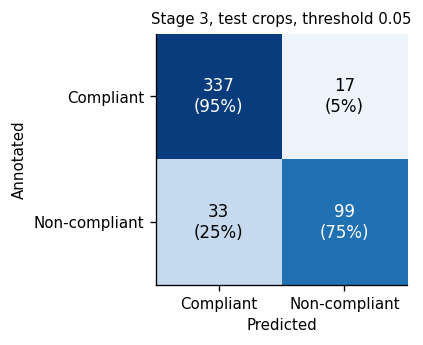

thr 0.05: TP 99 FN 33 FP 17 TN 337 | P 0.853 R 0.750 F1 0.798
   (thesis, selected threshold: TP 99, FN 33, FP 17, P 0.853, R 0.750)


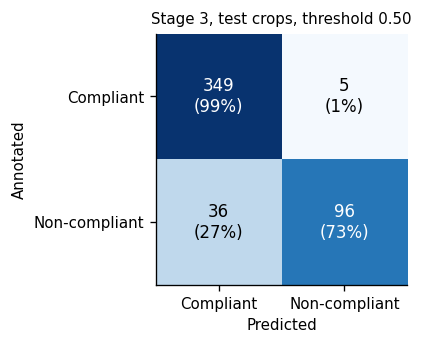

thr 0.50: TP 96 FN 36 FP 5 TN 349 | P 0.950 R 0.727 F1 0.824


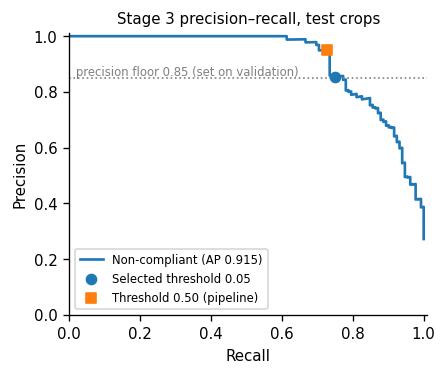

In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.2 Stage 3 on the TEST crops: confusion matrices at the selected threshold and at 0.50, PR curve with both points
from sklearn.metrics import precision_recall_curve, average_precision_score
m3 = YOLO(W['stage3'], task='classify'); j = [k for k, v in m3.names.items() if v == NC_NAME][0]
y = np.array([c == NC_NAME for _, c in S3_ITEMS])
p = np.array([float(r.probs.data[j]) for r in predict_batched(m3, [q for q, _ in S3_ITEMS], 128, imgsz=224)])

def cm_figure(thr, fname):
    pred = p >= thr
    M = np.array([[(~y & ~pred).sum(), (~y & pred).sum()], [(y & ~pred).sum(), (y & pred).sum()]])
    N = M / M.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(3.4, 3.0))
    ax.imshow(N, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for k in range(2):
            ax.text(k, i, f'{M[i, k]}\n({N[i, k]:.0%})', ha='center', va='center',
                    color='white' if N[i, k] > 0.5 else 'black', fontsize=10)
    ax.set_xticks([0, 1], ['Compliant', 'Non-compliant']); ax.set_yticks([0, 1], ['Compliant', 'Non-compliant'])
    ax.set_xlabel('Predicted'); ax.set_ylabel('Annotated')
    ax.set_title(f'Stage 3, test crops, threshold {thr:.2f}', fontsize=9)
    fig.tight_layout(); fig.savefig(f'{FIG}/{fname}', bbox_inches='tight'); plt.show()
    TP, FN, FP = M[1, 1], M[1, 0], M[0, 1]
    P, R, F = prf(TP, FP, FN)
    print(f'thr {thr:.2f}: TP {TP} FN {FN} FP {FP} TN {M[0, 0]} | P {P:.3f} R {R:.3f} F1 {F:.3f}')
    return P, R

pt_sel = cm_figure(S3_THR, 'fig_stage3_test_confusion_selected_thr.png')
print('   (thesis, selected threshold: TP 99, FN 33, FP 17, P 0.853, R 0.750)')
pt_050 = cm_figure(0.50, 'fig_stage3_test_confusion_thr050.png')

prec, rec, _ = precision_recall_curve(y, p); ap = average_precision_score(y, p)
fig, ax = plt.subplots(figsize=(3.8, 3.2))
ax.plot(rec, prec, lw=1.6, label=f'Non-compliant (AP {ap:.3f})')
ax.scatter(pt_sel[1], pt_sel[0], marker='o', zorder=3, label=f'Selected threshold {S3_THR:.2f}')
ax.scatter(pt_050[1], pt_050[0], marker='s', zorder=3, label='Threshold 0.50 (pipeline)')
ax.axhline(0.85, ls=':', lw=1, c='grey'); ax.text(0.02, 0.86, 'precision floor 0.85 (set on validation)', fontsize=7, c='grey')
ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.01); ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Stage 3 precision–recall, test crops', fontsize=9); ax.legend(fontsize=7, loc='lower left')
fig.tight_layout(); fig.savefig(f'{FIG}/fig_stage3_test_PR_curve.png', bbox_inches='tight'); plt.show()

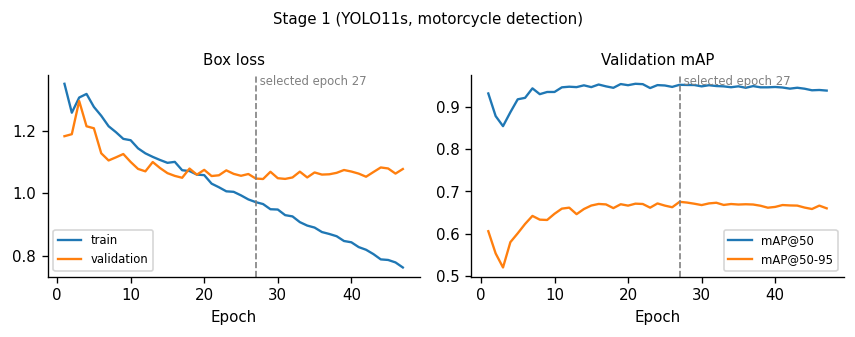

stage1: 47 epochs plotted from /content/drive/MyDrive/helmet_thesis_v2/runs/stage1_yolo11s-rf8_1280_s0/results.csv


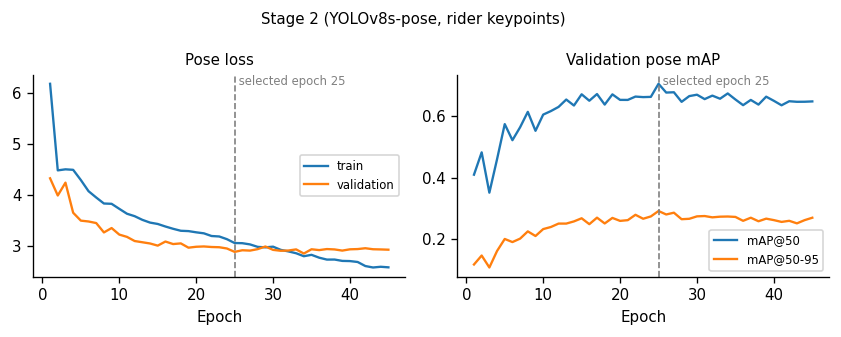

stage2: 45 epochs plotted from /content/drive/MyDrive/helmet_thesis_v2/runs/stage2_yolov8s_rf3_s0/results.csv


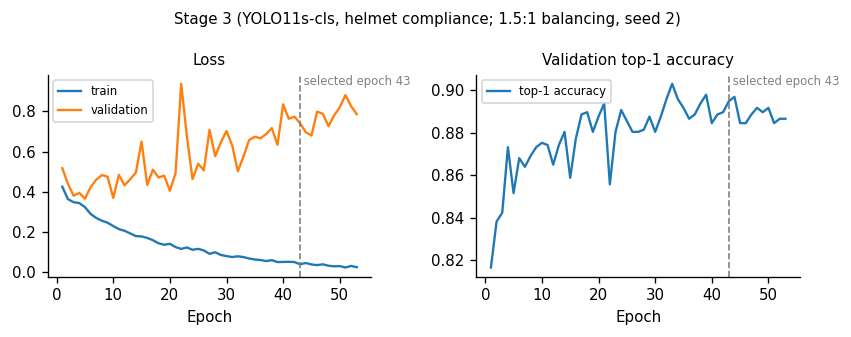

stage3: 53 epochs plotted from /content/drive/MyDrive/helmet_thesis_v2/runs/stage3_yolo11s_rf6r15_s2/results.csv


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.3 Training curves from each run's results.csv (selected epoch marked) + Ultralytics' own run-folder plots
SPEC = {'stage1': [('Box loss', [('train/box_loss', 'train'), ('val/box_loss', 'validation')]),
                   ('Validation mAP', [('metrics/mAP50(B)', 'mAP@50'), ('metrics/mAP50-95(B)', 'mAP@50-95')])],
        'stage2': [('Pose loss', [('train/pose_loss', 'train'), ('val/pose_loss', 'validation')]),
                   ('Validation pose mAP', [('metrics/mAP50(P)', 'mAP@50'), ('metrics/mAP50-95(P)', 'mAP@50-95')])],
        'stage3': [('Loss', [('train/loss', 'train'), ('val/loss', 'validation')]),
                   ('Validation top-1 accuracy', [('metrics/accuracy_top1', 'top-1 accuracy')])]}
TITLE = {'stage1': 'Stage 1 (YOLO11s, motorcycle detection)', 'stage2': 'Stage 2 (YOLOv8s-pose, rider keypoints)',
         'stage3': 'Stage 3 (YOLO11s-cls, helmet compliance; 1.5:1 balancing, seed 2)'}
for st, panels in SPEC.items():
    csv = f'{RUN_DIR[st]}/results.csv' if RUN_DIR[st] else None
    if not csv or not os.path.exists(csv):
        print(f'{st}: NO training history found ({NAME[st]}). The training-curve figure cannot be made '
              'without retraining; use the test-set figures only.'); continue
    d = pd.read_csv(csv); d.columns = d.columns.str.strip()
    fig, axes = plt.subplots(1, len(panels), figsize=(7.2, 2.8))
    for ax, (title, cols) in zip(np.atleast_1d(axes), panels):
        for col, lab in cols:
            if col in d: ax.plot(d.epoch, d[col], lw=1.4, label=lab)
        ax.axvline(BEST_EPOCH[st], ls='--', lw=1, c='grey')
        ax.text(BEST_EPOCH[st], ax.get_ylim()[1], f' selected epoch {BEST_EPOCH[st]}', fontsize=7, va='top', c='grey')
        ax.set_xlabel('Epoch'); ax.set_title(title, fontsize=9); ax.legend(fontsize=7)
    fig.suptitle(TITLE[st], fontsize=9); fig.tight_layout()
    fig.savefig(f'{FIG}/fig_{st}_training_curves.png', bbox_inches='tight'); plt.show()
    for f in ['results.png', 'labels.jpg', 'confusion_matrix_normalized.png']:      # Ultralytics' own (validation split)
        if os.path.exists(f'{RUN_DIR[st]}/{f}'):
            shutil.copy(f'{RUN_DIR[st]}/{f}', f'{FIG}/fig_{st}_trainrun_{f}')
    print(f'{st}: {len(d)} epochs plotted from {csv}')

In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.4 List what was saved, with suggested captions
CAPTIONS = {
 'fig_stage1_test_BoxPR_curve.png': 'Precision–recall curve of the Stage 1 motorcycle detector (YOLO11s) on the test split.',
 'fig_stage1_test_confusion_matrix_normalized.png': 'Normalised confusion matrix of the Stage 1 detector on the test split.',
 'fig_stage2_test_PosePR_curve.png': 'Precision–recall curve of the Stage 2 rider keypoints (YOLOv8s-pose) on the test split.',
 'fig_stage2_test_BoxPR_curve.png': 'Precision–recall curve of the Stage 2 rider boxes on the test split.',
 'fig_stage3_test_confusion_selected_thr.png': 'Confusion matrix of the Stage 3 classifier on the test crops at the validation-selected threshold.',
 'fig_stage3_test_confusion_thr050.png': 'Confusion matrix of the Stage 3 classifier on the test crops at the pipeline threshold of 0.50.',
 'fig_stage3_test_PR_curve.png': 'Precision–recall curve of the Stage 3 classifier (non-compliant class) on the test crops, with both operating points.',
 'fig_stage1_training_curves.png': 'Training and validation curves of the Stage 1 detector; the dashed line marks the selected epoch.',
 'fig_stage2_training_curves.png': 'Training and validation curves of the Stage 2 pose model; the dashed line marks the selected epoch.',
 'fig_stage3_training_curves.png': 'Training and validation curves of the Stage 3 classifier; the dashed line marks the selected epoch.'}
files = sorted(os.listdir(FIG))
print(f'{len(files)} files in {FIG}\n')
for f in files:
    print(('* ' if f in CAPTIONS else '  ') + f + (f'\n      -> {CAPTIONS[f]}' if f in CAPTIONS else ''))
print('\n* = recommended for the thesis. Files with "_trainrun_" are on the VALIDATION split: label them so if used.')

40 files in /content/drive/MyDrive/helmet_thesis_v2/results/figures

  fig_stage1_test_BoxF1_curve.png
* fig_stage1_test_BoxPR_curve.png
      -> Precision–recall curve of the Stage 1 motorcycle detector (YOLO11s) on the test split.
  fig_stage1_test_BoxP_curve.png
  fig_stage1_test_BoxR_curve.png
  fig_stage1_test_confusion_matrix.png
* fig_stage1_test_confusion_matrix_normalized.png
      -> Normalised confusion matrix of the Stage 1 detector on the test split.
  fig_stage1_test_val_batch0_labels.jpg
  fig_stage1_test_val_batch0_pred.jpg
  fig_stage1_test_val_batch1_labels.jpg
  fig_stage1_test_val_batch1_pred.jpg
  fig_stage1_test_val_batch2_labels.jpg
  fig_stage1_test_val_batch2_pred.jpg
* fig_stage1_training_curves.png
      -> Training and validation curves of the Stage 1 detector; the dashed line marks the selected epoch.
  fig_stage1_trainrun_confusion_matrix_normalized.png
  fig_stage1_trainrun_labels.jpg
  fig_stage1_trainrun_results.png
  fig_stage2_test_BoxF1_curve.png
* f

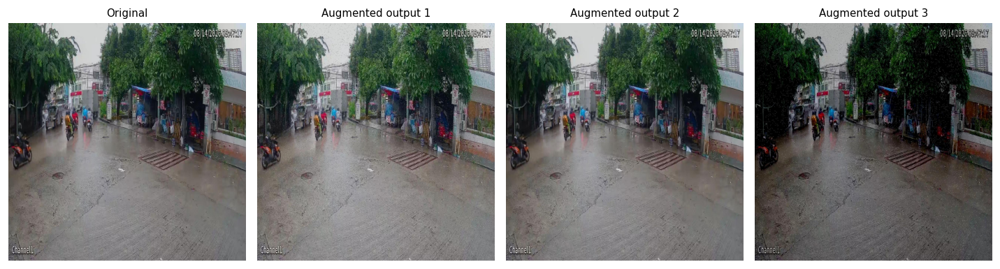

Frame used: HCVR-B36A_ch1_main_20260814090000_20260814100000_mp4-2837_jpg


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.5 One Stage 1 training frame and the three outputs Roboflow generated from it (v8, augmentation x3)
S1RAW = f'{LOCAL}/s1_raw_v8'
tr = pd.DataFrame([dict(path=p, fb=frame_base(p)) for p in list_images(f'{S1RAW}/train/images')])
V4 = dict(zip(IMGS.frame_base, IMGS.path))                      # un-augmented originals (v4, same pre-processing)
n_moto = lambda p: sum(int(float(l[0])) == mid for l in read_labels(label_for(p)))
cands = [fb for fb, g in tr.groupby('fb') if len(g) == 3 and fb in V4]
rng = random.Random(1); rng.shuffle(cands)
FB_EX = next(fb for fb in cands if n_moto(tr[tr.fb == fb].path.iloc[0]) >= 3)   # a frame with >= 3 motorcycles
outs = tr[tr.fb == FB_EX].path.tolist()
fig, ax = plt.subplots(1, 4, figsize=(12, 3.3))
for a, (p, t) in zip(ax, [(V4[FB_EX], 'Original')] + [(q, f'Augmented output {i + 1}') for i, q in enumerate(outs)]):
    a.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); a.set_title(t, fontsize=9); a.axis('off')
fig.tight_layout(); fig.savefig(f'{FIG}/fig_dataset_stage1_augmentation_example.png', bbox_inches='tight'); plt.show()
print('Frame used:', FB_EX)

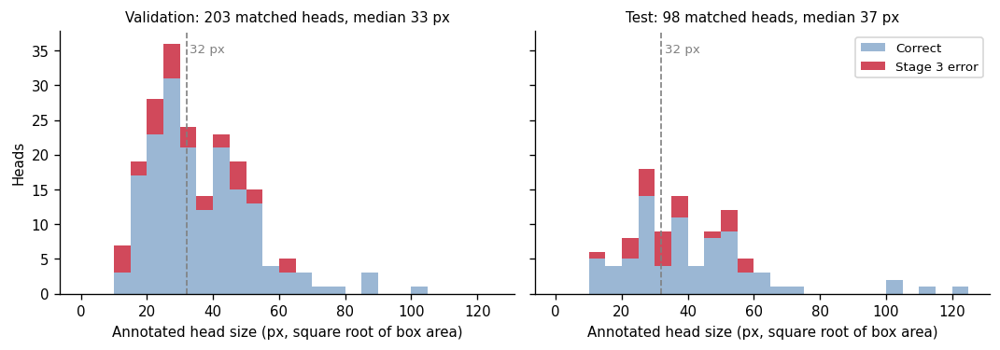

       count  mean   std   min   25%   50%   75%    max
split                                                  
test    98.0  40.2  20.0  13.4  27.2  36.9  50.5  123.7
valid  203.0  35.9  15.6  11.8  24.9  33.3  45.2  104.9


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# FIG.6 Size of the annotated heads the final pipeline judged (valid + test), split by correct / wrong Stage 3 decision
SZ = pd.read_csv(f'{RES}/head_size_errors_s123.csv')           # saved by cell RQ2 C
bins = np.arange(0, max(100, SZ.size_px.max()) + 5, 5)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for a, sp in zip(axes, ['valid', 'test']):
    d = SZ[SZ.split == sp]
    a.hist([d[d.correct].size_px, d[~d.correct].size_px], bins=bins, stacked=True,
           label=['Correct', 'Stage 3 error'], color=['#9bb7d4', '#d1495b'])
    a.axvline(32, ls='--', lw=1, c='grey'); a.text(33, a.get_ylim()[1] * 0.92, '32 px', fontsize=8, c='grey')
    a.set_title(f"{'Validation' if sp == 'valid' else 'Test'}: {len(d)} matched heads, median {d.size_px.median():.0f} px", fontsize=9)
    a.set_xlabel('Annotated head size (px, square root of box area)')
axes[0].set_ylabel('Heads'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(f'{FIG}/fig_dataset_head_size_histogram.png', bbox_inches='tight'); plt.show()
print(SZ.groupby('split').size_px.describe(percentiles=[.25, .5, .75]).round(1).to_string())

## B.3 Defense slide figures (S6, S13, S15, S16)
**Run first (fresh session):** 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1. Each cell loads the final system itself (do not run H.1 first). S13–S16 also use `evaluate_e2e` rules, so run **5.3** too.

FINAL system: stage1_yolo11s-rf8_1280_s0 (conf 0.41) + stage2_yolov8s_rf3_s0 (conf 0.3, iou 0.5) + stage3_yolo11s_rf6r15_s2 (thr 0.5) | anchor neck | T 0.7 | head off (-0.031483180820941925, -0.5546953678131104), scale 0.6038506627082825
50/234 frames, 9 verified motorcycles so far
100/234 frames, 27 verified motorcycles so far
150/234 frames, 29 verified motorcycles so far
200/234 frames, 42 verified motorcycles so far
62 verified motorcycles | with both labels: 0 | 2+ riders: 5 | (run D.1/F.1 first to also prefer frames unseen in training)


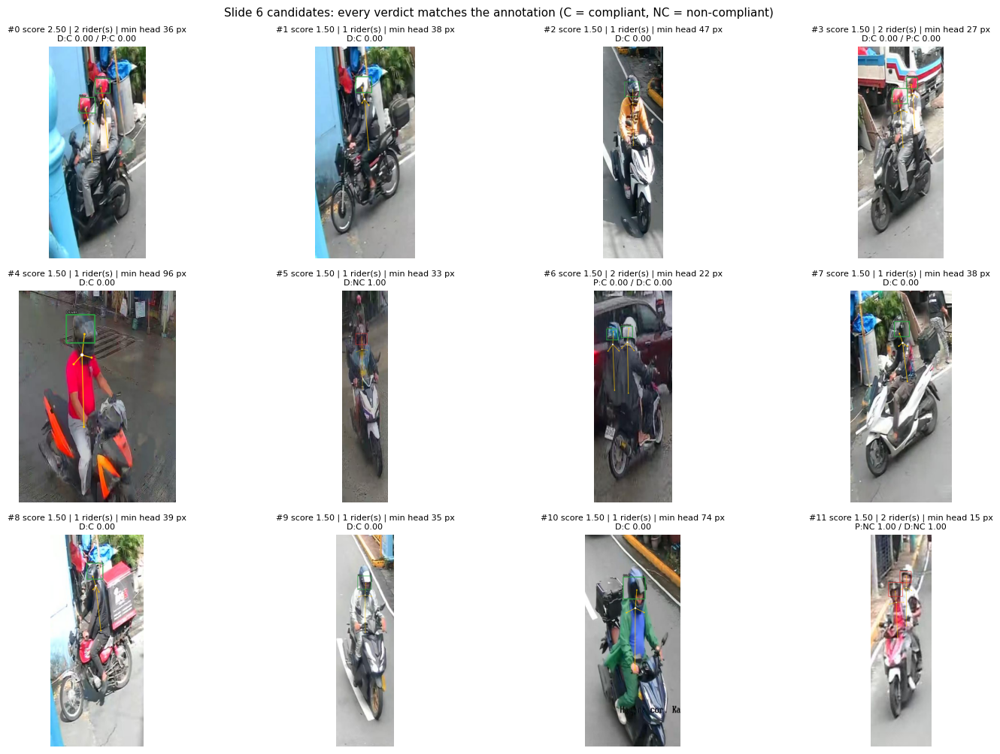

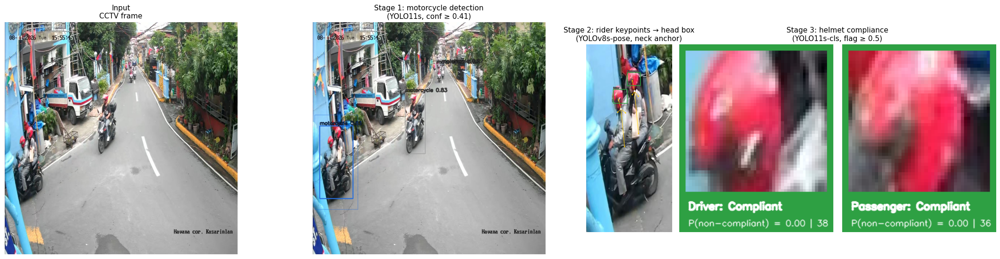

Frame: /content/work/s1_raw_v4/valid/images/fixed_video3_mp4-0419_jpg.rf.e217351c28cbe636f0dcbf8b90954fca.jpg | motorcycle 1 | unseen by all three models: None
  Driver: compliant (P = 0.00), head 38 px, Path A  [matches annotation]
  Passenger: compliant (P = 0.00), head 36 px, Path A  [matches annotation]
Saved to /content/drive/MyDrive/helmet_thesis_v2/results/figures : slide6_pipeline_strip.png + slide6_panel1-4 PNGs


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# S6 SLIDE 6 DEMO FIGURE: one end-to-end TEST frame drawn through all three stages of the FINAL system
# Uses the notebook's own pipeline (run_pipeline from 5.1), so the picture is exactly what the system does.
# RUN FIRST (fresh session): 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1   (NOT H.1: this cell loads the final system itself)
#
# What it does
#   1. Loads the FINAL system (stage1_selected_rf8 + stage2_selected_rf3 + stage3_selected_rf6, neck anchor,
#      head box, T and threshold from e2e_final_config_s123.json), the same way H.1 does.
#   2. Runs it on the end-to-end TEST frames and keeps motorcycles where EVERY predicted head matches an
#      annotated head with the SAME label (so the example is verified, not cherry-picked wrong).
#      Preferred: 2+ riders, one compliant + one non-compliant, heads >= 32 px, frame unseen in training.
#   3. Shows the best candidates (numbered) and renders candidate CHOSEN as a 4-panel strip.
#      To render another, set CHOSEN and re-run: the search is cached.
# Output: {RES}/figures/slide6_pipeline_strip.png (300 dpi) + panel1-4 PNGs for laying out in PowerPoint.
# Blur faces and plate numbers before putting the image on a slide.

CHOSEN   = 0        # candidate to render (number on the contact sheet)
N_SHOW   = 12       # candidates on the contact sheet
MIN_HEAD = 32       # preferred minimum head size in px (readable on a slide)
FORCE_SEARCH = False

import numpy as np, cv2, matplotlib.pyplot as plt
from ultralytics import YOLO
assert 'run_pipeline' in globals() and 'TEST_FRAMES' in globals(), 'run 0.1-0.3, 1.2, 3.1, 3.4a and 5.1 first'

# ---- 1. load the FINAL system (same as H.1, without the latency profiling) ----
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json')
S1_SEL = load_json(f'{RES}/stage1_selected_rf8.json'); S2_SEL = load_json(f'{RES}/stage2_selected_rf3.json')
_s3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert CFG3 and S1_SEL and S2_SEL and _s3, 'missing selection/config files in results/'
S3_SEL = {k: _s3[k] for k in ['name', 'weights', 'threshold', 'epoch']}
S3_SEL['threshold'] = CFG3['s3_threshold']; S3_NAME = S3_SEL['name']
HEAD_KPTS = [KEYPOINT_NAMES.index(CFG3['anchor'])]
HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(CFG3['head_off']), CFG3['head_scale'], CFG3['T']
DET, POSE, CLS = YOLO(S1_SEL['weights'], task='detect'), YOLO(S2_SEL['weights'], task='pose'), YOLO(S3_SEL['weights'], task='classify')
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"FINAL system: {S1_SEL['run']} (conf {S1_SEL['conf']}) + {S2_SEL['run']} (conf {S2_SEL['conf']}, iou {S2_SEL['iou']}) + "
      f"{S3_NAME} (thr {S3_SEL['threshold']}) | anchor {CFG3['anchor']} | T {T_GATE} | head off {HEAD_OFF}, scale {HEAD_BOX_SCALE}")

# frames no model trained on (only known if D.1 / F.1 ran in this session; otherwise every frame counts as 'unknown')
_seen = set()
for _n in ['S1_TRAIN_FRAMES', 'S2_TRAIN_FRAMES', 'S3_TRAIN_FRAMES']:
    _seen |= set(globals().get(_n, set()))
SEEN_KNOWN = bool(_seen)

def head_px(h):
    x1, y1, x2, y2 = h['box']; return int(min(x2 - x1, y2 - y1))

# ---- 2. search the end-to-end TEST frames (cached) ----
if FORCE_SEARCH or '_S6' not in globals() or _S6.get('sys') != (S1_SEL['run'], S2_SEL['run'], S3_NAME):
    cands = []
    for n, p in enumerate(TEST_FRAMES):
        fr = cv2.imread(p); H, W = fr.shape[:2]
        out = run_pipeline(fr)
        heads, gt = out['heads'], gt_heads(p, W, H)
        pairs = dict(match_heads(heads, gt))                       # pred index -> gt index
        for mi in sorted({h['moto'] for h in heads}):
            idx = [i for i, h in enumerate(heads) if h['moto'] == mi]
            ok = all(i in pairs and gt[pairs[i]][1] == heads[i]['label'] for i in idx)
            if not ok:
                continue                                           # a wrong or unverifiable verdict: not a demo
            labs = {heads[i]['label'] for i in idx}
            small = min(head_px(heads[i]) for i in idx)
            unseen = (frame_base(p) not in _seen) if SEEN_KNOWN else None
            score = (2.0 * (len(labs) == 2) + 1.0 * (len(idx) >= 2) + 1.0 * (small >= MIN_HEAD)
                     + 0.5 * bool(unseen) + min(abs(heads[i]['p_nc'] - S3_SEL['threshold']) for i in idx))
            cands.append(dict(score=score, path=p, moto=mi, n_riders=len(idx), mixed=len(labs) == 2,
                              min_head=small, unseen=unseen))
        if (n + 1) % 50 == 0:
            print(f'{n + 1}/{len(TEST_FRAMES)} frames, {len(cands)} verified motorcycles so far')
    cands.sort(key=lambda c: -c['score'])
    _S6 = dict(sys=(S1_SEL['run'], S2_SEL['run'], S3_NAME), cands=cands)
cands = _S6['cands']
print(f"{len(cands)} verified motorcycles | with both labels: {sum(c['mixed'] for c in cands)} | "
      f"2+ riders: {sum(c['n_riders'] >= 2 for c in cands)}"
      + ('' if SEEN_KNOWN else ' | (run D.1/F.1 first to also prefer frames unseen in training)'))
assert cands, 'no verified motorcycle found'

# ---- drawing helpers ----
GREEN, RED, BLUE, GREY, YEL = (46, 160, 67), (220, 50, 47), (38, 110, 220), (160, 160, 160), (255, 200, 0)
EDGES = [('head', 'neck'), ('shoulder_l', 'neck'), ('shoulder_r', 'neck'), ('neck', 'pelvis')]
def col(h): return RED if h['label'] == 'non-compliant' else GREEN
def put(img, txt, xy, scale, color, th):
    cv2.putText(img, txt, xy, cv2.FONT_HERSHEY_SIMPLEX, scale, (0, 0, 0), th + 2, cv2.LINE_AA)
    cv2.putText(img, txt, xy, cv2.FONT_HERSHEY_SIMPLEX, scale, color, th, cv2.LINE_AA)

def render(c):
    fr = cv2.imread(c['path']); H, W = fr.shape[:2]; rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
    out = run_pipeline(fr); mi = c['moto']
    heads = [h for h in out['heads'] if h['moto'] == mi]
    cx1, cy1, cx2, cy2 = out['regions'][mi]
    t = max(2, W // 640)
    # Stage 1 again (same call as run_pipeline) to get every box + confidence; find the box behind this crop
    r1 = DET.predict(fr, imgsz=S1_SEL['imgsz'], conf=S1_SEL['conf'], verbose=False)[0]
    boxes, confs = r1.boxes.xyxy.cpu().numpy(), r1.boxes.conf.cpu().numpy()
    regs = [make_crop(fr, b)[1] for b in boxes]
    sel = [tuple(r) == tuple(out['regions'][mi]) for r in regs]
    assert any(sel), 'could not re-find the Stage 1 box for this motorcycle'
    # Panel 2: Stage 1 detections (chosen motorcycle in blue, its 15%-padded crop as a thin line)
    p2 = rgb.copy()
    for b, s, on in zip(boxes, confs, sel):
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(p2, (x1, y1), (x2, y2), BLUE if on else GREY, t + int(on), cv2.LINE_AA)
        put(p2, f'motorcycle {s:.2f}', (x1, max(15, y1 - 6)), 0.45 * t, BLUE if on else GREY, max(1, t - 1))
    cv2.rectangle(p2, (cx1, cy1), (cx2, cy2), BLUE, 1, cv2.LINE_AA)
    # Panel 3: the padded crop, Stage 2 re-run on the SAME 640x640 input (make_crop), keypoints + head boxes
    crop640, _ = make_crop(fr, boxes[sel.index(True)])
    r2 = POSE.predict(crop640, imgsz=S2_SIZE, conf=S2_SEL['conf'], iou=S2_SEL['iou'], verbose=False)[0]
    b2, s2, kxy, kc = pose_arrays(r2)
    pw = 640; k = pw / (cx2 - cx1)                                 # frame px -> panel px
    p3 = cv2.resize(rgb[cy1:cy2, cx1:cx2], (pw, max(1, int(round((cy2 - cy1) * k)))), interpolation=cv2.INTER_CUBIC)
    sx, sy = (cx2 - cx1) / S2_SIZE * k, (cy2 - cy1) / S2_SIZE * k
    for r in range(len(b2)):
        pts = {nm: (int(kxy[r, j, 0] * sx), int(kxy[r, j, 1] * sy), kc[r, j]) for j, nm in enumerate(KEYPOINT_NAMES)}
        for a, b in EDGES:
            if pts[a][2] >= T_GATE and pts[b][2] >= T_GATE:
                cv2.line(p3, pts[a][:2], pts[b][:2], YEL, 2, cv2.LINE_AA)
        for nm, (x, y, cf) in pts.items():
            if cf >= T_GATE:
                anc = nm == CFG3['anchor']
                cv2.circle(p3, (x, y), 6 if anc else 4, (255, 255, 255) if anc else YEL, -1, cv2.LINE_AA)
    for h in heads:
        x1, y1, x2, y2 = [int((v - o) * k) for v, o in zip(h['box'], (cx1, cy1, cx1, cy1))]
        cv2.rectangle(p3, (x1, y1), (x2, y2), col(h), 3, cv2.LINE_AA)
        put(p3, h['role'], (x1, max(14, y1 - 6)), 0.5, (255, 255, 255), 1)
    # Panel 4: the head crops exactly as Stage 3 receives them (S3_PAD), enlarged, with the verdict
    tiles = []
    for h in sorted(heads, key=lambda h: h['role'] != 'Driver'):
        x1, y1, x2, y2 = h['box']; p = S3_PAD * (x2 - x1)
        hc = rgb[int(max(0, y1 - p)):int(min(H, y2 + p)), int(max(0, x1 - p)):int(min(W, x2 + p))]
        tile = cv2.resize(hc, (224, 224), interpolation=cv2.INTER_NEAREST)
        tile = cv2.copyMakeBorder(tile, 10, 64, 10, 10, cv2.BORDER_CONSTANT, value=col(h))
        cv2.putText(tile, f"{h['role']}: {'NON-COMPLIANT' if h['label'] == 'non-compliant' else 'Compliant'}", (14, 262),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(tile, f"P(non-compliant) = {h['p_nc']:.2f} | {head_px(h)} px", (14, 288),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
        tiles.append(tile); tiles.append(np.full((tile.shape[0], 14, 3), 255, np.uint8))
    p4 = np.concatenate(tiles[:-1], 1)
    return rgb, p2, p3, p4, heads

# ---- 3a. contact sheet ----
show = cands[:N_SHOW]; cols = 4; rows = int(np.ceil(len(show) / cols))
fig, axs = plt.subplots(rows, cols, figsize=(4 * cols, 3.4 * rows)); axs = np.atleast_1d(axs).ravel()
for ax in axs: ax.axis('off')
for i, c in enumerate(show):
    _, _, p3, _, hs = render(c)
    axs[i].imshow(p3)
    axs[i].set_title(f"#{i} score {c['score']:.2f} | {c['n_riders']} rider(s) | min head {c['min_head']} px"
                     f"{'' if c['unseen'] is None else (' | unseen' if c['unseen'] else ' | seen in training')}\n"
                     + ' / '.join(f"{h['role'][0]}:{'NC' if h['label'] == 'non-compliant' else 'C'} {h['p_nc']:.2f}" for h in hs), fontsize=8)
plt.suptitle('Slide 6 candidates: every verdict matches the annotation (C = compliant, NC = non-compliant)', fontsize=11)
plt.tight_layout(); plt.show()

# ---- 3b. the four-panel strip for the chosen candidate ----
c = cands[CHOSEN]
p1, p2, p3, p4, hs = render(c)
titles = ['Input\nCCTV frame',
          f"Stage 1: motorcycle detection\n(YOLO11s, conf ≥ {S1_SEL['conf']})",
          f"Stage 2: rider keypoints → head box\n(YOLOv8s-pose, {CFG3['anchor']} anchor)",
          f"Stage 3: helmet compliance\n(YOLO11s-cls, flag ≥ {S3_SEL['threshold']})"]
fig, axs = plt.subplots(1, 4, figsize=(22, 5.6),
                        gridspec_kw=dict(width_ratios=[1.6, 1.6, p3.shape[1] / p3.shape[0], p4.shape[1] / p4.shape[0]]))
for ax, im, ti in zip(axs, [p1, p2, p3, p4], titles):
    ax.imshow(im); ax.set_title(ti, fontsize=11); ax.axis('off')
plt.tight_layout()
FIGD = f'{RES}/figures'; os.makedirs(FIGD, exist_ok=True)
plt.savefig(f'{FIGD}/slide6_pipeline_strip.png', dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
for nm, im in zip(['slide6_panel1_frame', 'slide6_panel2_stage1', 'slide6_panel3_stage2', 'slide6_panel4_stage3'], [p1, p2, p3, p4]):
    cv2.imwrite(f'{FIGD}/{nm}.png', cv2.cvtColor(im, cv2.COLOR_RGB2BGR))
print('Frame:', c['path'], '| motorcycle', c['moto'], '| unseen by all three models:', c['unseen'])
for h in hs:
    print(f"  {h['role']}: {h['label']} (P = {h['p_nc']:.2f}), head {head_px(h)} px, Path {h['path']}  [matches annotation]")
print('Saved to', FIGD, ': slide6_pipeline_strip.png + slide6_panel1-4 PNGs')

FINAL system: stage1_yolo11s-rf8_1280_s0 + stage2_yolov8s_rf3_s0 + stage3_yolo11s_rf6r15_s2 | anchor neck | T 0.7 | thr 0.5
0 exempt GT heads loaded
50/234 frames
100/234 frames
150/234 frames
200/234 frames
Flags on 234 test frames: correct 21, false accusation 15, misplaced 2, unverifiable 35 (total 73)
Thesis (Slide 13): 21 / 15 / 2 / 35, total 73 -> MATCH


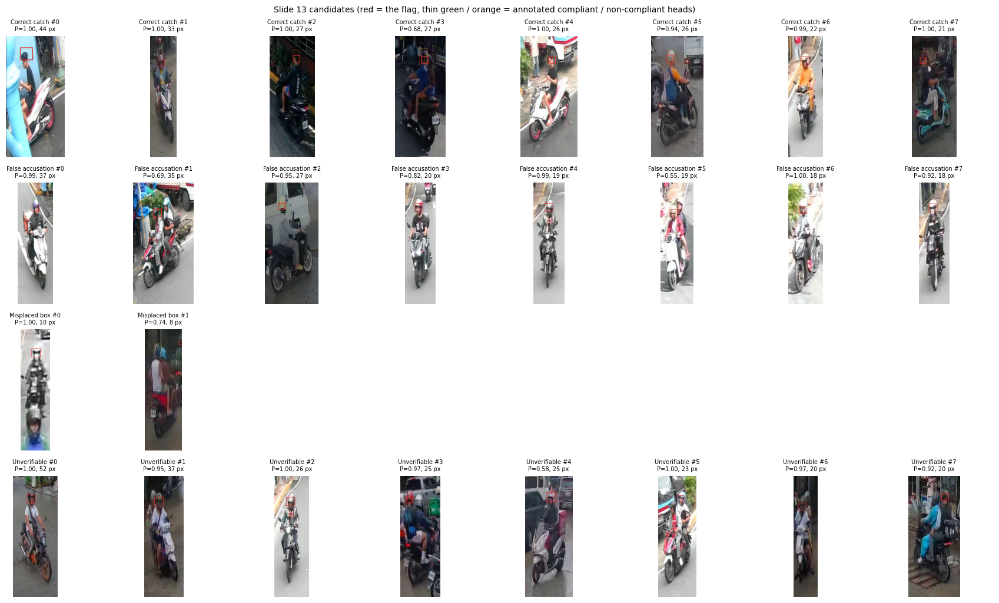

Correct catch     -> /content/work/s1_raw_v4/train/images/fixed_video_mp4-0968_jpg.rf.8121f59dad781954367d096fa908ab86.jpg | P = 1.00 | head 44 px | unseen: None
False accusation  -> /content/work/s1_raw_v4/train/images/fixed_video3_mp4-0428_jpg.rf.ea4c07cacd1fb6de8d798639e1337cdd.jpg | P = 0.99 | head 37 px | unseen: None
Misplaced box     -> /content/work/s1_raw_v4/train/images/fixed_video3_mp4-0428_jpg.rf.ea4c07cacd1fb6de8d798639e1337cdd.jpg | P = 1.00 | head 10 px | unseen: None
Unverifiable      -> /content/work/s1_raw_v4/train/images/HCVR-B36A_ch1_main_20260811080000_20260811090000_mp4-0518_jpg.rf.1815807bddbbd3f6b3a17e5c9823c565.jpg | P = 1.00 | head 52 px | unseen: None


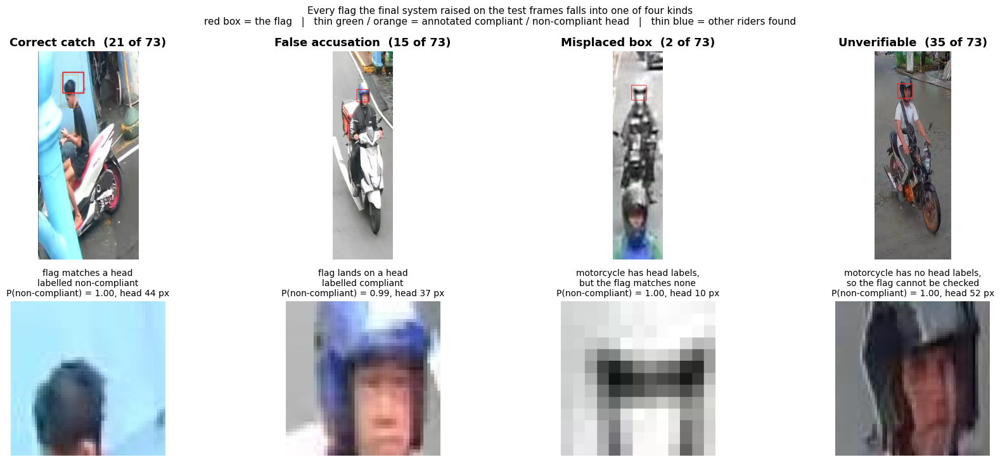

Saved to /content/drive/MyDrive/helmet_thesis_v2/results/figures : slide13_flag_examples.png + slide13_<type>_scene/head PNGs


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# S13 SLIDE 13 EXAMPLES: one real example of each kind of flag the FINAL system raised on the end-to-end TEST frames
#   Correct catch  = flag on an annotated NON-COMPLIANT head                  (true positive)
#   False accusation = flag on an annotated COMPLIANT head
#   Misplaced box  = flag on a motorcycle that has head labels, but the flag matches none of them (localisation)
#   Unverifiable   = flag on a motorcycle with NO head labels, so nobody can say if it was right
# Same rules as evaluate_e2e (5.3), so the counts it prints must equal the thesis (21 / 15 / 2 / 35).
# RUN FIRST (fresh session): 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1   (the Slide 6 cell is not needed)
# Output: {RES}/figures/slide13_flag_examples.png (300 dpi) + one PNG per example.
# To use a different example of a type, change its number in CHOSEN and re-run (the search is cached).
# Blur faces and plate numbers before putting the image on a slide.

CHOSEN = {'TP': 0, 'FA': 0, 'LOC': 0, 'UNVER': 0}   # candidate number per type (see the contact sheets)
N_SHOW = 8                                          # candidates per type on the contact sheets
FORCE_SEARCH = False

import numpy as np, cv2, matplotlib.pyplot as plt
from ultralytics import YOLO
assert 'run_pipeline' in globals() and 'TEST_FRAMES' in globals(), 'run 0.1-0.3, 1.2, 3.1, 3.4a and 5.1 first'

# ---- 1. load the FINAL system (same as H.1, no profiling) ----
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json')
S1_SEL = load_json(f'{RES}/stage1_selected_rf8.json'); S2_SEL = load_json(f'{RES}/stage2_selected_rf3.json')
_s3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert CFG3 and S1_SEL and S2_SEL and _s3, 'missing selection/config files in results/'
S3_SEL = {k: _s3[k] for k in ['name', 'weights', 'threshold', 'epoch']}
S3_SEL['threshold'] = CFG3['s3_threshold']; S3_NAME = S3_SEL['name']
HEAD_KPTS = [KEYPOINT_NAMES.index(CFG3['anchor'])]
HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(CFG3['head_off']), CFG3['head_scale'], CFG3['T']
DET, POSE, CLS = YOLO(S1_SEL['weights'], task='detect'), YOLO(S2_SEL['weights'], task='pose'), YOLO(S3_SEL['weights'], task='classify')
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"FINAL system: {S1_SEL['run']} + {S2_SEL['run']} + {S3_NAME} | anchor {CFG3['anchor']} | T {T_GATE} | thr {S3_SEL['threshold']}")

# exempt heads (5.1c), so scoring is identical to the thesis run
_ex = {(e['frame'], e['gt_index']) for e in (load_json(f'{RES}/e2e_exempt_heads.json', []) or [])}
_gt_plain = globals().get('_gt_heads_orig', gt_heads)
def gt_heads_s13(fp, W, H):
    fb = frame_base(fp)
    return [(box, 'exempt' if (fb, b) in _ex else lab) for b, (box, lab) in enumerate(_gt_plain(fp, W, H))]
print(f'{len(_ex)} exempt GT heads loaded')

def in_region(box, reg):
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    return reg[0] <= cx <= reg[2] and reg[1] <= cy <= reg[3]
def head_px(b): return int(min(b[2] - b[0], b[3] - b[1]))

_seen = set()
for _n in ['S1_TRAIN_FRAMES', 'S2_TRAIN_FRAMES', 'S3_TRAIN_FRAMES']:
    _seen |= set(globals().get(_n, set()))

# ---- 2. classify every flag on the TEST frames (cached) ----
KEY = (S1_SEL['run'], S2_SEL['run'], S3_NAME, len(TEST_FRAMES))
if FORCE_SEARCH or '_S13' not in globals() or _S13.get('key') != KEY:
    found = {'TP': [], 'FA': [], 'LOC': [], 'UNVER': []}
    for n, fp in enumerate(TEST_FRAMES):
        fr = cv2.imread(fp); H, W = fr.shape[:2]
        out = run_pipeline(fr); gt = gt_heads_s13(fp, W, H); pred = out['heads']
        g_of_p = dict(match_heads(pred, gt))
        for a, h in enumerate(pred):
            if h['label'] != 'non-compliant':
                continue
            if a in g_of_p:
                lab = gt[g_of_p[a]][1]
                if lab == 'exempt': continue
                kind = 'TP' if lab == 'non-compliant' else 'FA'
            elif any(in_region(g[0], out['regions'][h['moto']]) for g in gt):
                kind = 'LOC'
            else:
                kind = 'UNVER'
            found[kind].append(dict(path=fp, head=a, moto=h['moto'], p_nc=h['p_nc'], px=head_px(h['box']),
                                    unseen=(frame_base(fp) not in _seen) if _seen else None))
        if (n + 1) % 50 == 0:
            print(f'{n + 1}/{len(TEST_FRAMES)} frames')
    for k in found:   # best demo first: unseen frames, bigger (readable) heads, clearer verdicts
        found[k].sort(key=lambda c: (-(c['unseen'] is True), -min(c['px'], 64), -c['p_nc']))
    _S13 = dict(key=KEY, found=found)
found = _S13['found']
cnt = {k: len(v) for k, v in found.items()}
print(f"Flags on {len(TEST_FRAMES)} test frames: correct {cnt['TP']}, false accusation {cnt['FA']}, "
      f"misplaced {cnt['LOC']}, unverifiable {cnt['UNVER']} (total {sum(cnt.values())})")
print('Thesis (Slide 13): 21 / 15 / 2 / 35, total 73 ->', 'MATCH' if (cnt['TP'], cnt['FA'], cnt['LOC'], cnt['UNVER']) == (21, 15, 2, 35)
      else 'DIFFERENT: check that 1.2 loaded the master split and 5.1c exemptions match the thesis run')

# ---- drawing ----
NAMES = {'TP': 'Correct catch', 'FA': 'False accusation', 'LOC': 'Misplaced box', 'UNVER': 'Unverifiable'}
WHY = {'TP': 'flag matches a head\nlabelled non-compliant',
       'FA': 'flag lands on a head\nlabelled compliant',
       'LOC': 'motorcycle has head labels,\nbut the flag matches none',
       'UNVER': 'motorcycle has no head labels,\nso the flag cannot be checked'}
RED, GREEN, ORANGE, BLUE = (220, 50, 47), (46, 160, 67), (255, 150, 0), (38, 110, 220)

def render(c):
    """Returns (motorcycle crop with boxes, head crop as Stage 3 saw it, flag dict)."""
    fr = cv2.imread(c['path']); H, W = fr.shape[:2]; rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
    out = run_pipeline(fr); h = out['heads'][c['head']]; gt = gt_heads_s13(c['path'], W, H)
    x1, y1, x2, y2 = out['regions'][h['moto']]
    k = 420 / (x2 - x1)
    img = cv2.resize(rgb[y1:y2, x1:x2], (420, max(1, int(round((y2 - y1) * k)))), interpolation=cv2.INTER_CUBIC)
    P = lambda b: [int((b[0] - x1) * k), int((b[1] - y1) * k), int((b[2] - x1) * k), int((b[3] - y1) * k)]
    for box, lab in gt:                                    # annotated heads (thin): green compliant, orange non-compliant
        if in_region(box, (x1, y1, x2, y2)):
            a, b_, c_, d = P(box)
            cv2.rectangle(img, (a, b_), (c_, d), GREEN if lab == 'compliant' else ORANGE, 1, cv2.LINE_AA)
    for o in out['heads']:                                 # every head this motorcycle produced (dashed look = thin blue)
        if o['moto'] == h['moto'] and o is not h:
            a, b_, c_, d = P(o['box']); cv2.rectangle(img, (a, b_), (c_, d), BLUE, 1, cv2.LINE_AA)
    a, b_, c_, d = P(h['box']); cv2.rectangle(img, (a, b_), (c_, d), RED, 3, cv2.LINE_AA)   # THE flag
    bx1, by1, bx2, by2 = h['box']; p = S3_PAD * (bx2 - bx1)
    hc = rgb[int(max(0, by1 - p)):int(min(H, by2 + p)), int(max(0, bx1 - p)):int(min(W, bx2 + p))]
    hc = cv2.resize(hc, (200, 200), interpolation=cv2.INTER_NEAREST) if hc.size else np.zeros((200, 200, 3), np.uint8)
    return img, hc, h

# ---- 3a. contact sheets, one row per type ----
kinds = [k for k in ['TP', 'FA', 'LOC', 'UNVER'] if found[k]]
fig, axs = plt.subplots(len(kinds), N_SHOW, figsize=(2.2 * N_SHOW, 2.6 * len(kinds)), squeeze=False)
for ax in axs.ravel(): ax.axis('off')
for r, kd in enumerate(kinds):
    for i, c in enumerate(found[kd][:N_SHOW]):
        img, hc, h = render(c)
        axs[r, i].imshow(img)
        axs[r, i].set_title(f"{NAMES[kd]} #{i}\nP={c['p_nc']:.2f}, {c['px']} px"
                            + ('' if c['unseen'] is None else (', unseen' if c['unseen'] else ', seen')), fontsize=7)
plt.suptitle('Slide 13 candidates (red = the flag, thin green / orange = annotated compliant / non-compliant heads)', fontsize=10)
plt.tight_layout(); plt.show()

# ---- 3b. the figure: one column per type ----
fig, axs = plt.subplots(2, len(kinds), figsize=(4.6 * len(kinds), 7.4), squeeze=False,
                        gridspec_kw=dict(height_ratios=[1.35, 1]))
FIGD = f'{RES}/figures'; os.makedirs(FIGD, exist_ok=True)
for j, kd in enumerate(kinds):
    c = found[kd][min(CHOSEN.get(kd, 0), len(found[kd]) - 1)]
    img, hc, h = render(c)
    axs[0, j].imshow(img); axs[0, j].axis('off')
    axs[0, j].set_title(f"{NAMES[kd]}  ({cnt[kd]} of {sum(cnt.values())})", fontsize=13, fontweight='bold')
    axs[1, j].imshow(hc); axs[1, j].axis('off')
    axs[1, j].set_title(f"{WHY[kd]}\nP(non-compliant) = {h['p_nc']:.2f}, head {c['px']} px", fontsize=10)
    cv2.imwrite(f'{FIGD}/slide13_{kd.lower()}_scene.png', cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f'{FIGD}/slide13_{kd.lower()}_head.png', cv2.cvtColor(hc, cv2.COLOR_RGB2BGR))
    print(f"{NAMES[kd]:17s} -> {c['path']} | P = {h['p_nc']:.2f} | head {c['px']} px | unseen: {c['unseen']}")
plt.suptitle('Every flag the final system raised on the test frames falls into one of four kinds\n'
             'red box = the flag   |   thin green / orange = annotated compliant / non-compliant head   |   thin blue = other riders found',
             fontsize=11)
plt.tight_layout()
plt.savefig(f'{FIGD}/slide13_flag_examples.png', dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('Saved to', FIGD, ': slide13_flag_examples.png + slide13_<type>_scene/head PNGs')

FINAL system: stage1_yolo11s-rf8_1280_s0 + stage2_yolov8s_rf3_s0 + stage3_yolo11s_rf6r15_s2 | anchor neck | T 0.7 | thr 0.5
50/234 frames
100/234 frames
150/234 frames
200/234 frames
Test violators: 37 | caught 21 | missed 16: Stage 1 1, Stage 2 8, Stage 3 7
Thesis (Slide 15): caught 21, missed 16 = 1 / 8 / 7 -> MATCH


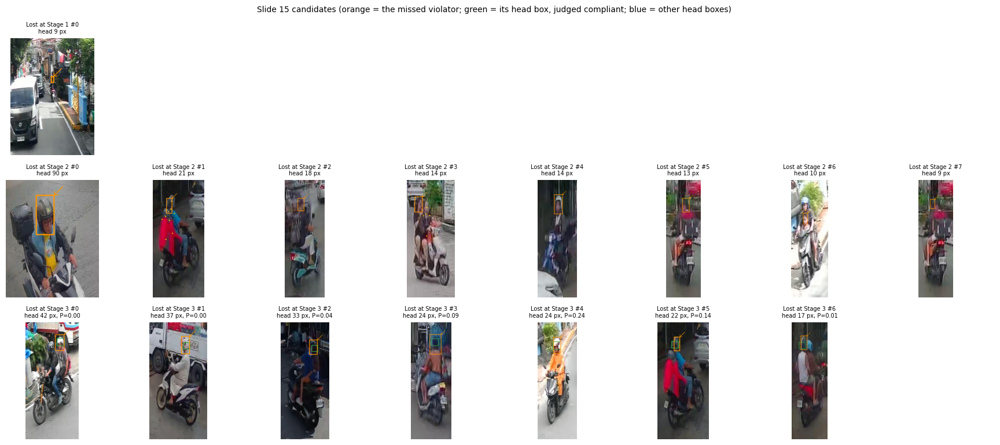

Lost at Stage 1  -> /content/work/s1_raw_v4/train/images/fixed_video_mp4-3445_jpg.rf.c463e5ad25b575b19abd831f86eadb5f.jpg | head 9 px | P = None | unseen: None
Lost at Stage 2  -> /content/work/s1_raw_v4/valid/images/HCVR-B36A_ch1_main_20260811140000_20260811150000_mp4-0420_jpg.rf.86fe9d6d5bc344dd1b34994b995e85b9.jpg | head 90 px | P = None | unseen: None
Lost at Stage 3  -> /content/work/s1_raw_v4/train/images/fixed_video3_mp4-0416_jpg.rf.193ef1b83aff946b55b9fc6264d41076.jpg | head 42 px | P = 8.675798568447135e-08 | unseen: None


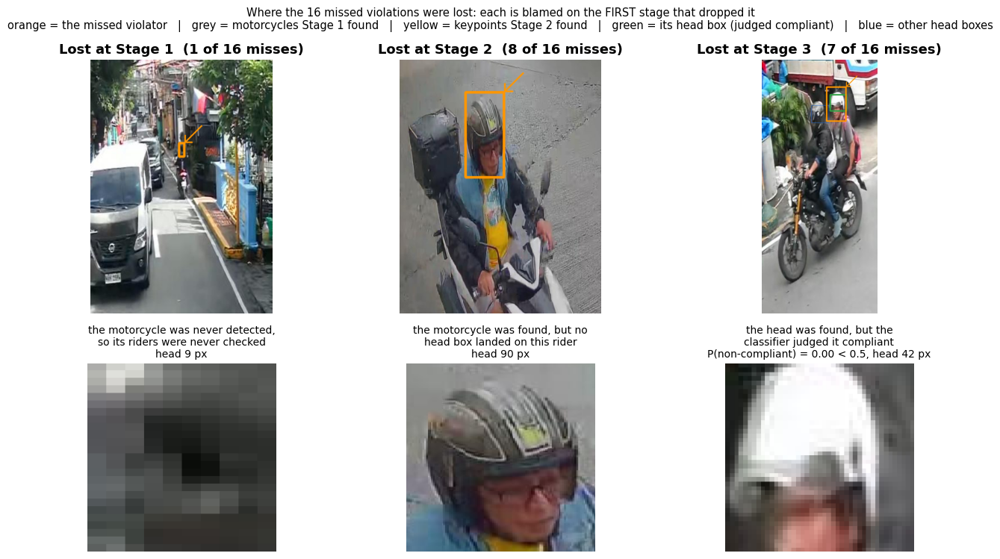

Saved to /content/drive/MyDrive/helmet_thesis_v2/results/figures : slide15_miss_examples.png + slide15_<stage>_scene/head PNGs


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# S15 SLIDE 15 EXAMPLES: one real MISSED violation per stage that lost it (FINAL system, end-to-end TEST frames)
#   Stage 1 miss = the motorcycle carrying the violator was never detected
#   Stage 2 miss = the motorcycle was found, but no head box landed on the violator
#   Stage 3 miss = the head was found, but the classifier judged it compliant
# Same attribution rules as evaluate_e2e (5.3), so the counts it prints must equal the thesis (1 / 8 / 7).
# RUN FIRST (fresh session): 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1   (the Slide 6 / 13 cells are not needed)
# Output: {RES}/figures/slide15_miss_examples.png (300 dpi) + one PNG per example.
# To use a different example of a stage, change its number in CHOSEN and re-run (the search is cached).
# Blur faces and plate numbers before putting the image on a slide.

CHOSEN = {'S1': 0, 'S2': 0, 'S3': 0}    # candidate number per stage (see the contact sheets)
N_SHOW = 8
FORCE_SEARCH = False

import numpy as np, cv2, matplotlib.pyplot as plt
from ultralytics import YOLO
assert 'run_pipeline' in globals() and 'TEST_FRAMES' in globals(), 'run 0.1-0.3, 1.2, 3.1, 3.4a and 5.1 first'

# ---- 1. load the FINAL system (same as H.1, no profiling) ----
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json')
S1_SEL = load_json(f'{RES}/stage1_selected_rf8.json'); S2_SEL = load_json(f'{RES}/stage2_selected_rf3.json')
_s3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert CFG3 and S1_SEL and S2_SEL and _s3, 'missing selection/config files in results/'
S3_SEL = {k: _s3[k] for k in ['name', 'weights', 'threshold', 'epoch']}
S3_SEL['threshold'] = CFG3['s3_threshold']; S3_NAME = S3_SEL['name']
HEAD_KPTS = [KEYPOINT_NAMES.index(CFG3['anchor'])]
HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(CFG3['head_off']), CFG3['head_scale'], CFG3['T']
DET, POSE, CLS = YOLO(S1_SEL['weights'], task='detect'), YOLO(S2_SEL['weights'], task='pose'), YOLO(S3_SEL['weights'], task='classify')
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"FINAL system: {S1_SEL['run']} + {S2_SEL['run']} + {S3_NAME} | anchor {CFG3['anchor']} | T {T_GATE} | thr {S3_SEL['threshold']}")

_ex = {(e['frame'], e['gt_index']) for e in (load_json(f'{RES}/e2e_exempt_heads.json', []) or [])}
_gt_plain = globals().get('_gt_heads_orig', gt_heads)
def gt_heads_s15(fp, W, H):
    fb = frame_base(fp)
    return [(box, 'exempt' if (fb, b) in _ex else lab) for b, (box, lab) in enumerate(_gt_plain(fp, W, H))]
def in_region(box, reg):
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    return reg[0] <= cx <= reg[2] and reg[1] <= cy <= reg[3]
def head_px(b): return int(min(b[2] - b[0], b[3] - b[1]))
_seen = set()
for _n in ['S1_TRAIN_FRAMES', 'S2_TRAIN_FRAMES', 'S3_TRAIN_FRAMES']:
    _seen |= set(globals().get(_n, set()))

# ---- 2. attribute every missed violator on the TEST frames (cached) ----
KEY = (S1_SEL['run'], S2_SEL['run'], S3_NAME, len(TEST_FRAMES))
if FORCE_SEARCH or '_S15' not in globals() or _S15.get('key') != KEY:
    found = {'S1': [], 'S2': [], 'S3': [], 'SKIP': []}
    n_tp = 0
    for n, fp in enumerate(TEST_FRAMES):
        fr = cv2.imread(fp); H, W = fr.shape[:2]
        out = run_pipeline(fr); gt = gt_heads_s15(fp, W, H); pred = out['heads']
        p_of_g = {b: a for a, b in match_heads(pred, gt)}
        for b, (box, lab) in enumerate(gt):
            if lab != 'non-compliant':
                continue
            if b in p_of_g and pred[p_of_g[b]]['label'] == 'non-compliant':
                n_tp += 1; continue
            if b in p_of_g:                                       kind = 'S3'
            elif any(in_region(box, r) for r in out['regions']):  kind = 'S2'
            elif any(in_region(box, r) for r in out['skipped']):  kind = 'SKIP'
            else:                                                 kind = 'S1'
            found[kind].append(dict(path=fp, gt=b, px=head_px(box),
                                    p_nc=pred[p_of_g[b]]['p_nc'] if b in p_of_g else None,
                                    unseen=(frame_base(fp) not in _seen) if _seen else None))
        if (n + 1) % 50 == 0:
            print(f'{n + 1}/{len(TEST_FRAMES)} frames')
    for k in found:   # best demo first: unseen frames, then bigger (readable) heads
        found[k].sort(key=lambda c: (-(c['unseen'] is True), -c['px']))
    _S15 = dict(key=KEY, found=found, tp=n_tp)
found = _S15['found']
cnt = {k: len(v) for k, v in found.items()}
miss = sum(cnt.values())
print(f"Test violators: {_S15['tp'] + miss} | caught {_S15['tp']} | missed {miss}: Stage 1 {cnt['S1']}, "
      f"Stage 2 {cnt['S2']}, Stage 3 {cnt['S3']}" + (f", crop too small {cnt['SKIP']}" if cnt['SKIP'] else ''))
print('Thesis (Slide 15): caught 21, missed 16 = 1 / 8 / 7 ->',
      'MATCH' if (_S15['tp'], cnt['S1'], cnt['S2'], cnt['S3'], cnt['SKIP']) == (21, 1, 8, 7, 0)
      else 'DIFFERENT: check that 1.2 loaded the master split and 5.1c exemptions match the thesis run')

# ---- drawing ----
NAMES = {'S1': 'Lost at Stage 1', 'S2': 'Lost at Stage 2', 'S3': 'Lost at Stage 3', 'SKIP': 'Crop too small'}
WHY = {'S1': 'the motorcycle was never detected,\nso its riders were never checked',
       'S2': 'the motorcycle was found, but no\nhead box landed on this rider',
       'S3': 'the head was found, but the\nclassifier judged it compliant',
       'SKIP': f'the motorcycle crop was under\n{MIN_CROP_PX} px, so it was skipped'}
ORANGE, GREEN, BLUE, GREY, YEL = (255, 150, 0), (46, 160, 67), (38, 110, 220), (170, 170, 170), (255, 220, 0)

def render(c, kind):
    """Returns (scene with boxes, close-up of the missed head, info dict)."""
    fr = cv2.imread(c['path']); H, W = fr.shape[:2]; rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
    out = run_pipeline(fr); gt = gt_heads_s15(c['path'], W, H); pred = out['heads']
    box = gt[c['gt']][0]; p_of_g = {b: a for a, b in match_heads(pred, gt)}
    regs = [r for r in out['regions'] if in_region(box, r)]
    if kind in ('S2', 'S3') and regs:
        x1, y1, x2, y2 = regs[0]                                  # the motorcycle crop that held the violator
    else:                                                          # Stage 1 / skipped: context around the head
        s = max(10 * head_px(box), 320); cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        x1, y1, x2, y2 = int(max(0, cx - s / 2)), int(max(0, cy - s / 2)), int(min(W, cx + s / 2)), int(min(H, cy + s * 0.9))
    k = 420 / max(1, x2 - x1)
    img = cv2.resize(rgb[y1:y2, x1:x2], (420, max(1, int(round((y2 - y1) * k)))), interpolation=cv2.INTER_CUBIC)
    P = lambda b: ((int((b[0] - x1) * k), int((b[1] - y1) * k)), (int((b[2] - x1) * k), int((b[3] - y1) * k)))
    if kind in ('S1', 'SKIP'):                                     # what Stage 1 DID detect nearby
        r1 = DET.predict(fr, imgsz=S1_SEL['imgsz'], conf=S1_SEL['conf'], verbose=False)[0]
        for b in r1.boxes.xyxy.cpu().numpy():
            cv2.rectangle(img, *P(b), GREY, 2, cv2.LINE_AA)
    if kind == 'S2' and regs:                                      # the riders Stage 2 DID find, with keypoints
        rx1, ry1, rx2, ry2 = regs[0]
        _ip = cv2.INTER_LINEAR if S2_SIZE / max(rx2 - rx1, ry2 - ry1) >= 1 else cv2.INTER_AREA   # same as make_crop
        r2 = POSE.predict(cv2.resize(fr[ry1:ry2, rx1:rx2], (S2_SIZE, S2_SIZE), interpolation=_ip), imgsz=S2_SIZE,
                          conf=S2_SEL['conf'], iou=S2_SEL['iou'], verbose=False)[0]
        _, _, kxy, kc = pose_arrays(r2)
        sx, sy = (rx2 - rx1) / S2_SIZE * k, (ry2 - ry1) / S2_SIZE * k
        for r in range(len(kxy)):
            for j in range(min(len(KEYPOINT_NAMES), kxy.shape[1])):
                if kc[r, j] >= T_GATE:
                    cv2.circle(img, (int(kxy[r, j, 0] * sx), int(kxy[r, j, 1] * sy)), 4, YEL, -1, cv2.LINE_AA)
    for a, h in enumerate(pred):                                   # head boxes the pipeline built here
        if in_region(h['box'], (x1, y1, x2, y2)):
            hit = p_of_g.get(c['gt']) == a
            cv2.rectangle(img, *P(h['box']), GREEN if hit else BLUE, 3 if hit else 1, cv2.LINE_AA)
    (a1, b1), (a2, b2) = P(box)                                     # THE missed violator (orange, with a pointer)
    cv2.rectangle(img, (a1, b1), (a2, b2), ORANGE, 3, cv2.LINE_AA)
    cv2.arrowedLine(img, (min(419, a2 + 40), max(0, b1 - 40)), (a2 + 2, b1 - 2), ORANGE, 2, cv2.LINE_AA, tipLength=0.3)
    if kind == 'S3':                                               # close-up = exactly what Stage 3 saw
        bx1, by1, bx2, by2 = pred[p_of_g[c['gt']]]['box']
    else:                                                          # close-up = the annotated head
        bx1, by1, bx2, by2 = box
    p = S3_PAD * (bx2 - bx1)
    hc = rgb[int(max(0, by1 - p)):int(min(H, by2 + p)), int(max(0, bx1 - p)):int(min(W, bx2 + p))]
    hc = cv2.resize(hc, (200, 200), interpolation=cv2.INTER_NEAREST) if hc.size else np.zeros((200, 200, 3), np.uint8)
    return img, hc

# ---- 3a. contact sheets, one row per stage ----
kinds = [k for k in ['S1', 'S2', 'S3', 'SKIP'] if found[k]]
fig, axs = plt.subplots(len(kinds), N_SHOW, figsize=(2.2 * N_SHOW, 2.6 * len(kinds)), squeeze=False)
for ax in axs.ravel(): ax.axis('off')
for r, kd in enumerate(kinds):
    for i, c in enumerate(found[kd][:N_SHOW]):
        img, _ = render(c, kd)
        axs[r, i].imshow(img)
        axs[r, i].set_title(f"{NAMES[kd]} #{i}\nhead {c['px']} px" + (f", P={c['p_nc']:.2f}" if c['p_nc'] is not None else '')
                            + ('' if c['unseen'] is None else (', unseen' if c['unseen'] else ', seen')), fontsize=7)
plt.suptitle('Slide 15 candidates (orange = the missed violator; green = its head box, judged compliant; blue = other head boxes)', fontsize=10)
plt.tight_layout(); plt.show()

# ---- 3b. the figure: one column per stage ----
fig, axs = plt.subplots(2, len(kinds), figsize=(4.6 * len(kinds), 7.6), squeeze=False,
                        gridspec_kw=dict(height_ratios=[1.35, 1]))
FIGD = f'{RES}/figures'; os.makedirs(FIGD, exist_ok=True)
for j, kd in enumerate(kinds):
    c = found[kd][min(CHOSEN.get(kd, 0), len(found[kd]) - 1)]
    img, hc = render(c, kd)
    axs[0, j].imshow(img); axs[0, j].axis('off')
    axs[0, j].set_title(f"{NAMES[kd]}  ({cnt[kd]} of {miss} misses)", fontsize=13, fontweight='bold')
    axs[1, j].imshow(hc); axs[1, j].axis('off')
    sub = f"P(non-compliant) = {c['p_nc']:.2f} < {S3_SEL['threshold']}, " if c['p_nc'] is not None else ''
    axs[1, j].set_title(f"{WHY[kd]}\n{sub}head {c['px']} px", fontsize=10)
    cv2.imwrite(f'{FIGD}/slide15_{kd.lower()}_scene.png', cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f'{FIGD}/slide15_{kd.lower()}_head.png', cv2.cvtColor(hc, cv2.COLOR_RGB2BGR))
    print(f"{NAMES[kd]:16s} -> {c['path']} | head {c['px']} px | P = {c['p_nc']} | unseen: {c['unseen']}")
plt.suptitle(f"Where the {miss} missed violations were lost: each is blamed on the FIRST stage that dropped it\n"
             'orange = the missed violator   |   grey = motorcycles Stage 1 found   |   yellow = keypoints Stage 2 found   |   '
             'green = its head box (judged compliant)   |   blue = other head boxes', fontsize=10.5)
plt.tight_layout()
plt.savefig(f'{FIGD}/slide15_miss_examples.png', dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('Saved to', FIGD, ': slide15_miss_examples.png + slide15_<stage>_scene/head PNGs')

FINAL system: stage1_yolo11s-rf8_1280_s0 + stage2_yolov8s_rf3_s0 + stage3_yolo11s_rf6r15_s2 (thr 0.5) | anchor neck | T 0.7
valid: 100/466 frames
valid: 200/466 frames
valid: 300/466 frames
valid: 400/466 frames
test: 100/234 frames
test: 200/234 frames

Compliant heads falsely flagged:  under 32 px 19.5% (16 of 82) | 32 px or more 7.1% (7 of 98)
Violations judged compliant:     under 32 px 23.1% (12 of 52) | 32 px or more 26.1% (18 of 69)
Slide 16 says: 19.5% (16 of 82) vs 7.1% (7 of 98); missed 23.1% vs 26.1%


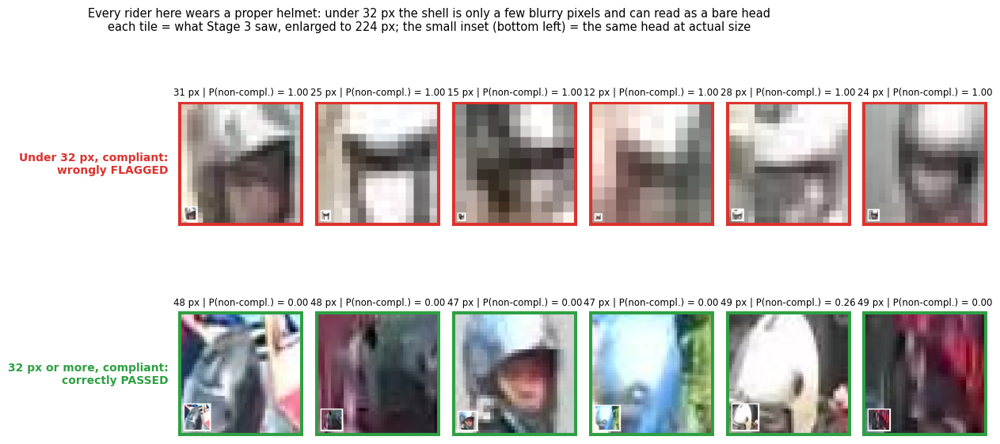

Saved to /content/drive/MyDrive/helmet_thesis_v2/results/figures : slide16_head_size_examples.png + slide16_<row>_<n>.png tiles


In [ ]:
# THESIS OUTPUT (reads saved results, no training)
# S16 SLIDE 16 EXAMPLES: why small heads cause false accusations (FINAL system, validation + test pooled, as in RQ2 C)
#   Row 1: COMPLIANT heads under 32 px that Stage 3 wrongly FLAGGED       (the 16 of 82)
#   Row 2: COMPLIANT heads of 32 px or more that Stage 3 correctly PASSED  (the 91 of 98)
#   Each tile = the crop exactly as Stage 3 saw it, enlarged to 224 px; the small inset = the same head at ACTUAL size.
# Head size = square root of the annotated head box's area (same as RQ2 C), split at 32 px (COCO "small").
# It also recomputes the slide's numbers, so you can check them: 19.5% (16/82), 7.1% (7/98), missed 23.1% vs 26.1%.
# RUN FIRST (fresh session): 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, 5.1   (no other slide cell needed)
# Output: {RES}/figures/slide16_head_size_examples.png (300 dpi) + slide16_<row>_<n>.png tiles.
# To show different examples, change START (which candidate each row starts from) and re-run (the search is cached).

N_PER_ROW = 6
START = {'small_flagged': 0, 'large_passed': 0}
FORCE_SEARCH = False

import numpy as np, cv2, matplotlib.pyplot as plt
from ultralytics import YOLO
assert 'run_pipeline' in globals() and 'TEST_FRAMES' in globals() and 'VAL_FRAMES' in globals(), \
    'run 0.1-0.3, 1.2, 3.1, 3.4a and 5.1 first'

# ---- 1. load the FINAL system (same as RQ2 B / H.1) ----
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json')
S1_SEL = load_json(f'{RES}/stage1_selected_rf8.json'); S2_SEL = load_json(f'{RES}/stage2_selected_rf3.json')
_s3 = load_json(f'{RES}/stage3_selected_rf6.json')
assert CFG3 and S1_SEL and S2_SEL and _s3, 'missing selection/config files in results/'
S3_SEL = {k: _s3[k] for k in ['name', 'weights', 'threshold', 'epoch']}
S3_SEL['threshold'] = CFG3['s3_threshold']; S3_NAME = S3_SEL['name']
HEAD_KPTS = [KEYPOINT_NAMES.index(CFG3['anchor'])]
HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(CFG3['head_off']), CFG3['head_scale'], CFG3['T']
DET, POSE, CLS = YOLO(S1_SEL['weights'], task='detect'), YOLO(S2_SEL['weights'], task='pose'), YOLO(S3_SEL['weights'], task='classify')
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
print(f"FINAL system: {S1_SEL['run']} + {S2_SEL['run']} + {S3_NAME} (thr {S3_SEL['threshold']}) | anchor {CFG3['anchor']} | T {T_GATE}")

# exemptions exactly as RQ2 A (without re-wrapping gt_heads twice)
_ex = {(e['frame'], e['gt_index']) for e in (load_json(f'{RES}/e2e_exempt_heads.json', []) or [])}
_gt_plain = globals().get('_gt_heads_orig', gt_heads)
def gt_heads_s16(fp, W, H):
    fb = frame_base(fp)
    return [(box, 'exempt' if (fb, b) in _ex else lab) for b, (box, lab) in enumerate(_gt_plain(fp, W, H))]

# ---- 2. every matched head on valid + test, with its size and Stage 3 decision (cached) ----
KEY = (S1_SEL['run'], S2_SEL['run'], S3_NAME, len(VAL_FRAMES), len(TEST_FRAMES))
if FORCE_SEARCH or '_S16' not in globals() or _S16.get('key') != KEY:
    rows = []
    for split, frames in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
        for n, fp in enumerate(frames):
            fr = cv2.imread(fp); H, W = fr.shape[:2]
            out = run_pipeline(fr); gt = gt_heads_s16(fp, W, H); pred = out['heads']
            for a, b in match_heads(pred, gt):
                (x1, y1, x2, y2), lab = gt[b]
                if lab == 'exempt': continue
                rows.append(dict(split=split, path=fp, pred=a, gt=lab, pred_label=pred[a]['label'],
                                 p_nc=pred[a]['p_nc'], box=pred[a]['box'], gt_box=(x1, y1, x2, y2),
                                 correct=pred[a]['label'] == lab,
                                 size_px=float(np.sqrt(max(x2 - x1, 0) * max(y2 - y1, 0)))))
            if (n + 1) % 100 == 0:
                print(f'{split}: {n + 1}/{len(frames)} frames')
    _S16 = dict(key=KEY, df=pd.DataFrame(rows))
SZ16 = _S16['df'].copy(); SZ16['small'] = SZ16.size_px < 32

# ---- 3. the slide's numbers, recomputed ----
def rate(d):
    return f'{(~d.correct).mean():.1%} ({int((~d.correct).sum())} of {len(d)})' if len(d) else 'n/a'
C, NCH = SZ16[SZ16['gt'] == 'compliant'], SZ16[SZ16['gt'] == 'non-compliant']
print('\nCompliant heads falsely flagged:  under 32 px', rate(C[C.small]), '| 32 px or more', rate(C[~C.small]))
print('Violations judged compliant:     under 32 px', rate(NCH[NCH.small]), '| 32 px or more', rate(NCH[~NCH.small]))
print('Slide 16 says: 19.5% (16 of 82) vs 7.1% (7 of 98); missed 23.1% vs 26.1%')

# ---- 4. pick the examples ----
small_flagged = C[C.small & ~C.correct].sort_values('p_nc', ascending=False)        # most confident mistakes first
large_passed  = C[~C.small & C.correct].assign(d=lambda d: (d.size_px - 48).abs()).sort_values('d')   # ordinary-size heads
ROWS = [('small_flagged', small_flagged, 'Under 32 px, compliant: wrongly FLAGGED', (220, 50, 47)),
        ('large_passed',  large_passed,  '32 px or more, compliant: correctly PASSED', (46, 160, 67))]

def tile(r, color):
    fr = cv2.imread(r['path']); H, W = fr.shape[:2]; rgb = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
    x1, y1, x2, y2 = r['box']; p = S3_PAD * (x2 - x1)                    # the crop exactly as Stage 3 saw it
    hc = rgb[int(max(0, y1 - p)):int(min(H, y2 + p)), int(max(0, x1 - p)):int(min(W, x2 + p))]
    big = cv2.resize(hc, (224, 224), interpolation=cv2.INTER_NEAREST)
    h0, w0 = hc.shape[:2]                                                  # inset: the same crop at ACTUAL size
    if h0 <= 90 and w0 <= 90:
        cv2.rectangle(big, (4, 224 - h0 - 8), (8 + w0, 220), (255, 255, 255), -1)
        big[224 - h0 - 6:218, 6:6 + w0] = hc
    return cv2.copyMakeBorder(big, 6, 6, 6, 6, cv2.BORDER_CONSTANT, value=color)

FIGD = f'{RES}/figures'; os.makedirs(FIGD, exist_ok=True)
fig, axs = plt.subplots(2, N_PER_ROW, figsize=(2.4 * N_PER_ROW, 6.4), squeeze=False)
for ax in axs.ravel(): ax.axis('off')
for r_i, (name, D, label, color) in enumerate(ROWS):
    pick = D.iloc[START[name]:START[name] + N_PER_ROW]
    for j, (_, r) in enumerate(pick.iterrows()):
        t = tile(r, color)
        axs[r_i, j].imshow(t)
        axs[r_i, j].set_title(f"{r['size_px']:.0f} px | P(non-compl.) = {r['p_nc']:.2f}", fontsize=8.5)
        cv2.imwrite(f'{FIGD}/slide16_{name}_{j}.png', cv2.cvtColor(t, cv2.COLOR_RGB2BGR))
    axs[r_i, 0].text(-0.08, 0.5, label.replace(': ', ':\n'), transform=axs[r_i, 0].transAxes, ha='right', va='center',
                     fontsize=10, fontweight='bold', color=np.array(color) / 255)
    if len(pick) < N_PER_ROW:
        print(f'{name}: only {len(pick)} examples available')
plt.suptitle('Every rider here wears a proper helmet: under 32 px the shell is only a few blurry pixels and can read as a bare head\n'
             'each tile = what Stage 3 saw, enlarged to 224 px; the small inset (bottom left) = the same head at actual size',
             fontsize=10.5)
plt.tight_layout(rect=(0.12, 0, 1, 1))
plt.savefig(f'{FIGD}/slide16_head_size_examples.png', dpi=300, bbox_inches='tight', facecolor='white'); plt.show()
print('Saved to', FIGD, ': slide16_head_size_examples.png + slide16_<row>_<n>.png tiles')

## B.4 YOLOv8 vs YOLO11 per stage (CMP)
Panel revision, final defense (2 Oct 2026).
The panel asked that **both** backbones' results be shown, not only the selected one. These cells draw a v8-vs-v11 comparison for each stage from the results already on Drive. **Nothing is retrained.**

| Cell | What it makes | Needs | GPU |
|---|---|---|---|
| **CMP.0** | Loads the saved test tables + training histories, sets the style | 0.1–0.3 only | no |
| **CMP.1** | Stage 1: test P / R / F1 (95% CI) + mAP, and training curves of both detectors | CMP.0 | no |
| **CMP.2** | Stage 2: box/pose mAP, rider-count accuracy (1 / 2 / 3+), training curves | CMP.0 | no |
| **CMP.3** | Stage 3: P / R / F1 / accuracy, mean ± SD over 3 seeds for each balancing ratio, every seed shown | CMP.0 | no |
| **CMP.4** | Summary figure (one headline metric per stage) + `v8_vs_v11_summary.csv` for Chapter 5 / the conceptual framework | CMP.1–3 | no |
| **CMP.5** *(optional)* | Same-test-set PR curves overlaid + model size / speed of both backbones | 1.2, 3.1, D.1, F.1, FIG.0 | yes |

**Run order (fresh runtime):** 0.1, 0.2, 0.3 → CMP.0 → CMP.1 → CMP.2 → CMP.3 → CMP.4. For CMP.5 also run 1.2, 3.1, D.1, F.1, FIG.0 first.

Everything is saved to `MyDrive/helmet_thesis_v2/results/figures/v8_vs_v11/` (300 dpi PNG). YOLOv8 is always **blue**, YOLO11 always **orange**, and the model the pipeline uses is marked **★**.

In [ ]:
# THESIS OUTPUT (panel revision, no training)
# CMP.0 Load every saved v8/v11 result (no GPU, no training). Needs 0.1-0.3 (ROOT, RES, RUNS, load_json).
import re, matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
matplotlib.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 9, 'axes.titlesize': 9.5,
                            'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                            'axes.axisbelow': True, 'grid.color': '#e6e6e6', 'grid.linewidth': 0.6,
                            'legend.frameon': False})
FIGC = f'{RES}/figures/v8_vs_v11'; os.makedirs(FIGC, exist_ok=True)

COL   = {'YOLOv8s': '#2a78d6', 'YOLO11s': '#eb6834'}      # same colours in every figure
ARCHS = ['YOLOv8s', 'YOLO11s']
def arch_of(s):
    s = str(s).lower()
    return 'YOLO11s' if ('yolo11' in s or 'yolov11' in s) else 'YOLOv8s' if 'yolov8' in s else s

def parse_ci(s):
    """'0.892 [0.876, 0.907] (n=371)' -> (0.892, 0.876, 0.907, 371). Plain numbers -> (x, nan, nan, None)."""
    if isinstance(s, (int, float, np.floating)) and not pd.isna(s):
        return float(s), np.nan, np.nan, None
    nums = re.findall(r'-?\d+\.\d+|-?\d+', str(s))
    n = re.search(r'n=(\d+)', str(s))
    if len(nums) < 3:
        return np.nan, np.nan, np.nan, None
    return float(nums[0]), float(nums[1]), float(nums[2]), (int(n.group(1)) if n else None)

def history(run):
    f = f'{RUNS}/{run}/results.csv'
    if not os.path.exists(f):
        print('  no results.csv for', run); return None
    d = pd.read_csv(f); d.columns = d.columns.str.strip(); return d

def save(fig, name):
    fig.savefig(f'{FIGC}/{name}', bbox_inches='tight', facecolor='white'); plt.show()
    print('saved', name)

def bar_label(ax, rects, vals, fmt='{:.3f}', dy=0.012):
    dys = np.broadcast_to(np.nan_to_num(np.asarray(dy, float)), (len(rects),))   # dy may be one value or one per bar
    for r, v, d in zip(rects, vals, dys):
        if not pd.isna(v):
            ax.text(r.get_x() + r.get_width() / 2, r.get_height() + d, fmt.format(v),
                    ha='center', va='bottom', fontsize=7, color='#333333')

# ---- Stage 1: C.3 table + selection ----
S1T = pd.read_csv(f'{RES}/stage1_test_rf8.csv'); S1T['A'] = S1T.run.map(arch_of)
SEL1 = load_json(f'{RES}/stage1_selected_rf8.json'); S1_PICK = arch_of(SEL1['run'])
# ---- Stage 2: D.3 table + selection ----
S2T = pd.read_csv(f'{RES}/stage2_test_rf3.csv'); S2T['A'] = S2T.run.map(arch_of)
SEL2 = load_json(f'{RES}/stage2_selected_rf3.json'); S2_PICK = arch_of(SEL2['run'])
# ---- Stage 3: F.3 table (18 runs = 3 ratios x 2 backbones x 3 seeds) + selection ----
S3T = pd.read_csv(f'{RES}/stage3_test_rf6.csv')
S3T = S3T[S3T.test == ('own footage' if (S3T.test == 'own footage').any() else 'all')].copy()
S3T['A'] = S3T.arch.map(arch_of)
SEL3 = load_json(f'{RES}/stage3_selected_rf6.json'); S3_PICK = arch_of(SEL3['name'])
S3_RATIO = SEL3.get('chosen_ratio', 'r15')
RATIO_LABEL = {'r15': 'Balancing 1.5 : 1', 'r30': 'Balancing 3.0 : 1', 'none': 'No balancing'}
RATIO_LABEL[S3_RATIO] += ' (chosen)'

with pd.option_context('display.width', 220):
    print('Stage 1 runs:', S1T[['run', 'A', 'test_F1', 'test_mAP50', 'test_mAP50_95']].to_string(index=False), sep='\n')
    print('\nStage 2 runs:', S2T[['run', 'A', 'box_mAP50-95', 'pose_mAP50-95_custom_sigma']].to_string(index=False), sep='\n')
    print(f'\nStage 3: {len(S3T)} test rows ({S3T.run.nunique()} runs)')
print(f'\nSelected for the pipeline: Stage 1 {S1_PICK} | Stage 2 {S2_PICK} | Stage 3 {S3_PICK} ({SEL3["name"]})')
assert set(S1T.A) >= set(ARCHS) and set(S2T.A) >= set(ARCHS) and set(S3T.A) >= set(ARCHS), 'a v8 or v11 run is missing'

Stage 1 runs:
                       run       A              test_F1  test_mAP50  test_mAP50_95
stage1_yolo11s-rf8_1280_s0 YOLO11s 0.895 [0.880, 0.910]      0.9566         0.6650
stage1_yolov8s-rf8_1280_s0 YOLOv8s 0.892 [0.876, 0.907]      0.9583         0.6658

Stage 2 runs:
                  run       A  box_mAP50-95  pose_mAP50-95_custom_sigma
stage2_yolo11s_rf3_s0 YOLO11s        0.3871                      0.2958
stage2_yolov8s_rf3_s0 YOLOv8s        0.3881                      0.3035

Stage 3: 18 test rows (18 runs)

Selected for the pipeline: Stage 1 YOLO11s | Stage 2 YOLOv8s | Stage 3 YOLO11s (stage3_yolo11s_rf6r15_s2)


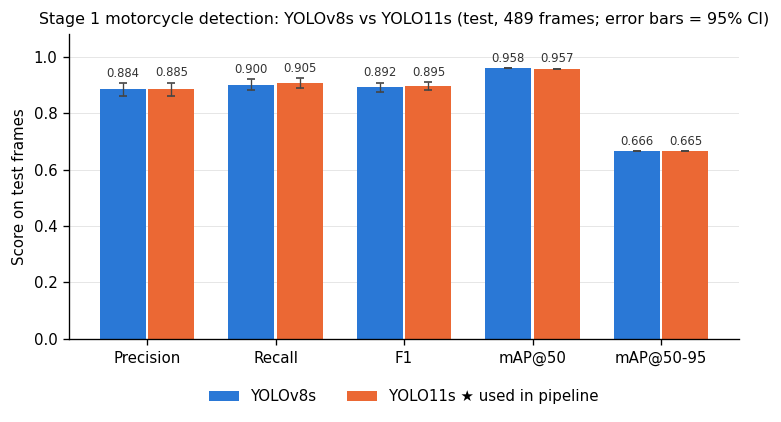

saved cmp_stage1_test_metrics.png
YOLOv8s: stage1_yolov8s-rf8_1280_s0, best epoch 17, val mAP50-95 0.669
YOLO11s: stage1_yolo11s-rf8_1280_s0, best epoch 27, val mAP50-95 0.675


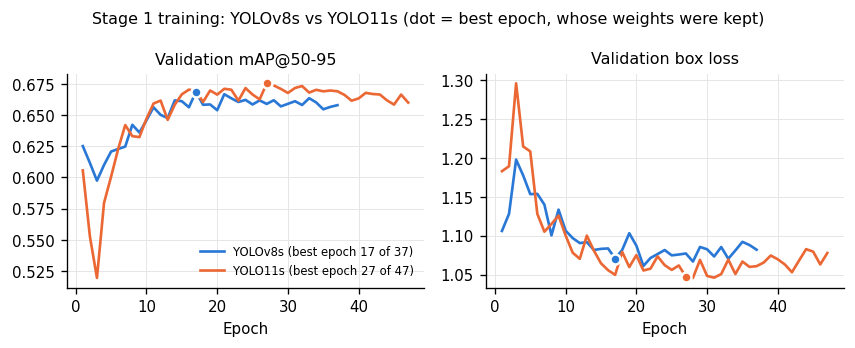

saved cmp_stage1_training_curves.png


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# CMP.1 Stage 1 (motorcycle detection): YOLOv8s vs YOLO11s on the SAME 489 test frames
# (a) test metrics: P / R / F1 at the confidence chosen on VALID, with 95% bootstrap CIs; mAP from Ultralytics
# (b) training curves of both runs (validation mAP50-95 and validation box loss), best epoch marked
M1 = [('Precision', 'test_P'), ('Recall', 'test_R'), ('F1', 'test_F1'), ('mAP@50', 'test_mAP50'), ('mAP@50-95', 'test_mAP50_95')]
fig, ax = plt.subplots(figsize=(7.2, 3.3))
x, w = np.arange(len(M1)), 0.38
for k, a in enumerate(ARCHS):
    r = S1T[S1T.A == a].iloc[0]
    vals = [parse_ci(r[c]) for _, c in M1]
    p = np.array([v[0] for v in vals]); lo = np.array([v[1] for v in vals]); hi = np.array([v[2] for v in vals])
    err = np.vstack([np.where(np.isnan(lo), 0, p - lo), np.where(np.isnan(hi), 0, hi - p)])
    rects = ax.bar(x + (k - 0.5) * w, p, w * 0.94, color=COL[a], label=a + (' ★ used in pipeline' if a == S1_PICK else ''),
                   yerr=err, error_kw=dict(ecolor='#444444', elinewidth=0.8, capsize=2.5))
    bar_label(ax, rects, p, dy=np.maximum(err[1], 0) + 0.012)
ax.set_xticks(x, [m for m, _ in M1]); ax.set_ylim(0, 1.08); ax.set_ylabel('Score on test frames')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('Stage 1 motorcycle detection: YOLOv8s vs YOLO11s (test, 489 frames; error bars = 95% CI)')
save(fig, 'cmp_stage1_test_metrics.png')

def best_epoch_det(d):        # Ultralytics fitness for detection = 0.1 mAP50 + 0.9 mAP50-95
    f = 0.1 * d['metrics/mAP50(B)'] + 0.9 * d['metrics/mAP50-95(B)']
    return int(d.epoch[f.idxmax()])

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
for a in ARCHS:
    run = S1T[S1T.A == a].run.iloc[0]; d = history(run)
    if d is None: continue
    be = best_epoch_det(d)
    for ax, col in zip(axes, ['metrics/mAP50-95(B)', 'val/box_loss']):
        ax.plot(d.epoch, d[col], lw=1.6, color=COL[a], label=f'{a} (best epoch {be} of {int(d.epoch.max())})')
        ax.plot(be, d.loc[d.epoch == be, col].iloc[0], 'o', ms=6, color=COL[a], mec='white', mew=1.5, zorder=3)
    print(f'{a}: {run}, best epoch {be}, val mAP50-95 {d.loc[d.epoch == be, "metrics/mAP50-95(B)"].iloc[0]:.3f}')
axes[0].set_title('Validation mAP@50-95'); axes[1].set_title('Validation box loss')
for ax in axes: ax.set_xlabel('Epoch')
axes[0].legend(fontsize=7, loc='lower right')
fig.suptitle('Stage 1 training: YOLOv8s vs YOLO11s (dot = best epoch, whose weights were kept)', fontsize=9.5)
fig.tight_layout(); save(fig, 'cmp_stage1_training_curves.png')

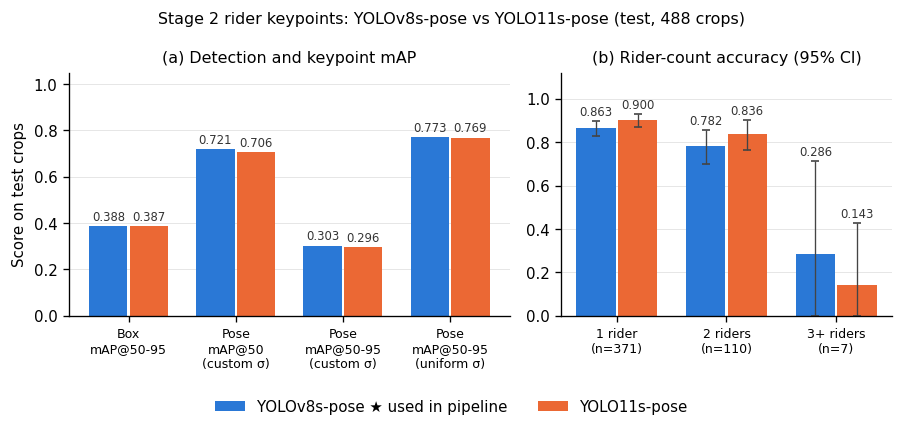

saved cmp_stage2_test_metrics.png
YOLOv8s: val balanced count acc 0.670 (selection criterion) | conf 0.3 | NMS IoU 0.5
YOLO11s: val balanced count acc 0.643 (selection criterion) | conf 0.3 | NMS IoU 0.5
YOLOv8s: stage2_yolov8s_rf3_s0, best epoch 25
YOLO11s: stage2_yolo11s_rf3_s0, best epoch 31


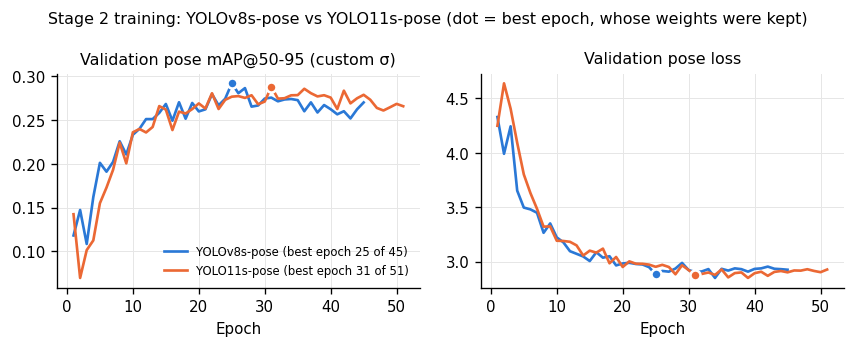

saved cmp_stage2_training_curves.png


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# CMP.2 Stage 2 (rider keypoints): YOLOv8s-pose vs YOLO11s-pose on the SAME 488 test crops
# (a) box / pose mAP (custom OKS sigmas = the thesis setting; uniform sigmas shown for reference)
# (b) rider-count accuracy per bucket (1 / 2 / 3+ riders) at the NMS IoU + confidence tuned on VALID, 95% CIs
# (c) training curves of both runs
M2 = [('Box\nmAP@50-95', 'box_mAP50-95'), ('Pose\nmAP@50\n(custom σ)', 'pose_mAP50_custom_sigma'),
      ('Pose\nmAP@50-95\n(custom σ)', 'pose_mAP50-95_custom_sigma'), ('Pose\nmAP@50-95\n(uniform σ)', 'pose_mAP50-95_uniform_sigma')]
BUCK = [('1 rider', 'test_count_acc_1'), ('2 riders', 'test_count_acc_2'), ('3+ riders', 'test_count_acc_3+')]
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.4), gridspec_kw={'width_ratios': [4, 3]})
w = 0.38
ax = axes[0]; x = np.arange(len(M2))
for k, a in enumerate(ARCHS):
    r = S2T[S2T.A == a].iloc[0]; p = [float(r[c]) for _, c in M2]
    rects = ax.bar(x + (k - 0.5) * w, p, w * 0.94, color=COL[a], label=a + ('-pose ★ used in pipeline' if a == S2_PICK else '-pose'))
    bar_label(ax, rects, p)
ax.set_xticks(x, [m for m, _ in M2], fontsize=7.5); ax.set_ylim(0, 1.05); ax.set_ylabel('Score on test crops')
ax.set_title('(a) Detection and keypoint mAP'); ax.grid(axis='x', visible=False)

ax = axes[1]; x = np.arange(len(BUCK)); nlab = {}
for k, a in enumerate(ARCHS):
    r = S2T[S2T.A == a].iloc[0]; vals = [parse_ci(r[c]) if c in r else (np.nan,) * 3 + (None,) for _, c in BUCK]
    p = np.array([v[0] for v in vals]); lo = np.array([v[1] for v in vals]); hi = np.array([v[2] for v in vals])
    for (b, _), v in zip(BUCK, vals): nlab[b] = v[3]
    err = np.vstack([p - lo, hi - p])
    rects = ax.bar(x + (k - 0.5) * w, p, w * 0.94, color=COL[a], yerr=err,
                   error_kw=dict(ecolor='#444444', elinewidth=0.8, capsize=2.5))
    bar_label(ax, rects, p, dy=err[1] + 0.012)
ax.set_xticks(x, [f'{b}\n(n={nlab[b]})' for b, _ in BUCK], fontsize=7.5); ax.set_ylim(0, 1.12)
ax.set_title('(b) Rider-count accuracy (95% CI)'); ax.grid(axis='x', visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Stage 2 rider keypoints: YOLOv8s-pose vs YOLO11s-pose (test, 488 crops)', fontsize=9.5)
fig.tight_layout(rect=(0, 0.06, 1, 1)); save(fig, 'cmp_stage2_test_metrics.png')
for a in ARCHS:
    r = S2T[S2T.A == a].iloc[0]
    print(f"{a}: val balanced count acc {r['val_count_acc_bal']:.3f} (selection criterion) | conf {r['conf']} | NMS IoU {r['nms_iou']}")

def best_epoch_pose(d):       # Ultralytics fitness for pose = box fitness + pose fitness
    fit = lambda s: 0.1 * d[f'metrics/mAP50({s})'] + 0.9 * d[f'metrics/mAP50-95({s})']
    return int(d.epoch[(fit('B') + fit('P')).idxmax()])

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
for a in ARCHS:
    run = S2T[S2T.A == a].run.iloc[0]; d = history(run)
    if d is None: continue
    be = best_epoch_pose(d)
    for ax, col in zip(axes, ['metrics/mAP50-95(P)', 'val/pose_loss']):
        ax.plot(d.epoch, d[col], lw=1.6, color=COL[a], label=f'{a}-pose (best epoch {be} of {int(d.epoch.max())})')
        ax.plot(be, d.loc[d.epoch == be, col].iloc[0], 'o', ms=6, color=COL[a], mec='white', mew=1.5, zorder=3)
    print(f'{a}: {run}, best epoch {be}')
axes[0].set_title('Validation pose mAP@50-95 (custom σ)'); axes[1].set_title('Validation pose loss')
for ax in axes: ax.set_xlabel('Epoch')
axes[0].legend(fontsize=7, loc='lower right')
fig.suptitle('Stage 2 training: YOLOv8s-pose vs YOLO11s-pose (dot = best epoch, whose weights were kept)', fontsize=9.5)
fig.tight_layout(); save(fig, 'cmp_stage2_training_curves.png')

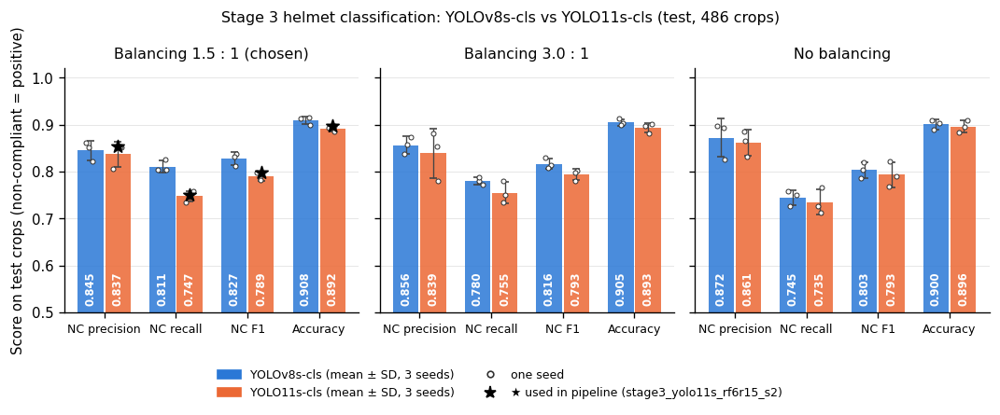

saved cmp_stage3_test_metrics.png
                   P             R            F1           acc       
                mean    std   mean    std   mean    std   mean    std
ratio A                                                              
none  YOLO11s  0.861  0.027  0.735  0.027  0.793  0.027  0.896  0.013
      YOLOv8s  0.872  0.040  0.745  0.016  0.803  0.017  0.900  0.010
r15   YOLO11s  0.837  0.026  0.747  0.012  0.789  0.009  0.892  0.006
      YOLOv8s  0.845  0.021  0.811  0.013  0.827  0.014  0.908  0.008
r30   YOLO11s  0.839  0.052  0.755  0.023  0.793  0.012  0.893  0.011
      YOLOv8s  0.856  0.018  0.780  0.008  0.816  0.011  0.905  0.007

NC F1 difference YOLO11s - YOLOv8s, seed by seed:
  Balancing 1.5 : 1 (chosen) -0.024 -0.057 -0.033 | mean -0.038
  Balancing 3.0 : 1    -0.011 -0.009 -0.048 | mean -0.023
  No balancing         -0.036 +0.004 +0.001 | mean -0.010


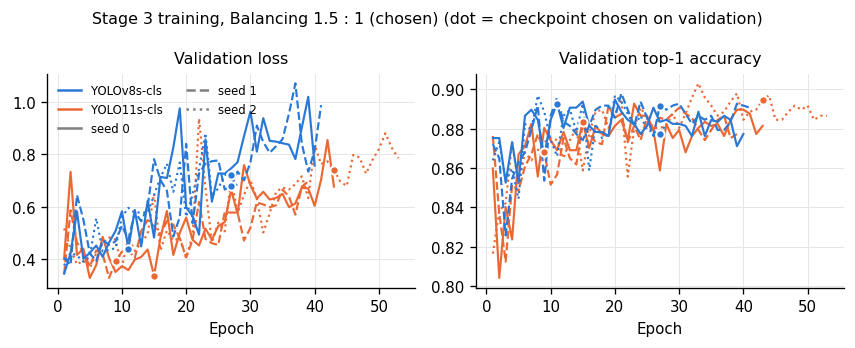

saved cmp_stage3_training_curves.png


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# CMP.3 Stage 3 (helmet classifier): YOLOv8s-cls vs YOLO11s-cls on the SAME 486 test crops
# 18 runs = 3 balancing ratios x 2 backbones x 3 seeds, each at its own checkpoint + threshold chosen on VALID.
# Bars = mean over the 3 seeds, error bars = SD, dots = the individual seeds, ★ = the classifier the pipeline uses.
M3 = [('NC precision', 'P'), ('NC recall', 'R'), ('NC F1', 'F1'), ('Accuracy', 'acc')]
ORDER = [S3_RATIO] + [r for r in ['r15', 'r30', 'none'] if r != S3_RATIO and r in set(S3T.ratio)]
fig, axes = plt.subplots(1, len(ORDER), figsize=(3.0 * len(ORDER), 3.3), sharey=True)
w, x = 0.38, np.arange(len(M3))
rng = np.random.default_rng(0)
for ax, rt in zip(np.atleast_1d(axes), ORDER):
    for k, a in enumerate(ARCHS):
        d = S3T[(S3T.ratio == rt) & (S3T.A == a)]
        mean = d[[c for _, c in M3]].mean().values; sd = d[[c for _, c in M3]].std().values
        xs = x + (k - 0.5) * w
        rects = ax.bar(xs, mean, w * 0.94, color=COL[a], alpha=0.85, yerr=sd,
                       error_kw=dict(ecolor='#444444', elinewidth=0.8, capsize=2.5))
        for j, (_, c) in enumerate(M3):
            ax.scatter(xs[j] + rng.uniform(-0.07, 0.07, len(d)), d[c], s=9, color='white', edgecolor='#333333', lw=0.6, zorder=3)
        sel = d[d.run == SEL3['name']]
        if len(sel):
            for j, (_, c) in enumerate(M3):
                ax.scatter(xs[j], sel[c].iloc[0], marker='*', s=70, color='black', zorder=4)
        for rc, v in zip(rects, mean):           # value written inside the bar, clear of the seed dots and ★
            ax.text(rc.get_x() + rc.get_width() / 2, 0.515, f'{v:.3f}', ha='center', va='bottom', rotation=90,
                    fontsize=7, color='white', fontweight='bold')
    ax.set_xticks(x, [m for m, _ in M3], fontsize=7.5); ax.set_ylim(0.5, 1.02)
    ax.set_title(RATIO_LABEL[rt]); ax.grid(axis='x', visible=False)
np.atleast_1d(axes)[0].set_ylabel('Score on test crops (non-compliant = positive)')
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[a]) for a in ARCHS] + [
    Line2D([], [], ls='', marker='o', mfc='white', mec='#333333', ms=4),
    Line2D([], [], ls='', marker='*', color='black', ms=8)]
fig.legend(handles, ['YOLOv8s-cls (mean ± SD, 3 seeds)', 'YOLO11s-cls (mean ± SD, 3 seeds)', 'one seed',
                     f'★ used in pipeline ({SEL3["name"]})'], loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.1), fontsize=7.5)
fig.suptitle('Stage 3 helmet classification: YOLOv8s-cls vs YOLO11s-cls (test, 486 crops)', fontsize=9.5)
fig.tight_layout(rect=(0, 0.06, 1, 1)); save(fig, 'cmp_stage3_test_metrics.png')

S3_SUM = (S3T.groupby(['ratio', 'A'])[['P', 'R', 'F1', 'acc']].agg(['mean', 'std']).round(3))
print(S3_SUM.to_string())

# Paired comparison on the SAME seeds (v11 - v8), per ratio: shows how consistent the gap is
print('\nNC F1 difference YOLO11s - YOLOv8s, seed by seed:')
for rt in ORDER:
    piv = S3T[S3T.ratio == rt].pivot_table(index='seed', columns='A', values='F1')
    diff = (piv['YOLO11s'] - piv['YOLOv8s'])
    print(f'  {RATIO_LABEL[rt]:20s}', ' '.join(f'{v:+.3f}' for v in diff), f'| mean {diff.mean():+.3f}')

# Training curves at the chosen ratio: validation loss and top-1 accuracy, every seed
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9))
STY = {0: '-', 1: '--', 2: ':'}
for _, r in S3T[S3T.ratio == S3_RATIO].sort_values(['A', 'seed']).iterrows():
    d = history(r.run)
    if d is None: continue
    for ax, col in zip(axes, ['val/loss', 'metrics/accuracy_top1']):
        ax.plot(d.epoch, d[col], lw=1.3, ls=STY.get(int(r.seed), '-'), color=COL[r.A])
        ep = int(r.epoch)                      # checkpoint chosen on VALID by F.3 (1-based epoch)
        if ep in set(d.epoch):
            ax.plot(ep, d.loc[d.epoch == ep, col].iloc[0], 'o', ms=5, color=COL[r.A], mec='white', mew=1.2, zorder=3)
axes[0].set_title('Validation loss'); axes[1].set_title('Validation top-1 accuracy')
for ax in axes: ax.set_xlabel('Epoch')
axes[0].legend([Line2D([], [], color=COL[a]) for a in ARCHS] + [Line2D([], [], color='grey', ls=STY[s]) for s in STY],
               ['YOLOv8s-cls', 'YOLO11s-cls', 'seed 0', 'seed 1', 'seed 2'], fontsize=7, ncol=2)
fig.suptitle(f'Stage 3 training, {RATIO_LABEL[S3_RATIO]} (dot = checkpoint chosen on validation)', fontsize=9.5)
fig.tight_layout(); save(fig, 'cmp_stage3_training_curves.png')

                         stage backbone                        run                               selection_rule  val_score                                                  headline  value     P     R  mAP50  mAP50_95  used_in_pipeline  pose_mAP50_95  acc_1  acc_2  acc_3plus    sd   acc  best_seed_test_F1
 Stage 1: motorcycle detection  YOLOv8s stage1_yolov8s-rf8_1280_s0                                validation F1      0.885                                                   test F1  0.892 0.884 0.900  0.958     0.666             False            NaN    NaN    NaN        NaN   NaN   NaN                NaN
 Stage 1: motorcycle detection  YOLO11s stage1_yolo11s-rf8_1280_s0                                validation F1      0.891                                                   test F1  0.895 0.885 0.905  0.957     0.665              True            NaN    NaN    NaN        NaN   NaN   NaN                NaN
      Stage 2: rider keypoints  YOLOv8s      stage2_yolov8s_rf3_s0   validation ri

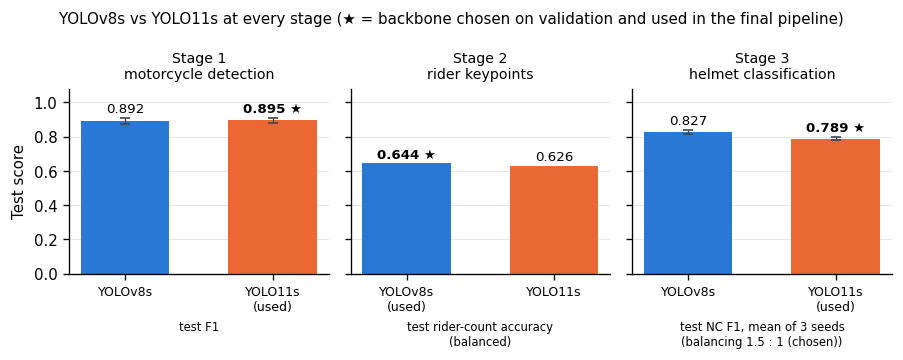

saved cmp_summary_all_stages.png

Suggested captions:
OK cmp_summary_all_stages.png
     Test performance of YOLOv8s and YOLO11s at each stage; ★ marks the backbone selected on validation for the final pipeline.
OK cmp_stage1_test_metrics.png
     Stage 1 motorcycle detection on the test split: precision, recall and F1 (95% bootstrap CIs) and mAP for YOLOv8s and YOLO11s.
OK cmp_stage1_training_curves.png
     Stage 1 validation mAP@50-95 and box loss per epoch for YOLOv8s and YOLO11s.
OK cmp_stage2_test_metrics.png
     Stage 2 rider keypoint estimation on the test split: box and pose mAP, and rider-count accuracy by number of riders (95% CIs), for YOLOv8s-pose and YOLO11s-pose.
OK cmp_stage2_training_curves.png
     Stage 2 validation pose mAP@50-95 and pose loss per epoch for YOLOv8s-pose and YOLO11s-pose.
OK cmp_stage3_test_metrics.png
     Stage 3 helmet classification on the test crops for each balancing ratio: mean ± SD over three seeds for YOLOv8s-cls and YOLO11s-cls; dots are i

In [ ]:
# THESIS OUTPUT (panel revision, no training)
# CMP.4 Summary: one headline metric per stage, both backbones side by side + one table for Chapter 5 / the framework
#   Stage 1 = test F1 (95% CI) | Stage 2 = test rider-count accuracy, balanced over 1 / 2 / 3+ | Stage 3 = test NC F1, mean ± SD of 3 seeds
rows = []
for a in ARCHS:
    r = S1T[S1T.A == a].iloc[0]; f, lo, hi, _ = parse_ci(r.test_F1)
    rows.append(dict(stage='Stage 1: motorcycle detection', backbone=a, run=r.run, selection_rule='validation F1',
                     val_score=float(r.val_F1), headline='test F1', value=f, lo=lo, hi=hi,
                     P=parse_ci(r.test_P)[0], R=parse_ci(r.test_R)[0], mAP50=float(r.test_mAP50), mAP50_95=float(r.test_mAP50_95),
                     used_in_pipeline=a == S1_PICK))
for a in ARCHS:
    r = S2T[S2T.A == a].iloc[0]
    acc = [parse_ci(r[c])[0] for _, c in BUCK if c in r and not pd.isna(parse_ci(r[c])[0])]
    rows.append(dict(stage='Stage 2: rider keypoints', backbone=a, run=r.run, selection_rule='validation rider-count accuracy (balanced)',
                     val_score=float(r.val_count_acc_bal), headline='test rider-count accuracy (balanced)', value=float(np.mean(acc)),
                     lo=np.nan, hi=np.nan, mAP50_95=float(r['box_mAP50-95']), pose_mAP50_95=float(r['pose_mAP50-95_custom_sigma']),
                     acc_1=acc[0], acc_2=acc[1], acc_3plus=acc[2] if len(acc) > 2 else np.nan, used_in_pipeline=a == S2_PICK))
ALLRUNS = SEL3.get('all_runs', {})
for a in ARCHS:
    d = S3T[(S3T.ratio == S3_RATIO) & (S3T.A == a)]
    cand = {k: v for k, v in ALLRUNS.items() if v.get('ratio') == S3_RATIO and arch_of(k) == a}
    best = max(cand, key=lambda k: (cand[k]['meets_precision_target'], cand[k]['R'], cand[k]['F1'])) if cand else None
    rows.append(dict(stage='Stage 3: helmet classification', backbone=a, run=best or '', selection_rule='validation NC recall at NC precision >= 0.85',
                     val_score=cand[best]['R'] if best else np.nan, headline=f'test NC F1, mean of 3 seeds\n({RATIO_LABEL[S3_RATIO].lower()})',
                     value=d.F1.mean(), lo=d.F1.mean() - d.F1.std(), hi=d.F1.mean() + d.F1.std(), sd=d.F1.std(),
                     P=d.P.mean(), R=d.R.mean(), acc=d.acc.mean(),
                     best_seed_test_F1=float(d[d.run == best].F1.iloc[0]) if best in set(d.run) else np.nan,
                     used_in_pipeline=a == S3_PICK))
SUMMARY = pd.DataFrame(rows)
SUMMARY.round(4).to_csv(f'{RES}/v8_vs_v11_summary.csv', index=False)
with pd.option_context('display.width', 250, 'display.max_columns', 30):
    print(SUMMARY.drop(columns=['lo', 'hi']).round(3).to_string(index=False))
print(f'\nsaved {RES}/v8_vs_v11_summary.csv')

fig, axes = plt.subplots(1, 3, figsize=(7.6, 3.0), sharey=True)
for ax, (st, d) in zip(axes, SUMMARY.groupby('stage', sort=False)):
    for k, (_, r) in enumerate(d.iterrows()):
        err = None if pd.isna(r.lo) else [[r.value - r.lo], [r.hi - r.value]]
        ax.bar(k, r.value, 0.6, color=COL[r.backbone], yerr=err, error_kw=dict(ecolor='#444444', elinewidth=0.8, capsize=3))
        ax.text(k, (r.hi if not pd.isna(r.hi) else r.value) + 0.015, f'{r.value:.3f}' + (' ★' if r.used_in_pipeline else ''),
                ha='center', va='bottom', fontsize=8, fontweight='bold' if r.used_in_pipeline else 'normal')
    ax.set_xticks([0, 1], [b + ('\n(used)' if u else '') for b, u in zip(d.backbone, d.used_in_pipeline)], fontsize=7.5)
    ax.set_title(st.replace(': ', '\n'), fontsize=8.5); ax.grid(axis='x', visible=False)
    ax.set_xlabel(d.headline.iloc[0].replace(' (', '\n(', 1) if '\n' not in d.headline.iloc[0] else d.headline.iloc[0], fontsize=7)
axes[0].set_ylim(0, 1.08); axes[0].set_ylabel('Test score')
fig.suptitle('YOLOv8s vs YOLO11s at every stage (★ = backbone chosen on validation and used in the final pipeline)', fontsize=9)
fig.tight_layout(); save(fig, 'cmp_summary_all_stages.png')

CAPTIONS_CMP = {
 'cmp_summary_all_stages.png': 'Test performance of YOLOv8s and YOLO11s at each stage; ★ marks the backbone selected on validation for the final pipeline.',
 'cmp_stage1_test_metrics.png': 'Stage 1 motorcycle detection on the test split: precision, recall and F1 (95% bootstrap CIs) and mAP for YOLOv8s and YOLO11s.',
 'cmp_stage1_training_curves.png': 'Stage 1 validation mAP@50-95 and box loss per epoch for YOLOv8s and YOLO11s.',
 'cmp_stage2_test_metrics.png': 'Stage 2 rider keypoint estimation on the test split: box and pose mAP, and rider-count accuracy by number of riders (95% CIs), for YOLOv8s-pose and YOLO11s-pose.',
 'cmp_stage2_training_curves.png': 'Stage 2 validation pose mAP@50-95 and pose loss per epoch for YOLOv8s-pose and YOLO11s-pose.',
 'cmp_stage3_test_metrics.png': 'Stage 3 helmet classification on the test crops for each balancing ratio: mean ± SD over three seeds for YOLOv8s-cls and YOLO11s-cls; dots are individual seeds.',
 'cmp_stage3_training_curves.png': 'Stage 3 validation loss and top-1 accuracy per epoch at the chosen balancing ratio, all seeds of both backbones.'}
print('\nSuggested captions:')
for f, c in CAPTIONS_CMP.items():
    print(f"{'OK ' if os.path.exists(f'{FIGC}/{f}') else '-- '}{f}\n     {c}")

## B.5 YOLOv8 vs YOLO11 example images (IMG)
Qualitative examples for every stage, on the same test images.
Each figure shows the same test image three times: **ground truth | YOLOv8s | YOLO11s**, each model at its own operating point chosen on validation (the same settings as the tables). Nothing is retrained.

The cells first run both models on the **whole** test split, count where they disagree, and then pick examples automatically: half where YOLOv8s did better and half where YOLO11s did better, so the figures are not cherry-picked toward one model. To show specific images instead, put their file names in `MANUAL` (IMG.0).

| Cell | Images | Colours |
|---|---|---|
| **IMG.1** Stage 1 | full test frames (489) | green = correct motorcycle box, red = false detection, yellow = missed motorcycle |
| **IMG.2** Stage 2 | test rider crops (488) | rider boxes + 5 keypoints; title says the predicted rider count vs the true count |
| **IMG.3** Stage 3 | test head crops (486) | each crop with the true label and both models' non-compliant probability (✓ / ✗) |

**Run order (fresh runtime, GPU):** 0.1, 0.2, 0.3, 1.2, 3.1, D.1, F.1, FIG.0 → CMP.0 → IMG.0 → IMG.1 → IMG.2 → IMG.3 (≈ 5–10 min). Figures go to `results/figures/v8_vs_v11/examples/`.

In [ ]:
# THESIS OUTPUT (panel revision, no training)
# IMG.0 Shared settings + drawing helpers for the side-by-side example figures (needs CMP.0 and FIG.0)
from ultralytics import YOLO
assert 'S1T' in globals() and 'SEL3' in globals(), 'run CMP.0 first'
assert 'S1_FIG_DATA' in globals() and 'S2R_DS' in globals() and 'S3_ITEMS' in globals(), 'run FIG.0 (after 1.2, 3.1, D.1, F.1) first'
FIGI = f'{FIGC}/examples'; os.makedirs(FIGI, exist_ok=True)

N_EXAMPLES = 4                  # rows per Stage 1 / Stage 2 figure (half "v8 better", half "v11 better")
N_CROPS    = 12                 # head crops in the Stage 3 figure
MANUAL = {'stage1': [], 'stage2': [], 'stage3': []}   # optional: image FILE NAMES to show instead of the automatic pick

C_TP, C_FP, C_FN, C_GT = (40, 167, 69), (220, 53, 69), (255, 193, 7), (255, 193, 7)   # RGB
C_MODEL = {a: tuple(int(COL[a][i:i + 2], 16) for i in (1, 3, 5)) for a in ARCHS}     # same blue / orange as CMP
KPT_NAMES = globals().get('KEYPOINT_NAMES') or ['neck', 'shoulder_l', 'head', 'shoulder_r', 'pelvis']
SKELETON = [(a, b) for a, b in [('head', 'neck'), ('neck', 'shoulder_l'), ('neck', 'shoulder_r'), ('neck', 'pelvis')]
            if a in KPT_NAMES and b in KPT_NAMES]

def rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

def lw_for(img):
    return max(2, int(round(max(img.shape[:2]) / 350)))

def draw_box(img, b, color, lw, text=None):
    x1, y1, x2, y2 = map(int, b)
    cv2.rectangle(img, (x1, y1), (x2, y2), color, lw)
    if text:
        fs = lw / 3.5
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, max(1, lw // 2))
        cv2.rectangle(img, (x1, max(0, y1 - th - 2 * lw)), (x1 + tw + lw, y1), color, -1)
        cv2.putText(img, text, (x1 + lw // 2, max(th, y1 - lw)), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), max(1, lw // 2), cv2.LINE_AA)

def match(pred, scores, gt, thr=0.5):
    """Greedy (highest score first) IoU matching, same rule as greedy_tp. Returns TP flag per prediction and hit flag per GT."""
    pred = np.asarray(pred, float).reshape(-1, 4); gt = np.asarray(gt, float).reshape(-1, 4)
    tp, hit = np.zeros(len(pred), bool), np.zeros(len(gt), bool)
    ious = iou_matrix(pred, gt)
    for i in np.argsort(-np.asarray(scores, float)):
        cand = np.where(~hit & (ious[i] >= thr))[0] if len(gt) else []
        if len(cand):
            j = cand[np.argmax(ious[i, cand])]; hit[j] = True; tp[i] = True
    return tp, hit

def run_model(model, paths, batch=16, **kw):
    """Predict without keeping images in memory. Returns one dict of numpy arrays per image."""
    out = []
    for i in range(0, len(paths), batch):
        for r in model.predict(paths[i:i + batch], verbose=False, **kw):
            d = dict(boxes=r.boxes.xyxy.cpu().numpy() if r.boxes is not None else np.zeros((0, 4)),
                     scores=r.boxes.conf.cpu().numpy() if r.boxes is not None else np.zeros(0))
            if getattr(r, 'keypoints', None) is not None and len(d['boxes']):
                d['kxy'] = r.keypoints.xy.cpu().numpy()
                d['kc'] = r.keypoints.conf.cpu().numpy() if r.keypoints.conf is not None else np.ones(d['kxy'].shape[:2])
            if getattr(r, 'probs', None) is not None:
                d['probs'] = r.probs.data.cpu().numpy()
            out.append(d)
    return out

def pick(score_v8, score_v11, names, n, manual=()):
    """Indices to show. score = errors (lower is better). Half where v8 is better, half where v11 is better, biggest gaps first."""
    names = list(names)
    if manual:
        idx = [names.index(m) for m in manual if m in names]
        missing = [m for m in manual if m not in names]
        if missing: print('MANUAL names not found:', missing)
        return idx
    d = np.asarray(score_v8, float) - np.asarray(score_v11, float)          # > 0: v11 made fewer errors
    v11_better = [i for i in np.argsort(-d) if d[i] > 0][:n // 2 + n % 2]
    v8_better  = [i for i in np.argsort(d) if d[i] < 0][:n // 2]
    chosen = v11_better + v8_better
    if len(chosen) < n:                                                     # not enough disagreements: add agreements
        chosen += [i for i in np.argsort(-(np.asarray(score_v8) + np.asarray(score_v11))) if i not in chosen][:n - len(chosen)]
    return chosen

def tally(err8, err11, unit):
    err8, err11 = np.asarray(err8), np.asarray(err11)
    b8, b11 = int((err8 < err11).sum()), int((err11 < err8).sum())
    print(f'{len(err8)} test {unit}: YOLOv8s better on {b8}, YOLO11s better on {b11}, same result on {len(err8) - b8 - b11}')
    return dict(n=len(err8), v8_better=b8, v11_better=b11, same=len(err8) - b8 - b11)

TALLY = {}
print('Examples go to', FIGI)

Examples go to /content/drive/MyDrive/helmet_thesis_v2/results/figures/v8_vs_v11/examples


YOLOv8s: conf 0.43 | TP 886  FP 116  missed 98 over 489 frames
YOLO11s: conf 0.41 | TP 891  FP 116  missed 93 over 489 frames
489 test frames: YOLOv8s better on 46, YOLO11s better on 56, same result on 387


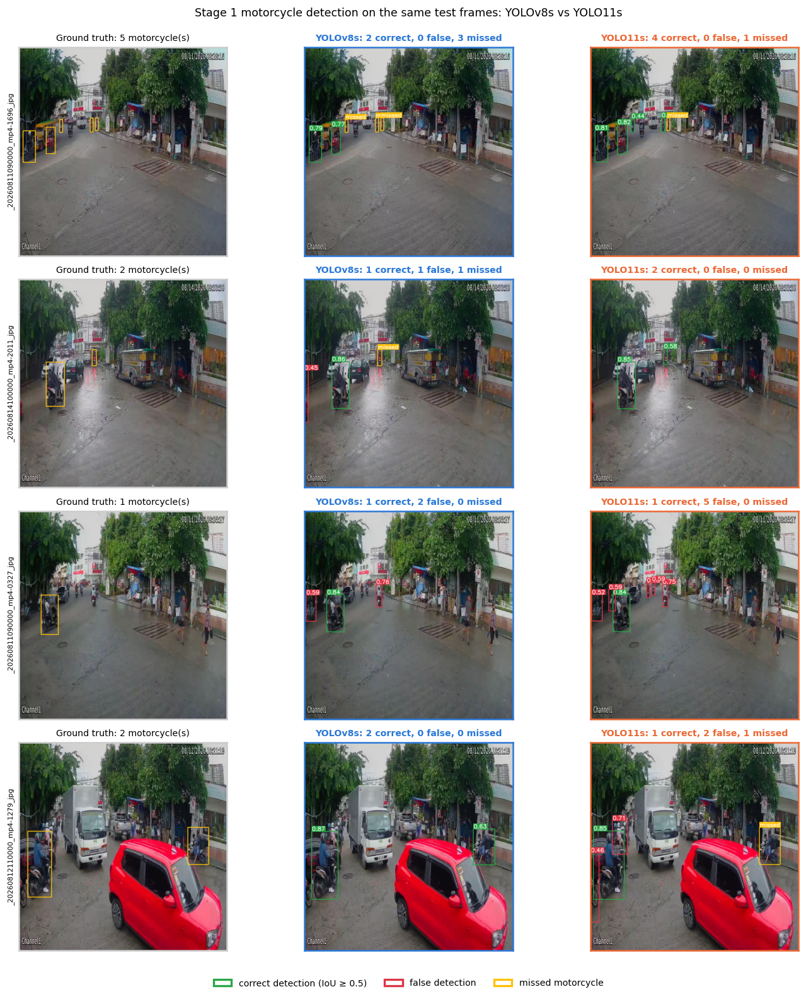

saved examples/img_stage1_v8_vs_v11.png


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# IMG.1 Stage 1: motorcycle detection on the SAME test frames, ground truth | YOLOv8s | YOLO11s
# Each detector runs at its own confidence chosen on VALID (C.3); a box is correct at IoU >= 0.5 (same rule as the tables).
S1_IMGS = list_images(f'{D1}/test/images')
gt1 = []
for p in S1_IMGS:
    H, W = cv2.imread(p).shape[:2]
    gt1.append(np.array([yolo_to_xyxy(r, W, H) for r in read_labels(label_for(p))]).reshape(-1, 4))

P1, ERR1, CNT1 = {}, {}, {}
for a in ARCHS:
    r = S1T[S1T.A == a].iloc[0]
    m = YOLO(f'{RUNS}/{r.run}/weights/best.pt', task='detect')
    P1[a] = run_model(m, S1_IMGS, imgsz=int(r.imgsz), conf=float(r.conf_from_val))
    CNT1[a] = []
    for pr, g in zip(P1[a], gt1):
        tp, hit = match(pr['boxes'], pr['scores'], g)
        CNT1[a].append((int(tp.sum()), int((~tp).sum()), int((~hit).sum())))       # TP, FP, missed
    ERR1[a] = np.array([fp + fn for _, fp, fn in CNT1[a]])
    tot = np.array(CNT1[a]).sum(0)
    print(f'{a}: conf {r.conf_from_val} | TP {tot[0]}  FP {tot[1]}  missed {tot[2]} over {len(S1_IMGS)} frames')
TALLY['Stage 1'] = tally(ERR1['YOLOv8s'], ERR1['YOLO11s'], 'frames')

def stage1_panel(i, a=None):
    img = rgb(S1_IMGS[i]); lw = lw_for(img)
    if a is None:
        for b in gt1[i]: draw_box(img, b, C_GT, lw)
        return img, f'Ground truth: {len(gt1[i])} motorcycle(s)'
    pr = P1[a][i]; tp, hit = match(pr['boxes'], pr['scores'], gt1[i])
    for b, ok, s in zip(pr['boxes'], tp, pr['scores']):
        draw_box(img, b, C_TP if ok else C_FP, lw, f'{s:.2f}')
    for b in gt1[i][~hit]:
        draw_box(img, b, C_FN, lw, 'missed')
    t, f, n = CNT1[a][i]
    return img, f'{a}: {t} correct, {f} false, {n} missed'

rows = pick(ERR1['YOLOv8s'], ERR1['YOLO11s'], [os.path.basename(p) for p in S1_IMGS], N_EXAMPLES, MANUAL['stage1'])
fig, axes = plt.subplots(len(rows), 3, figsize=(12, 3.3 * len(rows)), squeeze=False)
for row, i in zip(axes, rows):
    for ax, a in zip(row, [None] + ARCHS):
        img, title = stage1_panel(i, a)
        ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(title, fontsize=8.5, color='black' if a is None else COL[a], fontweight='bold' if a else 'normal')
        for s in ax.spines.values(): s.set_visible(True); s.set_color('#cccccc' if a is None else COL[a]); s.set_linewidth(1.5)
    row[0].set_ylabel(os.path.basename(S1_IMGS[i]).split('.rf.')[0][-28:], fontsize=6.5)
fig.legend([plt.Rectangle((0, 0), 1, 1, fc='none', ec=np.array(c) / 255, lw=2) for c in [C_TP, C_FP, C_FN]],
           ['correct detection (IoU ≥ 0.5)', 'false detection', 'missed motorcycle'], loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.01), fontsize=8.5)
fig.suptitle('Stage 1 motorcycle detection on the same test frames: YOLOv8s vs YOLO11s', fontsize=10.5)
fig.tight_layout(rect=(0, 0.025, 1, 0.985)); save(fig, 'examples/img_stage1_v8_vs_v11.png')

YOLOv8s-pose: conf 0.3, NMS IoU 0.5 | rider count correct on 83.6% of 488 crops
YOLO11s-pose: conf 0.3, NMS IoU 0.5 | rider count correct on 87.5% of 488 crops
488 test crops: YOLOv8s better on 26, YOLO11s better on 43, same result on 419


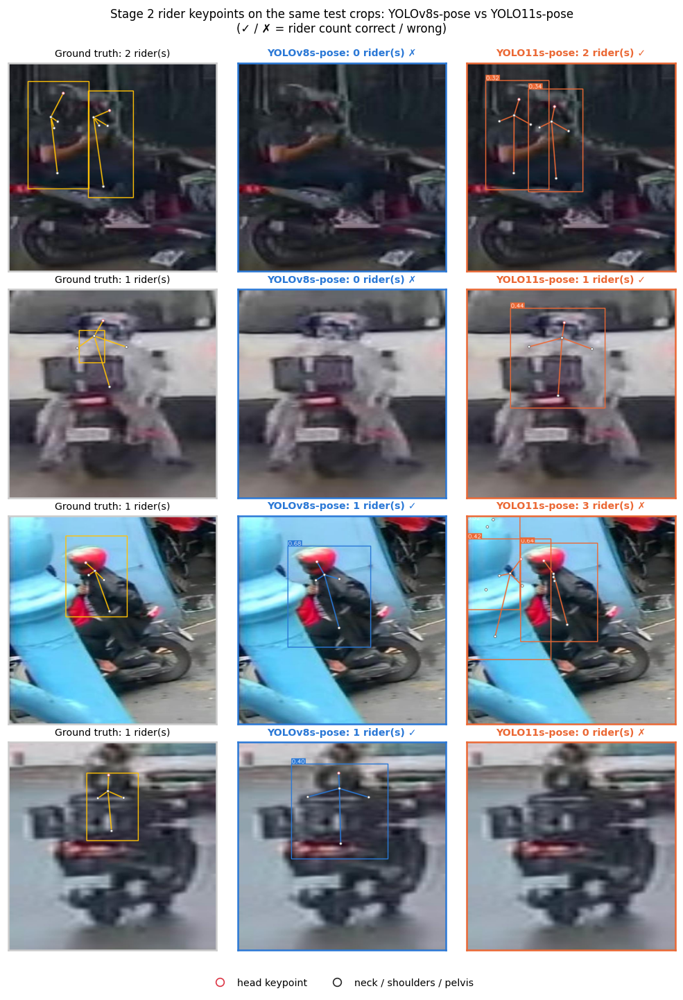

saved examples/img_stage2_v8_vs_v11.png


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# IMG.2 Stage 2: rider boxes + keypoints on the SAME test crops, ground truth | YOLOv8s-pose | YOLO11s-pose
# Each pose model runs at its own NMS IoU + confidence tuned on VALID (D.3). The rider COUNT is what Stage 2 must get right.
S2_IMGS = list_images(f'{S2R_DS}/test/images')
def gt_pose(p):
    H, W = cv2.imread(p).shape[:2]; boxes, kpts = [], []
    for r in read_labels(label_for(p)):
        boxes.append(yolo_to_xyxy(r, W, H))
        k = np.array(list(map(float, r[5:]))).reshape(-1, 3 if (len(r) - 5) % 3 == 0 else 2)
        kpts.append(np.c_[k[:, 0] * W, k[:, 1] * H, k[:, 2] if k.shape[1] == 3 else np.ones(len(k))])
    return np.array(boxes).reshape(-1, 4), kpts
gt2 = [gt_pose(p) for p in S2_IMGS]
n_gt2 = np.array([len(b) for b, _ in gt2])

P2, ERR2 = {}, {}
for a in ARCHS:
    r = S2T[S2T.A == a].iloc[0]
    m = YOLO(f'{RUNS}/{r.run}/weights/best.pt', task='pose')
    P2[a] = run_model(m, S2_IMGS, imgsz=640, conf=float(r.conf), iou=float(r.nms_iou))
    n_pred = np.array([len(d['boxes']) for d in P2[a]])
    ERR2[a] = np.abs(n_pred - n_gt2)                         # 0 = rider count correct
    print(f'{a}-pose: conf {r.conf}, NMS IoU {r.nms_iou} | rider count correct on {(ERR2[a] == 0).mean():.1%} of {len(S2_IMGS)} crops')
TALLY['Stage 2'] = tally(ERR2['YOLOv8s'], ERR2['YOLO11s'], 'crops')

def draw_kpts(img, kxy, kc, color, lw, min_conf=0.5):
    pt = {n: (int(x), int(y)) for n, (x, y), c in zip(KPT_NAMES, kxy, kc) if c >= min_conf and x > 0 and y > 0}
    for a_, b_ in SKELETON:
        if a_ in pt and b_ in pt: cv2.line(img, pt[a_], pt[b_], color, lw, cv2.LINE_AA)
    for n, p_ in pt.items():
        cv2.circle(img, p_, lw + 2, (255, 255, 255), -1, cv2.LINE_AA)
        cv2.circle(img, p_, lw + 2, (220, 53, 69) if n == 'head' else (40, 40, 40), max(1, lw // 2), cv2.LINE_AA)

def stage2_panel(i, a=None):
    img = rgb(S2_IMGS[i]); lw = lw_for(img)
    if a is None:
        boxes, kpts = gt2[i]
        for b, k in zip(boxes, kpts):
            draw_box(img, b, C_GT, lw); draw_kpts(img, k[:, :2], k[:, 2], C_GT, lw, min_conf=0.5)
        return img, f'Ground truth: {len(boxes)} rider(s)'
    d = P2[a][i]
    for j, b in enumerate(d['boxes']):
        draw_box(img, b, C_MODEL[a], lw, f"{d['scores'][j]:.2f}")
        if 'kxy' in d: draw_kpts(img, d['kxy'][j], d['kc'][j], C_MODEL[a], lw)
    n = len(d['boxes']); ok = n == n_gt2[i]
    return img, f"{a}-pose: {n} rider(s) {'✓' if ok else '✗'}"

rows = pick(ERR2['YOLOv8s'] + 0.01 * (n_gt2 < 2), ERR2['YOLO11s'] + 0.01 * (n_gt2 < 2),      # prefer 2+ rider crops
            [os.path.basename(p) for p in S2_IMGS], N_EXAMPLES, MANUAL['stage2'])
fig, axes = plt.subplots(len(rows), 3, figsize=(8.4, 3.0 * len(rows)), squeeze=False)
for row, i in zip(axes, rows):
    for ax, a in zip(row, [None] + ARCHS):
        img, title = stage2_panel(i, a)
        ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ok = a is not None and ERR2[a][i] == 0
        ax.set_title(title, fontsize=8.5, color='black' if a is None else (COL[a]), fontweight='bold' if a else 'normal')
        for s in ax.spines.values(): s.set_visible(True); s.set_color('#cccccc' if a is None else COL[a]); s.set_linewidth(1.5)
fig.legend([Line2D([], [], ls='', marker='o', mfc='white', mec='#dc3545', ms=7), Line2D([], [], ls='', marker='o', mfc='white', mec='#282828', ms=7)],
           ['head keypoint', 'neck / shoulders / pelvis'], loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.01), fontsize=8.5)
fig.suptitle('Stage 2 rider keypoints on the same test crops: YOLOv8s-pose vs YOLO11s-pose\n(✓ / ✗ = rider count correct / wrong)', fontsize=10)
fig.tight_layout(rect=(0, 0.025, 1, 0.985)); save(fig, 'examples/img_stage2_v8_vs_v11.png')

YOLOv8s-cls: stage3_yolov8s_rf6r15_s1 (epoch 27, threshold 0.04) | correct 91.4% | violators caught 109/132, false accusations 19
YOLO11s-cls: stage3_yolo11s_rf6r15_s2 (epoch 43, threshold 0.05) | correct 89.7% | violators caught 99/132, false accusations 17
486 test head crops: YOLOv8s better on 25, YOLO11s better on 17, same result on 444
Disagreements: only YOLOv8s right on 25 crops, only YOLO11s right on 17 crops -> showing 6 + 6


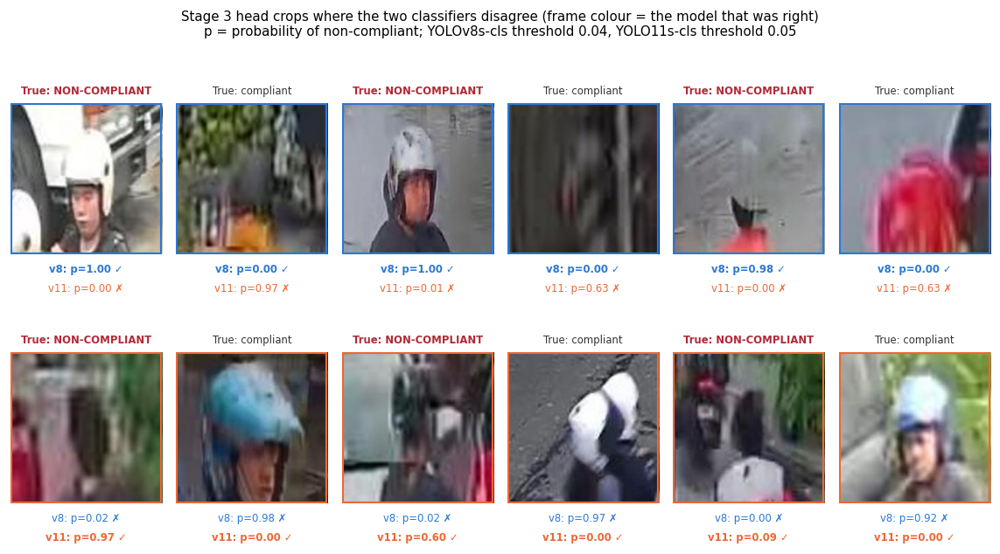

saved examples/img_stage3_v8_vs_v11.png

Per-image comparison on the same test images (fewer errors = better):
           n  v8_better  v11_better  same
Stage 1  489         46          56   387
Stage 2  488         26          43   419
Stage 3  486         25          17   444


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# IMG.3 Stage 3: head crops on which YOLOv8s-cls and YOLO11s-cls DISAGREE (same test crops)
# For each backbone: the run chosen on VALID at the chosen balancing ratio, at its own threshold (same rule as F.3 / CMP.4).
cand3 = {}
for k, v in SEL3['all_runs'].items():
    if v.get('ratio') == S3_RATIO:
        cand3.setdefault(arch_of(k), []).append(k)
RUN3 = {a: max(cand3[a], key=lambda k: (SEL3['all_runs'][k]['meets_precision_target'], SEL3['all_runs'][k]['R'], SEL3['all_runs'][k]['F1']))
        for a in ARCHS}
paths3 = [q for q, _ in S3_ITEMS]; y3 = np.array([c == NC_NAME for _, c in S3_ITEMS])
PNC, PRED3 = {}, {}
for a in ARCHS:
    s = SEL3['all_runs'][RUN3[a]]; m = YOLO(s['weights'], task='classify')
    j = [k for k, v in m.names.items() if v == NC_NAME][0]
    PNC[a] = np.array([d['probs'][j] for d in run_model(m, paths3, batch=128, imgsz=224)])
    PRED3[a] = PNC[a] >= s['threshold']
    tp, fp, fn = (PRED3[a] & y3).sum(), (PRED3[a] & ~y3).sum(), (~PRED3[a] & y3).sum()
    print(f"{a}-cls: {RUN3[a]} (epoch {s['epoch']}, threshold {s['threshold']:.2f}) | correct {np.mean(PRED3[a] == y3):.1%} | "
          f'violators caught {tp}/{y3.sum()}, false accusations {fp}')
ERR3 = {a: (PRED3[a] != y3).astype(int) for a in ARCHS}
TALLY['Stage 3'] = tally(ERR3['YOLOv8s'], ERR3['YOLO11s'], 'head crops')

if MANUAL['stage3']:
    sel = pick(ERR3['YOLOv8s'], ERR3['YOLO11s'], [os.path.basename(p) for p in paths3], N_CROPS, MANUAL['stage3'])
else:                                                  # biggest probability gap first, half each way, violators and compliant mixed
    gap = np.abs(PNC['YOLOv8s'] - PNC['YOLO11s'])
    only8  = [i for i in np.argsort(-gap) if ERR3['YOLOv8s'][i] == 0 and ERR3['YOLO11s'][i] == 1]
    only11 = [i for i in np.argsort(-gap) if ERR3['YOLO11s'][i] == 0 and ERR3['YOLOv8s'][i] == 1]
    def mix(lst, n):                                   # alternate non-compliant and compliant crops
        nc = [i for i in lst if y3[i]]; c = [i for i in lst if not y3[i]]; out = []
        while len(out) < n and (nc or c):
            if nc: out.append(nc.pop(0))
            if c and len(out) < n: out.append(c.pop(0))
        return out
    sel = mix(only8, N_CROPS // 2) + mix(only11, N_CROPS - N_CROPS // 2)
    print(f'Disagreements: only YOLOv8s right on {len(only8)} crops, only YOLO11s right on {len(only11)} crops '
          f'-> showing {min(len(only8), N_CROPS // 2)} + {min(len(only11), N_CROPS - N_CROPS // 2)}')

SHORT = {'YOLOv8s': 'v8', 'YOLO11s': 'v11'}
ncol = 6; nrow = max(1, math.ceil(len(sel) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(1.6 * ncol, 2.7 * nrow), squeeze=False)
for ax in axes.ravel(): ax.axis('off')
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(cv2.resize(rgb(paths3[i]), (224, 224), interpolation=cv2.INTER_CUBIC))
    ax.set_title(f"True: {'NON-COMPLIANT' if y3[i] else 'compliant'}", fontsize=7, color='#b02a37' if y3[i] else '#333333',
                 fontweight='bold' if y3[i] else 'normal')
    for k, a in enumerate(ARCHS):
        ok = ERR3[a][i] == 0
        ax.text(0.5, -0.06 - 0.13 * k, f"{SHORT[a]}: p={PNC[a][i]:.2f} {'✓' if ok else '✗'}",
                transform=ax.transAxes, ha='center', va='top', fontsize=7, color=COL[a], fontweight='bold' if ok else 'normal')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, fill=False, lw=2.5,
                               ec=COL['YOLOv8s'] if ERR3['YOLOv8s'][i] == 0 else COL['YOLO11s']))
fig.suptitle(f'Stage 3 head crops where the two classifiers disagree (frame colour = the model that was right)\n'
             f'p = probability of non-compliant; YOLOv8s-cls threshold {SEL3["all_runs"][RUN3["YOLOv8s"]]["threshold"]:.2f}, '
             f'YOLO11s-cls threshold {SEL3["all_runs"][RUN3["YOLO11s"]]["threshold"]:.2f}', fontsize=9)
fig.tight_layout(h_pad=3.0); save(fig, 'examples/img_stage3_v8_vs_v11.png')

T = pd.DataFrame(TALLY).T[['n', 'v8_better', 'v11_better', 'same']]
T.to_csv(f'{RES}/v8_vs_v11_per_image.csv')
print('\nPer-image comparison on the same test images (fewer errors = better):'); print(T.to_string())

## B.6 Every backbone combination end to end (E2E)
All eight combinations: 8-8-8, 8-8-11, …, 11-11-11.
The panel asked for the end-to-end result of **every backbone combination**, not only the final system. A combination is written **Stage 1 – Stage 2 – Stage 3**, e.g. `8-11-11` = YOLOv8s detector + YOLO11s-pose + YOLO11s-cls. 2 × 2 × 2 = **8 systems**, all scored with the same `evaluate_e2e` rules (5.3) on the same frames. Nothing is retrained.

**What changes between combinations, and what stays fixed**
| | per combination | same for all 8 |
|---|---|---|
| Stage 1 | that backbone's run + its confidence chosen on VALID (C.3) | |
| Stage 2 | that backbone's run + its NMS IoU / confidence tuned on VALID (D.3) | |
| Head box | offset + scale **re-calibrated for each Stage 1 + Stage 2 pair** (same procedure and frames as E.1) | |
| Stage 3 | that backbone's classifier chosen on VALID at the chosen balancing ratio (F.3) | |
| Anchor, gate T, Stage 3 threshold | only if `TUNE = True` (G.1 rule on validation) | default: the final system's values (`e2e_final_config_s123.json`) |

With the default `TUNE = False` the only difference between two systems is the backbones, and the `11-8-11` row must reproduce the thesis final system exactly (test, all frames: TP 21, false accusations 15, F1 0.382). E2E.1 checks this.

| Cell | What it does | Time (L4) |
|---|---|---|
| **E2E.0** | builds the 8 configurations, frame sets, head-box calibration per Stage 1 + Stage 2 pair | ~5 min |
| **E2E.1** | scores all 8 on valid-unseen, test-all, test-unseen → `e2e_combos.csv` | ~10 min (`TUNE=True`: +15 min) |
| **E2E.2** | figures: F1 / recall / labelled precision with 95% CIs, flag outcomes + missed violators by stage | no GPU |
| **E2E.3** | figure: effect of switching ONE stage from v8 to v11 (the other two held fixed) | no GPU |
| **E2E.4** | the same test frames through 4 chosen systems, side by side (auto-picked where they disagree) | ~1 min |

**Run order (fresh runtime, GPU):** 0.1, 0.2, 0.3, 1.2, 3.1, 3.4a, D.1, F.1, 5.1, 5.3, then CMP.0, then E2E.0 → E2E.1 → E2E.2 → E2E.3 → E2E.4.
Figures go to `results/figures/v8_vs_v11/e2e/`.

In [ ]:
# THESIS OUTPUT (panel revision, no training)
# E2E.0 Build the 8 backbone combinations, the frame sets and the head-box calibration per Stage 1 + Stage 2 pair
import itertools, contextlib, io
from ultralytics import YOLO
assert 'run_pipeline' in globals() and 'evaluate_e2e' in globals(), 'run 5.1 and 5.3 first'
assert 'S1T' in globals() and 'SEL3' in globals(), 'run CMP.0 first'
assert all(n in globals() for n in ['S1_TRAIN_FRAMES', 'S2_TRAIN_FRAMES', 'S3_TRAIN_FRAMES']), 'run D.1 and F.1 first'
TUNE = False                     # True = tune anchor x Stage 3 threshold per combination on validation (G.1 rule)
FIGE = f'{FIGC}/e2e'; os.makedirs(FIGE, exist_ok=True)
CFG3 = load_json(f'{RES}/e2e_final_config_s123.json'); assert CFG3, 'e2e_final_config_s123.json missing'
if 'NKPT' not in globals(): NKPT, NDIM = 5, 3
SHORT = {'YOLOv8s': '8', 'YOLO11s': '11'}

def rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
def draw_box(img, b, color, lw, text=None):
    x1, y1, x2, y2 = map(int, b)
    cv2.rectangle(img, (x1, y1), (x2, y2), color, lw)
    if text:
        fs = lw / 3.5
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, fs, max(1, lw // 2))
        cv2.rectangle(img, (x1, max(0, y1 - th - 2 * lw)), (x1 + tw + lw, y1), color, -1)
        cv2.putText(img, text, (x1 + lw // 2, max(th, y1 - lw)), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), max(1, lw // 2), cv2.LINE_AA)

# ---- the models of each stage (validation-selected settings) ----
S1_OF, S2_OF, S3_OF = {}, {}, {}
for a in ARCHS:
    r = S1T[S1T.A == a].iloc[0]
    S1_OF[a] = dict(SEL1) if arch_of(SEL1['run']) == a else dict(run=r.run, weights=f'{RUNS}/{r.run}/weights/best.pt',
                                                                  imgsz=int(r.imgsz), conf=float(r.conf_from_val))
    r = S2T[S2T.A == a].iloc[0]
    S2_OF[a] = dict(SEL2) if arch_of(SEL2['run']) == a else dict(run=r.run, weights=f'{RUNS}/{r.run}/weights/best.pt',
                                                                  conf=float(r.conf), iou=float(r.nms_iou))
    cand = {k: v for k, v in SEL3['all_runs'].items() if v.get('ratio') == S3_RATIO and arch_of(k) == a}
    k = max(cand, key=lambda k: (cand[k]['meets_precision_target'], cand[k]['R'], cand[k]['F1']))
    S3_OF[a] = dict(name=k, weights=cand[k]['weights'], threshold=float(cand[k]['threshold']), epoch=cand[k]['epoch'])
for st, d in [('Stage 1', S1_OF), ('Stage 2', S2_OF), ('Stage 3', S3_OF)]:
    for a in ARCHS:
        w = d[a]['weights']; print(f"{st} {a}: {d[a].get('run', d[a].get('name'))} {'OK' if os.path.exists(w) else 'MISSING ' + w}")
FINAL_KEY = (arch_of(CFG3['stage1']), arch_of(CFG3['stage2']), arch_of(CFG3['stage3']))
print('Final system =', '-'.join(SHORT[a] for a in FINAL_KEY), f"| anchor {CFG3['anchor']}, T {CFG3['T']}, Stage 3 threshold {CFG3['s3_threshold']}")

# ---- point run_pipeline at one combination ----
_M = {}
def _mdl(path, task):
    if path not in _M: _M[path] = YOLO(path, task=task)
    return _M[path]
def set_combo(c):
    global DET, POSE, CLS, NC_IDX, S1_SEL, S2_SEL, S3_SEL, S3_NAME, HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE, T_GATE
    S1_SEL, S2_SEL = c['s1'], c['s2']
    S3_SEL = dict(c['s3']); S3_SEL['threshold'] = float(c['thr']); S3_NAME = c['s3']['name']
    DET, POSE, CLS = _mdl(S1_SEL['weights'], 'detect'), _mdl(S2_SEL['weights'], 'pose'), _mdl(S3_SEL['weights'], 'classify')
    NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
    HEAD_KPTS = [KEYPOINT_NAMES.index(c['anchor'])]
    HEAD_OFF, HEAD_BOX_SCALE, T_GATE = tuple(c['off']), float(c['scale']), float(c['T'])

# ---- frame sets (same definitions as E.1 / G.1) ----
SEEN12 = S1_TRAIN_FRAMES | S2_TRAIN_FRAMES
SEEN3 = SEEN12 | S3_TRAIN_FRAMES
FSETS = {'valid_unseen': [p for p in VAL_FRAMES if frame_base(p) not in SEEN3],
         'test_all': list(TEST_FRAMES),
         'test_unseen': [p for p in TEST_FRAMES if frame_base(p) not in SEEN3]}
VU12 = [p for p in VAL_FRAMES if frame_base(p) not in SEEN12]          # E.1 calibration frames
for k, v in FSETS.items(): print(f'{k}: {len(v)} frames')
print(f'calibration (E.1 frames, valid unseen by Stage 1 + 2): {len(VU12)} frames')

# ---- head-box calibration for each Stage 1 + Stage 2 pair (E.1 procedure) ----
def calibrate(s1, s2, anchors):
    set_combo(dict(s1=s1, s2=s2, s3=S3_OF[FINAL_KEY[2]], anchor=anchors[0], T=CFG3['T'], thr=0.5, off=(0, 0), scale=0.6))
    global HEAD_KPTS, HEAD_OFF
    res = {}
    for anchor in anchors:
        HEAD_KPTS, HEAD_OFF = [KEYPOINT_NAMES.index(anchor)], (0.0, 0.0)
        dx, dy, sc = [], [], []
        for fp in VU12:
            frame = cv2.imread(fp); H, W = frame.shape[:2]
            out = run_pipeline(frame)
            for box, lab in gt_heads(fp, W, H):
                gx, gy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
                cands = [h for h in out['heads'] if h['rider_box'][0] <= gx <= h['rider_box'][2] and h['rider_box'][1] <= gy <= h['rider_box'][3]]
                if not cands: continue
                h = min(cands, key=lambda h: (h['kpt'][0] - gx) ** 2 + (h['kpt'][1] - gy) ** 2)
                rw = max(h['rider_w'], 1e-6)
                dx.append((gx - h['kpt'][0]) / rw); dy.append((gy - h['kpt'][1]) / rw); sc.append((box[2] - box[0]) / rw)
        res[anchor] = dict(off=[float(np.median(dx)), float(np.median(dy))], scale=float(np.median(sc)), n=len(sc))
    return res

ANCHORS = ['head', 'neck'] if TUNE else [CFG3['anchor']]
CALIB = {}
for a1, a2 in itertools.product(ARCHS, ARCHS):
    CALIB[(a1, a2)] = calibrate(S1_OF[a1], S2_OF[a2], ANCHORS)
    for an, v in CALIB[(a1, a2)].items():
        print(f"S1 {a1:7s} + S2 {a2:7s} | {an}: offset ({v['off'][0]:+.3f}, {v['off'][1]:+.3f}) scale {v['scale']:.3f} (n={v['n']})")
fk = CALIB[FINAL_KEY[:2]][CFG3['anchor']]
print(f"Check, final pair re-calibrated vs saved: offset ({fk['off'][0]:+.3f}, {fk['off'][1]:+.3f}) / "
      f"({CFG3['head_off'][0]:+.3f}, {CFG3['head_off'][1]:+.3f}); scale {fk['scale']:.3f} / {CFG3['head_scale']:.3f}")
CALIB[FINAL_KEY[:2]][CFG3['anchor']].update(off=list(CFG3['head_off']), scale=CFG3['head_scale'])   # final system = exactly the thesis run
save_json({'-'.join(SHORT[a] for a in k): v for k, v in CALIB.items()}, f'{RES}/e2e_combos_head_calib.json')

# ---- the 8 combinations ----
COMBOS = []
for key in itertools.product(ARCHS, ARCHS, ARCHS):
    COMBOS.append(dict(key=key, label='-'.join(SHORT[a] for a in key), final=key == FINAL_KEY,
                       s1=S1_OF[key[0]], s2=S2_OF[key[1]], s3=S3_OF[key[2]], anchor=CFG3['anchor'], T=float(CFG3['T']),
                       thr=float(CFG3['s3_threshold']), off=CALIB[key[:2]][CFG3['anchor']]['off'],
                       scale=CALIB[key[:2]][CFG3['anchor']]['scale']))
print('\nCombinations (Stage 1 - Stage 2 - Stage 3):', ', '.join(c['label'] + (' ★' if c['final'] else '') for c in COMBOS))

Stage 1 YOLOv8s: stage1_yolov8s-rf8_1280_s0 OK
Stage 1 YOLO11s: stage1_yolo11s-rf8_1280_s0 OK
Stage 2 YOLOv8s: stage2_yolov8s_rf3_s0 OK
Stage 2 YOLO11s: stage2_yolo11s_rf3_s0 OK
Stage 3 YOLOv8s: stage3_yolov8s_rf6r15_s1 OK
Stage 3 YOLO11s: stage3_yolo11s_rf6r15_s2 OK
Final system = 11-8-11 | anchor neck, T 0.7, Stage 3 threshold 0.5
valid_unseen: 137 frames
test_all: 234 frames
test_unseen: 60 frames
calibration (E.1 frames, valid unseen by Stage 1 + 2): 184 frames
S1 YOLOv8s + S2 YOLOv8s | neck: offset (-0.034, -0.552) scale 0.599 (n=79)
S1 YOLOv8s + S2 YOLO11s | neck: offset (-0.040, -0.530) scale 0.592 (n=68)
S1 YOLO11s + S2 YOLOv8s | neck: offset (-0.031, -0.555) scale 0.604 (n=78)
S1 YOLO11s + S2 YOLO11s | neck: offset (-0.042, -0.537) scale 0.604 (n=70)
Check, final pair re-calibrated vs saved: offset (-0.031, -0.555) / (-0.031, -0.555); scale 0.604 / 0.604

Combinations (Stage 1 - Stage 2 - Stage 3): 8-8-8, 8-8-11, 8-11-8, 8-11-11, 11-8-8, 11-8-11 ★, 11-11-8, 11-11-11


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# E2E.1 Score all 8 combinations with evaluate_e2e (5.3) on: valid unseen, test all, test unseen
PREC_E2E = 0.70                                  # G.1 rule, used only when TUNE = True
def score_combo(c, subset, tag):
    set_combo(c)
    with contextlib.redirect_stdout(io.StringIO()):                     # evaluate_e2e prints a lot; keep the log short
        E = evaluate_e2e(FSETS[subset], tag)
    r = load_json(f'{RES}/e2e_{tag}.json'); E = E.assign(path=FSETS[subset])
    mc = r['miss_causes']
    row = dict(combo=c['label'], S1=c['key'][0], S2=c['key'][1], S3=c['key'][2], final=c['final'], frames=subset,
               n_frames=len(FSETS[subset]), anchor=c['anchor'], T=c['T'], s3_thr=c['thr'],
               F1=r['F1'], P=r['P'], R=r['R'], P_labelled=r['P_labelled'],
               P_lo=r['ci_low'][0], P_hi=r['ci_high'][0], R_lo=r['ci_low'][1], R_hi=r['ci_high'][1],
               F1_lo=r['ci_low'][2], F1_hi=r['ci_high'][2], PL_lo=r['ci_low'][3], PL_hi=r['ci_high'][3],
               TP=r['TP'], FN=r['FN'], false_acc=r['false_accusations'], localisation=r['localisation'],
               unverifiable=r['unverifiable'],
               s1_miss=mc.get('Stage 1: motorcycle not detected', 0) + mc.get('Crop < MIN_CROP_PX (skipped)', 0),
               s2_miss=mc.get('Stage 2: head not found in crop', 0), s3_miss=mc.get('Stage 3: classified as compliant', 0))
    return row, E

if TUNE:                                         # per-combination validation sweep, same rule as G.1
    SWEEP = []
    for c in COMBOS:
        thrs = sorted({0.3, 0.4, 0.5, round(c['s3']['threshold'], 2)})
        best = None
        for an in ANCHORS:
            for t in thrs:
                cc = {**c, 'anchor': an, 'thr': t, 'off': CALIB[c['key'][:2]][an]['off'], 'scale': CALIB[c['key'][:2]][an]['scale']}
                row, _ = score_combo(cc, 'valid_unseen', f"combos/sweep_{c['label']}_{an}_t{t:.2f}")
                SWEEP.append(row)
                key = (row['P_labelled'] >= PREC_E2E, row['F1'] if row['P_labelled'] >= PREC_E2E else row['P_labelled'])
                if best is None or key > best[0]: best = (key, cc)
        c.update({k: best[1][k] for k in ['anchor', 'thr', 'off', 'scale']})
        print(f"{c['label']:8s} tuned on validation -> anchor {c['anchor']}, Stage 3 threshold {c['thr']}")
    pd.DataFrame(SWEEP).to_csv(f'{RES}/e2e_combos_valid_sweep.csv', index=False)

ROWS, PERFRAME = [], {}
for c in COMBOS:
    for subset in ['valid_unseen', 'test_all', 'test_unseen']:
        row, E = score_combo(c, subset, f"combos/{subset}_{c['label']}" + ('_tuned' if TUNE else ''))
        ROWS.append(row); PERFRAME[(c['label'], subset)] = E
    r = ROWS[-2]
    print(f"{c['label']:8s}{' ★' if c['final'] else '  '} test all: F1 {r['F1']:.3f} [{r['F1_lo']:.3f}, {r['F1_hi']:.3f}] | "
          f"R {r['R']:.3f} | labelled P {r['P_labelled']:.3f} | TP {r['TP']} FN {r['FN']} | false acc {r['false_acc']} | unverifiable {r['unverifiable']}")
COMBO_RES = pd.DataFrame(ROWS)
COMBO_RES.to_csv(f'{RES}/e2e_combos{"_tuned" if TUNE else ""}.csv', index=False)

f = COMBO_RES[(COMBO_RES.final) & (COMBO_RES.frames == 'test_all')].iloc[0]
ok = (f.TP, f.false_acc, f.localisation, f.unverifiable) == (21, 15, 2, 35)
print(f"\nReproduction check, final system on test (all): TP {f.TP}, false acc {f.false_acc}, localisation {f.localisation}, "
      f"unverifiable {f.unverifiable}, F1 {f.F1:.3f} -> " + ('MATCHES the thesis (21 / 15 / 2 / 35, F1 0.382)' if ok else
      'DIFFERENT from the thesis (21 / 15 / 2 / 35)' + (': expected, TUNE = True re-tuned it' if TUNE else
      ': check that 1.2 loaded the master split and that D.1 / F.1 ran')))
with pd.option_context('display.width', 250, 'display.max_columns', 40):
    for subset in ['valid_unseen', 'test_all', 'test_unseen']:
        d = COMBO_RES[COMBO_RES.frames == subset]
        print(f'\n{subset} ({d.n_frames.iloc[0]} frames)')
        print(d[['combo', 'final', 'F1', 'P', 'R', 'P_labelled', 'TP', 'FN', 'false_acc', 'localisation', 'unverifiable',
                 's1_miss', 's2_miss', 's3_miss']].round(3).to_string(index=False))

8-8-8      test all: F1 0.321 [0.186, 0.507] | R 0.459 | labelled P 0.531 | TP 17 FN 20 | false acc 13 | unverifiable 37
8-8-11     test all: F1 0.377 [0.241, 0.568] | R 0.541 | labelled P 0.588 | TP 20 FN 17 | false acc 11 | unverifiable 35
8-11-8     test all: F1 0.358 [0.222, 0.545] | R 0.514 | labelled P 0.559 | TP 19 FN 18 | false acc 14 | unverifiable 35
8-11-11    test all: F1 0.396 [0.262, 0.564] | R 0.568 | labelled P 0.600 | TP 21 FN 16 | false acc 13 | unverifiable 34
11-8-8     test all: F1 0.317 [0.180, 0.521] | R 0.432 | labelled P 0.516 | TP 16 FN 21 | false acc 14 | unverifiable 33
11-8-11  ★ test all: F1 0.382 [0.237, 0.603] | R 0.568 | labelled P 0.553 | TP 21 FN 16 | false acc 15 | unverifiable 35
11-11-8    test all: F1 0.362 [0.226, 0.563] | R 0.514 | labelled P 0.559 | TP 19 FN 18 | false acc 14 | unverifiable 34
11-11-11   test all: F1 0.382 [0.247, 0.557] | R 0.568 | labelled P 0.568 | TP 21 FN 16 | false acc 14 | unverifiable 36

Reproduction check, final syste

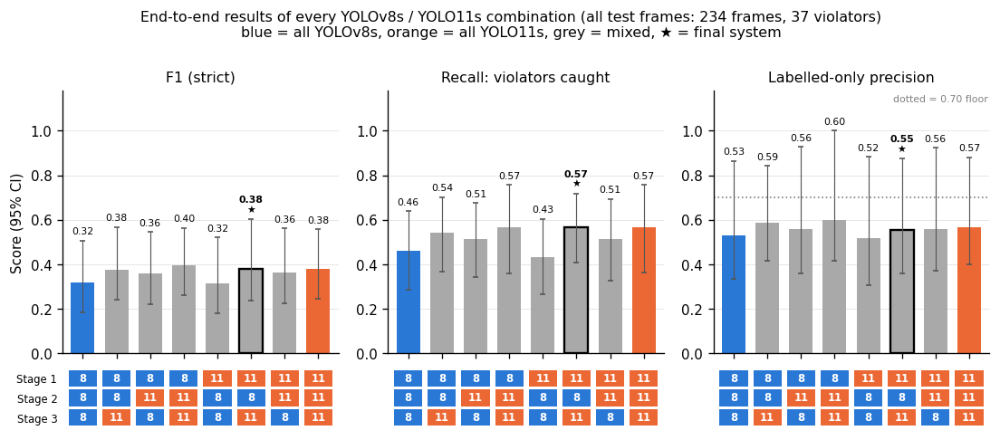

saved e2e/e2e_combos_metrics_test_all.png


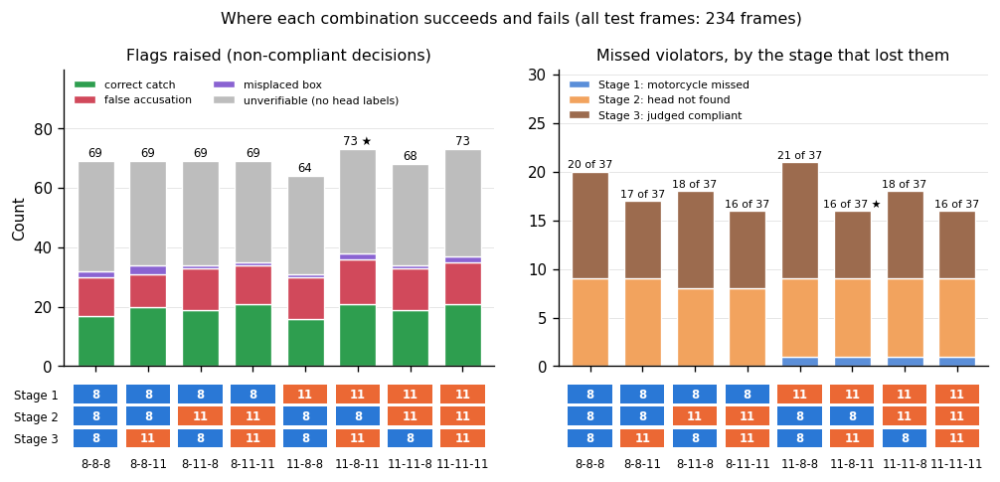

saved e2e/e2e_combos_outcomes_test_all.png


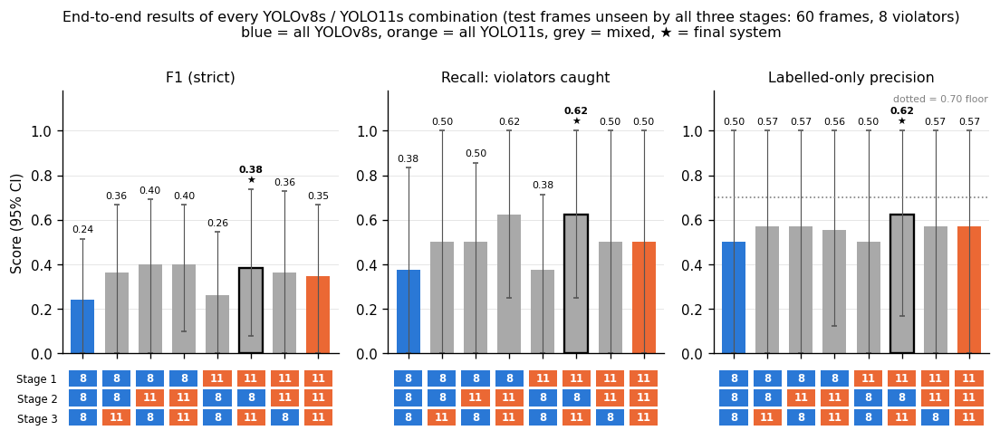

saved e2e/e2e_combos_metrics_test_unseen.png


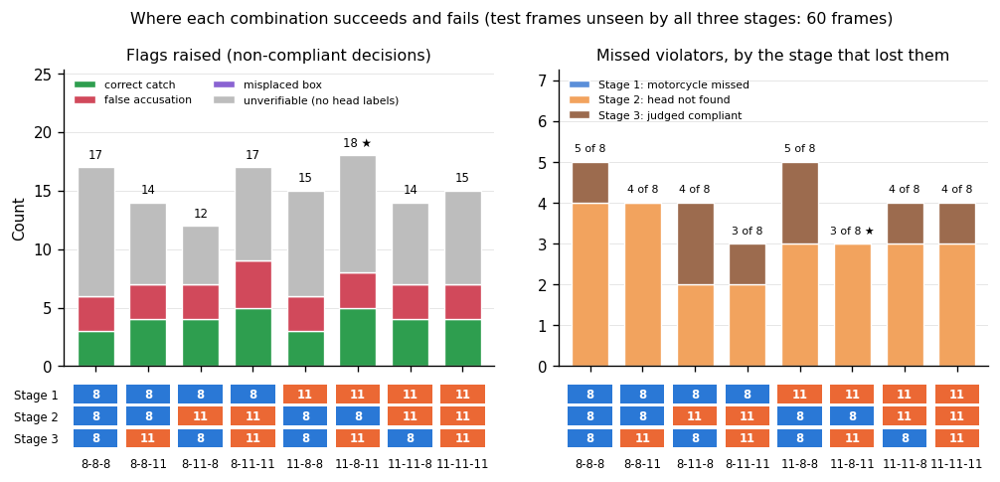

saved e2e/e2e_combos_outcomes_test_unseen.png


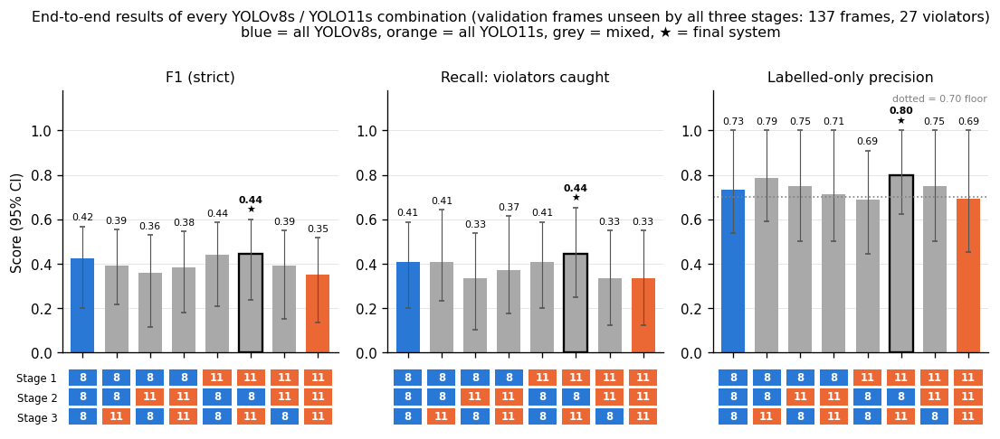

saved e2e/e2e_combos_metrics_valid_unseen.png


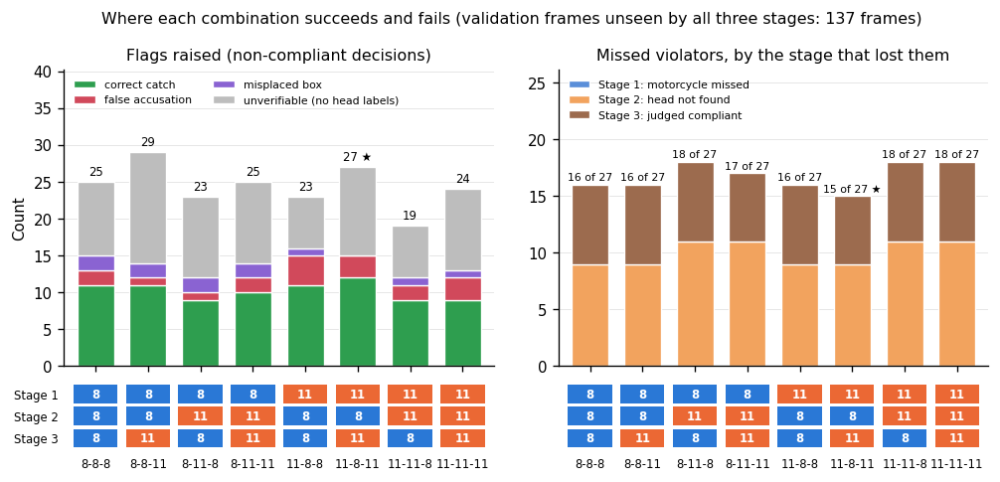

saved e2e/e2e_combos_outcomes_valid_unseen.png


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# E2E.2 Figures: end-to-end metrics of all 8 combinations (one set per frame subset)
#   bars: blue = all YOLOv8s (8-8-8), orange = all YOLO11s (11-11-11), grey = mixed; ★ / black edge = final system
#   the strip under each panel shows which backbone each stage uses
from matplotlib.patches import Rectangle
SUBSET_TITLE = {'valid_unseen': 'validation frames unseen by all three stages', 'test_all': 'all test frames',
                'test_unseen': 'test frames unseen by all three stages'}
LBL = [c['label'] for c in COMBOS]; X = np.arange(len(LBL))
def bar_color(c):
    return COL['YOLOv8s'] if set(c['key']) == {'YOLOv8s'} else COL['YOLO11s'] if set(c['key']) == {'YOLO11s'} else '#a9a9a9'

def comp_strip(ax, labels=True):
    for j, c in enumerate(COMBOS):
        for i, a in enumerate(c['key']):
            ax.add_patch(Rectangle((j - 0.42, 2 - i - 0.42), 0.84, 0.84, color=COL[a], lw=0))
            ax.text(j, 2 - i, SHORT[a], ha='center', va='center', color='white', fontsize=7, fontweight='bold')
    ax.set_xlim(-0.6, len(COMBOS) - 0.4); ax.set_ylim(-0.6, 2.6)
    ax.set_yticks([2, 1, 0], ['Stage 1', 'Stage 2', 'Stage 3'], fontsize=7)
    ax.set_xticks(X, LBL if labels else [''] * len(X), fontsize=7)
    ax.grid(False); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)

def metric_panel(ax, d, col, lo, hi, title):
    v = d[col].values; err = np.vstack([v - d[lo].values, d[hi].values - v])
    bars = ax.bar(X, v, 0.7, color=[bar_color(c) for c in COMBOS],
                  edgecolor=['black' if c['final'] else 'none' for c in COMBOS], linewidth=1.4,
                  yerr=err, error_kw=dict(ecolor='#555555', elinewidth=0.7, capsize=2))
    for j, (b, c) in enumerate(zip(bars, COMBOS)):
        ax.text(b.get_x() + b.get_width() / 2, d[hi].values[j] + 0.02, f"{v[j]:.2f}" + ('\n★' if c['final'] else ''),
                ha='center', va='bottom', fontsize=6.5, fontweight='bold' if c['final'] else 'normal')
    ax.set_ylim(0, 1.18); ax.set_xlim(-0.6, len(COMBOS) - 0.4); ax.set_xticks(X, [''] * len(X))
    ax.set_title(title); ax.grid(axis='x', visible=False)

def combo_figures(subset):
    d = COMBO_RES[COMBO_RES.frames == subset].set_index('combo').loc[LBL].reset_index()
    n_v = int((d.TP + d.FN).iloc[0]); tag = SUBSET_TITLE[subset]
    # (1) F1 / recall / labelled precision with 95% CIs (shot-group bootstrap, as in evaluate_e2e)
    fig = plt.figure(figsize=(11, 4.1))
    gs = fig.add_gridspec(2, 3, height_ratios=[4.2, 1], hspace=0.08, wspace=0.18, top=0.8, bottom=0.04)
    for k, (col, lo, hi, t) in enumerate([('F1', 'F1_lo', 'F1_hi', 'F1 (strict)'), ('R', 'R_lo', 'R_hi', 'Recall: violators caught'),
                                          ('P_labelled', 'PL_lo', 'PL_hi', 'Labelled-only precision')]):
        ax = fig.add_subplot(gs[0, k]); metric_panel(ax, d, col, lo, hi, t)
        if col == 'P_labelled': ax.axhline(PREC_E2E, ls=':', lw=1, c='grey'); ax.text(len(X) - 0.45, 1.13, f'dotted = {PREC_E2E:.2f} floor', fontsize=6.5, c='grey', ha='right')
        if k == 0: ax.set_ylabel('Score (95% CI)')
        comp_strip(fig.add_subplot(gs[1, k]), labels=False)
        if k: fig.axes[-1].set_yticklabels([])
    fig.suptitle(f'End-to-end results of every YOLOv8s / YOLO11s combination ({tag}: {d.n_frames.iloc[0]} frames, {n_v} violators)\n'
                 'blue = all YOLOv8s, orange = all YOLO11s, grey = mixed, ★ = final system', fontsize=9.5)
    save(fig, f'e2e/e2e_combos_metrics_{subset}.png')

    # (2) what the flags were, and where the missed violators were lost
    fig = plt.figure(figsize=(10, 4.1))
    gs = fig.add_gridspec(2, 2, height_ratios=[4.2, 1], hspace=0.08, wspace=0.15, top=0.86, bottom=0.08)
    ax = fig.add_subplot(gs[0, 0]); bottom = np.zeros(len(d))
    for col, c_, name in [('TP', '#2e9e4f', 'correct catch'), ('false_acc', '#d1495b', 'false accusation'),
                          ('localisation', '#8a63d2', 'misplaced box'), ('unverifiable', '#bdbdbd', 'unverifiable (no head labels)')]:
        ax.bar(X, d[col], 0.7, bottom=bottom, color=c_, label=name, edgecolor='white', linewidth=0.8); bottom += d[col].values
    for j, c in enumerate(COMBOS):
        ax.text(j, bottom[j] + 0.5, f"{int(bottom[j])}" + (' ★' if c['final'] else ''), ha='center', va='bottom', fontsize=7)
    ax.set_title('Flags raised (non-compliant decisions)'); ax.set_ylabel('Count'); ax.legend(fontsize=6.5, loc='upper left', ncol=2)
    ax.set_xlim(-0.6, len(COMBOS) - 0.4); ax.set_xticks(X, [''] * len(X)); ax.grid(axis='x', visible=False); ax.set_ylim(0, bottom.max() * 1.35 + 1)
    comp_strip(fig.add_subplot(gs[1, 0]))
    ax = fig.add_subplot(gs[0, 1]); bottom = np.zeros(len(d))
    for col, c_, name in [('s1_miss', '#5b8fd9', 'Stage 1: motorcycle missed'), ('s2_miss', '#f2a35e', 'Stage 2: head not found'),
                          ('s3_miss', '#9c6b4e', 'Stage 3: judged compliant')]:
        ax.bar(X, d[col], 0.7, bottom=bottom, color=c_, label=name, edgecolor='white', linewidth=0.8); bottom += d[col].values
    for j, c in enumerate(COMBOS):
        ax.text(j, bottom[j] + 0.2, f"{int(bottom[j])} of {n_v}" + (' ★' if c['final'] else ''), ha='center', va='bottom', fontsize=6.5)
    ax.set_title('Missed violators, by the stage that lost them'); ax.legend(fontsize=6.5, loc='upper left')
    ax.set_xlim(-0.6, len(COMBOS) - 0.4); ax.set_xticks(X, [''] * len(X)); ax.grid(axis='x', visible=False); ax.set_ylim(0, max(bottom.max(), 1) * 1.45)
    s = fig.add_subplot(gs[1, 1]); comp_strip(s); s.set_yticklabels([])
    fig.suptitle(f'Where each combination succeeds and fails ({tag}: {d.n_frames.iloc[0]} frames)', fontsize=9.5)
    save(fig, f'e2e/e2e_combos_outcomes_{subset}.png')

for subset in ['test_all', 'test_unseen', 'valid_unseen']:
    combo_figures(subset)

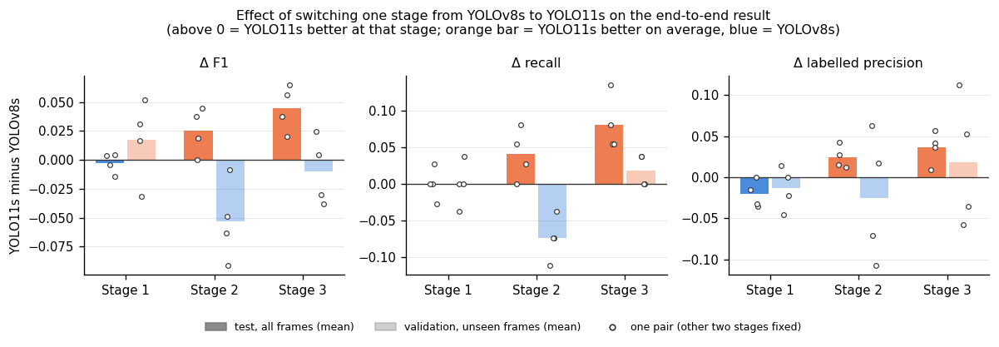

saved e2e/e2e_stage_switch_effect.png
                           mean                     min                     max                
stage                   Stage 1 Stage 2 Stage 3 Stage 1 Stage 2 Stage 3 Stage 1 Stage 2 Stage 3
frames       metric                                                                            
test_all     F1          -0.003   0.025   0.045  -0.014   0.000   0.020   0.004   0.045   0.065
             P_labelled  -0.021   0.024   0.036  -0.036   0.012   0.009   0.000   0.043   0.057
             R           -0.000   0.041   0.081  -0.027   0.000   0.054   0.027   0.081   0.135
test_unseen  F1          -0.012   0.066   0.058  -0.052  -0.037  -0.016   0.021   0.160   0.124
             P_labelled   0.017   0.018   0.045   0.000  -0.054  -0.016   0.054   0.071   0.125
             R            0.000   0.062   0.125  -0.125  -0.125   0.000   0.125   0.125   0.250
valid_unseen F1           0.017  -0.053  -0.010  -0.032  -0.092  -0.038   0.052  -0.008   0.025
  

In [ ]:
# THESIS OUTPUT (panel revision, no training)
# E2E.3 Which stage's backbone matters? Switch ONE stage from YOLOv8s to YOLO11s, keep the other two the same.
# Each stage has 4 such pairs (one per setting of the other two stages); dot = one pair, bar = their mean.
EFF = []
for subset in ['test_all', 'test_unseen', 'valid_unseen']:
    d = COMBO_RES[COMBO_RES.frames == subset].set_index('combo')
    for st in range(3):
        for c in COMBOS:
            if c['key'][st] != 'YOLOv8s': continue
            k11 = list(c['key']); k11[st] = 'YOLO11s'; l11 = '-'.join(SHORT[a] for a in k11)
            for m in ['F1', 'R', 'P_labelled', 'false_acc']:
                EFF.append(dict(frames=subset, stage=f'Stage {st + 1}', metric=m, pair=f"{c['label']} → {l11}",
                                diff=d.loc[l11, m] - d.loc[c['label'], m]))
EFF = pd.DataFrame(EFF); EFF.to_csv(f'{RES}/e2e_combos_stage_effect.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
rng = np.random.default_rng(1)
for ax, (m, t) in zip(axes, [('F1', 'Δ F1'), ('R', 'Δ recall'), ('P_labelled', 'Δ labelled precision')]):
    for k, subset in enumerate(['test_all', 'valid_unseen']):
        e = EFF[(EFF.frames == subset) & (EFF.metric == m)]
        for s_i, st in enumerate(['Stage 1', 'Stage 2', 'Stage 3']):
            v = e[e.stage == st]['diff'].values; xpos = s_i + (k - 0.5) * 0.36
            ax.bar(xpos, v.mean(), 0.32, color=COL['YOLO11s'] if v.mean() > 0 else COL['YOLOv8s'], alpha=0.35 if k else 0.85)
            ax.scatter(xpos + rng.uniform(-0.06, 0.06, len(v)), v, s=12, color='white', edgecolor='#333333', lw=0.7, zorder=3)
    ax.axhline(0, color='#333333', lw=0.8)
    ax.set_xticks([0, 1, 2], ['Stage 1', 'Stage 2', 'Stage 3']); ax.set_title(t); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('YOLO11s minus YOLOv8s')
handles = [Rectangle((0, 0), 1, 1, color='#777777', alpha=0.85), Rectangle((0, 0), 1, 1, color='#777777', alpha=0.35),
           Line2D([], [], ls='', marker='o', mfc='white', mec='#333333', ms=4)]
fig.legend(handles, ['test, all frames (mean)', 'validation, unseen frames (mean)', 'one pair (other two stages fixed)'],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06), fontsize=7.5)
fig.suptitle('Effect of switching one stage from YOLOv8s to YOLO11s on the end-to-end result\n'
             '(above 0 = YOLO11s better at that stage; orange bar = YOLO11s better on average, blue = YOLOv8s)', fontsize=9.5)
fig.tight_layout(rect=(0, 0.04, 1, 1)); save(fig, 'e2e/e2e_stage_switch_effect.png')
with pd.option_context('display.width', 200):
    print(EFF[EFF.metric.isin(['F1', 'R', 'P_labelled'])].groupby(['frames', 'metric', 'stage'])['diff']
          .agg(['mean', 'min', 'max']).round(3).unstack('stage').to_string())

Frames shown: ['fixed_video3_mp4-0420_jpg', 'HCVR-B36A_ch1_main_20260812100000_20260812110000_mp4-0138_jpg', 'HCVR-B36A_ch1_main_20260811080000_20260811090000_mp4-0896_jpg', 'HCVR-B36A_ch1_main_20260811140000_20260811150000_mp4-0122_jpg']


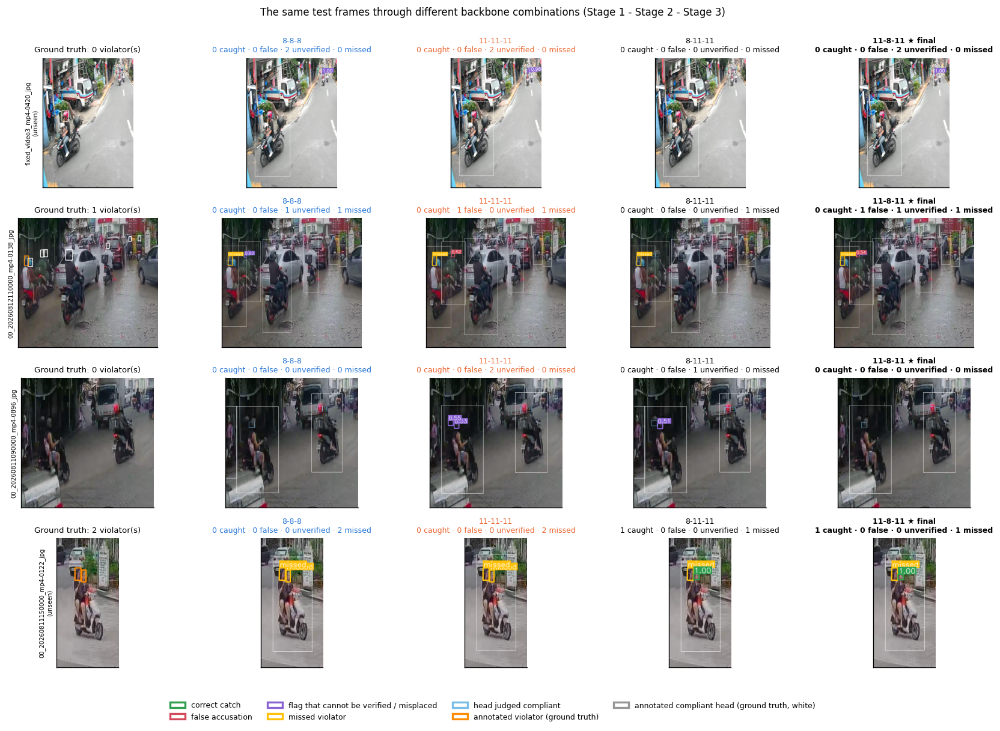

saved e2e/e2e_combos_examples.png
Pipeline reset to the final system: 11-8-11


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# E2E.4 The SAME test frames through several combinations, side by side (ground truth | system A | system B | ...)
#   Frames are picked automatically where the shown systems DISAGREE most (errors = false accusations + misplaced +
#   unverifiable flags + missed violators), one frame per video shot, unseen frames first. Same scoring as evaluate_e2e.
SHOW      = ['8-8-8', '11-11-11', '8-11-11']      # systems to show (the final system is added automatically)
N_E2E     = 4                                     # frames (rows)
MANUAL_E2E = []                                   # optional: frame FILE NAMES to show instead of the automatic pick
FINAL_LBL = next(c['label'] for c in COMBOS if c['final'])
SHOW = list(dict.fromkeys(SHOW + [FINAL_LBL])); BY = {c['label']: c for c in COMBOS}
SUB = 'test_all'; frames = FSETS[SUB]

err = np.stack([(lambda E: (E['fa'] + E['loc'] + E['unver'] + E['fn']).values)(PERFRAME[(l, SUB)]) for l in SHOW])   # systems x frames
viol = (PERFRAME[(SHOW[0], SUB)]['tp'] + PERFRAME[(SHOW[0], SUB)]['fn']).values
if MANUAL_E2E:
    names = [os.path.basename(p) for p in frames]
    rows = [names.index(m) for m in MANUAL_E2E if m in names]
else:
    spread = err.max(0) - err.min(0)
    order = sorted(range(len(frames)), key=lambda i: (-spread[i], frame_base(frames[i]) in SEEN3, -viol[i]))
    rows, used = [], set()
    for i in order:
        g = GROUP_OF.get(frame_base(frames[i]), frame_base(frames[i]))
        if g in used or spread[i] == 0: continue
        rows.append(i); used.add(g)
        if len(rows) == N_E2E: break
print('Frames shown:', [os.path.basename(frames[i]).split('.rf.')[0] for i in rows])

C_CATCH, C_FALSE, C_UNVER, C_MISS, C_OK = (46, 158, 79), (209, 73, 91), (138, 99, 210), (255, 193, 7), (120, 190, 230)
def outcomes(fp):
    """run_pipeline on one frame for the CURRENT system, then label every head and every annotated violator like evaluate_e2e."""
    frame = cv2.imread(fp); H, W = frame.shape[:2]
    out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
    g_of_p = dict(match_heads(pred, gt)); caught = set()
    heads = []
    for a, h in enumerate(pred):
        if h['label'] != 'non-compliant': kind = 'ok'
        elif a in g_of_p:
            lab = gt[g_of_p[a]][1]
            if lab == 'exempt': kind = 'ok'
            elif lab == 'non-compliant': kind = 'catch'; caught.add(g_of_p[a])
            else: kind = 'false'
        else: kind = 'unver'                                      # misplaced or unverifiable
        heads.append((h['box'], kind, h['p_nc']))
    missed = [g[0] for b, g in enumerate(gt) if g[1] == 'non-compliant' and b not in caught]
    return dict(regions=out['regions'], heads=heads, missed=missed, gt=gt)

def draw_panel(img, o, crop, lw):
    x0, y0 = crop[:2]; sh = lambda b: [b[0] - x0, b[1] - y0, b[2] - x0, b[3] - y0]
    for r in o['regions']: draw_box(img, sh(r), (235, 235, 235), max(1, lw // 2))
    for b, kind, p in o['heads']:
        if kind == 'ok': draw_box(img, sh(b), C_OK, max(1, lw // 2))
    for b in o['missed']: draw_box(img, sh(b), C_MISS, lw, 'missed')
    for b, kind, p in o['heads']:
        if kind != 'ok': draw_box(img, sh(b), {'catch': C_CATCH, 'false': C_FALSE, 'unver': C_UNVER}[kind], lw, f'{p:.2f}')

RESU = {}
for i in rows:
    for l in SHOW:
        set_combo(BY[l]); RESU[(i, l)] = outcomes(frames[i])
ncol = 1 + len(SHOW)
fig, axes = plt.subplots(len(rows), ncol, figsize=(2.9 * ncol, 2.5 * len(rows)), squeeze=False)
for row, i in zip(axes, rows):
    fp = frames[i]; frame = rgb(fp); H, W = frame.shape[:2]
    boxes = [g[0] for g in RESU[(i, SHOW[0])]['gt']] + [r for l in SHOW for r in RESU[(i, l)]['regions']]
    if boxes:                                                 # crop to the riders so the heads are visible
        b = np.array(boxes, float); x1, y1, x2, y2 = b[:, 0].min(), b[:, 1].min(), b[:, 2].max(), b[:, 3].max()
        px, py = 0.08 * (x2 - x1) + 20, 0.08 * (y2 - y1) + 20
        crop = [int(max(0, x1 - px)), int(max(0, y1 - py)), int(min(W, x2 + px)), int(min(H, y2 + py))]
    else:
        crop = [0, 0, W, H]
    base = frame[crop[1]:crop[3], crop[0]:crop[2]]; lw = max(2, int(round(max(base.shape[:2]) / 260)))
    gt_img = base.copy()
    for box, lab in RESU[(i, SHOW[0])]['gt']:
        draw_box(gt_img, [box[0] - crop[0], box[1] - crop[1], box[2] - crop[0], box[3] - crop[1]],
                 (255, 140, 0) if lab == 'non-compliant' else (255, 255, 255), lw)
    nv = sum(1 for g in RESU[(i, SHOW[0])]['gt'] if g[1] == 'non-compliant')
    row[0].imshow(gt_img); row[0].set_title(f'Ground truth: {nv} violator(s)', fontsize=8)
    row[0].set_ylabel(os.path.basename(fp).split('.rf.')[0][-30:] + ('\n(unseen)' if frame_base(fp) not in SEEN3 else ''), fontsize=6)
    for ax, l in zip(row[1:], SHOW):
        o = RESU[(i, l)]; img = base.copy(); draw_panel(img, o, crop, lw)
        k = Counter(kind for _, kind, _ in o['heads'])
        ax.imshow(img)
        ax.set_title(f"{l}{' ★ final' if BY[l]['final'] else ''}\n{k['catch']} caught · {k['false']} false · "
                     f"{k['unver']} unverified · {len(o['missed'])} missed", fontsize=7.5,
                     fontweight='bold' if BY[l]['final'] else 'normal', color=bar_color(BY[l]) if bar_color(BY[l]) != '#a9a9a9' else 'black')
    for ax in row:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.legend([plt.Rectangle((0, 0), 1, 1, fc='none', ec=np.array(c) / 255, lw=2) for c in
            [C_CATCH, C_FALSE, C_UNVER, C_MISS, C_OK, (255, 140, 0), (150, 150, 150)]],
           ['correct catch', 'false accusation', 'flag that cannot be verified / misplaced', 'missed violator',
            'head judged compliant', 'annotated violator (ground truth)', 'annotated compliant head (ground truth, white)'], loc='lower center', ncol=4, fontsize=7.5,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('The same test frames through different backbone combinations (Stage 1 - Stage 2 - Stage 3)', fontsize=10)
fig.tight_layout(rect=(0, 0.05, 1, 0.98)); save(fig, 'e2e/e2e_combos_examples.png')
set_combo(next(c for c in COMBOS if c['final']))           # leave the notebook pointing at the final system
print('Pipeline reset to the final system:', FINAL_LBL)

4 frames: ['HCVR-B36A_ch1_main_20260812100000_20260812110000_mp4-0138_jpg', 'fixed_video3_mp4-0424_jpg', 'HCVR-B36A_ch1_main_20260811140000_20260811150000_mp4-0122_jpg', 'HCVR-B36A_ch1_main_20260811070000_20260811080000_mp4-2858_jpg']


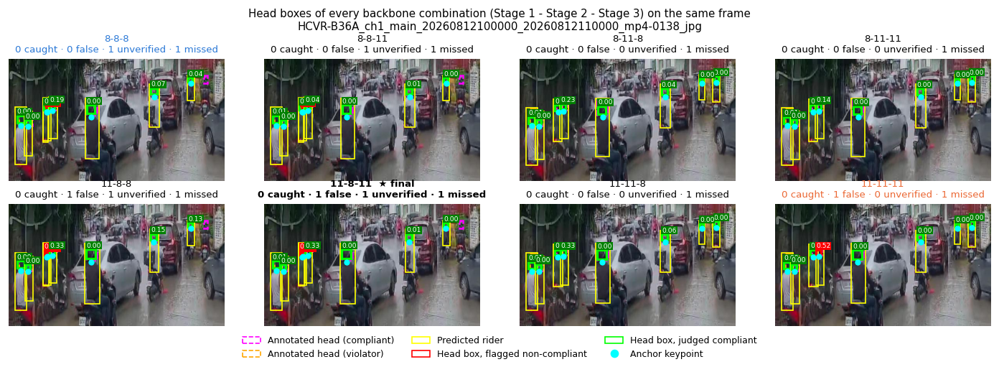

saved e2e/e2e_headbox_combos_1.png


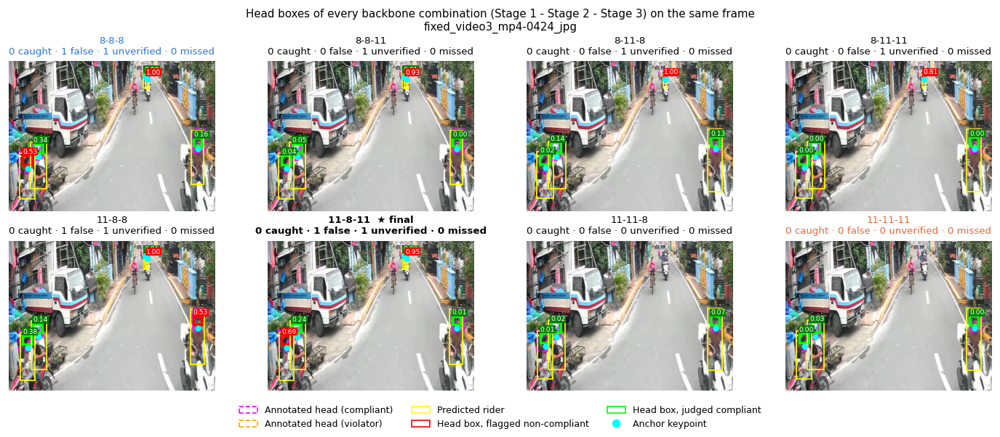

saved e2e/e2e_headbox_combos_2.png


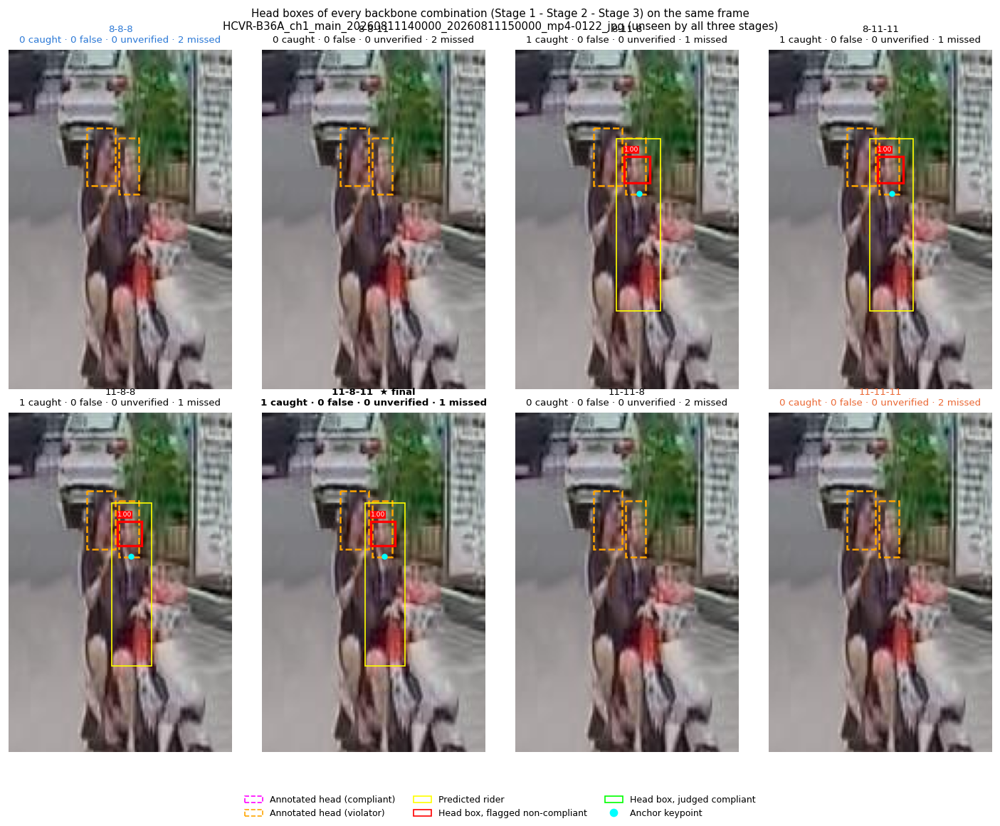

saved e2e/e2e_headbox_combos_3.png


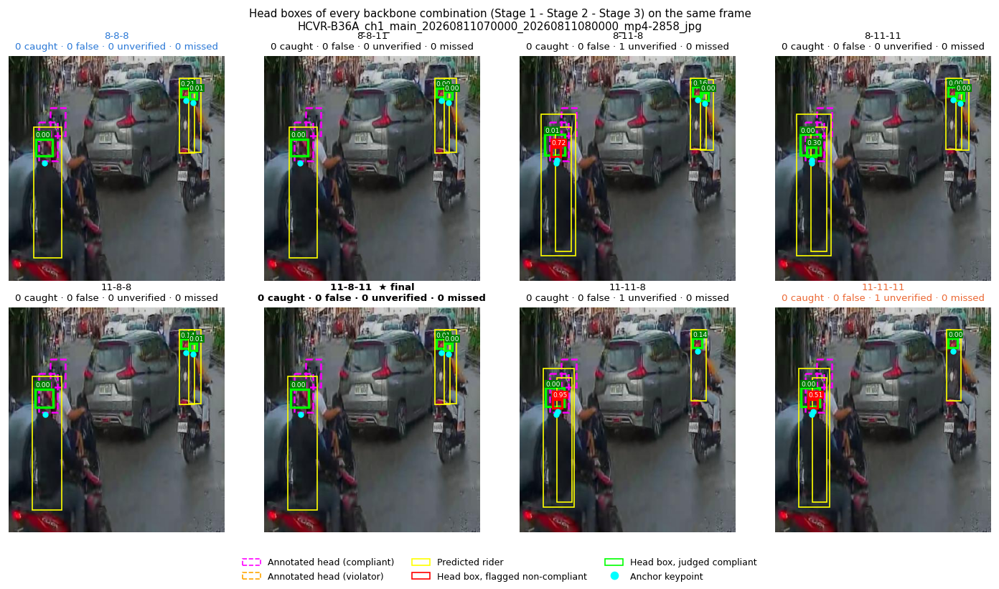

saved e2e/e2e_headbox_combos_4.png
Pipeline reset to the final system.


In [ ]:
# THESIS OUTPUT (panel revision, no training)
# E2E.5 Head-box figure for EVERY combination (same style as the "original vs corrected pipeline" head-box figure)
#   One figure per frame, zoomed on its riders, one panel per combination (Stage 1 - Stage 2 - Stage 3):
#   dashed magenta = annotated compliant head, dashed orange = annotated violator, yellow = predicted rider,
#   head box = red if Stage 3 flagged it non-compliant / lime if judged compliant, cyan dot = anchor keypoint.
#   Frames are picked where the 8 systems disagree most (needs E2E.1), 2+ annotated heads, one frame per video shot.
import matplotlib.patches as mpatches
N_HB      = 4                    # number of frames (one figure each)
SUB_HB    = 'test_all'           # 'test_all', 'test_unseen' or 'valid_unseen'
MANUAL_HB = []                   # optional: frame FILE NAMES to draw instead of the automatic pick
SHOW_P    = True                 # False = hide the small P(non-compliant) tags on the head boxes
HB_COMBOS = [c['label'] for c in COMBOS]      # or a shorter list, e.g. ['8-8-8', '11-11-11', '8-11-11', '11-8-11']
BYL = {c['label']: c for c in COMBOS}

def heads_for(c, fp):
    """Run ONE combination on one frame; label every head and every annotated violator with evaluate_e2e's rules."""
    set_combo(c)
    frame = cv2.imread(fp); H, W = frame.shape[:2]
    out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
    g_of_p = dict(match_heads(pred, gt)); caught = set(); n = Counter()
    for a, h in enumerate(pred):
        kind = 'ok'
        if h['label'] == 'non-compliant':
            if a in g_of_p and gt[g_of_p[a]][1] == 'non-compliant': kind = 'catch'; caught.add(g_of_p[a])
            elif a in g_of_p and gt[g_of_p[a]][1] == 'compliant': kind = 'false'
            elif a in g_of_p: kind = 'ok'                                   # exempt head: not scored
            else: kind = 'unver'
        h['kind'] = kind; n[kind] += 1
    n['missed'] = sum(1 for b, g in enumerate(gt) if g[1] == 'non-compliant' and b not in caught)
    return pred, gt, n

# ---- pick the frames ----
frames_hb = FSETS[SUB_HB]
if MANUAL_HB:
    names = [os.path.basename(p) for p in frames_hb]
    pick_hb = [names.index(m) for m in MANUAL_HB if m in names]
else:
    errs = np.stack([(PERFRAME[(l, SUB_HB)]['fa'] + PERFRAME[(l, SUB_HB)]['loc'] + PERFRAME[(l, SUB_HB)]['unver']
                      + PERFRAME[(l, SUB_HB)]['fn']).values for l in HB_COMBOS])
    spread = errs.max(0) - errs.min(0)
    n_heads = []
    for fp in frames_hb:
        H, W = cv2.imread(fp).shape[:2]; n_heads.append(len(gt_heads(fp, W, H)))
    order = sorted(range(len(frames_hb)), key=lambda i: (-spread[i], -(n_heads[i] >= 2), frame_base(frames_hb[i]) in SEEN3))
    pick_hb, used = [], set()
    for i in order:
        g = GROUP_OF.get(frame_base(frames_hb[i]), frame_base(frames_hb[i]))
        if g in used or n_heads[i] < 2 or spread[i] == 0: continue
        pick_hb.append(i); used.add(g)
        if len(pick_hb) == N_HB: break
print(f'{len(pick_hb)} frames:', [os.path.basename(frames_hb[i]).split('.rf.')[0] for i in pick_hb])

# ---- draw ----
ncol = min(4, len(HB_COMBOS)); nrow = math.ceil(len(HB_COMBOS) / ncol)
for n_fig, i in enumerate(pick_hb, 1):
    fp = frames_hb[i]; img = cv2.cvtColor(cv2.imread(fp), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    res = {l: heads_for(BYL[l], fp) for l in HB_COMBOS}
    gt = next(iter(res.values()))[1]
    boxes = [h['rider_box'] for hs, _, _ in res.values() for h in hs] + [g[0] for g in gt]
    x1, y1 = max(0, min(b[0] for b in boxes) - 40), max(0, min(b[1] for b in boxes) - 40)
    x2, y2 = min(W, max(b[2] for b in boxes) + 40), min(H, max(b[3] for b in boxes) + 40)
    aspect = (y2 - y1) / max(x2 - x1, 1)
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.0 * ncol, 3.0 * nrow * min(max(aspect, 0.6), 1.8) + 0.6), squeeze=False)
    for a in axs.ravel(): a.axis('off')
    for a, l in zip(axs.ravel(), HB_COMBOS):
        hs, gt, n = res[l]
        a.imshow(img); a.set_xlim(x1, x2); a.set_ylim(y2, y1); a.axis('off')
        for g, lab in gt:
            a.add_patch(mpatches.Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1], fill=False, ls='--', lw=1.5,
                                           ec='orange' if lab == 'non-compliant' else 'magenta'))
        for h in hs:
            r, b = h['rider_box'], h['box']
            a.add_patch(mpatches.Rectangle((r[0], r[1]), r[2] - r[0], r[3] - r[1], fill=False, ec='yellow', lw=1))
            a.add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, lw=2,
                                           ec='red' if h['label'] == 'non-compliant' else 'lime'))
            if SHOW_P: a.text(b[0], b[1] - 2, f"{h['p_nc']:.2f}", color='white', fontsize=5.5, va='bottom',
                   bbox=dict(fc='red' if h['label'] == 'non-compliant' else 'green', ec='none', pad=0.6))
            a.plot(*h['kpt'], 'o', c='cyan', ms=4)
        c = BYL[l]
        a.set_title(f"{l}{'  ★ final' if c['final'] else ''}\n"
                    f"{n['catch']} caught · {n['false']} false · {n['unver']} unverified · {n['missed']} missed",
                    fontsize=8, fontweight='bold' if c['final'] else 'normal',
                    color=COL['YOLOv8s'] if set(c['key']) == {'YOLOv8s'} else COL['YOLO11s'] if set(c['key']) == {'YOLO11s'} else 'black')
    fig.legend(handles=[mpatches.Patch(ec='magenta', fc='none', ls='--', label='Annotated head (compliant)'),
                        mpatches.Patch(ec='orange', fc='none', ls='--', label='Annotated head (violator)'),
                        mpatches.Patch(ec='yellow', fc='none', label='Predicted rider'),
                        mpatches.Patch(ec='red', fc='none', label='Head box, flagged non-compliant'),
                        mpatches.Patch(ec='lime', fc='none', label='Head box, judged compliant'),
                        plt.Line2D([], [], marker='o', c='cyan', ls='', label='Anchor keypoint')],
               loc='lower center', ncol=3, fontsize=7.5, frameon=False)
    fig.suptitle(f"Head boxes of every backbone combination (Stage 1 - Stage 2 - Stage 3) on the same frame\n"
                 f"{os.path.basename(fp).split('.rf.')[0]}" + (' (unseen by all three stages)' if frame_base(fp) not in SEEN3 else ''),
                 fontsize=9)
    fig.tight_layout(rect=(0, 0.07, 1, 1), h_pad=2.5); save(fig, f'e2e/e2e_headbox_combos_{n_fig}.png')
set_combo(next(c for c in COMBOS if c['final']))           # leave the notebook pointing at the final system
print('Pipeline reset to the final system.')

## B.7 Reporting checklist

- **Dataset:** master-split table (frames, groups, motorcycles, compliant, non-compliant per split). State that splits are grouped by video and near-duplicates, stratified by violations, contain no augmented copies in val/test, and are shared by all three stages.
- **Per stage:** test metrics **with 95% CIs**. If you ran ≥ 3 seeds, give mean ± SD. Only call v8 vs v11 different when the paired bootstrap CI (Stage 1), the paired t-test, or McNemar (Stage 3) says so.
- **Stage 2:** rider-count accuracy for 1 / 2 / 3+ riders, and the gate-T ablation table. If the custom-σ pose mAP is lower than 0.79, explain that the stricter per-keypoint σ is intended.
- **Stage 3:** the operating point (threshold chosen on validation under a precision floor) and why: the asymmetric cost of a false accusation.
- **End-to-end:** violator precision/recall/F1 with CI, false accusations, and the **miss-attribution table**. This table shows which stage to improve next, which makes a strong Chapter 5 "recommendations" section.
- **Latency:** mean and p95 ms/frame plus the fraction of frames ≤ 33 ms, and how it scales with motorcycles per frame.
- **Thesis-text updates** to match the code: Path A landmark definition (5-point skeleton), per-keypoint OKS sigmas, class-weighting implemented as resampling, and the Stage 2 crops being square-resized without letterbox (a stated limitation, kept because the keypoint labels were drawn on those crops).

---
# PART C: ARCHIVE (earlier versions, checks and testing)
**Not needed for the current system.** Kept so earlier results (v1.3 to v1.8, Run 4, Run 6) can be traced and reproduced.

**Do not run cells marked WARNING: overwrites.** They replace files on Drive that **B.1** (Step 19 in Part A) reads, and B.1 will then stop with an assertion error.

Collapse this section in Colab (click the arrow next to the heading) to hide it.

## C.0 Original notebook introduction and version run guides (v1.6, v1.8, v1.9)
The v1.9 guides are superseded by the run order in Part A.

### Helmet Thesis: Corrected Training & Evaluation Pipeline (v2)

This notebook covers the processing of Stage 1, 2 and 3 notebooks. Each Part is also a step in the guide, so read the markdown cells as you go.

| Part | What it fixes | GPU time (L4) |
|---|---|---|
| **0. Setup** | API key moved to Colab Secrets; shared helper functions | 2 min |
| **1. Master split** | One frame-level split for all three stages, grouped by video and near-duplicates, stratified by violations, with no augmented copies in val/test | 5–10 min, no GPU |
| **2. Stage 1** | Retrain on the clean split with fixed run names (no silent `-2` folders); val-tuned confidence, bootstrap CIs, paired v8-vs-v11 test | ~2.5–3 h per model per seed |
| **3. Stage 2** | Crops inherit the master split; correct `flip_idx`; optional per-keypoint OKS sigmas; rider-count accuracy; NMS tuning; association and gate (T) ablation | ~45 min per model |
| **4. Stage 3** | Online augmentation back on; inverse-frequency resampling; checkpoint and threshold chosen on val for non-compliant recall; McNemar test; pre-labelling of the 825 unlabeled images | ~20 min per model |
| **5. End-to-end** | Full pipeline on the Stage 1 test frames; error attribution per stage; latency profile against the 33 ms budget; optional TensorRT | ~20 min |
| **6. Summary** | One table of every number for Chapter 4 | 1 min |

##### How to run
1. **Runtime → Change runtime type → GPU (L4 or better).**
2. Run **Part 0** every session.
3. Run **Parts 1 → 6 in order** the first time. Everything important is saved to `ROOT` on Google Drive: the master split, runs, weights and results.
4. **After a disconnect:** re-run Part 0 and cell **1.2** (re-downloads the frames and loads the saved master split), then jump to the Part you were on. Training cells skip finished runs and resume unfinished ones automatically.

**Rule used throughout:** every choice (confidence threshold, NMS IoU, gate T, checkpoint, winning model) is made on the **validation** split. The **test** split is only used to report final numbers. This keeps the test results honest.


#### v1.6 re-run (Stage 2 retrained with the CORRECT keypoint order): run ONLY these cells
Stage 1 is **not** retrained. Stage 3 is **not** retrained: the final v1.4 classifier is restored from the backup. Stage 2 is retrained under new run names (`..._sigfix_s0`), so the old Stage 2 runs stay untouched on Drive.
Start from a fresh runtime (Runtime → Disconnect and delete runtime). Stage 2 training takes roughly 1–3 hours; keep the tab open.

1. **Setup:** 0.1, 0.2, 0.3
2. **Backup + restore:** `#FIXES PT 2, BACKUP` (in Part 4, run it now), then `# R.1 v1.6: Restore the v1.4 Stage 3 classifier` (just below the backup cell)
3. **Part 1:** 1.2 only
4. **Part 3:** 3.1, 3.2 (must print `using [0, 3, 2, 1, 4]`), **3.3 (trains Stage 2)**, 3.4a, 3.4, 3.5. Skip the order check and the two "Association re-run" / "Gate ablation" cells.
5. **Part 4:** nothing else (Stage 3 is not retrained).
6. **Part 5:** 5.1, 5.1c, 5.3, `# 5.2 v1.6: Calibrate BOTH anchors`, sweep, final-test cell. **Do not run** 5.1b, the old 5.2, the `E2E_TEST = ...` cell or the hidden `@title` cells.
7. **After:** 6.1, final checks, results check, RQ2 head-size cell. Latency 5.4 is optional (same architectures).

If Colab disconnects during 3.3, re-run steps 1, 3 and 3.1–3.3: training resumes from the last checkpoint.
The final test is **end-to-end Run 6**. Its results are saved with a `_v6` suffix; nothing from v1.4 or v1.5 is overwritten without a backup.

#### v1.8 re-run (Stage 1 retrained on the AUGMENTED Roboflow v7): run ONLY these cells
Stage 2 and Stage 3 are **not** retrained. Their existing weights are only loaded: Stage 2 = `stage2_yolov8s_sig_s0`, Stage 3 = `stage3_yolo11s_s1` (epoch 27), exactly as in the reported system (Run 4).
**Leave `S1_VERSION = 4` in 0.2.** v4 stays the source of the master split, the valid/test frames and the end-to-end frames. v7 is only used for the Stage 1 **training** images (cell A.1). That keeps the Stage 1 test set and the end-to-end test set identical to the thesis.

1. **Setup:** 0.1, 0.2, 0.3
2. **Part 1:** 1.2 only (loads the saved master split; do NOT run 1.3 to 1.5)
3. **Part 2:** 2.1, then **A.1, A.2 (trains Stage 1), A.3**. **Do not run 2.2, 2.3 or 2.4**: 2.4 overwrites `stage1_test.csv` and `stage1_selected.json`.
4. **Part 3 (definitions only, no training):** 3.1, 3.2, 3.4a. **Do not run 3.3** or any other Part 3 cell.
5. **Part 4:** nothing.
6. **Part 5:** 5.1, 5.3, then **B.1, B.2, B.3**. Do not run 5.1b, 5.1c, the 5.2 cells, the sweep, `E2E_TEST = ...`, the v1.6 final-test cell or FIX-1 to FIX-5.
7. **Optional:** 5.4 latency, only if A.3 selects a *different architecture* than YOLOv8s (see B.3's note).

**If Colab disconnects during A.2:** re-run 0.1 to 0.3, 1.2, 2.1, A.1, A.2. Training resumes from the last checkpoint.
New result files: `stage1_test_aug.csv`, `stage1_selected_aug.json`, `e2e_valid_check_run4_v18.json`, `e2e_valid_s1aug.json`, `e2e_test_final_s1aug.json`, `e2e_final_config_s1aug.json`. No existing result file is overwritten.

#### v1.9 re-run (Stage 1 retrained on the NEW Roboflow version, using ROBOFLOW'S split): run ONLY these cells
Stage 1 is trained on the new `motorcycle-wubuz` version exactly as Roboflow split it: **2,302 training frames × 3 augmented outputs ≈ 6,906 training images, 980 validation, 489 test**. This follows the baseline (Tomas & Doma): 70/20/10-style split of real frames, augmentation on training only.
Stage 2 and Stage 3 are **not** retrained. Their Run 4 weights are only loaded (same as v1.8).
**Leave `S1_VERSION = 4` in 0.2.** v4 still supplies the end-to-end frames (master split). Put the new version number in **C.1** (`S1_NEW_VERSION`).

1. **Setup:** 0.1, 0.2, 0.3
2. **Part 1:** 1.2 only
3. **Part 2:** 2.1, then **C.1, C.2 (trains Stage 1, ~3–4 h per backbone on an L4), C.3**. Skip A.1–A.3 and 2.2–2.4.
4. **Part 3 (definitions only):** 3.1, 3.2, 3.4a
5. **Part 5:** 5.1, 5.3, **B.1**, then **C.4**. Skip B.2, B.3 and every other Part 5 cell.

**If Colab disconnects during C.2:** re-run 0.1–0.3, 1.2, 2.1, C.1, C.2. Training resumes from the last checkpoint.
New files (nothing existing is overwritten): `stage1_split_report_rf<ver>.json`, `stage1_test_rf<ver>.csv`, `stage1_selected_rf<ver>.json`, `e2e_*_s1rf<ver>*.json`, `e2e_s1_comparison_rf<ver>.csv`, `e2e_final_config_s1rf<ver>.json`.

**What to report:** Stage 1 test scores are on Roboflow's 489 test frames, so they are **not** comparable with the v1.7/v1.8 Stage 1 table (234 frames). Roboflow splits frame by frame at random, so C.1 prints how many test frames have a near-duplicate or same-shot frame in training; say this in the limitations. For end-to-end, C.4 reports every Stage 1 on the same frames, both on all thesis valid/test frames and on only the frames the new Stage 1 never trained on ("unseen"). The unseen rows are the fair comparison.

#### v1.9 STAGE 2 NOTEBOOK (Stage 2 retrained on the NEW keypoint version, Roboflow's split; end to end with the NEW Stage 1): run ONLY these cells
This is the **second** notebook. Stage 1 keeps training in the other notebook (C.2); this one retrains Stage 2 at the same time. Both save to the same Drive folder, so this notebook picks up the new Stage 1 as soon as the other notebook has run **C.3** (it writes `stage1_selected_rf8.json`).
Stage 3 is **not** retrained (Run 4 classifier, loaded only). Leave `S1_VERSION = 4` in 0.2.

**Before running:** in **D.1** set `S2_NEW_VERSION` to the new `cropped-keypoints` version (2,291 × 3 / 976 / 488) and check `S1_NEW_VERSION = 8`.

**Part A: train Stage 2 now (does not need Stage 1)**
1. **Setup:** 0.1, 0.2, 0.3
2. **Part 1:** 1.2 only
3. **Part 3:** 3.1, **D.1, D.2 (trains Stage 2, ~1–1.5 h per backbone)**, 3.4a, **D.3**. Skip 3.2–3.5 and every other Part 3 cell.

**Part B: end to end, only AFTER the other notebook has finished C.2 and run C.3**
4. **Part 5:** 5.1, 5.3, B.1, then **E.1, E.2, E.3**. Skip everything else in Part 5.

**If Colab disconnects:** re-run 0.1–0.3, 1.2, 3.1, D.1, then continue where you stopped (D.2 resumes training; E-cells need 3.4a, 5.1, 5.3, B.1 first).
**In the Stage 1 notebook** you only need C.2 and C.3. C.4 is optional: E.2/E.3 here already compare every system on the same frames.

New files (nothing existing is overwritten): `stage2_split_report_rf3.json`, `stage2_test_rf3.csv`, `stage2_selected_rf3.json`, `head_box_calib_s12.json`, `e2e_valid_sweep_s12.csv`, `e2e_s12_comparison.csv`, `e2e_final_config_s12.json`, `e2e_*_s12*.json` (under `results/`).

**How the end-to-end test stays fair:** Roboflow split both datasets at random, so many thesis valid/test frames are training frames of the new Stage 1 (269 valid / 132 test) and possibly of the new Stage 2. All tuning (head-box calibration, anchor, gate T, Stage 3 threshold) and the final decision use only **unseen** validation frames (used by neither new model). The test is run once, and reported on unseen and on all frames.

#### v1.9 STAGE 3 (helmet classifier retrained on `helmet-classification-k8z2f` v6, Roboflow's split) + final end to end with ALL THREE new stages
Stage 3 is retrained on a new Roboflow version with the same kind of split as Stages 1 and 2 (about 61/26/13 of unique crops, ×3 augmentation on training only). Nothing old is overwritten: `stage3_selected.json` and the Run 4 classifier stay as they are.

**Before running:** set `S3_NEW_VERSION` in **F.1** (default 6).

**Run order (one session):**
1. **Setup:** 0.1, 0.2, 0.3, then 1.2, 3.1, **D.1** (fixed tracing), 3.4a
2. **Stage 3:** **F.1, F.1b (checks the split; nothing trains until it passes), F.2 (trains 3 balancing ratios × 2 backbones × 3 seeds = 18 runs, roughly 3–4 h on an L4), F.3**
3. **End to end:** 5.1, 5.3, B.1, **E.1, E.2, E.3** (S1+S2 with the corrected "unseen" frames), then **G.1, G.2** (all three new stages)

**If Colab disconnects during F.2:** re-run step 1, then F.1 and F.2; training resumes. F.3 must run in the **same session** as F.2 (it reads every-epoch checkpoints from local disk).

New files: `stage3_split_report_rf6.json`, `stage3_ratio_choice_rf6.csv`, `stage3_test_rf6.csv`, `stage3_seeds_test_rf6.csv`, `stage3_selected_rf6.json`, `weights/stage3_*_rf6_s*.pt`, `e2e_valid_sweep_s123.csv`, `e2e_s123_comparison.csv`, `e2e_final_config_s123.json`.

**Class balancing is chosen on validation:** non-compliant training crops are copied to 1.5 : 1 (the v1.4 setting), 3.0 : 1, or not at all; F.3 picks the ratio with the best mean validation result over all backbones and seeds. **As in v1.4,** online augmentation and dropout stay on, and the checkpoint **and** threshold are chosen on validation (highest non-compliant recall with precision ≥ 0.85). This matters because plain ×3 offline copies made Stage 3 memorise in v1.3.

### Part 0: Setup

**Step 0.1: Move your Roboflow API key into Colab Secrets.** The old notebooks hard-coded the key, so rotate it first:
1. Roboflow → Settings → API Keys → **revoke/regenerate** the old key (it has been exposed in the notebooks).
2. In Colab, click the ** key icon** in the left sidebar → *Add new secret* → Name: `ROBOFLOW_API_KEY`, Value: your new key → turn on **Notebook access**.

## C.1 Part 1 (original): building the master split
The master split is already saved on Drive; 1.2 loads it. Only needed to rebuild the split.

### Part 1: One master split for all three stages

**Why:** Each stage currently uses a different split. Stage 1 uses your 70/20/10 re-split, but the crop cell reads the *original* Roboflow split, Stage 2 uses Roboflow's crop split, and Stage 3 uses yet another. A frame in Stage 1's **test** set can therefore be **training** data for Stages 2 and 3, which contaminates any end-to-end result. On top of that, the old re-split put Roboflow's *augmented copies* into valid/test (560 test images came from only ~232 real frames), and it never grouped consecutive video frames together.

**Step 1.1 (in Roboflow, ~2 min):** open `motorcycle-wubuz` → **Versions → Generate New Version**.
- **Preprocessing:** keep exactly the same as v3 (same resize/auto-orient), so boxes are comparable.
- **Augmentation:** **none**. Ultralytics already augments online during training, and offline copies are what polluted val/test.
- Train/valid/test split in Roboflow does not matter; this notebook re-splits.

Put the new version number in `S1_VERSION` (cell 0.2).

**Step 1.3: Decide how frames are grouped.** Consecutive frames from one video are nearly identical. If they land on both sides of the split, validation and test scores are inflated. Two mechanisms are combined here:

1. **Filename grouping (`GROUP_REGEX`)**: e.g. `EDSA_cam2_000148_jpg` → group `EDSA_cam2`. The cell prints candidate regexes with the number of groups they produce. Pick the one that matches how your files are named.
2. **Near-duplicate linking (`DUP_HAMMING`)**: frames whose 256-bit perceptual hashes differ by ≤ `DUP_HAMMING` bits are forced into the same group, even if their names differ. This also catches the "static parked motorcycle" hot-spots visible in your `labels.jpg`.

WARNING: If the largest group is more than ~15% of the frames, the grouping is too coarse (e.g. one camera = one group). Loosen the regex or lower `DUP_HAMMING`, otherwise a clean 70/20/10 is impossible.

In [ ]:
# ARCHIVE: not needed for the final system
# 1.3 EDIT: Grouping: inspect names, choose GROUP_REGEX and DUP_HAMMING
FORCE_RESPLIT = False            # True = rebuild the master split even if one is saved on Drive

CANDIDATES = {
    'per-frame (no grouping)':     None,
    'strip trailing frame number': r'^(.*?)[_\-]?\d+(?:_(?:jpg|jpeg|png))?$',
    'first token':                 r'^([^_\-]+)',
    'first two tokens':            r'^([^_\-]+[_\-][^_\-]+)',
}
GROUP_REGEX = CANDIDATES['strip trailing frame number']   # <- choose after looking at the table
DUP_HAMMING = 20                 # of 256 bits; 0 disables near-duplicate linking

print('Random frame names:')
for fb in random.Random(1).sample(list(FRAMES.frame_base), min(15, len(FRAMES))):
    print('  ', fb)
print(f'\n{"candidate":30s} {"groups":>7s} {"largest":>8s} {"median":>7s}')
for k, rx in CANDIDATES.items():
    sz = Counter(regex_group(fb, rx) for fb in FRAMES.frame_base)
    print(f'{k:30s} {len(sz):7d} {max(sz.values()) / len(FRAMES):8.1%} {int(np.median(list(sz.values()))):7d}')

need_split = MASTER is None or FORCE_RESPLIT
if not need_split:
    GROUP_REGEX = META.get('GROUP_REGEX', GROUP_REGEX)
    print(f'\nMaster split already saved; keeping its GROUP_REGEX = {GROUP_REGEX!r}. Nothing else to do here.')
if need_split:
    HASH = np.stack([dhash256(p) for p in FRAMES.path])

    parent = list(range(len(FRAMES)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    def union(i, j):
        ri, rj = find(i), find(j)
        if ri != rj: parent[rj] = ri

    first_of = {}
    for i, fb in enumerate(FRAMES.frame_base):                 # 1) filename groups
        key = regex_group(fb, GROUP_REGEX)
        if key in first_of: union(first_of[key], i)
        else: first_of[key] = i
    n_dup_links = 0
    if DUP_HAMMING > 0:                                       # 2) near-duplicate links
        for i in range(len(HASH) - 1):
            d = POPCOUNT[np.bitwise_xor(HASH[i], HASH[i + 1:])].sum(1)
            for j in np.where(d <= DUP_HAMMING)[0] + i + 1:
                union(i, int(j)); n_dup_links += 1
    FRAMES['group'] = [f'g{find(i)}' for i in range(len(FRAMES))]
    gs = FRAMES.group.value_counts()
    print(f'\nFinal: {len(gs)} groups ({n_dup_links} near-duplicate links). '
          f'Largest group = {gs.iloc[0]} frames ({gs.iloc[0] / len(FRAMES):.1%}).')
    print('Group size distribution {size: n_groups}:', {int(k): int(v) for k, v in sorted(Counter(gs.values).items())[:15]})
    if gs.iloc[0] / len(FRAMES) > 0.15:
        print('WARNING: largest group > 15% of frames. Grouping is too coarse; adjust and re-run.')
    ex = FRAMES[FRAMES.group == gs.index[0]].frame_base.head(8).tolist()
    print('Example members of the largest group:', ex)

In [ ]:
# ARCHIVE. WARNING: overwrites master_split.csv (only if FORCE_RESPLIT = True or no split is saved). Do not run for the final system.
# 1.4 Assign groups to train/valid/test (70/20/10), stratified by "group contains a violation"
if need_split:
    g = FRAMES.groupby('group').agg(n=('frame_base', 'size'), nonc=('n_nonc', 'sum'))
    assign = split_groups(g.n.to_dict(), (g.nonc > 0).astype(int).to_dict(), RATIOS, SEED)
    FRAMES['split'] = FRAMES.group.map(assign)
    MASTER = FRAMES[['frame_base', 'group', 'split', 'n_moto', 'n_comp', 'n_nonc']].copy()
    MASTER.to_csv(MASTER_SPLIT_CSV, index=False)
    save_json({'GROUP_REGEX': GROUP_REGEX, 'DUP_HAMMING': DUP_HAMMING, 'SEED': SEED,
               'S1_VERSION': S1_VERSION}, f'{ROOT}/master_split_meta.json')
    print('Saved master split ->', MASTER_SPLIT_CSV)
SPLIT_OF = dict(zip(MASTER.frame_base, MASTER.split))

summ = MASTER.groupby('split').agg(frames=('frame_base', 'size'), groups=('group', 'nunique'),
                                   motorcycles=('n_moto', 'sum'), compliant=('n_comp', 'sum'),
                                   non_compliant=('n_nonc', 'sum')).reindex(['train', 'valid', 'test']).fillna(0).astype(int)
summ['frame_%'] = (summ.frames / summ.frames.sum()).round(3)
if (summ.frames == 0).any():
    print('WARNING: an empty split. Groups are too coarse for 70/20/10; adjust GROUP_REGEX / DUP_HAMMING, set FORCE_RESPLIT = True, re-run 1.3-1.4.')
print(summ.to_string())
summ.to_csv(f'{RES}/master_split_summary.csv')

In [ ]:
# ARCHIVE: not needed for the final system
# 1.5 Leakage check: near-duplicate frames that ended up in DIFFERENT splits
# (uses a looser threshold than the grouping, so a few hits are normal; look at them)
CHECK_HAMMING = max(2 * DUP_HAMMING, 30)
if 'HASH' not in globals() or len(HASH) != len(FRAMES):
    HASH = np.stack([dhash256(p) for p in FRAMES.path])
spl = FRAMES.frame_base.map(SPLIT_OF).values
pairs = []
for i in range(len(HASH) - 1):
    d = POPCOUNT[np.bitwise_xor(HASH[i], HASH[i + 1:])].sum(1)
    for j in np.where(d <= CHECK_HAMMING)[0] + i + 1:
        if spl[i] != spl[j]:
            pairs.append((i, int(j), int(d[j - i - 1])))
print(f'{len(pairs)} cross-split pairs within {CHECK_HAMMING} bits '
      f'({len(pairs) / len(FRAMES):.2%} of frames).')
pairs.sort(key=lambda x: x[2])
if pairs:
    k = min(4, len(pairs))
    fig, ax = plt.subplots(k, 2, figsize=(10, 3 * k), squeeze=False)
    for r, (i, j, d) in enumerate(pairs[:k]):
        for c, idx in enumerate([i, j]):
            ax[r, c].imshow(cv2.cvtColor(cv2.imread(FRAMES.path[idx]), cv2.COLOR_BGR2RGB)); ax[r, c].axis('off')
            ax[r, c].set_title(f'{spl[idx]} | {FRAMES.frame_base[idx][:40]} | d={d}', fontsize=8)
    plt.tight_layout(); plt.show()
print('If these pairs look like the same scene seconds apart, raise DUP_HAMMING or fix GROUP_REGEX, '
      'set FORCE_RESPLIT = True and re-run 1.3-1.5.')

## C.2 Part 2 (original) + v1.8 / v1.9 extras: earlier Stage 1 runs
v1.7 Stage 1 (master split), v1.8 augmented Stage 1 (A.1–A.3), and the Stage-1-only end-to-end comparison C.4.

### Part 2: Stage 1 (motorcycle detector), retrained on the clean split

**Why retrain:** the split changed, so the old numbers are not comparable. Also, the old comparison cell read `stage1_yolov8s` while training had saved to `stage1_yolov8s-2`, so the reported YOLOv8 test row (recall 0.787) came from an older run. `train_or_resume` uses fixed names with `exist_ok=True`, which prevents that.

**Seeds:** v8 and v11 differed by only 0.003 mAP50-95 on validation. A single run cannot separate them. Use `S1_SEEDS = [0, 1, 2]` for the thesis version. It takes longer, but the cell resumes across sessions.

In [ ]:
# ARCHIVE: not needed for the final system
# 2.1 Build the Motorcycle-only dataset from the master split (fast; re-run after a disconnect)
S1_DS = f'{LOCAL}/stage1_motorcycle'
for sp in ['train', 'valid', 'test']:
    reset_dir(f'{S1_DS}/{sp}/images'); reset_dir(f'{S1_DS}/{sp}/labels')
seen, counts, missing = set(), Counter(), 0
for r in IMGS.itertuples():
    sp = SPLIT_OF.get(r.frame_base)
    if sp is None:
        missing += 1; continue
    if sp != 'train':                    # valid/test: exactly one copy per real frame
        if r.frame_base in seen: continue
        seen.add(r.frame_base)
    shutil.copy(r.path, f'{S1_DS}/{sp}/images/')
    moto = [' '.join(['0'] + l[1:5]) for l in read_labels(label_for(r.path)) if int(float(l[0])) == ID_MOTO]
    with open(f'{S1_DS}/{sp}/labels/{Path(r.path).stem}.txt', 'w') as f:
        f.write('\n'.join(moto) + ('\n' if moto else ''))
    counts[sp] += 1
S1_DATA = f'{S1_DS}/data.yaml'
yaml.safe_dump({'path': S1_DS, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
                'nc': 1, 'names': ['Motorcycle']}, open(S1_DATA, 'w'), sort_keys=False)
print('Images per split:', dict(counts), '| frames not in master split:', missing)

Images per split: {'train': 1628, 'valid': 466, 'test': 234} | frames not in master split: 0


In [ ]:
# ARCHIVE: not needed for the final system
# 2.2 EDIT: Train YOLOv8s and YOLO11s (skips finished runs, resumes interrupted ones)
S1_MODELS = {'yolov8s': 'yolov8s.pt', 'yolo11s': 'yolo11s.pt'}
S1_SEEDS  = [0]            # thesis-grade: [0, 1, 2]
S1_IMGSZ  = 1280
S1_ARGS = dict(epochs=100, batch=16, patience=20, optimizer='auto', close_mosaic=10,
               deterministic=True, save_period=5)

for seed in S1_SEEDS:
    for m, w in S1_MODELS.items():
        train_or_resume(w, f'stage1_{m}_{S1_IMGSZ}_s{seed}', RUNS,
                        data=S1_DATA, imgsz=S1_IMGSZ, seed=seed, **S1_ARGS)

In [ ]:
# ARCHIVE: not needed for the final system
# 2.3 (Optional) Image-size ablation to justify 1280. It costs latency (see Part 5).
S1_IMGSZ_ABLATION = []     # e.g. [640, 960]; trains every model in S1_MODELS with seed 0
for sz in S1_IMGSZ_ABLATION:
    for m, w in S1_MODELS.items():
        train_or_resume(w, f'stage1_{m}_{sz}_s0', RUNS, data=S1_DATA, imgsz=sz, seed=0,
                        **{**S1_ARGS, 'batch': 32 if sz <= 960 else 16})

In [ ]:
# ARCHIVE. WARNING: overwrites stage1_selected.json and stage1_test.csv (breaks B.1). Do not run for the final system.
# 2.4 Evaluate every finished Stage 1 run
#   - Ultralytics mAP on test (for comparison with the literature)
#   - Confidence threshold chosen on VALID (max F1), then P/R/F1 on TEST with 95% bootstrap CIs
#   - Paired bootstrap v8 vs v11 on the same test frames (+ paired t-test across seeds if >= 2 seeds)
from ultralytics import YOLO

def gt_boxes(lbl, W, H, keep=0):
    return np.array([yolo_to_xyxy(r, W, H) for r in read_labels(lbl) if int(float(r[0])) == keep]).reshape(-1, 4)

def collect_det(model, img_dir, imgsz):
    per, paths = [], list_images(img_dir)
    for i in range(0, len(paths), 16):
        for p, r in zip(paths[i:i + 16], model.predict(paths[i:i + 16], imgsz=imgsz, conf=0.01, verbose=False)):
            H, W = r.orig_shape
            g = gt_boxes(label_for(p), W, H)
            per.append(greedy_tp(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), g) + (len(g),))
    return per

S1_ROWS, S1_PER = [], {}
for run in sorted(glob.glob(f'{RUNS}/stage1_*/DONE')):
    run = os.path.dirname(run); name = os.path.basename(run)
    _, arch, sz, seed = name.split('_'); sz = int(sz)
    model = YOLO(f'{run}/weights/best.pt')
    u = model.val(data=S1_DATA, imgsz=sz, batch=16, split='test', plots=False,
                  project=f'{RUNS}/eval', name=f'{name}_test', exist_ok=True, verbose=False)
    t, val_f1 = best_conf(collect_det(model, f'{S1_DS}/valid/images', sz))
    per = collect_det(model, f'{S1_DS}/test/images', sz)
    tp, fp, fn = counts_at(per, t)
    S1_PER[name] = (tp, fp, fn)
    (P, R, F), (Pl, Rl, Fl), (Ph, Rh, Fh) = bootstrap(lambda i: prf(tp[i].sum(), fp[i].sum(), fn[i].sum()), len(tp))
    S1_ROWS.append(dict(run=name, arch=arch, imgsz=sz, seed=seed, conf_from_val=t, val_F1=round(val_f1, 4),
                        test_mAP50=round(u.box.map50, 4), test_mAP50_95=round(u.box.map, 4),
                        test_P=fmt_ci(P, Pl, Ph), test_R=fmt_ci(R, Rl, Rh), test_F1=fmt_ci(F, Fl, Fh), test_F1_point=F))
S1_RES = pd.DataFrame(S1_ROWS)
print(S1_RES.drop(columns='test_F1_point').to_string(index=False))
S1_RES.to_csv(f'{RES}/stage1_test.csv', index=False)

# Winner is picked on VALIDATION F1 (never on test) and saved for Part 5
best = S1_RES.sort_values('val_F1').iloc[-1]
save_json({'run': best.run, 'weights': f"{RUNS}/{best.run}/weights/best.pt",
           'imgsz': int(best.imgsz), 'conf': float(best.conf_from_val)}, f'{RES}/stage1_selected.json')
print('Selected for the pipeline (by val F1):', best.run)

# Paired comparison on identical frames (same imgsz & seed)
print('\nPaired bootstrap, F1(yolo11s) - F1(yolov8s) on the same test frames:')
for sz in sorted(S1_RES.imgsz.unique()):
    for seed in sorted(S1_RES.seed.unique()):
        a, b = f'stage1_yolov8s_{sz}_{seed}', f'stage1_yolo11s_{sz}_{seed}'
        if a in S1_PER and b in S1_PER:
            (ta, fa, na), (tb, fb, nb) = S1_PER[a], S1_PER[b]
            d, lo, hi = bootstrap(lambda i: prf(tb[i].sum(), fb[i].sum(), nb[i].sum())[2]
                                            - prf(ta[i].sum(), fa[i].sum(), na[i].sum())[2], len(ta))
            verdict = 'significant' if (lo[0] > 0 or hi[0] < 0) else 'NOT significant (CI contains 0)'
            print(f'  imgsz={sz} {seed}: {fmt_ci(d[0], lo[0], hi[0])} -> {verdict}')
for sz in sorted(S1_RES.imgsz.unique()):
    sub = S1_RES[S1_RES.imgsz == sz].pivot(index='seed', columns='arch', values='test_mAP50_95').dropna()
    if len(sub) >= 2 and {'yolov8s', 'yolo11s'} <= set(sub.columns):
        tt = stats.ttest_rel(sub['yolo11s'], sub['yolov8s'])
        print(f'Paired t-test across {len(sub)} seeds (imgsz={sz}, test mAP50-95): t={tt.statistic:.3f}, p={tt.pvalue:.4f}')

In [ ]:
# ARCHIVE: not needed for the final system
# A.1 v1.8: Stage 1 training set from the AUGMENTED Roboflow version (v7). Valid/test stay the v4 frames from 2.1.
# Run AFTER 1.2 and 2.1. Re-run after a disconnect (it rebuilds the local dataset).
S1_AUG_PROJECT, S1_AUG_VERSION = S1_PROJECT, 7      # change the project if v7 is not in motorcycle-wubuz
S1_AUG_TAG = 'aug'

s1a = rf.workspace(WORKSPACE_ID).project(S1_AUG_PROJECT).version(S1_AUG_VERSION).download(
    'yolov8', location=f'{LOCAL}/s1_raw_v{S1_AUG_VERSION}', overwrite=False)
S1A_RAW = s1a.location
names_a = yaml.safe_load(open(f'{S1A_RAW}/data.yaml'))['names']
ID_MOTO_A = [n.lower().replace('-', '_').replace(' ', '_') for n in names_a].index('motorcycle')
print('v7 classes:', names_a, '| motorcycle id =', ID_MOTO_A)

rows = []
for sp in ['train', 'valid', 'test']:
    for img in list_images(f'{S1A_RAW}/{sp}/images'):
        n = sum(int(float(l[0])) == ID_MOTO_A for l in read_labels(label_for(img)))
        rows.append(dict(path=img, frame_base=frame_base(img), rf_split=sp, n_moto=n))
AIMGS = pd.DataFrame(rows)
AIMGS['split'] = AIMGS.frame_base.map(SPLIT_OF)
cop = AIMGS.groupby('frame_base').size()
print(f'v7: {len(AIMGS)} images from {AIMGS.frame_base.nunique()} unique frames')

# 1) frames in v7 that are not in the master split (new uploads) are left out, so the split does not change
new = AIMGS[AIMGS.split.isna()].frame_base.nunique()
print(f'Frames not in the master split (excluded): {new}')

# 2) coverage of the master TRAIN frames. Roboflow only augments ITS OWN train split, so frames that sat in
#    Roboflow's valid/test when v7 was generated have a single, un-augmented copy.
m_train = set(MASTER[MASTER.split == 'train'].frame_base)
tr = AIMGS[AIMGS.split == 'train']
got = set(tr.frame_base); aug = {fb for fb in got if cop[fb] > 1}
print(f'Master train frames: {len(m_train)} | found in v7: {len(got)} | with augmented copies: {len(aug)} '
      f'({len(aug) / len(m_train):.0%}) | train images used: {len(tr)}')
if len(m_train - got):
    print(f'WARNING: {len(m_train - got)} master train frames are missing from v7 and will not be trained on.')
if len(aug) < 0.8 * len(m_train):
    print('NOTE: fewer than 80% of train frames were augmented. Say so in the thesis, or regenerate v7 with '
          'Roboflow\'s split moved as far as possible to Train (this notebook ignores Roboflow\'s split anyway).')

# 3) same pre-processing and same labels as v4? (augmentations here are photometric, so boxes must not change)
V4_PATH = dict(zip(IMGS.frame_base, IMGS.path)); V4_N = dict(zip(IMGS.frame_base, IMGS.n_moto))
smp = tr.drop_duplicates('frame_base').sample(min(30, len(got)), random_state=0)
bad_size = [r.frame_base for r in smp.itertuples() if cv2.imread(r.path).shape != cv2.imread(V4_PATH[r.frame_base]).shape]
bad_lbl = tr[tr.n_moto != tr.frame_base.map(V4_N)]
print(f'Image size differs from v4 in {len(bad_size)}/{len(smp)} sampled frames | '
      f'{bad_lbl.frame_base.nunique()} train frames have a different motorcycle count than in v4')
assert not bad_size, 'v7 was generated with different pre-processing than v4 (resize/orient). Regenerate v7 with the v4 settings.'

# 4) build the dataset: TRAIN = every v7 copy of a master-train frame; VALID/TEST = the v4 folders from 2.1 (identical)
S1A_DS = f'{LOCAL}/stage1_motorcycle_aug'
reset_dir(S1A_DS)
os.makedirs(f'{S1A_DS}/train/images'); os.makedirs(f'{S1A_DS}/train/labels')
for r in tr.itertuples():
    shutil.copy(r.path, f'{S1A_DS}/train/images/')
    moto = [' '.join(['0'] + l[1:5]) for l in read_labels(label_for(r.path)) if int(float(l[0])) == ID_MOTO_A]
    with open(f'{S1A_DS}/train/labels/{Path(r.path).stem}.txt', 'w') as f:
        f.write('\n'.join(moto) + ('\n' if moto else ''))
for sp in ['valid', 'test']:
    os.symlink(f'{S1_DS}/{sp}', f'{S1A_DS}/{sp}')
S1A_DATA = f'{S1A_DS}/data.yaml'
yaml.safe_dump({'path': S1A_DS, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
                'nc': 1, 'names': ['Motorcycle']}, open(S1A_DATA, 'w'), sort_keys=False)
print({sp: len(list_images(f'{S1A_DS}/{sp}/images')) for sp in ['train', 'valid', 'test']},
      '(valid/test must be 466 / 234, as in v1.7)')

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to /content/work/s1_raw_v7 in yolov8:: 100%|██████████| 16047/16047 [00:06<00:00, 2370.76it/s]


v7 classes: ['Compliant', 'Motorcycle', 'Non_Compliant', 'Passenger', 'flag'] | motorcycle id = 1
v7: 8021 images from 3339 unique frames
Frames not in the master split (excluded): 1011
Master train frames: 1628 | found in v7: 1628 | with augmented copies: 1157 (71%) | train images used: 3942
NOTE: fewer than 80% of train frames were augmented. Say so in the thesis, or regenerate v7 with Roboflow's split moved as far as possible to Train (this notebook ignores Roboflow's split anyway).
Image size differs from v4 in 0/30 sampled frames | 0 train frames have a different motorcycle count than in v4
{'train': 3942, 'valid': 466, 'test': 234} (valid/test must be 466 / 234, as in v1.7)


In [ ]:
# ARCHIVE: not needed for the final system
# A.2 v1.8 EDIT: Train Stage 1 on the augmented training set (skips finished runs, resumes interrupted ones)
# New run names (..._yolov8s-aug_1280_s0), so the v1.7 Stage 1 runs on Drive stay untouched.
# Time: the training set is ~N x larger (N = copies per frame in v7), so each epoch takes ~N x longer than before.
S1A_MODELS = {'yolov8s': 'yolov8s.pt', 'yolo11s': 'yolo11s.pt'}   # remove yolo11s to halve the time (then no v8-vs-v11 test)
S1A_SEEDS  = [0]
S1_IMGSZ   = 1280
S1_ARGS = dict(epochs=100, batch=16, patience=20, optimizer='auto', close_mosaic=10,
               deterministic=True, save_period=5)                  # identical to 2.2, so only the data changes
assert os.path.exists(S1A_DATA), 'run A.1 first'
for seed in S1A_SEEDS:
    for m, w in S1A_MODELS.items():
        train_or_resume(w, f'stage1_{m}-{S1_AUG_TAG}_{S1_IMGSZ}_s{seed}', RUNS,
                        data=S1A_DATA, imgsz=S1_IMGSZ, seed=seed, **S1_ARGS)

[train]  stage1_yolov8s-aug_1280_s0
New https://pypi.org/project/ultralytics/8.4.165 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/stage1_motorcycle_aug/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rati

In [ ]:
# ARCHIVE: not needed for the final system
# A.3 v1.8: Evaluate the augmented Stage 1 runs on the SAME valid/test frames as v1.7
#   - confidence chosen on VALID (max F1); P/R/F1 on TEST with 95% bootstrap CIs; mAP on TEST
#   - paired bootstrap on identical test frames: augmented vs non-augmented (same backbone), and v11-aug vs v8-aug
#   Saves stage1_test_aug.csv and stage1_selected_aug.json. Does NOT touch stage1_test.csv / stage1_selected.json.
from ultralytics import YOLO

def gt_boxes(lbl, W, H, keep=0):
    return np.array([yolo_to_xyxy(r, W, H) for r in read_labels(lbl) if int(float(r[0])) == keep]).reshape(-1, 4)

def collect_det(model, img_dir, imgsz):
    per, paths = [], list_images(img_dir)
    for i in range(0, len(paths), 16):
        for p, r in zip(paths[i:i + 16], model.predict(paths[i:i + 16], imgsz=imgsz, conf=0.01, verbose=False)):
            H, W = r.orig_shape; g = gt_boxes(label_for(p), W, H)
            per.append(greedy_tp(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), g) + (len(g),))
    return per

paired = lambda A, B: bootstrap(lambda i: prf(B[0][i].sum(), B[1][i].sum(), B[2][i].sum())[2]
                                          - prf(A[0][i].sum(), A[1][i].sum(), A[2][i].sum())[2], len(A[0]))

# v1.7 baselines (read-only): per-frame counts at the confidence they got on VALID
OLD1 = pd.read_csv(f'{RES}/stage1_test.csv'); PER = {}
for r in OLD1.itertuples():
    PER[r.run] = counts_at(collect_det(YOLO(f'{RUNS}/{r.run}/weights/best.pt'), f'{S1_DS}/test/images', int(r.imgsz)), r.conf_from_val)

rows = []
for done in sorted(glob.glob(f'{RUNS}/stage1_*-{S1_AUG_TAG}_*_s*/DONE')):
    run = os.path.dirname(done); name = os.path.basename(run)
    _, arch, sz, seed = name.split('_'); sz = int(sz)
    model = YOLO(f'{run}/weights/best.pt')
    u = model.val(data=S1A_DATA, imgsz=sz, batch=16, split='test', plots=False,
                  project=f'{RUNS}/eval', name=f'{name}_test', exist_ok=True, verbose=False)
    t, val_f1 = best_conf(collect_det(model, f'{S1_DS}/valid/images', sz))
    PER[name] = tp, fp, fn = counts_at(collect_det(model, f'{S1_DS}/test/images', sz), t)
    (P, R, F), (Pl, Rl, Fl), (Ph, Rh, Fh) = bootstrap(lambda i: prf(tp[i].sum(), fp[i].sum(), fn[i].sum()), len(tp))
    rows.append(dict(run=name, arch=arch, imgsz=sz, seed=seed, conf_from_val=t, val_F1=round(val_f1, 4),
                     test_mAP50=round(u.box.map50, 4), test_mAP50_95=round(u.box.map, 4),
                     test_P=fmt_ci(P, Pl, Ph), test_R=fmt_ci(R, Rl, Rh), test_F1=fmt_ci(F, Fl, Fh), test_F1_point=F))
S1A_RES = pd.DataFrame(rows)
assert len(S1A_RES), 'no finished augmented run found: run A.2 first'
S1A_RES.to_csv(f'{RES}/stage1_test_{S1_AUG_TAG}.csv', index=False)
with pd.option_context('display.width', 250):
    print('v1.7 (no offline augmentation):'); print(OLD1.drop(columns='test_F1_point', errors='ignore').to_string(index=False))
    print('\nv1.8 (Roboflow v7 augmentation):'); print(S1A_RES.drop(columns='test_F1_point').to_string(index=False))

best = S1A_RES.sort_values('val_F1').iloc[-1]                       # chosen on VALIDATION
save_json({'run': best.run, 'weights': f'{RUNS}/{best.run}/weights/best.pt', 'imgsz': int(best.imgsz),
           'conf': float(best.conf_from_val), 'roboflow_version': S1_AUG_VERSION}, f'{RES}/stage1_selected_{S1_AUG_TAG}.json')
print('\nAugmented run selected by val F1 (used in B.2):', best.run, '| conf', best.conf_from_val)

print('\nPaired bootstrap on the same 234 test frames (2,000 resamples):')
for name in S1A_RES.run:
    base = name.replace(f'-{S1_AUG_TAG}', '')
    if base in PER:
        d, lo, hi = paired(PER[base], PER[name])
        print(f'  F1({name}) - F1({base}): {fmt_ci(d[0], lo[0], hi[0])} -> '
              + ('significant' if (lo[0] > 0 or hi[0] < 0) else 'NOT significant (CI contains 0)'))
a, b = f'stage1_yolov8s-{S1_AUG_TAG}_1280_s0', f'stage1_yolo11s-{S1_AUG_TAG}_1280_s0'
if a in PER and b in PER:
    d, lo, hi = paired(PER[a], PER[b])
    print(f'  F1({b}) - F1({a}): {fmt_ci(d[0], lo[0], hi[0])} -> '
          + ('significant' if (lo[0] > 0 or hi[0] < 0) else 'NOT significant (CI contains 0)'))

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3468.8±1007.5 MB/s, size: 218.4 KB)
val: Scanning /content/work/stage1_motorcycle/test/labels... 234 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 234/234 1.5Kit/s 0.2s
val: New cache created: /content/work/stage1_motorcycle/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.3it/s 6.6s
                   all        234        516      0.908      0.933      0.975      0.671
Speed: 2.5ms preprocess, 20.2ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3298.4±414.4 MB/

In [ ]:
# ARCHIVE: not needed for the final system
# Stage 1 paired bootstrap (read-only: saves nothing, retrains nothing)
from ultralytics import YOLO

def gt_boxes(lbl, W, H, keep=0):
    return np.array([yolo_to_xyxy(r, W, H) for r in read_labels(lbl) if int(float(r[0])) == keep]).reshape(-1, 4)

def collect_det(model, img_dir, imgsz):
    per, paths = [], list_images(img_dir)
    for i in range(0, len(paths), 16):
        for p, r in zip(paths[i:i + 16], model.predict(paths[i:i + 16], imgsz=imgsz, conf=0.01, verbose=False)):
            H, W = r.orig_shape; g = gt_boxes(label_for(p), W, H)
            per.append(greedy_tp(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), g) + (len(g),))
    return per

S1_RES = pd.read_csv(f'{RES}/stage1_test.csv')          # the confidence each model got on VALIDATION
COUNTS = {}
for r in S1_RES.itertuples():
    model = YOLO(f'{RUNS}/{r.run}/weights/best.pt')
    COUNTS[r.arch] = counts_at(collect_det(model, f'{S1_DS}/test/images', int(r.imgsz)), r.conf_from_val)
    tp, fp, fn = COUNTS[r.arch]
    print(f'{r.run}: conf {r.conf_from_val}, test F1 {prf(tp.sum(), fp.sum(), fn.sum())[2]:.3f}  (saved: {r.test_F1_point:.3f})')

(ta, fa, na), (tb, fb, nb) = COUNTS['yolov8s'], COUNTS['yolo11s']
d, lo, hi = bootstrap(lambda i: prf(tb[i].sum(), fb[i].sum(), nb[i].sum())[2]
                                - prf(ta[i].sum(), fa[i].sum(), na[i].sum())[2], len(ta))
print(f'\nPaired bootstrap, F1(yolo11s) - F1(yolov8s): {fmt_ci(d[0], lo[0], hi[0])} over {len(ta)} test frames, 2,000 resamples')
print('-> significant' if (lo[0] > 0 or hi[0] < 0) else '-> NOT significant (interval contains 0)')

stage1_yolo11s_1280_s0: conf 0.51, test F1 0.909  (saved: 0.909)
stage1_yolov8s_1280_s0: conf 0.37, test F1 0.937  (saved: 0.937)

Paired bootstrap, F1(yolo11s) - F1(yolov8s): -0.028 [-0.045, -0.011] over 234 test frames, 2,000 resamples
-> significant


In [ ]:
# ARCHIVE: not needed for the final system
# C.4 v1.9: End-to-end with the new Stage 1. Stage 2/3, anchor, T, threshold and head box stay at Run 4 (from B.1).
# Every Stage 1 (v1.7, v1.8, v1.9) is scored on the SAME thesis valid/test frames, twice:
#   'all'    = every thesis valid/test frame (comparable with Table 5.2, but the new Stage 1 trained on some of them)
#   'unseen' = only frames that are NOT training frames of the new Stage 1 (the fair comparison)
assert globals().get('S2_SEL', {}).get('run') == 'stage2_yolov8s_sig_s0' and 'FINAL' in globals(), 'run B.1 first'
assert 'RF_FB' in globals(), 'run C.1 first'
STAGE1S = {'v1.7 no aug':           load_json(f'{RES}/stage1_selected.json'),
           'v1.8 aug, master':      load_json(f'{RES}/stage1_selected_aug.json'),
           f'v1.9 {S1R_TAG} split': load_json(f'{RES}/stage1_selected_{S1R_TAG}.json')}
STAGE1S = {k: v for k, v in STAGE1S.items() if v}
assert f'v1.9 {S1R_TAG} split' in STAGE1S, 'run C.3 first'
NEW = f'v1.9 {S1R_TAG} split'
FRAMESETS = {}
for sp, fr in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    FRAMESETS[(sp, 'all')] = fr
    FRAMESETS[(sp, 'unseen')] = [p for p in fr if frame_base(p) not in RF_FB['train']]
    print(f'{sp}: {len(fr)} frames | not Stage 1 training frames: {len(FRAMESETS[(sp, "unseen")])}')

def run_stage1(label, sp, subset):
    global DET, S1_SEL
    S1_SEL = STAGE1S[label]; DET = YOLO(S1_SEL['weights'], task='detect')   # run_pipeline reads DET / S1_SEL
    tag = f"{sp}_s1{label.split()[0].replace('.', '')}_{S1R_TAG}_{subset}"
    evaluate_e2e(FRAMESETS[(sp, subset)], tag)
    r = load_json(f'{RES}/e2e_{tag}.json')
    return dict(stage1=label, split=sp, frames=subset, n_frames=len(FRAMESETS[(sp, subset)]),
                F1=r['F1'], F1_CI=f"[{r['ci_low'][2]:.3f}, {r['ci_high'][2]:.3f}]", P=r['P'], R=r['R'],
                P_labelled=r['P_labelled'], TP=r['TP'], FN=r['FN'], false_acc=r['false_accusations'],
                unverifiable=r['unverifiable'], s1_misses=r['miss_causes'].get('Stage 1: motorcycle not detected', 0))

# 1) VALIDATION first: decide on validation only
ROWS = [run_stage1(l, 'valid', s) for l in STAGE1S for s in ['all', 'unseen']]
V = pd.DataFrame(ROWS)
with pd.option_context('display.width', 250):
    print('\nVALIDATION'); print(V.round(3).to_string(index=False))
PREC_E2E = 0.70                                         # same criterion as the Run 4 / v1.8 selection
vu = V[V.frames == 'unseen'].set_index('stage1')
prev = 'v1.8 aug, master' if 'v1.8 aug, master' in vu.index else 'v1.7 no aug'
USE_NEW = vu.loc[NEW, 'F1'] > vu.loc[prev, 'F1'] and vu.loc[NEW, 'P_labelled'] >= PREC_E2E
print(f'\nDecision on VALIDATION (unseen frames, vs {prev}):',
      'the new Stage 1 becomes the FINAL system' if USE_NEW else f'{prev} stays final; the new Stage 1 is reported as an experiment')

# 2) TEST once per Stage 1 and frame set
ROWS += [run_stage1(l, 'test', s) for l in STAGE1S for s in ['all', 'unseen']]
C = pd.DataFrame(ROWS); C.to_csv(f'{RES}/e2e_s1_comparison_{S1R_TAG}.csv', index=False)
with pd.option_context('display.width', 250):
    print('\nTEST'); print(C[C.split == 'test'].round(3).to_string(index=False))

save_json({**FINAL, 'stage1': STAGE1S[NEW]['run'], 'stage1_conf': STAGE1S[NEW]['conf'],
           'stage1_split': f'roboflow v{S1_NEW_VERSION} (random, not shot-grouped)', 'stage2': S2_SEL['run'], 'stage3': S3_NAME,
           'selected_over_previous': bool(USE_NEW), 'compared_with': prev,
           'criterion': f'valid F1 on unseen frames > {prev} and labelled P >= {PREC_E2E}; Stage 2/3 and head-box fixed at Run 4'},
          f'{RES}/e2e_final_config_s1{S1R_TAG}.json')

# restore the Stage 1 the decision picked, so later cells (e.g. 5.4 latency) use it
S1_SEL = STAGE1S[NEW if USE_NEW else prev]; DET = YOLO(S1_SEL['weights'], task='detect')
print('\nStage 1 now loaded:', S1_SEL['run'])

## C.3 Part 3 (original): earlier Stage 2 runs and association experiments
v1.6 Stage 2 (master split, `sigfix`), the keypoint-order check, association re-runs and gate ablations.

### Part 3: Stage 2 (rider keypoints and association)

What this Part fixes:
1. **Split:** crops inherit the split of their source frame from the master split. Validation and test keep one copy per crop, so no augmented duplicates remain. (The old notebook used Roboflow's own split, with the rebalance cell commented out.)
2. **`flip_idx`:** Roboflow exported `[0,1,2,3,4]`, which declares that *no* keypoint has a left/right partner. If two of your five points are left/right shoulders, flip augmentation was swapping their labels half the time. The correct index list is built from the keypoint names below.
3. **OKS sigmas:** for a custom 5-point skeleton, Ultralytics weights all points equally (σ = 1/5 = 0.2), so your thesis argument (§2.6.3.2) that OKS weights head points more than distal joints did not hold. Ultralytics 8.4.159 accepts `kpt_oks_sigmas` in `data.yaml`, and this Part writes COCO-style sigmas per keypoint.
   WARNING: COCO sigmas are **much stricter** than 0.2, so pose mAP will drop. That is expected and not a regression. Both numbers are reported: *uniform σ* (comparable to your old 0.79) and *custom σ*.
4. **New metric:** rider-count accuracy per crop, split into 1 / 2 / 3+ riders. This is the metric that matches the triple-riding question. NMS IoU and confidence are tuned on validation, because stacked riders overlap heavily and the default `iou=0.7` can merge them.
5. **Association:** Path A/B and the gate-T ablation. These never ran before, because the head/torso/inferior keypoint roles were undefined for a 5-point skeleton.

**Step 3.1:** open the `cropped-keypoints` project in Roboflow → *Classes / Skeleton* and copy the keypoint names **in order** into `KEYPOINT_NAMES`.

In [ ]:
# ARCHIVE: not needed for the final system
# 3.2 Download the keypoint crops and re-split them by the master split  (re-run after a disconnect)
s2 = rf.workspace(WORKSPACE_ID).project(S2_PROJECT).version(S2_VERSION).download(
    'yolov8', location=f'{LOCAL}/s2_raw_v{S2_VERSION}', overwrite=False)
S2_RAW = s2.location
s2cfg = yaml.safe_load(open(f'{S2_RAW}/data.yaml'))
NKPT, NDIM = s2cfg['kpt_shape']; S2_NAMES = s2cfg['names']
if KEYPOINT_NAMES:
    assert len(KEYPOINT_NAMES) == NKPT, f'KEYPOINT_NAMES has {len(KEYPOINT_NAMES)} names, data has {NKPT}'
print(f'{NKPT} keypoints | Roboflow flip_idx {s2cfg.get("flip_idx")} -> using {FLIP_IDX}')

rows = []
for sp in ['train', 'valid', 'test']:
    for img in list_images(f'{S2_RAW}/{sp}/images'):
        fb = frame_base(img)
        rows.append(dict(path=img, rf_split=sp, frame_base=fb, master_fb=match_master(fb, SPLIT_OF), crop=crop_id(img)))
S2_IMGS = pd.DataFrame(rows)
rate = S2_IMGS.master_fb.notna().mean()
S2_IMGS['split'] = S2_IMGS.master_fb.map(SPLIT_OF)
un = S2_IMGS[S2_IMGS.split.isna()]
if len(un):                                  # crops that cannot be traced to a master frame
    grp = un.frame_base.map(lambda fb: regex_group(fb, GROUP_REGEX))
    S2_IMGS.loc[un.index, 'split'] = grp.map(split_groups(grp.value_counts().to_dict(), {}, RATIOS, SEED))
print(f'{rate:.1%} of crops traced to a master frame; {len(un)} split separately by filename group.')
if rate < 0.8:
    print('WARNING: many crops could not be traced. Check a few names in S2_IMGS vs MASTER.frame_base; '
          'untraced crops may still share frames with Stage 1 train/test.')

S2_DS = f'{LOCAL}/stage2_pose'
for sp in ['train', 'valid', 'test']:
    reset_dir(f'{S2_DS}/{sp}/images'); reset_dir(f'{S2_DS}/{sp}/labels')
seen, cnt, dropped = set(), Counter(), 0
for r in S2_IMGS.sort_values('path').itertuples():
    if r.split != 'train':
        if r.crop in seen:
            dropped += 1; continue
        seen.add(r.crop)
    shutil.copy(r.path, f'{S2_DS}/{r.split}/images/')
    if os.path.exists(label_for(r.path)):
        shutil.copy(label_for(r.path), f'{S2_DS}/{r.split}/labels/')
    cnt[r.split] += 1
print('Images per split:', dict(cnt), f'| augmented duplicates removed from valid/test: {dropped}')

base = {'path': S2_DS, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
        'kpt_shape': [NKPT, NDIM], 'nc': len(S2_NAMES), 'names': S2_NAMES}
if FLIP_IDX:
    base['flip_idx'] = FLIP_IDX
S2_DATA_UNIFORM = f'{S2_DS}/data_uniform.yaml'
yaml.safe_dump(base, open(S2_DATA_UNIFORM, 'w'), sort_keys=False)
S2_DATA = f'{S2_DS}/data.yaml'
yaml.safe_dump({**base, **({'kpt_oks_sigmas': [float(s) for s in SIGMAS]} if (USE_CUSTOM_SIGMAS and SIGMAS) else {})},
               open(S2_DATA, 'w'), sort_keys=False)

riders = pd.DataFrame([(sp, len(read_labels(f'{S2_DS}/{sp}/labels/{Path(p).stem}.txt')))
                       for sp in ['train', 'valid', 'test'] for p in list_images(f'{S2_DS}/{sp}/images')],
                      columns=['split', 'riders'])
riders['riders'] = riders.riders.map(lambda n: '3+' if n >= 3 else str(n))
print('\nCrops by number of riders:'); print(pd.crosstab(riders.split, riders.riders))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s2_raw_v1 in yolov8:: 100%|██████████| 15725/15725 [00:01<00:00, 8808.08it/s] 


5 keypoints | Roboflow flip_idx [0, 1, 2, 3, 4] -> using [0, 3, 2, 1, 4]
0.0% of crops traced to a master frame; 7860 split separately by filename group.
Images per split: {'test': 333, 'train': 5505, 'valid': 668} | augmented duplicates removed from valid/test: 1354

Crops by number of riders:
riders     1     2  3+
split                 
test     258    71   4
train   4268  1139  98
valid    524   135   9


In [ ]:
# ARCHIVE: not needed for the final system
# Keypoint-order check
ys, xs = [], []
for f in glob.glob(f'{S2_RAW}/*/labels/*.txt')[:800]:
    for r in read_labels(f):
        v = np.array(r[5:], float).reshape(NKPT, NDIM)
        cx, cy, w, h = map(float, r[1:5])
        vis = v[:, 2] > 0 if NDIM == 3 else np.ones(NKPT, bool)
        ys.append(np.where(vis, (v[:, 1] - cy) / h, np.nan))
        xs.append(np.where(vis, np.abs(v[:, 0] - cx) / w, np.nan))
my, mx = np.nanmean(ys, 0), np.nanmean(xs, 0)
for i in range(NKPT):
    print(f'point {i} ({KEYPOINT_NAMES[i]:10s}) height: {my[i]:+.2f}  distance from centre: {mx[i]:.2f}')

In [ ]:
# ARCHIVE: not needed for the final system
# 3.3 EDIT: Train YOLOv8s-pose and YOLO11s-pose
S2_MODELS = {'yolov8s': 'yolov8s-pose.pt', 'yolo11s': 'yolo11s-pose.pt'}
S2_SEEDS  = [0]            # thesis-grade: [0, 1, 2]
S2_TAG    = 'sigfix'         # v1.6: new run names, so the old (wrong-order) runs stay untouched
# v1.6 safety checks: refuse to train unless the keypoint order, flip pairs and sigmas are the CORRECT ones
assert KEYPOINT_NAMES == ['neck', 'shoulder_l', 'head', 'shoulder_r', 'pelvis'], KEYPOINT_NAMES
assert FLIP_IDX == [0, 3, 2, 1, 4], f'wrong flip pairs {FLIP_IDX}: re-run 3.1 and 3.2'
_y = yaml.safe_load(open(S2_DATA))
assert _y.get('flip_idx') == [0, 3, 2, 1, 4], f"data.yaml flip_idx is {_y.get('flip_idx')}: re-run 3.2"
assert [round(s, 3) for s in _y['kpt_oks_sigmas']] == [0.079, 0.079, 0.035, 0.079, 0.107], _y['kpt_oks_sigmas']
print('Keypoint order, flip pairs and sigmas are correct:', _y['flip_idx'], _y['kpt_oks_sigmas'])
S2_ARGS = dict(epochs=100, imgsz=640, batch=16, patience=20, optimizer='auto', close_mosaic=10,
               pose=12.0, kobj=1.0, fliplr=0.5 if FLIP_IDX else 0.0, deterministic=True, save_period=5)
for seed in S2_SEEDS:
    for m, w in S2_MODELS.items():
        train_or_resume(w, f'stage2_{m}_{S2_TAG}_s{seed}', RUNS, data=S2_DATA, seed=seed, **S2_ARGS)

Keypoint order, flip pairs and sigmas are correct: [0, 3, 2, 1, 4] [0.079, 0.079, 0.035, 0.079, 0.107]
[train]  stage2_yolov8s_sigfix_s0
New https://pypi.org/project/ultralytics/8.4.163 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/stage2_pose/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,

In [ ]:
# ARCHIVE. WARNING: overwrites stage2_selected.json (breaks B.1). Do not run for the final system.
# 3.4 Evaluate every finished Stage 2 run
#   - Ultralytics box/pose mAP on test, with custom sigmas AND uniform sigmas (comparable to old runs)
#   - NMS IoU + confidence tuned on VALID for balanced rider-count accuracy, reported on TEST
from ultralytics import YOLO
IOU_GRID  = [0.5, 0.6, 0.7, 0.8]
CONF_GRID = np.round(np.arange(0.10, 0.81, 0.05), 2)

S2_ROWS, S2_BEST = [], None
S2_TAG = globals().get('S2_TAG', 'sigfix')
for done in sorted(glob.glob(f'{RUNS}/stage2_*_{S2_TAG}_s*/DONE')):   # v1.6: only the retrained runs
    run = os.path.dirname(done); name = os.path.basename(run)
    model = YOLO(f'{run}/weights/best.pt')
    row = {'run': name}
    for tag, data in [('custom_sigma', S2_DATA), ('uniform_sigma', S2_DATA_UNIFORM)]:
        u = model.val(data=data, imgsz=640, batch=16, split='test', plots=False, verbose=False,
                      project=f'{RUNS}/eval', name=f'{name}_test_{tag}', exist_ok=True)
        row.update({f'box_mAP50-95': round(u.box.map, 4), f'pose_mAP50_{tag}': round(u.pose.map50, 4),
                    f'pose_mAP50-95_{tag}': round(u.pose.map, 4)})
    best = (-1, None, None)
    for iou in IOU_GRID:                                   # tune on VALID
        recs = collect_pose(model, f'{S2_DS}/valid/images', iou)
        for c in CONF_GRID:
            acc = count_acc(recs, c)[0]
            if acc > best[0]:
                best = (acc, iou, float(c))
    val_acc, iou, c = best
    recs = collect_pose(model, f'{S2_DS}/test/images', iou)   # report on TEST
    _, per, gt, pr = count_acc(recs, c)
    row.update(val_count_acc_bal=round(val_acc, 4), nms_iou=iou, conf=c)
    for bname, f in BUCKETS.items():
        idx = np.where(f(gt))[0]
        if len(idx):
            p, lo, hi = bootstrap(lambda i: np.mean(pr[idx][i] == gt[idx][i]), len(idx))
            row[f'test_count_acc_{bname}'] = f'{fmt_ci(p[0], lo[0], hi[0])} (n={len(idx)})'
    S2_ROWS.append(row)
    print(f'\n{name}: GT riders (rows) vs predicted (cols) on TEST at conf={c}, iou={iou}')
    print(pd.crosstab(pd.Series(gt, name='GT'), pd.Series(np.minimum(pr, 5), name='pred')))
    if S2_BEST is None or val_acc > S2_BEST['val_count_acc_bal']:
        S2_BEST = dict(run=name, weights=f'{run}/weights/best.pt', conf=c, iou=iou, val_count_acc_bal=val_acc)

S2_RES = pd.DataFrame(S2_ROWS)
print('\n' + S2_RES.to_string(index=False))
S2_RES.to_csv(f'{RES}/stage2_test_{RUN_TAG}.csv', index=False)          # v1.6: old stage2_test.csv kept
save_json(S2_BEST, f'{RES}/stage2_selected.json')                       # read by 3.5 and 5.1 (old one is in the backup)
save_json(S2_BEST, f'{RES}/stage2_selected_{RUN_TAG}.json')
print('\nSelected for the pipeline (by val count accuracy):', S2_BEST)

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1108.9±335.4 MB/s, size: 34.7 KB)
val: Scanning /content/work/stage2_pose/test/labels... 333 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 333/333 1.3Kit/s 0.3s
val: New cache created: /content/work/stage2_pose/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 5.8it/s 3.6s
                   all        333        412      0.686      0.704      0.639      0.282      0.768      0.738      0.703      0.305
Speed: 0.7ms preprocess, 5.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 grad

In [ ]:
# ARCHIVE: not needed for the final system
# 3.4 Evaluate every finished Stage 2 run
#   - Ultralytics box/pose mAP on test, with custom sigmas AND uniform sigmas (comparable to old runs)
#   - NMS IoU + confidence tuned on VALID for balanced rider-count accuracy, reported on TEST
from ultralytics import YOLO
IOU_GRID  = [0.5, 0.6, 0.7, 0.8]
CONF_GRID = np.round(np.arange(0.10, 0.81, 0.05), 2)

S2_ROWS, S2_BEST = [], None
S2_TAG = 'sig'
for done in sorted(glob.glob(f'{RUNS}/stage2_*_{S2_TAG}_s*/DONE')):   # v1.6: only the retrained runs
    run = os.path.dirname(done); name = os.path.basename(run)
    model = YOLO(f'{run}/weights/best.pt')
    row = {'run': name}
    for tag, data in [('custom_sigma', S2_DATA), ('uniform_sigma', S2_DATA_UNIFORM)]:
        u = model.val(data=data, imgsz=640, batch=16, split='test', plots=False, verbose=False,
                      project=f'{RUNS}/eval', name=f'{name}_test_{tag}', exist_ok=True)
        row.update({f'box_mAP50-95': round(u.box.map, 4), f'pose_mAP50_{tag}': round(u.pose.map50, 4),
                    f'pose_mAP50-95_{tag}': round(u.pose.map, 4)})
    best = (-1, None, None)
    for iou in IOU_GRID:                                   # tune on VALID
        recs = collect_pose(model, f'{S2_DS}/valid/images', iou)
        for c in CONF_GRID:
            acc = count_acc(recs, c)[0]
            if acc > best[0]:
                best = (acc, iou, float(c))
    val_acc, iou, c = best
    recs = collect_pose(model, f'{S2_DS}/test/images', iou)   # report on TEST
    _, per, gt, pr = count_acc(recs, c)
    row.update(val_count_acc_bal=round(val_acc, 4), nms_iou=iou, conf=c)
    for bname, f in BUCKETS.items():
        idx = np.where(f(gt))[0]
        if len(idx):
            p, lo, hi = bootstrap(lambda i: np.mean(pr[idx][i] == gt[idx][i]), len(idx))
            row[f'test_count_acc_{bname}'] = f'{fmt_ci(p[0], lo[0], hi[0])} (n={len(idx)})'
    S2_ROWS.append(row)
    print(f'\n{name}: GT riders (rows) vs predicted (cols) on TEST at conf={c}, iou={iou}')
    print(pd.crosstab(pd.Series(gt, name='GT'), pd.Series(np.minimum(pr, 5), name='pred')))
    if S2_BEST is None or val_acc > S2_BEST['val_count_acc_bal']:
        S2_BEST = dict(run=name, weights=f'{run}/weights/best.pt', conf=c, iou=iou, val_count_acc_bal=val_acc)

S2_RES = pd.DataFrame(S2_ROWS)
print('\n' + S2_RES.to_string(index=False))
S2_RES.to_csv(f'{RES}/stage2_test_sig_currentsplit.csv', index=False)

print('\nSelected for the pipeline (by val count accuracy):', S2_BEST)

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1292.3±432.2 MB/s, size: 44.9 KB)
val: Scanning /content/work/stage2_pose/test/labels... 333 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 333/333 1.3Kit/s 0.2s
val: New cache created: /content/work/stage2_pose/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 4.8it/s 4.4s
                   all        333        412      0.675      0.692       0.63       0.27      0.695      0.699      0.601      0.251
Speed: 0.7ms preprocess, 4.8ms inference, 0.0ms loss, 0.6ms postprocess per image
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 grad

In [ ]:
# ARCHIVE. WARNING: overwrites stage2_assoc.json. Do not run for the final system.
# 3.5 Association: Path A/B usage and gate-T ablation (tuned on VALID, reported on TEST)
T_GRID = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
if not HEAD_KPTS:
    print('Skipped: set KEYPOINT_NAMES / HEAD_KPT_NAMES in 3.1 first.')
else:
    sel = load_json(f'{RES}/stage2_selected.json')
    model = YOLO(sel['weights'])
    val_recs = collect_pose(model, f'{S2_DS}/valid/images', sel['iou'])
    test_recs = collect_pose(model, f'{S2_DS}/test/images', sel['iou'])

    rows = []
    for T in T_GRID:
        rows.append({'setting': f'gated T={T}', 'T': T, **assoc_summary(eval_assoc(val_recs, sel['conf'], T))})
    abl = pd.DataFrame(rows)
    T_best = float(abl.sort_values(['exact_multi', 'role_acc_multi']).iloc[-1]['T'])
    for force in ['A', 'B']:
        rows.append({'setting': f'always Path {force} (T={T_best})', 'T': T_best,
                     **assoc_summary(eval_assoc(val_recs, sel['conf'], T_best, force))})
    abl = pd.DataFrame(rows)
    print('VALIDATION (multi-rider crops = where roles matter):')
    print(abl.round(3).to_string(index=False))

    df = eval_assoc(test_recs, sel['conf'], T_best)
    multi = df[df.ngt >= 2].reset_index(drop=True)
    p, lo, hi = bootstrap(lambda i: (multi.correct[i].sum() / multi.ngt[i].sum(), multi.exact[i].mean()), len(multi))
    print(f'\nTEST @ T={T_best}: role accuracy (multi-rider) = {fmt_ci(p[0], lo[0], hi[0])}, '
          f'crop fully correct = {fmt_ci(p[1], lo[1], hi[1])}  (n={len(multi)} multi-rider crops)')
    print('Path usage on test crops with >= 2 predicted riders:', dict(Counter(df[df.npred >= 2].path)))
    abl.to_csv(f'{RES}/stage2_gate_ablation_val_{RUN_TAG}.csv', index=False)
    save_json({'T': T_best, 'test_role_acc_multi': p[0], 'test_exact_multi': p[1]}, f'{RES}/stage2_assoc.json')
    save_json({'T': T_best, 'test_role_acc_multi': p[0], 'test_exact_multi': p[1],
               'test_ci_low': lo.tolist(), 'test_ci_high': hi.tolist()}, f'{RES}/stage2_assoc_{RUN_TAG}.json')

VALIDATION (multi-rider crops = where roles matter):
              setting   T  role_acc_multi  exact_multi  count_acc_all  pathA_share  n_multi
          gated T=0.2 0.2           0.626        0.528          0.801        1.000      144
          gated T=0.3 0.3           0.629        0.535          0.805        0.994      144
          gated T=0.4 0.4           0.629        0.535          0.807        0.994      144
          gated T=0.5 0.5           0.632        0.542          0.808        0.989      144
          gated T=0.6 0.6           0.632        0.542          0.811        0.994      144
          gated T=0.7 0.7           0.636        0.549          0.813        0.994      144
always Path A (T=0.7) 0.7           0.636        0.549          0.813        1.000      144
always Path B (T=0.7) 0.7           0.652        0.569          0.813        0.000      144

TEST @ T=0.7: role accuracy (multi-rider) = 0.526 [0.419, 0.627], crop fully correct = 0.467 [0.360, 0.573]  (n=75 mul

In [ ]:
# ARCHIVE: not needed for the final system
# A: old Stage 2 models (…_sig_s0) scored on the CURRENT split. Saves a new CSV only.
from ultralytics import YOLO
IOU_GRID  = [0.5, 0.6, 0.7, 0.8]
CONF_GRID = np.round(np.arange(0.10, 0.81, 0.05), 2)
S2_ROWS = []
for done in sorted(glob.glob(f'{RUNS}/stage2_*_sig_s*/DONE')):        # old runs only (not sigfix)
    run = os.path.dirname(done); name = os.path.basename(run)
    model = YOLO(f'{run}/weights/best.pt')
    row = {'run': name}
    for tag, data in [('custom_sigma', S2_DATA), ('uniform_sigma', S2_DATA_UNIFORM)]:
        u = model.val(data=data, imgsz=640, batch=16, split='test', plots=False, verbose=False,
                      project=f'{RUNS}/eval', name=f'{name}_test_{tag}_cur', exist_ok=True)
        row.update({'box_mAP50-95': round(u.box.map, 4), f'pose_mAP50_{tag}': round(u.pose.map50, 4),
                    f'pose_mAP50-95_{tag}': round(u.pose.map, 4)})
    best = (-1, None, None)
    for iou in IOU_GRID:                                                 # tune on VALID
        vrecs = collect_pose(model, f'{S2_DS}/valid/images', iou)
        for c in CONF_GRID:
            acc = count_acc(vrecs, c)[0]
            if acc > best[0]: best = (acc, iou, float(c))
    val_acc, iou, c = best
    trecs = collect_pose(model, f'{S2_DS}/test/images', iou)            # report on TEST
    _, per, gt, pr = count_acc(trecs, c)
    row.update(val_count_acc_bal=round(val_acc, 4), nms_iou=iou, conf=c)
    for bname, f in BUCKETS.items():
        idx = np.where(f(gt))[0]
        if len(idx):
            p, lo, hi = bootstrap(lambda i: np.mean(pr[idx][i] == gt[idx][i]), len(idx))
            row[f'test_count_acc_{bname}'] = f'{fmt_ci(p[0], lo[0], hi[0])} (n={len(idx)})'
    S2_ROWS.append(row)
S2_OLD = pd.DataFrame(S2_ROWS)
with pd.option_context('display.width', 300, 'display.max_columns', None):
    print(S2_OLD.to_string(index=False))
S2_OLD.to_csv(f'{RES}/stage2_test_sig_currentsplit.csv', index=False)

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1254.6±410.1 MB/s, size: 28.4 KB)
val: Scanning /content/work/stage2_pose/test/labels.cache... 333 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 333/333 93.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 6.6it/s 3.2s
                   all        333        412      0.675      0.692       0.63       0.27      0.695      0.699      0.601      0.251
Speed: 0.7ms preprocess, 4.3ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms

In [ ]:
# ARCHIVE: not needed for the final system
# Association re-run: old (wrong) keypoint order vs corrected order, same model, same gate
from ultralytics import YOLO
sel = load_json(f'{RES}/stage2_selected.json'); T = load_json(f'{RES}/stage2_assoc.json')['T']
model = YOLO(sel['weights'])
recs = {sp: collect_pose(model, f'{S2_DS}/{sp}/images', sel['iou']) for sp in ['valid', 'test']}

ORDERS = {'old (wrong) order': ['head', 'neck', 'shoulder_l', 'shoulder_r', 'pelvis'],
          'corrected order':   ['neck', 'shoulder_l', 'head', 'shoulder_r', 'pelvis']}
saved = (HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS)
for name, order in ORDERS.items():
    HEAD_KPTS = [order.index('head')]
    TORSO_KPTS = [order.index(n) for n in ['neck', 'shoulder_l', 'shoulder_r', 'pelvis']]
    INFERIOR_KPTS = [order.index('pelvis')]
    for sp in ['valid', 'test']:
        multi = eval_assoc(recs[sp], sel['conf'], T).query('ngt >= 2').reset_index(drop=True)
        p, lo, hi = bootstrap(lambda i: (multi.correct[i].sum() / multi.ngt[i].sum(), multi.exact[i].mean()), len(multi))
        print(f'{name:18s} {sp:5s} T={T}: role acc {fmt_ci(p[0], lo[0], hi[0])} | exact {fmt_ci(p[1], lo[1], hi[1])} (n={len(multi)})')
HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS = saved

old (wrong) order  valid T=0.7: role acc 0.626 [0.555, 0.698] | exact 0.549 [0.472, 0.632] (n=144)
old (wrong) order  test  T=0.7: role acc 0.506 [0.401, 0.611] | exact 0.387 [0.280, 0.494] (n=75)
corrected order    valid T=0.7: role acc 0.563 [0.486, 0.640] | exact 0.500 [0.417, 0.583] (n=144)
corrected order    test  T=0.7: role acc 0.565 [0.461, 0.671] | exact 0.467 [0.347, 0.573] (n=75)


In [ ]:
# ARCHIVE: not needed for the final system
RUN4_KPTS = HEAD_KPTS
HEAD_KPTS = [KEYPOINT_NAMES.index('head')]
print('Anchor for B/C:', HEAD_KPTS, '| Run 4 anchor saved:', RUN4_KPTS)

Anchor for B/C: [2] | Run 4 anchor saved: [0]


In [ ]:
# ARCHIVE: not needed for the final system
# B: association with the old (wrong) vs corrected keypoint order, old Stage 2 model
sel = load_json(f'{RES}/stage2_selected.json'); T = load_json(f'{RES}/stage2_assoc.json')['T']
assert 'sigfix' not in sel['run'], 'stage2_selected.json still points to the retrained model: run Step 7'
print('Model:', sel['run'], '| conf', sel['conf'], 'iou', sel['iou'], '| T', T)
model = YOLO(sel['weights'])
recs = {sp: collect_pose(model, f'{S2_DS}/{sp}/images', sel['iou']) for sp in ['valid', 'test']}
ORDERS = {'old (wrong) order': ['head', 'neck', 'shoulder_l', 'shoulder_r', 'pelvis'],
          'corrected order':   ['neck', 'shoulder_l', 'head', 'shoulder_r', 'pelvis']}
saved = (HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS)
for name, order in ORDERS.items():
    HEAD_KPTS = [order.index('head')]
    TORSO_KPTS = [order.index(n) for n in ['neck', 'shoulder_l', 'shoulder_r', 'pelvis']]
    INFERIOR_KPTS = [order.index('pelvis')]
    for sp in ['valid', 'test']:
        multi = eval_assoc(recs[sp], sel['conf'], T).query('ngt >= 2').reset_index(drop=True)
        p, lo, hi = bootstrap(lambda i: (multi.correct[i].sum() / multi.ngt[i].sum(), multi.exact[i].mean()), len(multi))
        print(f'{name:18s} {sp:5s} T={T}: role acc {fmt_ci(p[0], lo[0], hi[0])} | exact {fmt_ci(p[1], lo[1], hi[1])} (n={len(multi)})')
HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS = saved

Model: stage2_yolov8s_sig_s0 | conf 0.3 iou 0.7 | T 0.7
old (wrong) order  valid T=0.7: role acc 0.626 [0.555, 0.698] | exact 0.549 [0.472, 0.632] (n=144)
old (wrong) order  test  T=0.7: role acc 0.506 [0.401, 0.611] | exact 0.387 [0.280, 0.494] (n=75)
corrected order    valid T=0.7: role acc 0.563 [0.486, 0.640] | exact 0.500 [0.417, 0.583] (n=144)
corrected order    test  T=0.7: role acc 0.565 [0.461, 0.671] | exact 0.467 [0.347, 0.573] (n=75)


In [ ]:
# ARCHIVE: not needed for the final system
# C: gate ablation, corrected order, validation only (reuses recs, sel, T, saved from B)
HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS = saved
rows = []
for T_ in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    rows.append({'setting': f'gated T={T_}', **assoc_summary(eval_assoc(recs['valid'], sel['conf'], T_))})
for f in ['A', 'B']:
    rows.append({'setting': f'always Path {f} (T={T})', **assoc_summary(eval_assoc(recs['valid'], sel['conf'], T, f))})
ABL_OLD = pd.DataFrame(rows); print(ABL_OLD.round(3).to_string(index=False))
ABL_OLD.to_csv(f'{RES}/stage2_gate_ablation_val_sig.csv', index=False)

              setting  role_acc_multi  exact_multi  count_acc_all  pathA_share  n_multi
          gated T=0.2           0.556        0.479          0.762        0.991      144
          gated T=0.3           0.556        0.479          0.762        0.986      144
          gated T=0.4           0.560        0.486          0.763        0.991      144
          gated T=0.5           0.566        0.500          0.769        0.995      144
          gated T=0.6           0.570        0.507          0.771        0.995      144
          gated T=0.7           0.563        0.500          0.769        0.990      144
always Path A (T=0.7)           0.563        0.500          0.769        1.000      144
always Path B (T=0.7)           0.603        0.521          0.769        0.000      144


In [ ]:
# ARCHIVE: not needed for the final system
HEAD_KPTS = RUN4_KPTS
print('Restored Run 4 anchor:', HEAD_KPTS)

Restored Run 4 anchor: [0]


In [ ]:
# ARCHIVE: not needed for the final system
# Gate ablation on the current split, corrected keypoint order (validation only)
HEAD_KPTS, TORSO_KPTS, INFERIOR_KPTS = saved
rows = []
for T_ in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    rows.append({'setting': f'gated T={T_}', **assoc_summary(eval_assoc(recs['valid'], sel['conf'], T_))})
for f in ['A', 'B']:
    rows.append({'setting': f'always Path {f} (T={T})', **assoc_summary(eval_assoc(recs['valid'], sel['conf'], T, f))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

In [ ]:
# ARCHIVE: not needed for the final system
# Old Stage 2 (used by the final v1.4 system) on the CURRENT Stage 2 split: read-only
from ultralytics import YOLO
for name in ['stage2_yolov8s_sig_s0', 'stage2_yolo11s_sig_s0']:
    model = YOLO(f'{RUNS}/{name}/weights/best.pt')
    u  = model.val(data=S2_DATA, imgsz=640, batch=16, split='test', plots=False, verbose=False, project='/content/tmp_eval', name=name + '_c', exist_ok=True)
    uu = model.val(data=S2_DATA_UNIFORM, imgsz=640, batch=16, split='test', plots=False, verbose=False, project='/content/tmp_eval', name=name + '_u', exist_ok=True)
    best = (-1, None, None)
    for iou in [0.5, 0.6, 0.7, 0.8]:
        recs = collect_pose(model, f'{S2_DS}/valid/images', iou)
        for c in np.round(np.arange(0.10, 0.81, 0.05), 2):
            a = count_acc(recs, c)[0]
            if a > best[0]: best = (a, iou, float(c))
    _, per, gt, pr = count_acc(collect_pose(model, f'{S2_DS}/test/images', best[1]), best[2])
    out = {b: fmt_ci(*[x[0] for x in bootstrap(lambda i, idx=np.where(f(gt))[0]: np.mean(pr[idx][i] == gt[idx][i]), int(f(gt).sum()))])
           for b, f in BUCKETS.items() if f(gt).any()}
    print(f'{name}: pose mAP50 custom {u.pose.map50:.3f} | uniform {uu.pose.map50:.3f} / {uu.pose.map:.3f} | box mAP50-95 {u.box.map:.3f} '
          f'| val bal {best[0]:.3f} (iou {best[1]}, conf {best[2]}) | test count acc {out}')

Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8s-pose summary (fused): 81 layers, 11,413,344 parameters, 0 gradients, 29.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1760.8±676.2 MB/s, size: 55.5 KB)
val: Scanning /content/work/stage2_pose/test/labels.cache... 333 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 333/333 116.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 6.6it/s 3.2s
                   all        333        412      0.681      0.664      0.612      0.271      0.696      0.665      0.595      0.247
Speed: 0.7ms preprocess, 4.1ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.159 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8s-pose summary (fused): 81 layers, 11,413,344 parameters, 0 gradients, 29.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 m

## C.4 Part 4 (original): earlier Stage 3 runs (v1.3 to v1.5), backups and error analysis

### Part 4: Stage 3 (helmet classifier). This is the biggest win.

**What went wrong:** train loss reached ~0.01 by epoch 10 while validation loss was lowest at **epoch 2** (v8) / **epoch 11** (v11) and then rose to ~1.4. The model memorised. The causes:
- Each non-compliant image was copied ~5× with photometric-only changes.
- `THESIS_AUG_ONLY=True` switched off every online augmentation, even horizontal flip, which is harmless for helmets.
- The checkpoint was chosen by top-1 accuracy, which rewards predicting "compliant". Top-5 is always 1.0 with two classes.
- The decision threshold was implicitly 0.5.

As a result, non-compliant recall was only 0.62–0.63.

**What this Part does:**
1. Split by the master split (group-aware; valid/test deduplicated).
2. **Resample** the minority class to `TARGET_RATIO` by plain duplication. Online augmentation then makes every duplicate look different at each epoch. In expectation this is equivalent to an inverse-frequency class-weighted loss, which your §3.5 describes. Ultralytics' classifier has no class-weight option, so resampling is the clean way to implement it.
3. **Online augmentation ON** (flip, HSV, RandAugment, random erasing) plus `dropout=0.2`.
4. Save every epoch. Then pick the **checkpoint and threshold on validation** that give the highest non-compliant **recall** while keeping non-compliant **precision ≥ `PREC_TARGET`**. This implements your asymmetric-cost argument: a false accusation is worse than a miss.
5. Test with bootstrap CIs; McNemar test for v8 vs v11; a contact sheet of the errors.
6. Pre-label the **825 unlabeled images**, so labelling them in Roboflow is mostly clicking "accept".

In [ ]:
# ARCHIVE: not needed for the final system
# 4.1 EDIT: Download, then split by the master split  (re-run after a disconnect)
MAJ, NC = 'compliant', 'non-compliant'      # folder names in the Roboflow export
TARGET_RATIO = 1.5                          # majority:minority in TRAIN after resampling (thesis band 1:1 to 3:1)
PREC_TARGET  = 0.85                         # min non-compliant precision on VALID (asymmetric cost)
USE_THESIS_OFFLINE_AUG = False              # True = duplicates get your ±25% brightness / blur / noise too

s3 = rf.workspace(WORKSPACE_ID).project(S3_PROJECT).version(S3_VERSION).download(
    'folder', location=f'{LOCAL}/s3_raw_v{S3_VERSION}', overwrite=False)
S3_RAW = s3.location

rows, UNLABELED = [], []
for sp in ['train', 'valid', 'val', 'test']:
    for cls_dir in sorted(glob.glob(f'{S3_RAW}/{sp}/*/')):
        cls = os.path.basename(cls_dir.rstrip('/'))
        for img in list_images(cls_dir):
            if cls.lower() == 'unlabeled':
                UNLABELED.append(img); continue
            #fb = frame_base(img)
            fb = re.sub(r'_head\d+(?:_(?:jpg|jpeg|png))?$', '', frame_base(img))   # drop the _headN crop suffix
            rows.append(dict(path=img, cls=cls, frame_base=fb, master_fb=match_master(fb, SPLIT_OF), crop=crop_id(img)))
S3_IMGS = pd.DataFrame(rows)
#assert set(S3_IMGS.cls) == {MAJ, NC}, f'Unexpected class folders: {set(S3_IMGS.cls)}'
RELIGIOUS = 'exempt'   # v1.4: EXACT folder name of the new class in the Roboflow export
CLASS_MAP = {'compliant': MAJ, 'non-compliant': NC,
             'blurry compliant': MAJ, 'blurry non-compliant': NC,
             'blurry': None, 'multi-head': None,
             RELIGIOUS: None}       # v1.4: turban/hijab EXCLUDED from Stage 3 (like blurry); kept in S3_EXCLUDED for 4.5c
unknown = set(S3_IMGS.cls) - set(CLASS_MAP)
assert not unknown, f'Add these folder names to CLASS_MAP: {unknown}'
S3_IMGS['orig_cls'] = S3_IMGS.cls
S3_IMGS['cls'] = S3_IMGS.cls.map(CLASS_MAP)
S3_EXCLUDED = S3_IMGS[S3_IMGS.cls.isna()]
S3_IMGS = S3_IMGS[S3_IMGS.cls.notna()].reset_index(drop=True)
print('Excluded (unreadable / multi-head):', S3_EXCLUDED.orig_cls.value_counts().to_dict())
print('Kept by original class:', S3_IMGS.orig_cls.value_counts().to_dict())
rate = S3_IMGS.master_fb.notna().mean()
S3_IMGS['split'] = S3_IMGS.master_fb.map(SPLIT_OF)
un = S3_IMGS[S3_IMGS.split.isna()]
if len(un):
    grp = un.frame_base.map(lambda fb: regex_group(fb, GROUP_REGEX))
    strata = un.assign(g=grp).groupby('g').cls.apply(lambda c: int((c == NC).any())).to_dict()
    S3_IMGS.loc[un.index, 'split'] = grp.map(split_groups(grp.value_counts().to_dict(), strata, RATIOS, SEED))
print(f'{len(S3_IMGS)} labeled crops, {len(UNLABELED)} unlabeled | {rate:.1%} traced to a master frame')
if rate < 0.8:
    print('NOTE: most head crops cannot be traced to a Stage 1 frame (different naming), so they were split '
          'by filename group. Stage 3 alone is still clean, but mention this limitation for the end-to-end claim.')
print(pd.crosstab(S3_IMGS.split, S3_IMGS.cls))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s3_raw_v4 in folder:: 100%|██████████| 4640/4640 [00:00<00:00, 12405.53it/s]


Excluded (unreadable / multi-head): {'blurry': 23, 'multi-head': 11, 'exempt': 5}
Kept by original class: {'compliant': 2927, 'non-compliant': 810, 'blurry compliant': 23, 'blurry non-compliant': 15}
3775 labeled crops, 824 unlabeled | 37.3% traced to a master frame
NOTE: most head crops cannot be traced to a Stage 1 frame (different naming), so they were split by filename group. Stage 3 alone is still clean, but mention this limitation for the end-to-end claim.
cls    compliant  non-compliant
split                          
test         192             94
train       2404            384
valid        354            347


In [ ]:
# ARCHIVE: not needed for the final system
# 4.1b v1.5: Keep every crop in the SAME split it had in v3, so the v1.3, v1.4 and v1.5 Stage 3 test sets are identical.
# New in v1.5: crops named online_* (other dataset) go to TRAIN only; other new crops follow their shot group.
# Why: untraced crops are split per filename group, stratified by "group has a non-compliant crop". Removing
# the turban/hijab crops changes those strata, which would reshuffle the whole test set.
PREV_S3_VERSION = 3

def s3_split_for(version):
    raw = rf.workspace(WORKSPACE_ID).project(S3_PROJECT).version(version).download(
        'folder', location=f'{LOCAL}/s3_raw_v{version}', overwrite=False).location
    rows = []
    for sp in ['train', 'valid', 'val', 'test']:
        for cls_dir in sorted(glob.glob(f'{raw}/{sp}/*/')):
            cls = os.path.basename(cls_dir.rstrip('/'))
            for img in list_images(cls_dir):
                fb = re.sub(r'_head\d+(?:_(?:jpg|jpeg|png))?$', '', frame_base(img))
                rows.append(dict(key=frame_base(img), cls=cls, frame_base=fb, master_fb=match_master(fb, SPLIT_OF)))
    D = pd.DataFrame(rows)
    D['cls'] = D.cls.map({'compliant': MAJ, 'non-compliant': NC, 'blurry compliant': MAJ, 'blurry non-compliant': NC})
    D = D[D.cls.notna()].reset_index(drop=True)            # same filtering as the v3 run
    D['split'] = D.master_fb.map(SPLIT_OF)
    un = D[D.split.isna()]
    grp = un.frame_base.map(lambda fb: regex_group(fb, GROUP_REGEX))
    strata = un.assign(g=grp).groupby('g').cls.apply(lambda c: int((c == NC).any())).to_dict()
    D.loc[un.index, 'split'] = grp.map(split_groups(grp.value_counts().to_dict(), strata, RATIOS, SEED))
    D['group'] = D.frame_base.map(lambda fb: regex_group(fb, GROUP_REGEX))
    return D

PREV_D = s3_split_for(PREV_S3_VERSION)
PREV = dict(zip(PREV_D.key, PREV_D.split))
old = S3_IMGS.path.map(frame_base).map(PREV)
moved = int((old.notna() & (old != S3_IMGS.split)).sum())
S3_IMGS.loc[old.notna(), 'split'] = old[old.notna()]

ONLINE_PREFIX = 'online_'
S3_IMGS['online'] = S3_IMGS.path.map(lambda p: os.path.basename(p).startswith(ONLINE_PREFIX))
S3_IMGS.loc[S3_IMGS.online, 'split'] = 'train'                       # other dataset: training only, never evaluated on

# new crops of OUR OWN footage that are not traced to a master frame: follow the split their shot group had in v3
new_own = old.isna() & ~S3_IMGS.online & S3_IMGS.master_fb.isna()
GROUP_SPLIT = PREV_D.drop_duplicates('group').set_index('group').split
g_split = S3_IMGS.loc[new_own, 'frame_base'].map(lambda fb: regex_group(fb, GROUP_REGEX)).map(GROUP_SPLIT)
S3_IMGS.loc[g_split[g_split.notna()].index, 'split'] = g_split[g_split.notna()]
print(f'{int(old.notna().sum())}/{len(S3_IMGS)} crops found in v{PREV_S3_VERSION}; {moved} put back into their v3 split')
print(f'{int(S3_IMGS.online.sum())} online crops -> train only')
print(f'{int((old.isna() & ~S3_IMGS.online).sum())} other new crops: {int(g_split.notna().sum())} follow their v3 shot group, '
      f'{int((old.isna() & ~S3_IMGS.online).sum() - g_split.notna().sum())} keep the new assignment')
assert not S3_IMGS[S3_IMGS.online & (S3_IMGS.split != 'train')].shape[0], 'an online crop is outside train'
print(pd.crosstab(S3_IMGS.split, S3_IMGS.orig_cls))
print('\nReligious-headwear crops excluded:', int((S3_EXCLUDED.orig_cls == RELIGIOUS).sum()))
# Next cell (relabel tally) must still print "groups split across train/val/test: 0".


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/s3_raw_v3 in folder:: 100%|██████████| 4640/4640 [00:00<00:00, 12377.15it/s]


3775/3775 crops found in v3; 0 put back into their v3 split
0 online crops -> train only
0 other new crops: 0 follow their v3 shot group, 0 keep the new assignment
orig_cls  blurry compliant  blurry non-compliant  compliant  non-compliant
split                                                                     
test                     0                     3        192             91
train                   20                     7       2384            377
valid                    3                     5        351            342

Religious-headwear crops excluded: 5


In [ ]:
# ARCHIVE: not needed for the final system
# Relabel tally
GROUP_OF = dict(zip(MASTER.frame_base, MASTER.group))
S3_GROUP = {}
for r in S3_IMGS.itertuples():
    g = GROUP_OF.get(r.master_fb) if isinstance(r.master_fb, str) else None
    S3_GROUP[os.path.basename(r.path)] = g or 'fn_' + regex_group(r.frame_base, GROUP_REGEX)
print(len(set(S3_GROUP.values())), 'shot groups among Stage 3 crops')
print('groups split across train/val/test:', int(S3_IMGS.assign(g=S3_IMGS.path.map(lambda p: S3_GROUP[os.path.basename(p)])).groupby('g').split.nunique().gt(1).sum()))

1466 shot groups among Stage 3 crops
groups split across train/val/test: 0


In [ ]:
# ARCHIVE: not needed for the final system
# 4.2 Build the Stage 3 dataset: valid/test deduplicated and untouched; train resampled
def thesis_augment(img, rng):
    out = img.astype(np.float32) + rng.uniform(-0.25, 0.25) * 255                 # brightness ±25%
    out = 255 * (np.clip(out, 0, 255) / 255) ** (1 + rng.uniform(-0.15, 0.15))    # exposure ±15%
    out = np.clip(out, 0, 255).astype(np.uint8)
    s = rng.uniform(0, 1.5)
    if s > 0.1: out = cv2.GaussianBlur(out, (0, 0), s)                            # blur <= 1.5 px
    n = int(rng.uniform(0, 0.02) * out.shape[0] * out.shape[1])                   # noise <= 2% px
    if n:
        ys, xs = rng.integers(0, out.shape[0], n), rng.integers(0, out.shape[1], n)
        out[ys, xs] = np.where(rng.random((n, 1)) < 0.5, 0, 255)
    return out

S3_DS = f'{LOCAL}/stage3'
reset_dir(S3_DS)
seen = set()
for r in S3_IMGS.sort_values('path').itertuples():
    sp = {'valid': 'val'}.get(r.split, r.split)        # Ultralytics classify expects train/val/test
    if sp != 'train':
        if r.crop in seen: continue
        seen.add(r.crop)
    os.makedirs(f'{S3_DS}/{sp}/{r.cls}', exist_ok=True)
    shutil.copy(r.path, f'{S3_DS}/{sp}/{r.cls}/')

rng = np.random.default_rng(SEED)
tr = {c: list_images(f'{S3_DS}/train/{c}') for c in [MAJ, NC]}
minority = min(tr, key=lambda c: len(tr[c])); majority = max(tr, key=lambda c: len(tr[c]))
need = max(0, math.ceil(len(tr[majority]) / TARGET_RATIO) - len(tr[minority]))
for k in range(need):
    src = tr[minority][k % len(tr[minority])]
    img = cv2.imread(src)
    if USE_THESIS_OFFLINE_AUG: img = thesis_augment(img, rng)
    cv2.imwrite(f'{S3_DS}/train/{minority}/{Path(src).stem}_dup{k // len(tr[minority])}.jpg', img,
                [cv2.IMWRITE_JPEG_QUALITY, 95])
for sp in ['train', 'val', 'test']:
    c = {k: len(list_images(f'{S3_DS}/{sp}/{k}')) for k in [MAJ, NC]}
    print(f'{sp:5s}: {c}  ratio {c[MAJ] / max(c[NC], 1):.2f}:1')

train: {'compliant': 2404, 'non-compliant': 1603}  ratio 1.50:1
val  : {'compliant': 344, 'non-compliant': 327}  ratio 1.05:1
test : {'compliant': 188, 'non-compliant': 90}  ratio 2.09:1


In [ ]:
# ARCHIVE: not needed for the final system
# 4.2b v1.5: Check that the online crops are in TRAIN only, and that val/test match v1.4
n_online = {sp: sum(os.path.basename(p).startswith(ONLINE_PREFIX)
                    for c in [MAJ, NC] for p in list_images(f'{S3_DS}/{sp}/{c}')) for sp in ['train', 'val', 'test']}
real_nc = sum(not re.search(r'_dup\d+\.jpg$', p) for p in list_images(f'{S3_DS}/train/{NC}'))
print('Online crops per split (includes oversampled copies in train):', n_online)
print(f'Real (not copied) non-compliant crops in train: {real_nc}   (v1.4: 384)')
for sp, v14 in [('val', {'compliant': 344, 'non-compliant': 327}), ('test', {'compliant': 188, 'non-compliant': 90})]:
    now = {c: len(list_images(f'{S3_DS}/{sp}/{c}')) for c in [MAJ, NC]}
    print(f'{sp:4s}: {now}  (v1.4: {v14})', 'OK' if now == v14 else '<- DIFFERENT from v1.4: check new own crops before training')
assert n_online['val'] == n_online['test'] == 0, 'online crops leaked into val/test'

In [ ]:
# ARCHIVE: not needed for the final system
# 4.3 EDIT: Train both classifiers with online augmentation; save EVERY epoch (local disk)
S3_MODELS = {'yolov8s': 'yolov8s-cls.pt', 'yolo11s': 'yolo11s-cls.pt'}
S3_SEEDS  = [0, 1, 2]
S3_LOCAL_RUNS = '/content/runs_s3'      # every-epoch checkpoints are large, so they stay off Drive
# v1.4: if this runtime still holds the v3 runs, train_or_resume would SKIP them (DONE files) and 4.4 would reuse v3 checkpoints
if load_json(f'{S3_LOCAL_RUNS}/version.json', {}).get('S3_VERSION') != S3_VERSION:
    shutil.rmtree(S3_LOCAL_RUNS, ignore_errors=True)
os.makedirs(S3_LOCAL_RUNS, exist_ok=True); save_json({'S3_VERSION': S3_VERSION}, f'{S3_LOCAL_RUNS}/version.json')
S3_ARGS = dict(epochs=60, imgsz=224, batch=64, patience=20, dropout=0.2, deterministic=True,
               fliplr=0.5, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, erasing=0.2, auto_augment='randaugment',
               save_period=1)
for seed in S3_SEEDS:
    for m, w in S3_MODELS.items():
        run = train_or_resume(w, f'stage3_{m}_s{seed}', S3_LOCAL_RUNS, data=S3_DS, seed=seed, **S3_ARGS)
        os.makedirs(f'{RUNS}/stage3_{m}_s{seed}', exist_ok=True)       # keep curves on Drive
        for f in ['results.csv', 'args.yaml']:
            if os.path.exists(f'{run}/{f}'): shutil.copy(f'{run}/{f}', f'{RUNS}/stage3_{m}_s{seed}/')

In [ ]:
# ARCHIVE. WARNING: overwrites stage3_selected.json (breaks B.1). Do not run for the final system.
# 4.4 Choose checkpoint AND threshold on VALID:
#     max non-compliant recall subject to non-compliant precision >= PREC_TARGET (else max F1)
from ultralytics import YOLO
S3_VAL = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3_DS}/val/{c}')]
S3_TEST = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3_DS}/test/{c}')]

def predict_pnc(weights, paths):
    m = YOLO(weights); j = [k for k, v in m.names.items() if v == NC][0]
    return np.array([float(r.probs.data[j]) for r in predict_batched(m, paths, 128, imgsz=224)])

def pick_threshold(y, p, prec_target=PREC_TARGET):
    best = None
    for t in np.round(np.arange(0.02, 0.99, 0.01), 2):
        pred = p >= t; tp = (pred & y).sum(); fp = (pred & ~y).sum(); fn = (~pred & y).sum()
        P, R, F = prf(tp, fp, fn)
        key = (P >= prec_target, R if P >= prec_target else F, t)
        if best is None or key > best[0]:
            best = (key, dict(threshold=float(t), P=P, R=R, F1=F, meets_precision_target=bool(P >= prec_target)))
    return best[1]

y_val = np.array([c == NC for _, c in S3_VAL])
S3_SEL = {}
for seed in S3_SEEDS:
    for m in S3_MODELS:
        wdir = f'{S3_LOCAL_RUNS}/stage3_{m}_s{seed}/weights'
        ckpts = sorted(glob.glob(f'{wdir}/epoch*.pt'), key=lambda s: int(re.findall(r'epoch(\d+)', s)[-1]))
        best = None
        for ck in ckpts:
            sel = pick_threshold(y_val, predict_pnc(ck, [p for p, _ in S3_VAL]))
            key = (sel['meets_precision_target'], sel['R'] if sel['meets_precision_target'] else sel['F1'])
            if best is None or key > best[0]:
                best = (key, ck, sel)
        _, ck, sel = best
        dst = f'{ROOT}/weights/stage3_{m}_s{seed}.pt'
        os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy(ck, dst)
        ep = int(re.findall(r'epoch(\d+)', ck)[-1]) + 1
        S3_SEL[f'stage3_{m}_s{seed}'] = {**sel, 'epoch': ep, 'weights': dst}
        print(f'stage3_{m}_s{seed}: epoch {ep}, threshold {sel["threshold"]:.2f} -> VALID P={sel["P"]:.3f} '
              f'R={sel["R"]:.3f} F1={sel["F1"]:.3f} (precision target met: {sel["meets_precision_target"]})')
save_json(S3_SEL, f'{RES}/stage3_selected.json')

In [ ]:
# ARCHIVE: not needed for the final system
# For testing only: ignore when running or training
# Restore Stage 3 selections (replaces 4.3 + 4.4 after a runtime reset)
from ultralytics import YOLO
S3_VAL  = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3_DS}/val/{c}')]
S3_TEST = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3_DS}/test/{c}')]

def predict_pnc(weights, paths):
    m = YOLO(weights); j = [k for k, v in m.names.items() if v == NC][0]
    return np.array([float(r.probs.data[j]) for r in predict_batched(m, paths, 128, imgsz=224)])

S3_SEL = load_json(f'{RES}/stage3_selected.json')
print(len(S3_VAL), 'val crops |', {k: (v['epoch'], v['threshold']) for k, v in S3_SEL.items()})


def show_worst(weights, items, k=24):
    p = predict_pnc(weights, [path for path, _ in items])
    y = np.array([c == NC for _, c in items])
    loss = -np.log(np.clip(np.where(y, p, 1 - p), 1e-6, 1))
    order = np.argsort(-loss)[:k]
    fig, ax = plt.subplots(4, 6, figsize=(14, 10))
    for a, i in zip(ax.ravel(), order):
        a.imshow(cv2.cvtColor(cv2.imread(items[i][0]), cv2.COLOR_BGR2RGB)); a.axis('off')
        a.set_title(f'GT {items[i][1][:6]} | p_nc {p[i]:.2f}', fontsize=8)
    plt.tight_layout(); plt.show()

best = max(S3_SEL, key=lambda k: (S3_SEL[k]['meets_precision_target'], S3_SEL[k]['R']))
print('Showing worst validation crops for', best)
show_worst(S3_SEL[best]['weights'], S3_VAL)

In [ ]:
# ARCHIVE: not needed for the final system
#FIXES PT 2, BACKUP ignore if training
import shutil, os, datetime
stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M')
for folder in ['results', 'weights']:
    src = f'{ROOT}/{folder}'
    dst = f'{ROOT}/backup_before_relabel_{stamp}/{folder}'
    if os.path.exists(src):
        shutil.copytree(src, dst)
        print(f'Copied {src} -> {dst} ({len(os.listdir(dst))} items)')
    else:
        print(f'Skipped {src} (not found)')
if os.path.exists(f'{RES}/stage3_seeds_test.csv') and not os.path.exists(f'{RES}/stage3_seeds_test_v4.csv'):
    shutil.copy(f'{RES}/stage3_seeds_test.csv', f'{RES}/stage3_seeds_test_v4.csv')   # v1.5: v1.4 seeds table kept by name

Copied /content/drive/MyDrive/helmet_thesis_v2/results -> /content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260927_0145/results (42 items)
Copied /content/drive/MyDrive/helmet_thesis_v2/weights -> /content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260927_0145/weights (9 items)


In [ ]:
# ARCHIVE. WARNING: overwrites stage3_selected.json and files in weights/. Do not run for the final system.
# R.1 v1.6: Restore the v1.4 Stage 3 classifier (the FINAL one). Drive currently holds the v1.5 experiment's files.
# Finds the backup whose stage3_selected.json matches v1.4 (YOLO11s seed 1, epoch 27, threshold 0.05) and copies it back.
import glob, shutil
def is_v14(sel):
    s = (sel or {}).get('stage3_yolo11s_s1', {})
    return s.get('epoch') == 27 and abs(s.get('threshold', -1) - 0.05) < 1e-9
cur = load_json(f'{RES}/stage3_selected.json', {})
print('Currently on Drive:', {k: (v['epoch'], v['threshold']) for k, v in cur.items()})
if is_v14(cur):
    print('Already v1.4, nothing to restore.')
else:
    src = next((d for d in sorted(glob.glob(f'{ROOT}/backup_before_relabel_*'), reverse=True)
                if is_v14(load_json(f'{d}/results/stage3_selected.json'))), None)
    assert src, 'No backup with the v1.4 Stage 3 selection was found. Stop and ask before continuing.'
    shutil.copy(f'{src}/results/stage3_selected.json', f'{RES}/stage3_selected.json')
    for w in glob.glob(f'{src}/weights/stage3_*.pt'):
        shutil.copy(w, f'{ROOT}/weights/')
    print('Restored from', src)
now = load_json(f'{RES}/stage3_selected.json')
assert is_v14(now), 'restore failed'
print('Stage 3 now:', {k: (v['epoch'], v['threshold']) for k, v in now.items()})

Currently on Drive: {'stage3_yolov8s_s0': (23, 0.02), 'stage3_yolo11s_s0': (1, 0.48), 'stage3_yolov8s_s1': (17, 0.02), 'stage3_yolo11s_s1': (27, 0.05), 'stage3_yolov8s_s2': (19, 0.06), 'stage3_yolo11s_s2': (42, 0.02)}
Already v1.4, nothing to restore.
Stage 3 now: {'stage3_yolov8s_s0': (23, 0.02), 'stage3_yolo11s_s0': (1, 0.48), 'stage3_yolov8s_s1': (17, 0.02), 'stage3_yolo11s_s1': (27, 0.05), 'stage3_yolov8s_s2': (19, 0.06), 'stage3_yolo11s_s2': (42, 0.02)}


In [ ]:
# ARCHIVE: not needed for the final system
#finding the problematic images ignore if training
def show_worst(weights, items, k=24, start=0, csv_name=None):
    p = predict_pnc(weights, [path for path, _ in items])
    y = np.array([c == NC for _, c in items])
    loss = -np.log(np.clip(np.where(y, p, 1 - p), 1e-6, 1))
    order = np.argsort(-loss)[start:start + k]
    rows = max(1, math.ceil(len(order) / 6))
    fig, ax = plt.subplots(rows, 6, figsize=(14, 2.5 * rows), squeeze=False)
    for a in ax.ravel(): a.axis('off')
    table = []
    for n, (a, i) in enumerate(zip(ax.ravel(), order), start=start + 1):
        a.imshow(cv2.cvtColor(cv2.imread(items[i][0]), cv2.COLOR_BGR2RGB))
        a.set_title(f'#{n} GT {items[i][1][:6]} | p_nc {p[i]:.2f}', fontsize=8)
        table.append(dict(rank=n, gt=items[i][1], p_nc=round(float(p[i]), 3),
                          roboflow_name=crop_id(items[i][0]), file=os.path.basename(items[i][0])))
    plt.tight_layout(); plt.show()
    df = pd.DataFrame(table)
    with pd.option_context('display.max_colwidth', None, 'display.width', 250):
        print(df[['rank', 'gt', 'p_nc', 'roboflow_name']].to_string(index=False))
    if csv_name:
        df.to_csv(f'{RES}/{csv_name}', index=False); print('Saved', f'{RES}/{csv_name}')
    return df

S3_TRAIN = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3_DS}/train/{c}') if '_dup' not in p]
worst = show_worst(S3_SEL[best]['weights'], S3_TRAIN, k=24, start=24, csv_name='relabel_train_1-24.csv')

In [ ]:
# ARCHIVE: not needed for the final system
# 4.5 rewritten, no longer rewrites S3_SEL

# E: Stage 3 v4 test table + McNemar (does NOT touch S3_SEL or stage3_test.csv)
S3_V4 = load_json(f'{RES}/stage3_selected.json')
yE = np.array([c == NC for _, c in S3_TEST]); pathsE = [p for p, _ in S3_TEST]
grpE = [S3_GROUP[os.path.basename(q)] for q in pathsE]
rows, correct = [], {}
for name, s in S3_V4.items():
    p = predict_pnc(s['weights'], pathsE)
    for tag, t in [('chosen', s['threshold']), ('0.50', 0.5)]:
        pred = p >= t
        stat = lambda i: prf((pred[i] & yE[i]).sum(), (pred[i] & ~yE[i]).sum(), (~pred[i] & yE[i]).sum()) + (((pred[i] == yE[i]).mean()),)
        (P, R, F, A), lo, hi = bootstrap(stat, len(yE), groups=grpE)
        rows.append(dict(model=name, threshold=f'{tag} ({t:.2f})', NC_precision=fmt_ci(P, lo[0], hi[0]),
                         NC_recall=fmt_ci(R, lo[1], hi[1]), NC_F1=fmt_ci(F, lo[2], hi[2]), accuracy=round(A, 3),
                         TP=int((pred & yE).sum()), FN=int((~pred & yE).sum()), FP=int((pred & ~yE).sum())))
        if tag == 'chosen': correct[name] = (pred == yE)
S3_RES_V4 = pd.DataFrame(rows); print(S3_RES_V4.to_string(index=False))
S3_RES_V4.to_csv(f'{RES}/stage3_test_v4_rerun.csv', index=False)
names = list(correct)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = correct[names[i]], correct[names[j]]
        n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
        pval = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        print(f'McNemar {names[i]} vs {names[j]}: only-first={n01}, only-second={n10}, p={pval:.4f}')

            model     threshold         NC_precision            NC_recall                NC_F1  accuracy  TP  FN  FP
stage3_yolov8s_s0 chosen (0.02) 0.759 [0.574, 0.920] 0.700 [0.592, 0.793] 0.728 [0.598, 0.831]     0.831  63  27  20
stage3_yolov8s_s0   0.50 (0.50) 0.871 [0.732, 0.981] 0.678 [0.575, 0.771] 0.762 [0.658, 0.846]     0.863  61  29   9
stage3_yolo11s_s0 chosen (0.48) 0.698 [0.556, 0.836] 0.744 [0.647, 0.835] 0.720 [0.624, 0.806]     0.813  67  23  29
stage3_yolo11s_s0   0.50 (0.50) 0.702 [0.568, 0.833] 0.733 [0.635, 0.821] 0.717 [0.625, 0.800]     0.813  66  24  28
stage3_yolov8s_s1 chosen (0.02) 0.722 [0.605, 0.842] 0.778 [0.682, 0.867] 0.749 [0.663, 0.826]     0.831  70  20  27
stage3_yolov8s_s1   0.50 (0.50) 0.921 [0.833, 0.985] 0.644 [0.527, 0.755] 0.758 [0.657, 0.842]     0.867  58  32   5
stage3_yolo11s_s1 chosen (0.05) 0.682 [0.512, 0.848] 0.811 [0.718, 0.895] 0.741 [0.619, 0.841]     0.817  73  17  34
stage3_yolo11s_s1   0.50 (0.50) 0.875 [0.758, 0.969] 0.700 [0.58

In [ ]:
# ARCHIVE: not needed for the final system
for p in sorted(glob.glob(f'{ROOT}/backup_before_relabel_20260923_1921/results/*')):
    print(os.path.basename(p))

centre_constraint_val_sweep.json
e2e_test.json
e2e_test_rescored.json
e2e_unverifiable_flags.png
head_box_scale.json
latency_pytorch.csv
latency_tensorrt.csv
master_split_summary.csv
stage1_selected.json
stage1_test.csv
stage2_assoc.json
stage2_gate_ablation_val.csv
stage2_selected.json
stage2_test.csv
stage3_selected.json
stage3_test.csv
stage3_yolo11s_s0_test_errors.png
stage3_yolov8s_s0_test_errors.png


In [ ]:
# ARCHIVE: not needed for the final system
# 4.5 TEST: at the chosen threshold vs the old implicit 0.5, with 95% CIs, McNemar test, error sheet
from sklearn.metrics import precision_recall_curve
S3_SEL = load_json(f'{RES}/stage3_selected.json')
y = np.array([c == NC for _, c in S3_TEST]); paths = [p for p, _ in S3_TEST]
rows, correct = [], {}
plt.figure(figsize=(6, 5))
for name, sel in S3_SEL.items():
    p = predict_pnc(sel['weights'], paths)
    for tag, t in [('chosen', sel['threshold']), ('0.50', 0.5)]:
        pred = p >= t
        stat = lambda i: prf((pred[i] & y[i]).sum(), (pred[i] & ~y[i]).sum(), (~pred[i] & y[i]).sum()) + \
                         (((pred[i] == y[i]).mean()),)
        (P, R, F, A), lo, hi = bootstrap(stat, len(y), groups=[S3_GROUP[os.path.basename(q)] for q in paths])
        rows.append(dict(model=name, threshold=f'{tag} ({t:.2f})', NC_precision=fmt_ci(P, lo[0], hi[0]),
                         NC_recall=fmt_ci(R, lo[1], hi[1]), NC_F1=fmt_ci(F, lo[2], hi[2]), accuracy=round(A, 3),
                         TP=int((pred & y).sum()), FN=int((~pred & y).sum()), FP=int((pred & ~y).sum())))
        if tag == 'chosen':
            correct[name] = (pred == y); errs = np.where(pred != y)[0]; probs = p
    pr, rc, _ = precision_recall_curve(y, probs)
    plt.plot(rc, pr, label=name)
    pc = rows[-2]; plt.scatter([float(pc['NC_recall'].split()[0])], [float(pc['NC_precision'].split()[0])], s=40)
    # contact sheet of test errors for this model
    k = min(40, len(errs))
    if k:
        fig, ax = plt.subplots(int(math.ceil(k / 8)), 8, figsize=(16, 2.2 * math.ceil(k / 8)), squeeze=False)
        for a in ax.ravel(): a.axis('off')
        for a, i in zip(ax.ravel(), errs[:k]):
            a.imshow(cv2.cvtColor(cv2.imread(paths[i]), cv2.COLOR_BGR2RGB))
            a.set_title(f'{"NC" if y[i] else "C"} p={probs[i]:.2f}', fontsize=8, color='red' if y[i] else 'blue')
        fig.suptitle(f'{name}: test errors (red = missed violator, blue = false accusation)')
        fig.savefig(f'{RES}/{name}_test_errors.png', dpi=110, bbox_inches='tight'); plt.close(fig)
plt.xlabel('Non-compliant recall'); plt.ylabel('Non-compliant precision'); plt.axhline(PREC_TARGET, ls='--', c='gray')
plt.legend(); plt.title('Stage 3 PR curves (test); dots = operating points chosen on valid'); plt.show()

S3_RES = pd.DataFrame(rows); print(S3_RES.to_string(index=False))
S3_RES.to_csv(f'{RES}/stage3_test.csv', index=False)
names = list(correct)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = correct[names[i]], correct[names[j]]
        n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
        pval = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
        print(f'McNemar {names[i]} vs {names[j]}: only-first-correct={n01}, only-second-correct={n10}, p={pval:.4f}')
print(f'Error contact sheets saved to {RES}/*_test_errors.png. Look at them for label ambiguity '
      '(caps, hoods, non-standard helmets); that analysis is worth a paragraph in Chapter 4.')

In [ ]:
# ARCHIVE: not needed for the final system
# Stage 3 test table per run (arch, seed, threshold, epoch)
paths = [p for p, _ in S3_TEST]; y = np.array([c == NC for _, c in S3_TEST])
rows = []
for name, sel in S3_SEL.items():
    pred = predict_pnc(sel['weights'], paths) >= sel['threshold']
    P, R, F = prf((pred & y).sum(), (pred & ~y).sum(), (~pred & y).sum())
    _, arch, seed = name.split('_')
    rows.append(dict(arch=arch, seed=seed, threshold=sel['threshold'], epoch=sel['epoch'], P=P, R=R, F1=F,
                     acc=(pred == y).mean()))
SEEDS_DF = pd.DataFrame(rows); print(SEEDS_DF.round(3).to_string(index=False))
print('\nTest mean ± SD across seeds:')
print(SEEDS_DF.groupby('arch')[['P', 'R', 'F1', 'acc']].agg(['mean', 'std']).round(3).to_string())
SEEDS_DF.to_csv(f'{RES}/stage3_seeds_test.csv', index=False)
SEEDS_DF.to_csv(f'{RES}/stage3_seeds_test_v{S3_VERSION}.csv', index=False)   # v1.5: versioned copy

In [ ]:
# ARCHIVE: not needed for the final system
# Blurry-image check: Clear vs blurry-but-labelled crops, per model, at each model's chosen threshold
ORIG = dict(zip(S3_IMGS.path.map(os.path.basename), S3_IMGS.orig_cls))

def by_quality(weights, thr, items):
    p = predict_pnc(weights, [q for q, _ in items]); y = np.array([c == NC for _, c in items])
    pred = p >= thr
    blurry = np.array([ORIG.get(os.path.basename(q), '').startswith('blurry') for q, _ in items])
    rows = []
    for name, m in [('clear', ~blurry), ('blurry', blurry), ('all', np.ones(len(items), bool))]:
        P, R, F = prf((pred & y & m).sum(), (pred & ~y & m).sum(), (~pred & y & m).sum())
        rows.append(dict(subset=name, n=int(m.sum()), non_compliant=int((y & m).sum()),
                         accuracy=round(((pred == y) & m).sum() / max(m.sum(), 1), 3),
                         NC_precision=round(P, 3), NC_recall=round(R, 3), NC_F1=round(F, 3)))
    return pd.DataFrame(rows)

print('Excluded as unreadable / multi-head:', S3_EXCLUDED.orig_cls.value_counts().to_dict())
for k, v in S3_SEL.items():
    for split, items in [('val', S3_VAL), ('test', S3_TEST)]:
        print(f'\n{k} | {split} (threshold {v["threshold"]})')
        print(by_quality(v['weights'], v['threshold'], items).to_string(index=False))

In [ ]:
# ARCHIVE: not needed for the final system
# 4.5c v1.4: The turban/hijab crops were left out of training and evaluation. What would the models do with them?
# This is for the Limitations section: the deployed pipeline has no exemption, so every flag here = a false accusation.
REL_PATHS = S3_EXCLUDED[S3_EXCLUDED.orig_cls == RELIGIOUS].path.tolist()
print(len(REL_PATHS), 'excluded religious-headwear crops')
rows = []
for name, sel in (S3_SEL.items() if REL_PATHS else []):
    p = predict_pnc(sel['weights'], REL_PATHS)
    rows.append(dict(model=name, n=len(REL_PATHS), flagged=int((p >= sel['threshold']).sum()),
                     flagged_at_0_5=int((p >= 0.5).sum()), median_p_nc=round(float(np.median(p)), 3)))
REL = pd.DataFrame(rows)
print(REL.to_string(index=False) if len(REL) else 'None found: check RELIGIOUS matches the folder name.')
REL.to_csv(f'{RES}/stage3_religious_headwear.csv', index=False)


In [ ]:
# ARCHIVE: not needed for the final system
# 4.6 Pre-label the unlabeled images to speed up annotation in Roboflow
best_name = max(S3_SEL, key=lambda k: (S3_SEL[k]['meets_precision_target'], S3_SEL[k]['R']))
if UNLABELED:
    p = predict_pnc(S3_SEL[best_name]['weights'], UNLABELED)
    out = f'{LOCAL}/prelabel'; reset_dir(out)
    for path, pv in zip(UNLABELED, p):
        folder = 'non-compliant' if pv >= 0.7 else ('compliant' if pv <= 0.3 else 'UNSURE_check_manually')
        os.makedirs(f'{out}/{folder}', exist_ok=True); shutil.copy(path, f'{out}/{folder}/')
    pd.DataFrame({'file': [os.path.basename(u) for u in UNLABELED], 'p_noncompliant': p}).to_csv(f'{out}/scores.csv', index=False)
    shutil.make_archive(f'{ROOT}/prelabel_unlabeled', 'zip', out)
    print({d: len(os.listdir(f'{out}/{d}')) for d in os.listdir(out) if os.path.isdir(f'{out}/{d}')})
    print(f'Saved {ROOT}/prelabel_unlabeled.zip. In Roboflow, upload each folder with its class, VERIFY every '
          'image (never accept blindly: that would bake model errors into your labels), generate a new '
          'version, set S3_VERSION, and re-run Part 4.')
else:
    print('No unlabeled images found in this version.')

In [ ]:
# ARCHIVE: not needed for the final system
#graph for results
from scipy.ndimage import gaussian_filter1d
cols = ['train/loss', 'metrics/accuracy_top1', 'val/loss', 'metrics/accuracy_top5']
for f in sorted(glob.glob(f'{RUNS}/stage3_*_s*/results.csv')):
    d = pd.read_csv(f); d.columns = d.columns.str.strip()
    fig, ax = plt.subplots(2, 2, figsize=(8, 8))
    for a, col in zip(ax.ravel(), cols):
        a.plot(d.epoch, d[col], marker='.', label='results')
        a.plot(d.epoch, gaussian_filter1d(d[col].values, sigma=3), ':', label='smooth')
        a.set_title(col)
    ax[0, 1].legend()
    name = os.path.basename(os.path.dirname(f))
    fig.suptitle(name); plt.tight_layout()
    fig.savefig(f'{os.path.dirname(f)}/results_redrawn.png', dpi=150); plt.show()

## C.5 Part 5 (original): Run 4 / Run 6 end to end, calibration, sweeps, FIX cells
Includes the old latency profile 5.4 (H.1 in Part A replaces it).

### Part 5: End-to-end evaluation and latency

This is the result the thesis actually needs: **of all real helmet violators in the held-out test frames, how many does the full Stage 1 → 2 → 3 cascade catch, and how many compliant riders does it falsely accuse?** The cells below also attribute every missed violator to the stage that lost it, and check the **≤ 33 ms/frame** criterion (§3.6).

Ground truth is the `Compliant` / `Non_Compliant` head boxes that already exist in your Stage 1 dataset, on the master **test** frames that no stage trained on.

**Before running:** after a disconnect, re-run Part 0, **1.2**, **2.1**, **3.1**, **3.2** and **3.4a**. The models chosen on validation are loaded automatically from the `results/*_selected.json` files; override them in 5.1 if needed.

In [ ]:
# ARCHIVE: not needed for the final system
# 5.1b v1.4: The end-to-end labels (motorcycle-wubuz) still follow the OLD rule, so a turban/hijab rider is
# probably boxed as Non_Compliant there. Look at every non-compliant GT head in valid + test (about 160) and note
# the # of any turban/hijab.
E2E_SHEET = []
for split, frames in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    for fp in frames:
        img = cv2.imread(fp); H, W = img.shape[:2]
        for b, (box, lab) in enumerate(_gt_heads_orig(fp, W, H) if '_gt_heads_orig' in globals() else gt_heads(fp, W, H)):
            if lab == 'non-compliant':
                x1, y1, x2, y2 = map(int, box)
                pad = int(0.3 * max(x2 - x1, y2 - y1))           # a bit of context helps to judge
                E2E_SHEET.append((split, frame_base(fp), b, img[max(0, y1 - pad):y2 + pad, max(0, x1 - pad):x2 + pad].copy()))
n, cols = len(E2E_SHEET), 10
fig, ax = plt.subplots(math.ceil(n / cols), cols, figsize=(16, 1.9 * math.ceil(n / cols)), squeeze=False)
for a in ax.ravel(): a.axis('off')
for k, (a, it) in enumerate(zip(ax.ravel(), E2E_SHEET)):
    if it[3].size: a.imshow(cv2.cvtColor(it[3], cv2.COLOR_BGR2RGB))
    a.set_title(f'#{k} ({it[0]})', fontsize=7)
plt.tight_layout(); plt.show()
print(n, 'non-compliant GT heads shown')


In [ ]:
# ARCHIVE: not needed for the final system
# 5.1c v1.4: IGNORE turban/hijab heads end to end: not a violator to catch, and a flag on them is not counted.
# Run AFTER 5.1 and BEFORE 5.3 / the sweep. Leave the list empty if the sheet shows none.
EXEMPT_IDS = []      # e.g. [12, 87]  <- the #numbers from the sheet above
EXEMPT = {(E2E_SHEET[k][1], E2E_SHEET[k][2]) for k in EXEMPT_IDS}
save_json([dict(frame=E2E_SHEET[k][1], gt_index=E2E_SHEET[k][2], split=E2E_SHEET[k][0]) for k in EXEMPT_IDS],
          f'{RES}/e2e_exempt_heads.json')
if '_gt_heads_orig' not in globals():
    _gt_heads_orig = gt_heads                                   # the plain version from 5.1
def _gt_heads_wrapped(frame_path, W, H):
    fb = frame_base(frame_path)
    return [(box, 'exempt' if (fb, b) in EXEMPT else lab) for b, (box, lab) in enumerate(_gt_heads_orig(frame_path, W, H))]
gt_heads = _gt_heads_wrapped
print(f'{len(EXEMPT)} GT heads marked exempt (ignored in scoring):', sorted(EXEMPT))


0 GT heads marked exempt (ignored in scoring): []


In [ ]:
# ARCHIVE: not needed for the final system
# DO NOT RUN IN v1.6 (use "5.2 v1.6" below). Old 5.2: calibrate head-box OFFSET and SCALE on VALID frames (GT head vs the rider box it sits in)
HEAD_OFF = (0.0, 0.0)            # measure from the raw keypoint
dx, dy, sc = [], [], []
for fp in VAL_FRAMES:
    frame = cv2.imread(fp); H, W = frame.shape[:2]
    out = run_pipeline(frame)
    for box, lab in gt_heads(fp, W, H):
        gx, gy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        cands = [h for h in out['heads'] if h['rider_box'][0] <= gx <= h['rider_box'][2]
                 and h['rider_box'][1] <= gy <= h['rider_box'][3]]
        if not cands:
            continue
        h = min(cands, key=lambda h: (h['kpt'][0] - gx) ** 2 + (h['kpt'][1] - gy) ** 2)
        rw = max(h['rider_w'], 1e-6)
        dx.append((gx - h['kpt'][0]) / rw); dy.append((gy - h['kpt'][1]) / rw); sc.append((box[2] - box[0]) / rw)
if sc:
    HEAD_OFF = (float(np.median(dx)), float(np.median(dy))); HEAD_BOX_SCALE = float(np.median(sc))
    save_json({'off': list(HEAD_OFF), 'n': len(sc)}, f'{RES}/head_box_offset.json')
    save_json({'scale': HEAD_BOX_SCALE, 'n': len(sc)}, f'{RES}/head_box_scale.json')
print(f'From {len(sc)} GT heads on valid: offset = ({HEAD_OFF[0]:+.3f}, {HEAD_OFF[1]:+.3f}) x rider width, '
      f'scale = {HEAD_BOX_SCALE:.3f} x rider width')

In [ ]:
# ARCHIVE: not needed for the final system
# @title
# 5.2 Calibrate the head-box size on VALID frames (median GT head width / predicted rider width)
ratios, matched, total = [], 0, 0
for fp in VAL_FRAMES[:400]:
    frame = cv2.imread(fp); H, W = frame.shape[:2]
    out = run_pipeline(frame); gt = gt_heads(fp, W, H); total += len(gt)
    for a, b in match_heads(out['heads'], gt):
        matched += 1; ratios.append((gt[b][0][2] - gt[b][0][0]) / max(out['heads'][a]['rider_w'], 1e-6))
if ratios:
    HEAD_BOX_SCALE = float(np.median(ratios))
    save_json({'scale': HEAD_BOX_SCALE, 'n': len(ratios)}, f'{RES}/head_box_scale.json')
print(f'HEAD_BOX_SCALE = {HEAD_BOX_SCALE:.3f} (from {len(ratios)} matched heads; {matched}/{total} GT heads matched on valid)')

In [ ]:
# ARCHIVE: not needed for the final system
# 5.2 v1.6: Calibrate the head box for BOTH anchors with the retrained Stage 2 (VALID frames only)
# Run AFTER 5.3 (for gt_heads) and BEFORE the sweep. The old offsets belonged to the old Stage 2.
CALIB = {}
_saved = (HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE)
for anchor in ['head', 'neck']:
    HEAD_KPTS, HEAD_OFF = [KEYPOINT_NAMES.index(anchor)], (0.0, 0.0)   # measure from the raw keypoint
    dx, dy, sc = [], [], []
    for fp in VAL_FRAMES:
        frame = cv2.imread(fp); H, W = frame.shape[:2]
        out = run_pipeline(frame)
        for box, lab in gt_heads(fp, W, H):
            gx, gy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
            cands = [h for h in out['heads'] if h['rider_box'][0] <= gx <= h['rider_box'][2]
                     and h['rider_box'][1] <= gy <= h['rider_box'][3]]
            if not cands: continue
            h = min(cands, key=lambda h: (h['kpt'][0] - gx) ** 2 + (h['kpt'][1] - gy) ** 2)
            rw = max(h['rider_w'], 1e-6)
            dx.append((gx - h['kpt'][0]) / rw); dy.append((gy - h['kpt'][1]) / rw); sc.append((box[2] - box[0]) / rw)
    CALIB[anchor] = dict(off=[float(np.median(dx)), float(np.median(dy))], scale=float(np.median(sc)), n=len(sc))
    print(f'{anchor}: {len(sc)} GT heads | offset = ({CALIB[anchor]["off"][0]:+.3f}, {CALIB[anchor]["off"][1]:+.3f}) '
          f'x rider width | scale = {CALIB[anchor]["scale"]:.3f} x rider width')
HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE = _saved
save_json(CALIB, f'{RES}/head_box_calib_{RUN_TAG}.json')

head: 207 GT heads | offset = (+0.004, +0.238) x rider width | scale = 0.636 x rider width
neck: 207 GT heads | offset = (-0.003, -0.526) x rider width | scale = 0.635 x rider width


In [ ]:
# ARCHIVE: not needed for the final system
E2E_TEST = evaluate_e2e(TEST_FRAMES, 'test')

In [ ]:
# ARCHIVE: not needed for the final system
# Validation sweep: head-keypoint anchor x gate T x Stage 3 threshold (validation only)
PREC_E2E = 0.70     # decide BEFORE running: minimum labelled-only precision on valid
CALIB = load_json(f'{RES}/head_box_calib_{RUN_TAG}.json')   # v1.6: both anchors calibrated for the RETRAINED Stage 2
cfgs = {a: dict(kpts=[KEYPOINT_NAMES.index(a)], off=tuple(CALIB[a]['off']), scale=CALIB[a]['scale']) for a in ['head', 'neck']}
S3_THR0 = S3_SEL['threshold']
rows = []
for cname, c in cfgs.items():
    HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE = c['kpts'], c['off'], c['scale']
    for T_GATE in [0.3, 0.5, 0.7]:
        for thr in [S3_THR0, 0.3, 0.5]:
            S3_SEL['threshold'] = thr
            tag = f'sweep_{RUN_TAG}/{cname}_T{T_GATE}_t{thr:.2f}'
            evaluate_e2e(VAL_FRAMES, tag)
            r = load_json(f'{RES}/e2e_{tag}.json')
            rows.append(dict(anchor=cname, T=T_GATE, s3_thr=thr, F1=r['F1'], P=r['P'], R=r['R'],
                             P_labelled=r['P_labelled'], TP=r['TP'], false_acc=r['false_accusations']))
SW = pd.DataFrame(rows)
SW.to_csv(f'{RES}/e2e_valid_sweep_{RUN_TAG}.csv', index=False)   # v1.6: the v1.4/v1.5 sweep files stay untouched
print(SW.round(3).to_string(index=False))
ok = SW[SW.P_labelled >= PREC_E2E]
BEST = (ok.sort_values('F1') if len(ok) else SW.sort_values('P_labelled')).iloc[-1]
print(f'\nSelected on VALID ({"meets" if len(ok) else "no config meets"} labelled precision >= {PREC_E2E}):')
print(BEST.round(3).to_dict())

[sweep_v6/head_T0.3_t0.05] 466 frames, 48 groups, 122 violators, 139 flags
  strict:        P 0.388 [0.250, 0.522] | R 0.443 [0.326, 0.533] | F1 0.414 [0.287, 0.512]
  labelled-only: P 0.750 [0.625, 0.868]
  false positives: 15 false accusations, 3 localisation, 67 unverifiable
  missed violators: {'Stage 2: head not found in crop': 35, 'Stage 3: classified as compliant': 30, 'Stage 1: motorcycle not detected': 3}
[sweep_v6/head_T0.3_t0.30] 466 frames, 48 groups, 122 violators, 88 flags
  strict:        P 0.511 [0.354, 0.655] | R 0.369 [0.258, 0.473] | F1 0.429 [0.305, 0.528]
  labelled-only: P 0.804 [0.703, 0.929]
  false positives: 8 false accusations, 3 localisation, 32 unverifiable
  missed violators: {'Stage 3: classified as compliant': 39, 'Stage 2: head not found in crop': 35, 'Stage 1: motorcycle not detected': 3}
[sweep_v6/head_T0.3_t0.50] 466 frames, 48 groups, 122 violators, 76 flags
  strict:        P 0.579 [0.412, 0.716] | R 0.361 [0.250, 0.462] | F1 0.444 [0.318, 0.540]
 

In [ ]:
# ARCHIVE: not needed for the final system
# v1.6 final test (Run 6). The choice between v1.4 and v1.6 is made on VALIDATION, before this test run.
V14_VAL_F1, V14_VAL_PL = 0.464, 0.800          # v1.4 final configuration on validation (neck, T 0.7, threshold 0.50)
better = BEST.F1 > V14_VAL_F1
print(f'Validation F1: v1.6 {BEST.F1:.3f} vs v1.4 {V14_VAL_F1:.3f} -> '
      + ('v1.6 becomes the FINAL system' if better else 'v1.4 stays final; this run is reported as an experiment'))
c = cfgs[BEST.anchor]
HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE = c['kpts'], c['off'], c['scale']
T_GATE = float(BEST['T']); S3_SEL['threshold'] = float(BEST.s3_thr)
save_json({'anchor': BEST.anchor, 'T': T_GATE, 's3_threshold': S3_SEL['threshold'], 'head_off': list(HEAD_OFF),
           'head_scale': HEAD_BOX_SCALE, 'stage2': S2_SEL['run'], 'stage3': S3_NAME,
           'val_F1': float(BEST.F1), 'val_P_labelled': float(BEST.P_labelled), 'selected_over_v14': bool(better),
           'criterion': f'max valid F1 s.t. labelled P >= {PREC_E2E}'}, f'{RES}/e2e_final_config_{RUN_TAG}.json')
E2E_TEST_FINAL = evaluate_e2e(TEST_FRAMES, f'test_final_{RUN_TAG}')   # Run 6: run this cell ONCE

Validation F1: v1.6 0.444 vs v1.4 0.464 -> v1.4 stays final; this run is reported as an experiment
[test_final_v6] 234 frames, 23 groups, 37 violators, 34 flags
  strict:        P 0.382 [0.210, 0.667] | R 0.351 [0.210, 0.471] | F1 0.366 [0.226, 0.486]
  labelled-only: P 0.684 [0.526, 1.000]
  false positives: 6 false accusations, 0 localisation, 15 unverifiable
  missed violators: {'Stage 3: classified as compliant': 13, 'Stage 2: head not found in crop': 10, 'Stage 1: motorcycle not detected': 1}


In [ ]:
# ARCHIVE: not needed for the final system
# 5.4 Latency profile vs the 33 ms/frame budget (§3.6); optional TensorRT FP16
EXPORT_TRT = False          # True = export all three models to TensorRT FP16 and profile again
N_PROFILE, WARMUP = 150, 15

def profile(det, pose, cls, label, mb2=64, mb3=128):
    frames = [cv2.imread(p) for p in TEST_FRAMES[:N_PROFILE + WARMUP]]
    for f in frames[:WARMUP]: run_pipeline(f, det, pose, cls, mb2, mb3)
    tim = []
    for f in frames[WARMUP:]: run_pipeline(f, det, pose, cls, mb2, mb3, timing=tim)
    T = pd.DataFrame(tim)
    print(f'\n[{label}] ms per frame on {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}:')
    print(T.drop(columns='n_moto').describe(percentiles=[.5, .95]).loc[['mean', '50%', '95%']].round(2).to_string())
    print(f'Frames within 33 ms: {(T.total <= 33).mean():.1%} | mean motorcycles/frame: {T.n_moto.mean():.1f}')
    plt.figure(figsize=(5, 3.5)); plt.scatter(T.n_moto, T.total, s=10); plt.axhline(33, c='r', ls='--')
    plt.xlabel('motorcycles in frame'); plt.ylabel('total ms'); plt.title(label); plt.show()
    T.to_csv(f'{RES}/latency_{label}.csv', index=False)
    return T

LAT_PT = profile(DET, POSE, CLS, 'pytorch')
if EXPORT_TRT:
    e1 = DET.export(format='engine', half=True, imgsz=S1_SEL['imgsz'])
    e2 = POSE.export(format='engine', half=True, imgsz=S2_SIZE, dynamic=True, batch=16)
    e3 = CLS.export(format='engine', half=True, imgsz=224, dynamic=True, batch=32)
    DET_T, POSE_T, CLS_T = YOLO(e1, task='detect'), YOLO(e2, task='pose'), YOLO(e3, task='classify')
    LAT_TRT = profile(DET_T, POSE_T, CLS_T, 'tensorrt_fp16', mb2=16, mb3=32)
    print('Re-run 5.3 with DET, POSE, CLS = DET_T, POSE_T, CLS_T to confirm FP16 did not change accuracy.')

In [ ]:
# ARCHIVE: not needed for the final system
# B.2 v1.8: Swap ONLY Stage 1 for the augmented model; everything else stays Run 4. Scores VALID only.
S1_SEL = load_json(f'{RES}/stage1_selected_{S1_AUG_TAG}.json')
DET = YOLO(S1_SEL['weights'], task='detect')           # run_pipeline reads DET and S1_SEL (imgsz, conf) at call time
print('Stage 1 now:', S1_SEL)
E2E_VAL_AUG = evaluate_e2e(VAL_FRAMES, 'valid_s1aug')

old = load_json(f'{RES}/e2e_valid_check_run4_{V18}.json'); new = load_json(f'{RES}/e2e_valid_s1aug.json')
cmp = pd.DataFrame({k: {m: r[m] if m in r else r['miss_causes'].get('Stage 1: motorcycle not detected', 0)
                        for m in ['F1', 'P', 'R', 'P_labelled', 'TP', 'false_accusations', 'stage1_misses']}
                    for k, r in [('Run 4 (v1.7 Stage 1)', old), ('Run 4 + augmented Stage 1', new)]})
print(cmp.round(3).to_string())
PREC_E2E = 0.70                                        # same criterion as the Run 4 selection
USE_S1AUG = new['F1'] > old['F1'] and new['P_labelled'] >= PREC_E2E
print('\nDecision on VALIDATION:', 'the augmented Stage 1 becomes the FINAL system' if USE_S1AUG
      else 'Run 4 stays final; the augmented Stage 1 is reported as an experiment')
save_json({**FINAL, 'stage1': S1_SEL['run'], 'stage1_conf': S1_SEL['conf'], 'stage2': S2_SEL['run'], 'stage3': S3_NAME,
           'val_F1': new['F1'], 'val_P_labelled': new['P_labelled'], 'val_F1_run4': old['F1'],
           'selected_over_run4': bool(USE_S1AUG),
           'criterion': f'valid F1 > Run 4 and labelled P >= {PREC_E2E}; Stage 2/3 and head-box settings fixed at Run 4'},
          f'{RES}/e2e_final_config_s1aug.json')

Stage 1 now: {'run': 'stage1_yolov8s-aug_1280_s0', 'weights': '/content/drive/MyDrive/helmet_thesis_v2/runs/stage1_yolov8s-aug_1280_s0/weights/best.pt', 'imgsz': 1280, 'conf': 0.58, 'roboflow_version': 7}
[valid_s1aug] 466 frames, 48 groups, 122 violators, 83 flags
  strict:        P 0.602 [0.421, 0.739] | R 0.410 [0.290, 0.508] | F1 0.488 [0.347, 0.587]
  labelled-only: P 0.877 [0.783, 0.944]
  false positives: 4 false accusations, 3 localisation, 26 unverifiable
  missed violators: {'Stage 3: classified as compliant': 40, 'Stage 2: head not found in crop': 27, 'Stage 1: motorcycle not detected': 5}
                   Run 4 (v1.7 Stage 1)  Run 4 + augmented Stage 1
F1                                0.464                      0.488
P                                 0.565                      0.602
R                                 0.393                      0.410
P_labelled                        0.800                      0.877
TP                               48.000                  

In [ ]:
# ARCHIVE: not needed for the final system
# B.3 v1.8: FINAL TEST with the augmented Stage 1 (run this cell ONCE, after B.2)
assert 'aug' in S1_SEL['run'], 'run B.2 first'
E2E_TEST_AUG = evaluate_e2e(TEST_FRAMES, 'test_final_s1aug')
old = load_json(f'{RES}/e2e_test_final_v4.json'); new = load_json(f'{RES}/e2e_test_final_s1aug.json')
if old:
    print('\nTest, Run 4 (thesis) vs Run 4 + augmented Stage 1:')
    for m in ['F1', 'P', 'R', 'P_labelled', 'TP', 'FN', 'false_accusations', 'localisation', 'unverifiable']:
        print(f'  {m:18s} {old.get(m, float("nan")):8.3f}  ->  {new[m]:8.3f}')
    print('  miss causes:', old.get('miss_causes'), '->', new['miss_causes'])
print('\nLatency: if', S1_SEL['run'], 'is a YOLOv8s model, Stage 1 latency is unchanged (same architecture and imgsz), '
      'so 5.4 does not need re-running. If it is YOLO11s, run 5.4 with the label changed to "pytorch_s1aug".')

[test_final_s1aug] 234 frames, 23 groups, 37 violators, 40 flags
  strict:        P 0.350 [0.194, 0.586] | R 0.378 [0.238, 0.512] | F1 0.364 [0.226, 0.512]
  labelled-only: P 0.700 [0.483, 1.000]
  false positives: 6 false accusations, 0 localisation, 20 unverifiable
  missed violators: {'Stage 3: classified as compliant': 16, 'Stage 2: head not found in crop': 6, 'Stage 1: motorcycle not detected': 1}

Test, Run 4 (thesis) vs Run 4 + augmented Stage 1:
  F1                    0.341  ->     0.364
  P                     0.311  ->     0.350
  R                     0.378  ->     0.378
  P_labelled            0.700  ->     0.700
  TP                   14.000  ->    14.000
  FN                   23.000  ->    23.000
  false_accusations     6.000  ->     6.000
  localisation          0.000  ->     0.000
  unverifiable         25.000  ->    20.000
  miss causes: {'Stage 2: head not found in crop': 7, 'Stage 3: classified as compliant': 15, 'Stage 1: motorcycle not detected': 1} -> {'Stage 2:

In [ ]:
# ARCHIVE: not needed for the final system
# FIX-1: restore the FINAL configuration (Run 4). Scores VALID only.
import glob, datetime
stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M')
shutil.copytree(RES, f'{ROOT}/backup_before_fix_{stamp}/results')          # safety copy first

# 1) the old Stage 2 model, from a backup made before the v1.6 retrain
OLD_S2 = None
for d in sorted(glob.glob(f'{ROOT}/backup_before_relabel_*'), reverse=True):
    s = load_json(f'{d}/results/stage2_selected.json', {})
    print(d, '->', s.get('run'))
    if s and 'sigfix' not in s['run'] and OLD_S2 is None:
        OLD_S2 = s
assert OLD_S2, 'No backup with the old Stage 2 model found: stop and tell me'
print('Using Stage 2:', OLD_S2)

# 2) the Run 4 settings
FINAL = load_json(f'{RES}/e2e_final_config_v4.json'); print('Run 4 config:', FINAL)
S2_SEL = OLD_S2
S3_ALL = load_json(f'{RES}/stage3_selected.json'); S3_NAME = 'stage3_yolo11s_s1'
S3_SEL = dict(S3_ALL[S3_NAME]); S3_SEL['threshold'] = FINAL['s3_threshold']
DET, POSE, CLS = load_models(s1=S1_SEL['weights'], s2=S2_SEL['weights'], s3=S3_SEL['weights'])
NC_IDX = [k for k, v in CLS.names.items() if v == 'non-compliant'][0]
HEAD_KPTS      = [KEYPOINT_NAMES.index(FINAL['anchor'])]
HEAD_OFF       = tuple(FINAL['head_off'])
HEAD_BOX_SCALE = FINAL['head_scale']
T_GATE         = FINAL['T']

# 3) check: must reproduce the thesis validation numbers for Run 4
evaluate_e2e(VAL_FRAMES, 'valid_check_run4')
print('Expected: F1 0.464, labelled-only P 0.800. If these match, the restore is correct.')

/content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260927_0145 -> stage2_yolov8s_sig_s0
/content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260927_0140 -> stage2_yolov8s_sig_s0
/content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260926_0448 -> stage2_yolov8s_sig_s0
/content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260925_0716 -> stage2_yolov8s_sig_s0
/content/drive/MyDrive/helmet_thesis_v2/backup_before_relabel_20260923_1921 -> stage2_yolov8s_sig_s0
Using Stage 2: {'run': 'stage2_yolov8s_sig_s0', 'weights': '/content/drive/MyDrive/helmet_thesis_v2/runs/stage2_yolov8s_sig_s0/weights/best.pt', 'conf': 0.3, 'iou': 0.7, 'val_count_acc_bal': 0.5664348034274034}
Run 4 config: {'anchor': 'neck', 'T': 0.7, 's3_threshold': 0.5, 'head_off': [-0.01, -0.559], 'head_scale': 0.648, 'criterion': 'max valid F1 s.t. labelled P >= 0.7'}
[valid_check_run4] 466 frames, 48 groups, 122 violators, 85 flags
  strict:        P 0.565 [0.392, 0.692] | R 0.393 [0

In [ ]:
# ARCHIVE: not needed for the final system
# FIX-2: the v4 test table must reproduce exactly (reproduction, not selection)
S3_TEST = [(p, c) for c in [MAJ, NC] for p in list_images(f'{S3_DS}/test/{c}')]
def predict_pnc(weights, paths):
    m = YOLO(weights); j = [k for k, v in m.names.items() if v == NC][0]
    return np.array([float(r.probs.data[j]) for r in predict_batched(m, paths, 128, imgsz=224)])
y = np.array([c == NC for _, c in S3_TEST]); paths = [p for p, _ in S3_TEST]
for name, sel in S3_ALL.items():
    pred = predict_pnc(sel['weights'], paths) >= sel['threshold']
    P, R, F = prf((pred & y).sum(), (pred & ~y).sum(), (~pred & y).sum())
    print(f'{name}: P {P:.3f} R {R:.3f} F1 {F:.3f}')
print(pd.read_csv(f'{RES}/stage3_seeds_test_v4.csv').to_string(index=False))

stage3_yolov8s_s0: P 0.759 R 0.700 F1 0.728
stage3_yolo11s_s0: P 0.698 R 0.744 F1 0.720
stage3_yolov8s_s1: P 0.722 R 0.778 F1 0.749
stage3_yolo11s_s1: P 0.682 R 0.811 F1 0.741
stage3_yolov8s_s2: P 0.755 R 0.789 F1 0.772
stage3_yolo11s_s2: P 0.689 R 0.811 F1 0.745
   arch seed  threshold  epoch        P        R       F1      acc
yolov8s   s0       0.02     23 0.759036 0.700000 0.728324 0.830935
yolo11s   s0       0.48      1 0.697917 0.744444 0.720430 0.812950
yolov8s   s1       0.02     17 0.721649 0.777778 0.748663 0.830935
yolo11s   s1       0.05     27 0.682243 0.811111 0.741117 0.816547
yolov8s   s2       0.06     19 0.755319 0.788889 0.771739 0.848921
yolo11s   s2       0.02     42 0.688679 0.811111 0.744898 0.820144


In [ ]:
# ARCHIVE: not needed for the final system
# FIX-3: religious headwear with the v4 classifiers, saved under a versioned name
REL_PATHS = S3_EXCLUDED[S3_EXCLUDED.orig_cls == RELIGIOUS].path.tolist()
rows = []
for name, sel in S3_ALL.items():
    p = predict_pnc(sel['weights'], REL_PATHS)
    rows.append(dict(model=name, n=len(REL_PATHS), thr=sel['threshold'],
                     flagged=int((p >= sel['threshold']).sum()),
                     flagged_at_0_5=int((p >= 0.5).sum()), median_p_nc=round(float(np.median(p)), 3)))
REL = pd.DataFrame(rows); print(REL.to_string(index=False))
REL.to_csv(f'{RES}/stage3_religious_headwear_v4.csv', index=False)

            model  n  thr  flagged  flagged_at_0_5  median_p_nc
stage3_yolov8s_s0  5 0.02        2               1        0.001
stage3_yolo11s_s0  5 0.48        1               1        0.278
stage3_yolov8s_s1  5 0.02        4               2        0.186
stage3_yolo11s_s1  5 0.05        4               1        0.127
stage3_yolov8s_s2  5 0.06        2               1        0.011
stage3_yolo11s_s2  5 0.02        2               0        0.003


## C.6 Part 6 (original) and one-off checks

### Part 6: Summary for Chapter 4

In [ ]:
# ARCHIVE: not needed for the final system
# 6.1 Collect every saved result into one place
for f in ['master_split_summary.csv', 'stage1_test.csv', 'stage2_test.csv', 'stage2_gate_ablation_val.csv', 'stage3_test.csv']:
    p = f'{RES}/{f}'
    if os.path.exists(p):
        print(f'\n===== {f} ====='); print(pd.read_csv(p).to_string(index=False))
for f in ['stage1_selected.json', 'stage2_selected.json', 'stage2_assoc.json', 'stage3_selected.json', 'head_box_scale.json', 'e2e_test.json']:
    p = f'{RES}/{f}'
    if os.path.exists(p):
        print(f'\n===== {f} ====='); print(json.dumps(load_json(p), indent=2, default=str))
for f in sorted(glob.glob(f'{RES}/latency_*.csv')):
    T = pd.read_csv(f); print(f'\n===== {os.path.basename(f)} =====  mean {T.total.mean():.1f} ms, p95 {T.total.quantile(.95):.1f} ms, '
                              f'{(T.total <= 33).mean():.0%} of frames <= 33 ms')
print(f'\nAll files are in {RES}')


===== master_split_summary.csv =====
split  frames  groups  motorcycles  compliant  non_compliant  frame_%
train    1628     179         3720        903            471    0.699
valid     466      48         1039        129            122    0.200
 test     234      23          516         79             37    0.101

===== stage1_test.csv =====
                   run    arch  imgsz seed  conf_from_val  val_F1  test_mAP50  test_mAP50_95               test_P               test_R              test_F1  test_F1_point
stage1_yolo11s_1280_s0 yolo11s   1280   s0           0.51  0.9241      0.9742         0.6991 0.912 [0.885, 0.937] 0.905 [0.878, 0.931] 0.909 [0.888, 0.928]        0.90856
stage1_yolov8s_1280_s0 yolov8s   1280   s0           0.37  0.9520      0.9808         0.7251 0.928 [0.909, 0.948] 0.946 [0.921, 0.968] 0.937 [0.921, 0.952]        0.93666

===== stage2_test.csv =====
                  run  box_mAP50-95  pose_mAP50_custom_sigma  pose_mAP50-95_custom_sigma  pose_mAP50_uniform_si

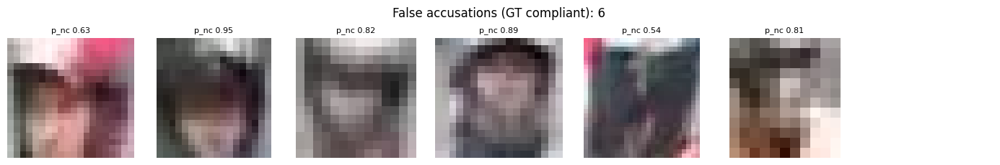

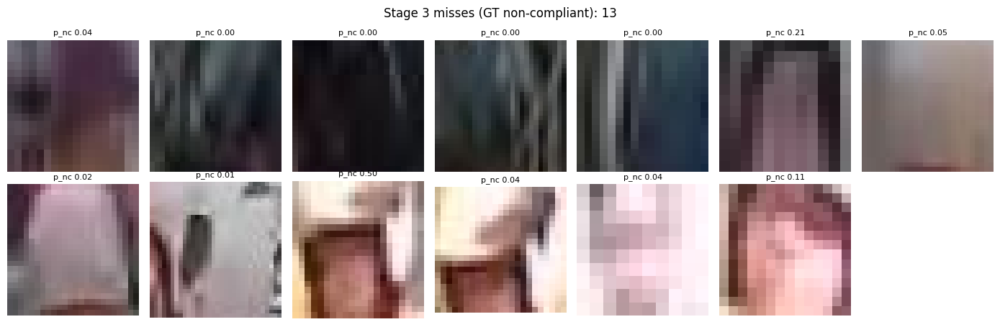

In [ ]:
# ARCHIVE: not needed for the final system
#final checks
fa, s3miss = [], []
for fp in TEST_FRAMES:
    frame = cv2.imread(fp); H, W = frame.shape[:2]
    out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
    for a, b in match_heads(pred, gt):
        x1, y1, x2, y2 = map(int, pred[a]['box']); crop = frame[max(0, y1):y2, max(0, x1):x2].copy()
        if gt[b][1] == 'compliant' and pred[a]['label'] == 'non-compliant': fa.append((crop, pred[a]['p_nc']))
        if gt[b][1] == 'non-compliant' and pred[a]['label'] == 'compliant': s3miss.append((crop, pred[a]['p_nc']))
for title, items in [('False accusations (GT compliant)', fa), ('Stage 3 misses (GT non-compliant)', s3miss)]:
    n = len(items); fig, ax = plt.subplots(max(1, math.ceil(n / 7)), 7, figsize=(14, 2.3 * max(1, math.ceil(n / 7))), squeeze=False)
    for a_ in ax.ravel(): a_.axis('off')
    for a_, (c, p) in zip(ax.ravel(), items):
        a_.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB)); a_.set_title(f'p_nc {p:.2f}', fontsize=8)
    fig.suptitle(f'{title}: {n}'); plt.tight_layout(); plt.show()

In [ ]:
# ARCHIVE: not needed for the final system
#checking if part 6 saved the results
for f in ['stage3_seeds_test.csv', 'e2e_valid_sweep.csv', 'relabel_transitions.csv', 'stage3_religious_headwear.csv',
          'stage3_seeds_test_v4.csv', f'stage3_seeds_test_v{S3_VERSION}.csv', f'e2e_valid_sweep_v{S3_VERSION}.csv',
          f'stage2_test_{RUN_TAG}.csv', f'stage2_gate_ablation_val_{RUN_TAG}.csv', f'e2e_valid_sweep_{RUN_TAG}.csv']:
    if os.path.exists(f'{RES}/{f}'): print(f'\n===== {f} ====='); print(pd.read_csv(f'{RES}/{f}').round(3).to_string(index=False))
for f in ['e2e_final_config.json', 'e2e_test_final.json', 'e2e_test_neck_keypoint.json', 'e2e_test_head_keypoint.json',
          'e2e_final_config_v4.json', 'e2e_test_final_v4.json', 'e2e_exempt_heads.json',
          f'e2e_final_config_v{S3_VERSION}.json', f'e2e_test_final_v{S3_VERSION}.json',
          f'stage2_selected_{RUN_TAG}.json', f'stage2_assoc_{RUN_TAG}.json', f'head_box_calib_{RUN_TAG}.json',
          f'e2e_final_config_{RUN_TAG}.json', f'e2e_test_final_{RUN_TAG}.json']:
    if os.path.exists(f'{RES}/{f}'): print(f'\n===== {f} ====='); print(json.dumps(load_json(f'{RES}/{f}'), indent=2, default=str))


===== stage3_seeds_test.csv =====
   arch seed  threshold  epoch     P     R    F1   acc
yolov8s   s0       0.05     20 0.756 0.756 0.756 0.842
yolo11s   s0       0.17     24 0.690 0.767 0.726 0.813
yolov8s   s1       0.16      8 0.636 0.778 0.700 0.784
yolo11s   s1       0.25     10 0.745 0.811 0.777 0.849
yolov8s   s2       0.06     19 0.683 0.789 0.732 0.813
yolo11s   s2       0.40      9 0.740 0.789 0.763 0.842

===== e2e_valid_sweep.csv =====
anchor   T  s3_thr    F1     P     R  P_labelled  TP  false_acc
  head 0.3    0.16 0.337 0.286 0.410       0.633  50         13
  head 0.3    0.30 0.363 0.343 0.385       0.671  47          9
  head 0.3    0.50 0.385 0.393 0.377       0.719  46          7
  head 0.5    0.16 0.337 0.286 0.410       0.633  50         13
  head 0.5    0.30 0.363 0.343 0.385       0.671  47          9
  head 0.5    0.50 0.385 0.393 0.377       0.719  46          7
  head 0.7    0.16 0.337 0.286 0.410       0.633  50         13
  head 0.7    0.30 0.363 0.343 0.38

In [ ]:
# ARCHIVE: not needed for the final system
#for RQ2 - VERSION 1.4 -
rows = []
for split, frames in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    for fp in frames:
        frame = cv2.imread(fp); H, W = frame.shape[:2]
        out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
        for a, b in match_heads(pred, gt):
            (x1, y1, x2, y2), lab = gt[b]
            if lab == 'exempt': continue                                   # v1.4
            rows.append(dict(split=split, gt=lab, correct=pred[a]['label'] == lab,
                             size_px=float(np.sqrt(max(x2 - x1, 0) * max(y2 - y1, 0)))))
SZ = pd.DataFrame(rows); SZ['small'] = SZ.size_px < 32          # COCO "small object": area < 32x32
print(SZ.groupby(['split', 'small']).apply(lambda d: pd.Series(dict(
    heads=len(d), errors=int((~d.correct).sum()), error_rate=round((~d.correct).mean(), 3)))).to_string())
for split in ['valid', 'test']:
    d = SZ[SZ.split == split]; e = d[~d.correct]
    print(f'{split}: {e.small.mean():.0%} of Stage 3 errors are on small heads '
          f'({d.small.mean():.0%} of all matched heads are small); median head size {d.size_px.median():.0f}px')
SZ.to_csv(f'{RES}/head_size_errors.csv', index=False)

             heads  errors  error_rate
split small                           
test  False   54.0     8.0       0.148
      True    40.0    11.0       0.275
valid False  104.0    20.0       0.192
      True    92.0    25.0       0.272
valid: 56% of Stage 3 errors are on small heads (47% of all matched heads are small); median head size 33px
test: 58% of Stage 3 errors are on small heads (43% of all matched heads are small); median head size 37px


DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


In [ ]:
# ARCHIVE: not needed for the final system
#for RQ2 VERSION 1.4
rows = []
for split, frames in [('valid', VAL_FRAMES), ('test', TEST_FRAMES)]:
    for fp in frames:
        frame = cv2.imread(fp); H, W = frame.shape[:2]
        out = run_pipeline(frame); gt = gt_heads(fp, W, H); pred = out['heads']
        for a, b in match_heads(pred, gt):
            (x1, y1, x2, y2), lab = gt[b]
            if lab == 'exempt': continue                                   # v1.4
            rows.append(dict(split=split, gt=lab, correct=pred[a]['label'] == lab,
                             size_px=float(np.sqrt(max(x2 - x1, 0) * max(y2 - y1, 0)))))
SZ = pd.DataFrame(rows); SZ['small'] = SZ.size_px < 32          # COCO "small object": area < 32x32
print(SZ.groupby(['split', 'small']).apply(lambda d: pd.Series(dict(
    heads=len(d), errors=int((~d.correct).sum()), error_rate=round((~d.correct).mean(), 3)))).to_string())
for split in ['valid', 'test']:
    d = SZ[SZ.split == split]; e = d[~d.correct]
    print(f'{split}: {e.small.mean():.0%} of Stage 3 errors are on small heads '
          f'({d.small.mean():.0%} of all matched heads are small); median head size {d.size_px.median():.0f}px')
SZ.to_csv(f'{RES}/head_size_errors_run4.csv', index=False)

             heads  errors  error_rate
split small                           
test  False   56.0    10.0       0.179
      True    41.0    11.0       0.268
valid False  104.0    21.0       0.202
      True    92.0    25.0       0.272
valid: 54% of Stage 3 errors are on small heads (47% of all matched heads are small); median head size 33px
test: 52% of Stage 3 errors are on small heads (42% of all matched heads are small); median head size 36px


DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


In [ ]:
# ARCHIVE: not needed for the final system
# FIX-4: look for older copies of the overwritten files in every backup
for f in ['e2e_valid_sweep.csv', 'stage3_test.csv', 'e2e_test_final_v5.json', 'stage2_test.csv']:
    for p in sorted(glob.glob(f'{ROOT}/**/{f}', recursive=True)):
        print('\n=====', p)
        print(pd.read_csv(p).round(3).to_string(index=False) if p.endswith('.csv')
              else json.dumps(load_json(p), indent=1)[:1500])


===== /content/drive/MyDrive/helmet_thesis_v2/backup_before_fix_20260927_0954/results/e2e_valid_sweep.csv
anchor   T  s3_thr    F1     P     R  P_labelled  TP  false_acc
  head 0.3    0.16 0.337 0.286 0.410       0.633  50         13
  head 0.3    0.30 0.363 0.343 0.385       0.671  47          9
  head 0.3    0.50 0.385 0.393 0.377       0.719  46          7
  head 0.5    0.16 0.337 0.286 0.410       0.633  50         13
  head 0.5    0.30 0.363 0.343 0.385       0.671  47          9
  head 0.5    0.50 0.385 0.393 0.377       0.719  46          7
  head 0.7    0.16 0.337 0.286 0.410       0.633  50         13
  head 0.7    0.30 0.363 0.343 0.385       0.671  47          9
  head 0.7    0.50 0.385 0.393 0.377       0.719  46          7
  neck 0.3    0.16 0.384 0.322 0.475       0.674  58         21
  neck 0.3    0.30 0.399 0.357 0.451       0.705  55         17
  neck 0.3    0.50 0.403 0.405 0.402       0.742  49         12
  neck 0.5    0.16 0.384 0.322 0.475       0.674  58         

In [ ]:
# ARCHIVE. WARNING: overwrites stage2_selected.json and FINAL_SYSTEM_run4.json. Do not run for the final system.
# FIX-5: name files by version, and point the "selected" files back to the final system
for f, new in [('e2e_valid_sweep.csv', 'e2e_valid_sweep_v5.csv'),
               ('stage3_test.csv', 'stage3_test_v5.csv'),
               ('stage3_seeds_test.csv', 'stage3_seeds_test_v5.csv'),
               ('stage3_religious_headwear.csv', 'stage3_religious_headwear_OLD.csv'),
               ('head_size_errors.csv', 'head_size_errors_run6.csv'),
               ('e2e_test.json', 'e2e_test_run2.json')]:
    if os.path.exists(f'{RES}/{f}'): shutil.copy(f'{RES}/{f}', f'{RES}/{new}')
save_json(OLD_S2, f'{RES}/stage2_selected.json')          # final system = old Stage 2
save_json({**FINAL, 'stage2': OLD_S2['run'], 'stage3': S3_NAME, 'run': 4},
          f'{RES}/FINAL_SYSTEM_run4.json')
print('Done. FINAL_SYSTEM_run4.json describes the system reported in the thesis.')

Done. FINAL_SYSTEM_run4.json describes the system reported in the thesis.


In [ ]:
# ARCHIVE: not needed for the final system
from google.colab import drive
import os, json, pandas as pd
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/helmet_thesis_v2'
RES  = f'{ROOT}/results'
load_json = lambda p: json.load(open(p)) if os.path.exists(p) else None

B0 = f'{ROOT}/backup_before_relabel_20260923_1921/results'
for f in ['e2e_test.json', 'e2e_test_rescored.json', 'centre_constraint_val_sweep.json']:
    print(f'\n===== {f}'); print(json.dumps(load_json(f'{B0}/{f}'), indent=1, default=str)[:3000])

for f in ['latency_pytorch.csv', 'latency_tensorrt.csv']:
    L = pd.read_csv(f'{RES}/{f}')
    print(f'\n===== {f}: mean {L.total.mean():.1f} | median {L.total.median():.1f} | p95 {L.total.quantile(.95):.1f}')
    print(L.groupby('n_moto').total.agg(['count', 'mean', lambda s: s.quantile(0.95)])
           .rename(columns={'<lambda_0>': 'p95'}).round(1).to_string())

Mounted at /content/drive

===== e2e_test.json
{
 "precision": 0.10126582278481013,
 "recall": 0.21621621621621623,
 "F1": 0.13793103448275862,
 "ci_low": [
  0.04225352112676056,
  0.09090909090909091,
  0.05995631067961165
 ],
 "ci_high": [
  0.17392568250758333,
  0.36369179600886886,
  0.22413793103448276
 ],
 "false_accusations": 6,
 "miss_causes": {
  "Stage 3: classified as compliant": 16,
  "Stage 2: rider/head not found in crop": 12,
  "Stage 1: motorcycle not detected": 1
 }
}

===== e2e_test_rescored.json
{
 "strict": {
  "precision": 0.10126582278481013,
  "recall": 0.21621621621621623,
  "F1": 0.13793103448275862
 },
 "strict_ci": [
  [
   0.04108890131395024,
   0.09297040169133193,
   0.06120902906617192
  ],
  [
   0.18311296349525719,
   0.35714285714285715,
   0.22
  ]
 ],
 "labeled_only": {
  "precision": 0.42105263157894735,
  "recall": 0.21621621621621623,
  "F1": 0.28571428571428575
 },
 "labeled_only_ci": [
  [
   0.25,
   0.09297040169133193,
   0.14279448621553

28 candidate frames; drawing the top 6


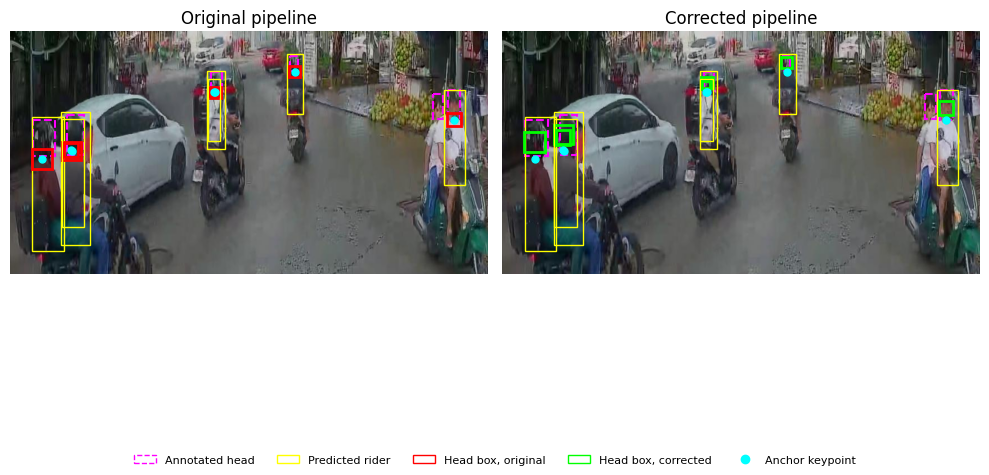

1 HCVR-B36A_ch1_main_20260812070000_20260812080000_mp4-2998_jpg.rf.4ae7472b91f5aae179b1bcda8b485839.jpg -> /content/drive/MyDrive/helmet_thesis_v2/results/fig_headbox_1.png


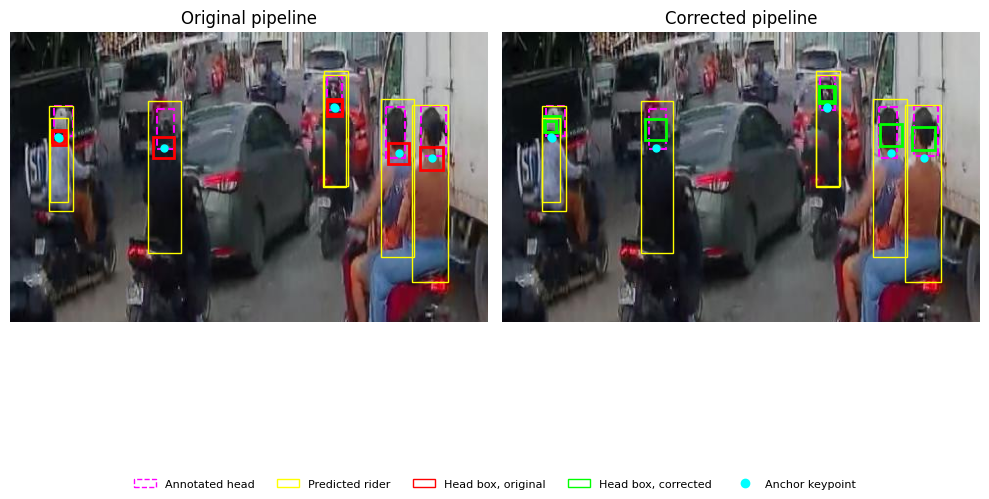

2 HCVR-B36A_ch1_main_20260812070000_20260812080000_mp4-3594_jpg.rf.e6e6152f4ccae742cf15d37ee9597017.jpg -> /content/drive/MyDrive/helmet_thesis_v2/results/fig_headbox_2.png


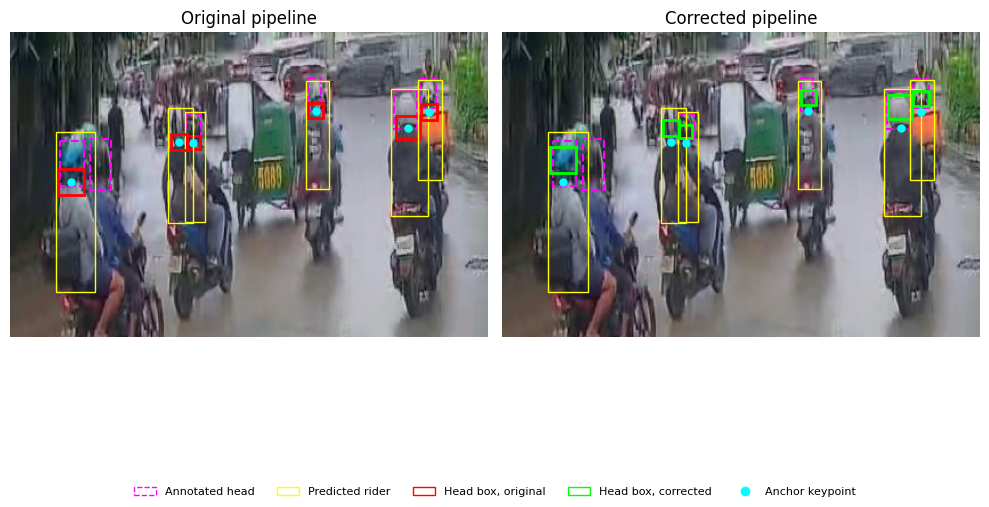

3 HCVR-B36A_ch1_main_20260812070000_20260812080000_mp4-0723_jpg.rf.d87d4a77eaa62e37d3c35d7e9fd55f49.jpg -> /content/drive/MyDrive/helmet_thesis_v2/results/fig_headbox_3.png


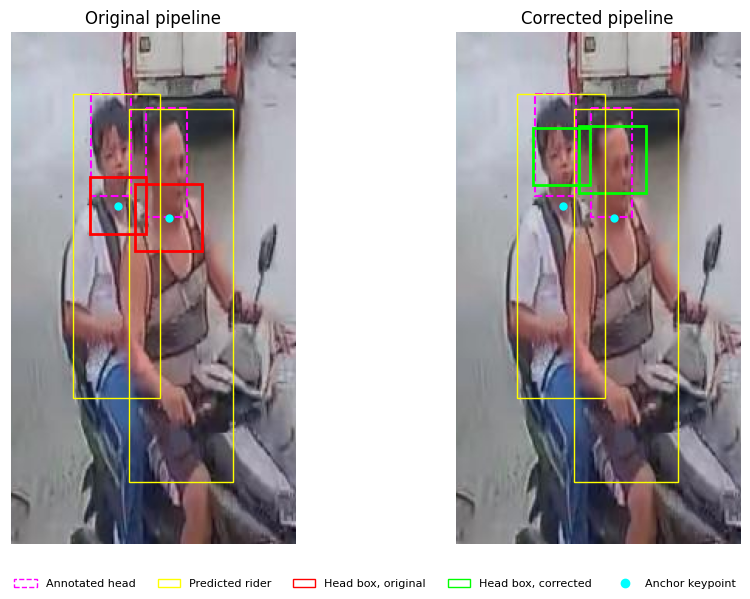

4 HCVR-B36A_ch1_main_20260812070000_20260812080000_mp4-0738_jpg.rf.a4d28cb4549142a605626ddc260ddb8e.jpg -> /content/drive/MyDrive/helmet_thesis_v2/results/fig_headbox_4.png


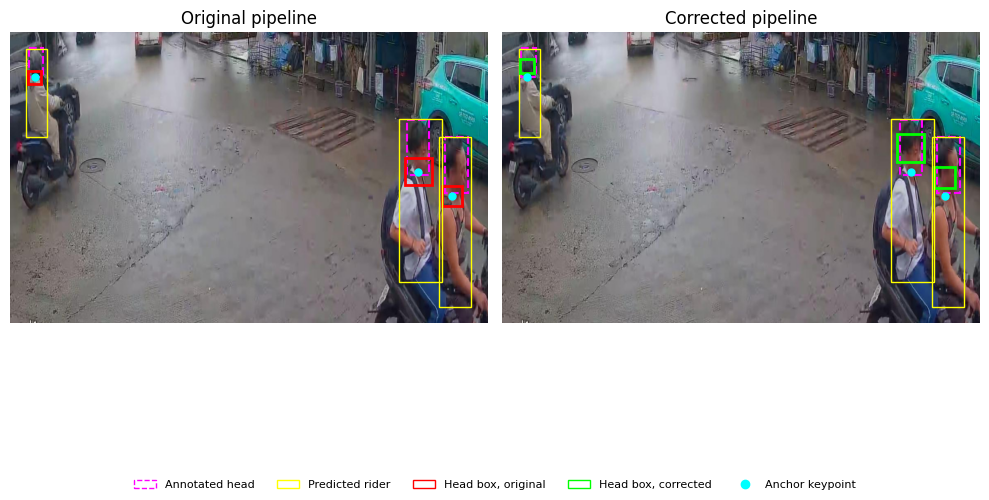

5 HCVR-B36A_ch1_main_20260812070000_20260812080000_mp4-0739_jpg.rf.f6bb9b470bbad39bab03884a4a350eec.jpg -> /content/drive/MyDrive/helmet_thesis_v2/results/fig_headbox_5.png


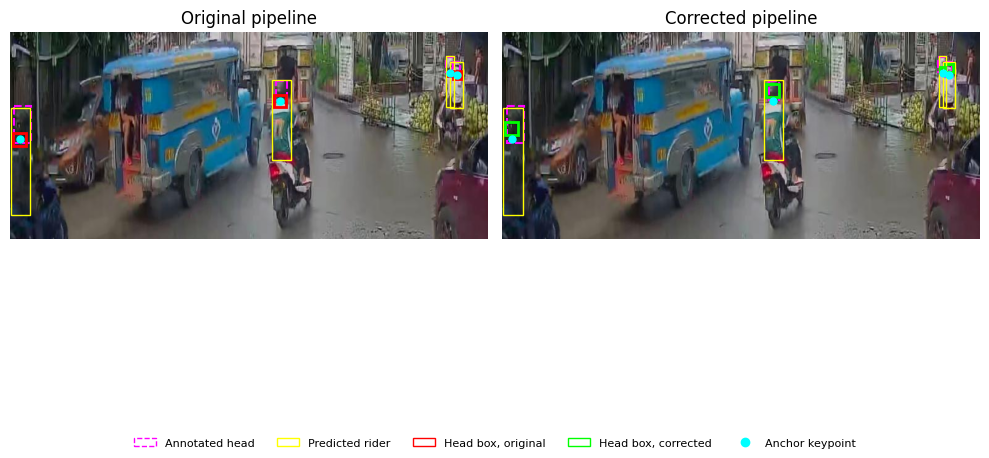

6 HCVR-B36A_ch1_main_20260812070000_20260812080000_mp4-1479_jpg.rf.a877aae268f24b32fe85a14535eff931.jpg -> /content/drive/MyDrive/helmet_thesis_v2/results/fig_headbox_6.png


In [ ]:
# ARCHIVE: not needed for the final system
# for Figure: head-box placement, original pipeline vs corrected pipeline (validation frames only)
import matplotlib.patches as mpatches
FINAL = load_json(f'{RES}/e2e_final_config.json')
ANCHOR = [KEYPOINT_NAMES.index(FINAL['anchor'])]
old_file = sorted(glob.glob(f'{ROOT}/backup_before_relabel_*/results/head_box_scale.json'))
OLD_SCALE = load_json(old_file[0], {'scale': 0.7})['scale'] if old_file else 0.7
NECK = [KEYPOINT_NAMES.index('neck')]
SETTINGS = {'Original pipeline': (NECK, (0.0, 0.0), OLD_SCALE),                       # neck read as head, no offset
            'Corrected pipeline': (ANCHOR, tuple(FINAL['head_off']), FINAL['head_scale'])}

def heads_with(frame, kpts, off, scale):
    global HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE
    saved = (HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE)
    HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE = kpts, off, scale
    try:
        return run_pipeline(frame)['heads']
    finally:
        HEAD_KPTS, HEAD_OFF, HEAD_BOX_SCALE = saved

def n_on_heads(heads, gt):
    return sum(any(g[0][0] <= h['center'][0] <= g[0][2] and g[0][1] <= h['center'][1] <= g[0][3] for g in gt) for h in heads)

# 1) find validation frames with 2+ annotated heads where the correction moves boxes onto heads
cands = []
for fp in VAL_FRAMES:
    frame = cv2.imread(fp); H, W = frame.shape[:2]; gt = gt_heads(fp, W, H)
    if len(gt) < 2: continue
    res = {k: heads_with(frame, *v) for k, v in SETTINGS.items()}
    gain = n_on_heads(res['Corrected pipeline'], gt) - n_on_heads(res['Original pipeline'], gt)
    if gain > 0: cands.append((gain, fp, res, gt))
cands.sort(key=lambda c: -c[0]); print(len(cands), 'candidate frames; drawing the top 6')

# 2) draw each candidate, zoomed on its riders: left = original, right = corrected
for n, (gain, fp, res, gt) in enumerate(cands[:6]):
    img = cv2.cvtColor(cv2.imread(fp), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    boxes = [h['rider_box'] for hs in res.values() for h in hs] + [g[0] for g in gt]
    x1, y1 = max(0, min(b[0] for b in boxes) - 40), max(0, min(b[1] for b in boxes) - 40)
    x2, y2 = min(W, max(b[2] for b in boxes) + 40), min(H, max(b[3] for b in boxes) + 40)
    fig, ax = plt.subplots(1, 2, figsize=(10, 6))
    for a, (title, hs) in zip(ax, res.items()):
        a.imshow(img); a.set_xlim(x1, x2); a.set_ylim(y2, y1); a.axis('off'); a.set_title(title)
        for (g, _) in gt:
            a.add_patch(mpatches.Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1], fill=False, ec='magenta', ls='--', lw=1.5))
        for h in hs:
            r, b = h['rider_box'], h['box']
            a.add_patch(mpatches.Rectangle((r[0], r[1]), r[2] - r[0], r[3] - r[1], fill=False, ec='yellow', lw=1))
            a.add_patch(mpatches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False,
                                           ec='red' if title.startswith('Original') else 'lime', lw=2))
            a.plot(*h['kpt'], 'o', c='cyan', ms=5)
    fig.legend(handles=[mpatches.Patch(ec='magenta', fc='none', ls='--', label='Annotated head'),
                        mpatches.Patch(ec='yellow', fc='none', label='Predicted rider'),
                        mpatches.Patch(ec='red', fc='none', label='Head box, original'),
                        mpatches.Patch(ec='lime', fc='none', label='Head box, corrected'),
                        plt.Line2D([], [], marker='o', c='cyan', ls='', label='Anchor keypoint')],
               loc='lower center', ncol=5, fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0.06, 1, 1)); out = f'{RES}/fig_headbox_{n + 1}.png'
    fig.savefig(out, dpi=200, bbox_inches='tight'); plt.show(); print(n + 1, os.path.basename(fp), '->', out)

In [ ]:
# ARCHIVE: not needed for the final system
for f in ['latency_pytorch.csv', 'latency_tensorrt.csv']:
    L = pd.read_csv(f'{RES}/{f}')
    print(f, '\n', L.groupby('n_moto').total.agg(['count', 'mean', lambda s: s.quantile(0.95)]).round(1)
          .rename(columns={'<lambda_0>': 'p95'}).to_string(), '\n')

In [ ]:
# ARCHIVE: not needed for the final system
# Relabel tally: compare each crop's class before (v1) and after (v3) the relabel
OLD_V, NEW_V = 1, 3          # v1 = original labels, v3 = relabelled version

def s3_labels(version):
    raw = rf.workspace(WORKSPACE_ID).project(S3_PROJECT).version(version).download(
        'folder', location=f'{LOCAL}/s3_raw_v{version}', overwrite=False).location
    rows = []
    for sp in ['train', 'valid', 'val', 'test']:
        for cls_dir in glob.glob(f'{raw}/{sp}/*/'):
            for img in list_images(cls_dir):
                rows.append(dict(key=frame_base(img), cls=os.path.basename(cls_dir.rstrip('/'))))
    return pd.DataFrame(rows).drop_duplicates('key').set_index('key').cls   # one label per original crop

old, new = s3_labels(OLD_V), s3_labels(NEW_V)
both = pd.DataFrame({'before': old, 'after': new}).dropna()
print(f'{len(both)} crops appear in both versions ({len(old)} in v{OLD_V}, {len(new)} in v{NEW_V})\n')
TAB = pd.crosstab(both.before, both.after, margins=True, margins_name='total')
print(TAB.to_string())
TAB.to_csv(f'{RES}/relabel_transitions.csv')
print('\nChanged class:', int((both.before != both.after).sum()))

In [ ]:
# ARCHIVE: not needed for the final system
T = pd.read_csv(f'{RES}/relabel_transitions.csv'); print(T.to_string(index=False))